<div align="center">

**REACH FOR CHANGE GROUP PROJECT**
<br>
<br>
DATA SCIENCE AND MACHINE LEARNING
<br>
<br>
**NOVA IMS – INFORMATION MANAGEMENT SCHOOL**
<br>
<br>
POST-GRADUATE PROGRAM IN ENTERPRISE DATA SCIENCE AND ANALYTICS
<br>
<br>
GROUP ELEMENTS<br>
Beatriz Farreca      20250984 <br>
João Carvalho         20250977 <br>
Ricardo Barracho     20250986 <br>
Tomás Valverde        20250983 <br>

DSML_GROUP_03


</div>

<br>

----

<div align="center">

  ## TABLE OF CONTENTS

</div>

[Abstract](#Abstract)
1. [Introduction](#introduction)
2. [Data Exploration and Pre-Processing](#data-exploration-and-pre-processing)
* 2.1. [Initial Setup and imports](#initial-setup-and-imports)
* 2.2. [Exploratory Data Analysis (EDA)](#exploratory-data-analysis-(EDA))
* 2.3. [Data Preparation](#data-preparation)
  * 2.3.1. [Pre-Processing](#pre-processing)
  * 2.3.2. [Data Cleaning](#data-cleaning)
3. [Binary Classification and Optimization](#binary-classification-and-optimization)
* 3.1. [Feature Engineering](#feature-engineering)
  * 3.1.1. [Donation_Behaviour](#donation-behaviour)
  * 3.1.2. [Donation_Engagement](#donation-engagement)
* 3.2. [Feature Selection](#feature-selection)
  * 3.2.1. [Categorical features: Chi-square method](#categorical-features:-chi-square-method)
  * 3.2.2. [Numerical features](#numerical-features)
  * 3.2.3. [Feature Selection - Final Conclusion](#feature-selection-final-conclusion)
* 3.3. [Modelling](#modelling)
  * 3.3.1. [Model Selection](#model-selection)
  * 3.3.2. [Models Optimization](#models-optimization)
4. [Deployment](#deployment)
* 4.1. [Import and transform test data](#import-and-transform-test)
* 4.2. [Pre Processing test data](#pre-processing-test-data)
5. [Open-Ended Section](#open-ended-section)

<br>

----


# Abstract

This project was developed in the context of the Civic Support Alliance (CSA), a federation of humanitarian and social aid programs seeking to modernize its outreach strategy. Rather than contacting all individuals in their database, the CSA aims to identify those most likely to donate, reducing donor fatigue while improving campaign efficiency. Consequently, the core predictive challenge driving this workflow is a binary classification problem: **Will a person donate if contacted?**

The original dataset comprises 13,560 potential donors described by 40 features across demographic, geographic, donation behavior and engagement dimensions. To extract maximum information from the available data, feature engineering was conducted, resulting in the creation of 8 additional variables. The entire dataset was then funneled into a dedicated *Supervised Learning* pipeline to isolate features with predictive power and optimize downstream classification performance. To mitigate the curse of dimensionality and eliminate redundant predictors, a hybrid feature selection strategy was implemented, combining Filter Methods (Variance Thresholding, Chi-Square tests, and Spearman correlation analysis) with Embedded and Wrapper techniques (LassoCV, Recursive Feature Elimination (RFE), and Decision Tree feature importances).

Four classification algorithms were trained and evaluated: Logistic Regression, Neural Networks (MLP Classifier), Random Forest Classifier, and Decision Trees. To ensure robust validation across unbalanced class distributions, a 5-fold Stratified K-Fold Cross-Validation framework was used, with the F1-score as the primary optimization metric. Hyperparameter tunning was also explored using RandomizedSearchCV. Among the tuned estimators, *Logistic Regression* emerged as the *best-performing model*, achieving a top validation F1-score of 0.406 and dominating the Area Under the ROC Curve (AUC-ROC) comparison matrix. To further align the model with the operational constraints of the CSA, threshold tuning was applied via Precision-Recall curves to maximize the balance between precision and recall. The final optimized model was successfully deployed on the unseen test dataset and submitted to the Kaggle competition.

# 1. Introduction

## 1.1. Context and Goals

Non-profit organisations increasingly face the challenge of donor fatigue, driven by a growing reluctance among potential supporters to engage with generic, high-frequency fundraising campaigns. The Civic Support Alliance (CSA) has responded by commissioning a data-driven predictive system to replace mass outreach with targeted, personalised contact.

This project addresses that challenge by developing a *Supervised Learning Binary Classification* pipeline engineered to answer our core predictive question: Will this person donate if contacted? By evaluating individual donation likelihoods across the entire CSA database, this system provides actionable intelligence designed to minimize donor fatigue while maximizing campaign resource efficiency.

## 1.2. Overall Process and Methodology

The project follows a structured pipeline:

Data Exploration and Preprocessing - The dataset was thoroughly explored and cleaned, addressing missing values, invalid entries, and distributional anomalies across all 40 baseline features. This phase ensured data integrity and established a clean foundation for downstream modeling.

Feature Engineering - To extract deeper insights and uncover hidden patterns within the data, a feature engineering process was executed. A total of 8 custom variables were created to capture nuanced behavioral and promotional engagement insights. These include features such as recency_value, gift_variability, and engagement_recency_score. This phase expanded the feature space with predictive indicators tailored to the task.

Feature Selection - To reduce the dimensionality and remove redundant features, an hybrid strategy was implemented within the training process. This workflow combined *Filter Methods* (Chi-square tests, variance thresholding, and Spearman correlation) with *Embedded Techniques* (LassoCV and Decision Tree importances) and a *Wrapper Method* (Recursive Feature Elimination - RFE) across cross-validation folds to guarantee a stable and robust feature subset.

Binary Classification and Optimisation - four algorithms were evaluated: *Logistic Regression, **Neural Network (MLP), **Random Forest Classifier, and **Decision Tree. All models were assessed using Stratified 5-Fold Cross-Validation as the primary model assessment strategy, with binary F1-score as the evaluation metric. This choice reflects the moderate class imbalance in the dataset (75% non-donors, 25% donors) and the equal operational importance of precision and recall in a targeted outreach context. Hyperparameter optimisation was performed via **RandomizedSearchCV*, followed by threshold tuning using the precision-recall curve.

Deployment - the selected model (Logistic Regression with optimised threshold) was applied to the unseen test set to generate the final Kaggle submission.

# 2. Data Exploration and Pre-Processing

## 2.1. Initial Setup and Imports


Here we import the necessary libraries

In [2]:
## Data analysis and manipulation
import numpy as np
import pandas as pd
## Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
## Statistics and advanced analysis
#!pip install scipy
from scipy.cluster import hierarchy
import scipy.stats as stats
from scipy.stats import chi2_contingency, randint
## Pre-processing and data preparation
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler
## Feature Selection
from sklearn.feature_selection import RFE
from sklearn.linear_model import LassoCV
## Unsupervised Learning
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances
## Supervised Learning
from sklearn import tree
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
## Hyperparameter tuning and validation
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, PredefinedSplit
## Metrics for model evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, davies_bouldin_score, f1_score, precision_score, recall_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, silhouette_score, ConfusionMatrixDisplay

Throughout subsection 2.3 (Data Preparation), certain charts and plots were generated repeatedly. To automate this process and ensure efficiency, dedicated functions were developed for each visualization type:

Plotting Correlations

In [4]:
def plot_corr_num(subset, title):
  """ This function receives a df subset and creates a heatmap of the correlation matrix """
  df_num = subset.select_dtypes(include=["number"])
  corr = df_num.corr(method='spearman')
  plt.figure(figsize=(15, 10))
  sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, linewidths=.5)
  plt.title(title)
  plt.tight_layout()
  plt.show()

Plotting Boxplot and Histogram side by side

In [5]:
def boxplot_hist(data_frame, name_col, color_name = 'green'):
  fig, (ax1,ax2) = plt.subplots(1,2 , figsize = (16,4))
  sns.histplot(ax = ax1, data = data_frame[name_col], color = 'royalblue')
  sns.boxplot(ax=ax2, data = data_frame, x = name_col, color = color_name)
  plt.show()

Plotting Boxplot before and after processing

In [6]:
def box_plot(col_name):
  fig, axes = plt.subplots(1, 2, figsize=(14,5))
  sns.boxplot(x=df[col_name.upper()], ax=axes[0], color='green')
  axes[0].set_title("Pre-Processing")
  axes[0].set_xlabel(f"{col_name}")
  sns.boxplot(x=df_copy[col_name], ax=axes[1], color='royalblue')
  axes[1].set_title("Post-Processing")
  axes[1].set_xlabel(f"{col_name}")
  plt.suptitle(f"Visual Validation: {col_name} Processing")
  plt.tight_layout()
  plt.show()

Plotting Histogram before and after processing

In [7]:
def hist_plot(col_name):
  fig, axes = plt.subplots(1, 2, figsize=(14,5))
  sns.histplot(x=df[col_name.upper()], ax=axes[0], color='green')
  axes[0].set_title("Pre-Processing")
  axes[0].set_xlabel(f"{col_name}")
  sns.histplot(x=df_copy[col_name], ax=axes[1], color='royalblue')
  axes[1].set_title("Post-Processing")
  axes[1].set_xlabel(f"{col_name}")
  plt.suptitle(f"Visual Validation: {col_name} Processing")
  plt.tight_layout()
  plt.show()

Plotting Countplot before and after processing

In [8]:
def count_plot(col_name, order_name=None):
  fig, axes = plt.subplots(1, 2, figsize=(14,5))
  sns.countplot(x=df[col_name.upper()], order=order_name,ax=axes[0], color='green')
  axes[0].set_title("Pre-Processing")
  axes[0].set_xlabel(f"{col_name}")
  sns.countplot(x=df_copy[col_name], order=order_name, ax=axes[1], color='royalblue')
  axes[1].set_title("Post-Processing")
  axes[1].set_xlabel(f"{col_name}")
  plt.suptitle(f"Visual Validation: {col_name} Processing")
  plt.tight_layout()
  plt.show()

---
## 2.2. Exploratory Data Analysis (EDA) <a name="exploratory-data-analysis-eda"></a>

Import the donors decriptive dataset as `df`. Initial data exploration was then conducted by analyzing its structure, identifying categorical variables, and evaluating the correlation between numerical variables.

In [3]:
df = pd.read_csv("data/donors_descriptive.csv")
df.head()

,CONTROL_NUMBER,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,...,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING
0,61745,4.0,2.000000,33.0,M,0.0,1.0,H,5.0,20.0,...,0.00,17.50,0.0,0.000,2.0,0.154,0.0,2,T,NaN
1,112703,3.0,-2.341107,NaN,F,1.0,1.0,U,NaN,15.0,...,15.00,15.00,1.0,0.250,1.0,0.100,0.0,3,R,NaN
2,166437,4.0,0.000000,74.0,F,7.0,3.0,H,4.0,10.0,...,0.00,10.67,0.0,0.000,3.0,0.231,1.0,1,U,NaN
3,170621,4.0,4.000000,61.0,M,13.0,1.0,H,6.0,11.0,...,10.00,10.00,2.0,0.286,2.0,0.111,0.0,1,U,NaN
4,44428,6.0,3.000000,75.0,M,3.0,4.0,H,3.0,7.0,...,5.67,5.40,3.0,0.600,5.0,0.500,0.0,2,C,NaN


In [10]:
df.columns

Index(['CONTROL_NUMBER', 'CARD_PROM_12', 'CHILDREN', 'DONOR_AGE',
       'DONOR_GENDER', 'FILE_CARD_GIFT', 'FREQUENCY_STATUS_97NK', 'HOME_OWNER',
       'INCOME_GROUP', 'LAST_GIFT_AMT', 'LIFETIME_CARD_PROM',
       'LIFETIME_GIFT_AMOUNT', 'LIFETIME_GIFT_COUNT', 'LIFETIME_MAX_GIFT_AMT',
       'LIFETIME_MIN_GIFT_AMT', 'LIFETIME_PROM', 'MEDIAN_HOME_VALUE',
       'MEDIAN_HOUSEHOLD_INCOME', 'MONTHS_SINCE_FIRST_GIFT',
       'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_LAST_PROM_RESP',
       'NUMBER_PROM_12', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3',
       'PCT_ATTRIBUTE4', 'PCT_OWNER_OCCUPIED', 'PEP_STAR', 'PER_CAPITA_INCOME',
       'RECENCY_STATUS_96NK', 'RECENT_AVG_CARD_GIFT_AMT',
       'RECENT_AVG_GIFT_AMT', 'RECENT_CARD_RESPONSE_COUNT',
       'RECENT_CARD_RESPONSE_PROP', 'RECENT_RESPONSE_COUNT',
       'RECENT_RESPONSE_PROP', 'RECENT_STAR_STATUS', 'SES', 'URBANICITY',
       'WEALTH_RATING'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13560 entries, 0 to 13559
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CONTROL_NUMBER               13560 non-null  int64  
 1   CARD_PROM_12                 13297 non-null  float64
 2   CHILDREN                     13289 non-null  float64
 3   DONOR_AGE                    9970 non-null   float64
 4   DONOR_GENDER                 13303 non-null  object 
 5   FILE_CARD_GIFT               13292 non-null  float64
 6   FREQUENCY_STATUS_97NK        13296 non-null  float64
 7   HOME_OWNER                   13292 non-null  object 
 8   INCOME_GROUP                 10273 non-null  float64
 9   LAST_GIFT_AMT                13296 non-null  float64
 10  LIFETIME_CARD_PROM           13289 non-null  float64
 11  LIFETIME_GIFT_AMOUNT         13288 non-null  float64
 12  LIFETIME_GIFT_COUNT          13304 non-null  float64
 13  LIFETIME_MAX_GIF

In [12]:
df.shape

(13560, 40)

In [13]:
df[df.duplicated()]

,CONTROL_NUMBER,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,...,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CONTROL_NUMBER,13560.0,96433.007743,55926.026991,5.000000,47975.250,97023.000,145252.750,191775.000000
CARD_PROM_12,13297.0,5.381058,1.313753,1.000000,5.000,6.000,6.000,17.000000
CHILDREN,13289.0,2.004998,1.473369,-2.341107,1.000,2.000,3.000,6.264709
DONOR_AGE,9970.0,58.870864,17.572796,0.000000,46.000,60.000,73.000,108.934261
FILE_CARD_GIFT,13292.0,5.253405,4.812068,-10.100341,2.000,4.000,8.000,32.000000
FREQUENCY_STATUS_97NK,13296.0,1.990869,1.145976,-1.365242,1.000,2.000,3.000,5.283869
INCOME_GROUP,10273.0,3.922943,1.950277,-1.728999,2.000,4.000,5.000,9.490799
LAST_GIFT_AMT,13296.0,16.622972,12.930434,-21.718664,10.000,15.000,20.000,450.000000
LIFETIME_CARD_PROM,13289.0,18.641620,8.895656,-7.188999,11.000,18.000,26.000,55.000000
LIFETIME_GIFT_AMOUNT,13288.0,105.010105,112.318930,-245.473199,41.000,80.000,133.000,3775.000000


In [15]:
df.isnull().sum()

,0
CONTROL_NUMBER,0
CARD_PROM_12,263
CHILDREN,271
DONOR_AGE,3590
DONOR_GENDER,257
FILE_CARD_GIFT,268
FREQUENCY_STATUS_97NK,264
HOME_OWNER,268
INCOME_GROUP,3287
LAST_GIFT_AMT,264


In [16]:
df.describe(include=['O']).T

,count,unique,top,freq
DONOR_GENDER,13303,3,F,7222
HOME_OWNER,13292,2,H,7251
RECENCY_STATUS_96NK,13294,6,A,8202
SES,13274,5,2,6365
URBANICITY,13282,6,S,3103


Our initial exploration shows a dataset of **13,560 entries**. Among the **40 available features**, we identified a set of 35 numerical and 5 categorical features. Although the data is **free of duplicates**, there are null values that require attention during our data cleaning strategy.

Checking the values of each Categorical feature

In [17]:
df['HOME_OWNER'].value_counts(dropna=False)

,count
HOME_OWNER,
H,7251
U,6041
NaN,268


`home_owner`: we identified 2 categories as expected. Since 'U' represents the category 'Unknown', the null values make sense to go into this category.

In [18]:
df['DONOR_GENDER'].value_counts(dropna = False)

,count
DONOR_GENDER,
F,7222
M,5376
U,705
NaN,257


`donor_gender`: we can identify 3 categories and since we have 'U' that we assume represents 'Unknown', the null values make sense to go into this category.

In [19]:
df['SES'].value_counts(dropna = False)

,count
SES,
2,6365
1,4091
3,2277
?,292
NaN,286
4,249


`ses`: this feature should contain 5 categories and we identified 4 and '?'. Does this mean that '?' = 5? Not necessarly. Since we can't know for sure the null values will be input with mode based on a groupby of urbanicity.


In [20]:
df['URBANICITY'].value_counts(dropna = False)

,count
URBANICITY,
S,3103
C,2741
T,2734
R,2732
U,1677
?,295
NaN,278


`urbanicity`: this feature should contain 5 categories and we identified 5 and '?'.

In [21]:
df['RECENCY_STATUS_96NK'].value_counts(dropna = False)

,count
RECENCY_STATUS_96NK,
A,8202
S,2877
F,1048
N,825
E,283
NaN,266
L,59


`recency_status_96nk`: we identified 6 categories with 'A' being the most prominent category. This means that null values will most likely inputed with 'A'.

For the numerical values we check for correlations based on diferent families:
- Demographic - the demographic profile of each individual
- Geographic - the geographic profile of each individual
- Donation_behaviour - the way each individual behaves in terms of donating
- Dontaion_engagment - the way each individual reacts to promotions

In [22]:
# The features were divided into four groups accordingly to their meaning in order to check for correlations
DEMOGRAPHIC = ["DONOR_AGE","DONOR_GENDER","CHILDREN","SES","INCOME_GROUP","WEALTH_RATING","HOME_OWNER"]
GEOGRAPHIC = ["URBANICITY","MEDIAN_HOME_VALUE","MEDIAN_HOUSEHOLD_INCOME","PER_CAPITA_INCOME","PCT_OWNER_OCCUPIED","PCT_ATTRIBUTE1",
              "PCT_ATTRIBUTE2","PCT_ATTRIBUTE3","PCT_ATTRIBUTE4"]
DONATION_BEHAVIOUR = ["RECENT_AVG_GIFT_AMT","FILE_CARD_GIFT","LIFETIME_GIFT_AMOUNT","LIFETIME_GIFT_COUNT","LIFETIME_MAX_GIFT_AMT",
                      "LIFETIME_MIN_GIFT_AMT","LAST_GIFT_AMT","RECENT_AVG_CARD_GIFT_AMT"]
DONATION_ENGAGEMENT = ["PEP_STAR","RECENT_STAR_STATUS","RECENCY_STATUS_96NK","FREQUENCY_STATUS_97NK","RECENT_RESPONSE_PROP","RECENT_CARD_RESPONSE_PROP",
                       "RECENT_RESPONSE_COUNT","RECENT_CARD_RESPONSE_COUNT","MONTHS_SINCE_LAST_PROM_RESP","LIFETIME_CARD_PROM","LIFETIME_PROM",
                       "CARD_PROM_12","NUMBER_PROM_12","MONTHS_SINCE_LAST_GIFT","MONTHS_SINCE_FIRST_GIFT"]

Plotting a heatmap of the correlation of each family

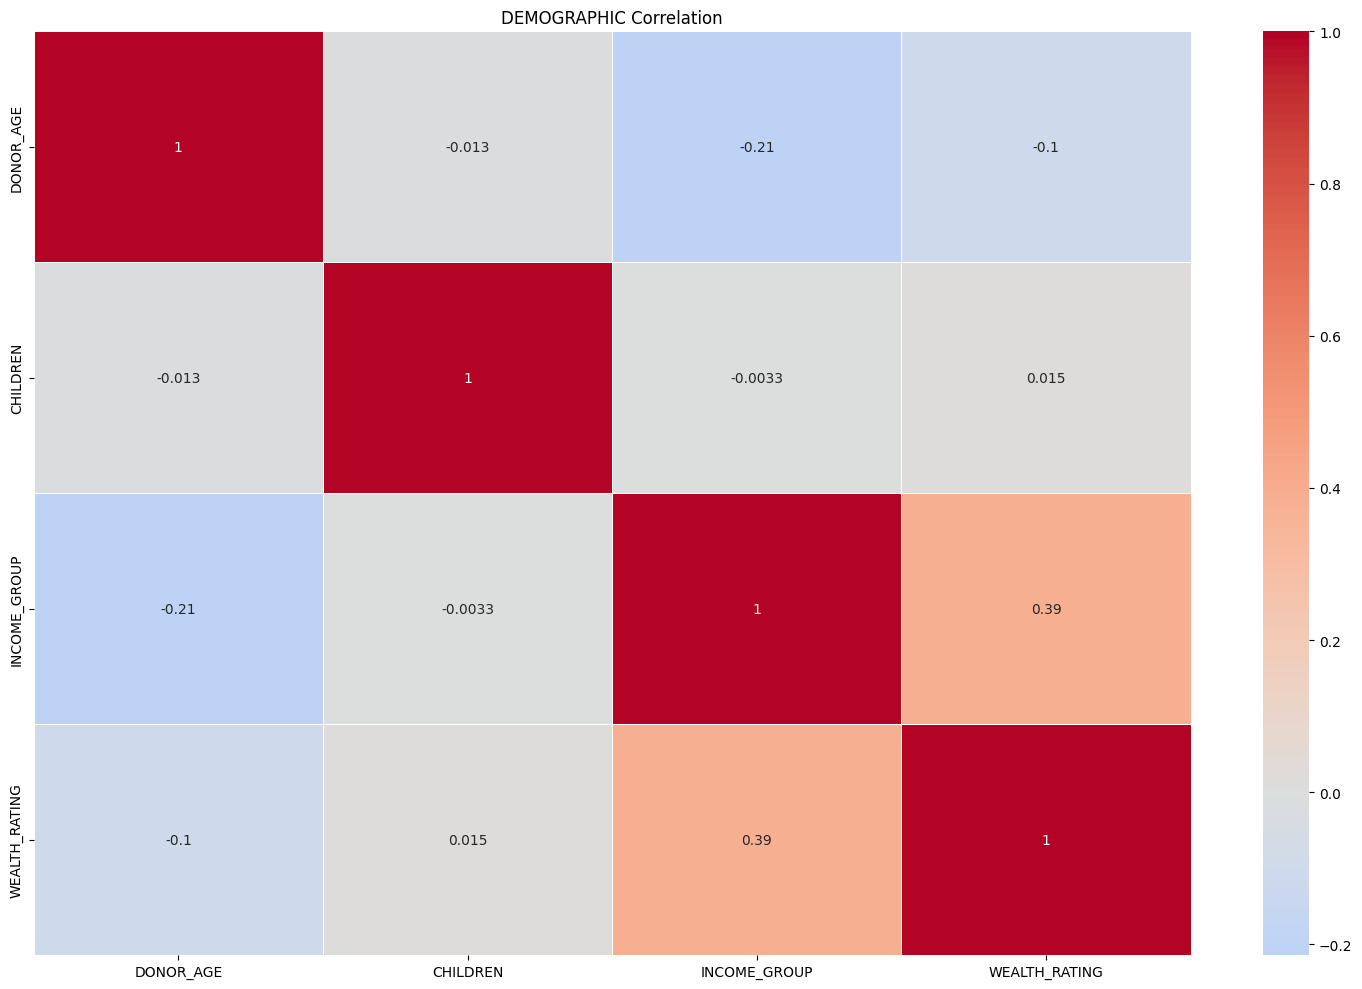

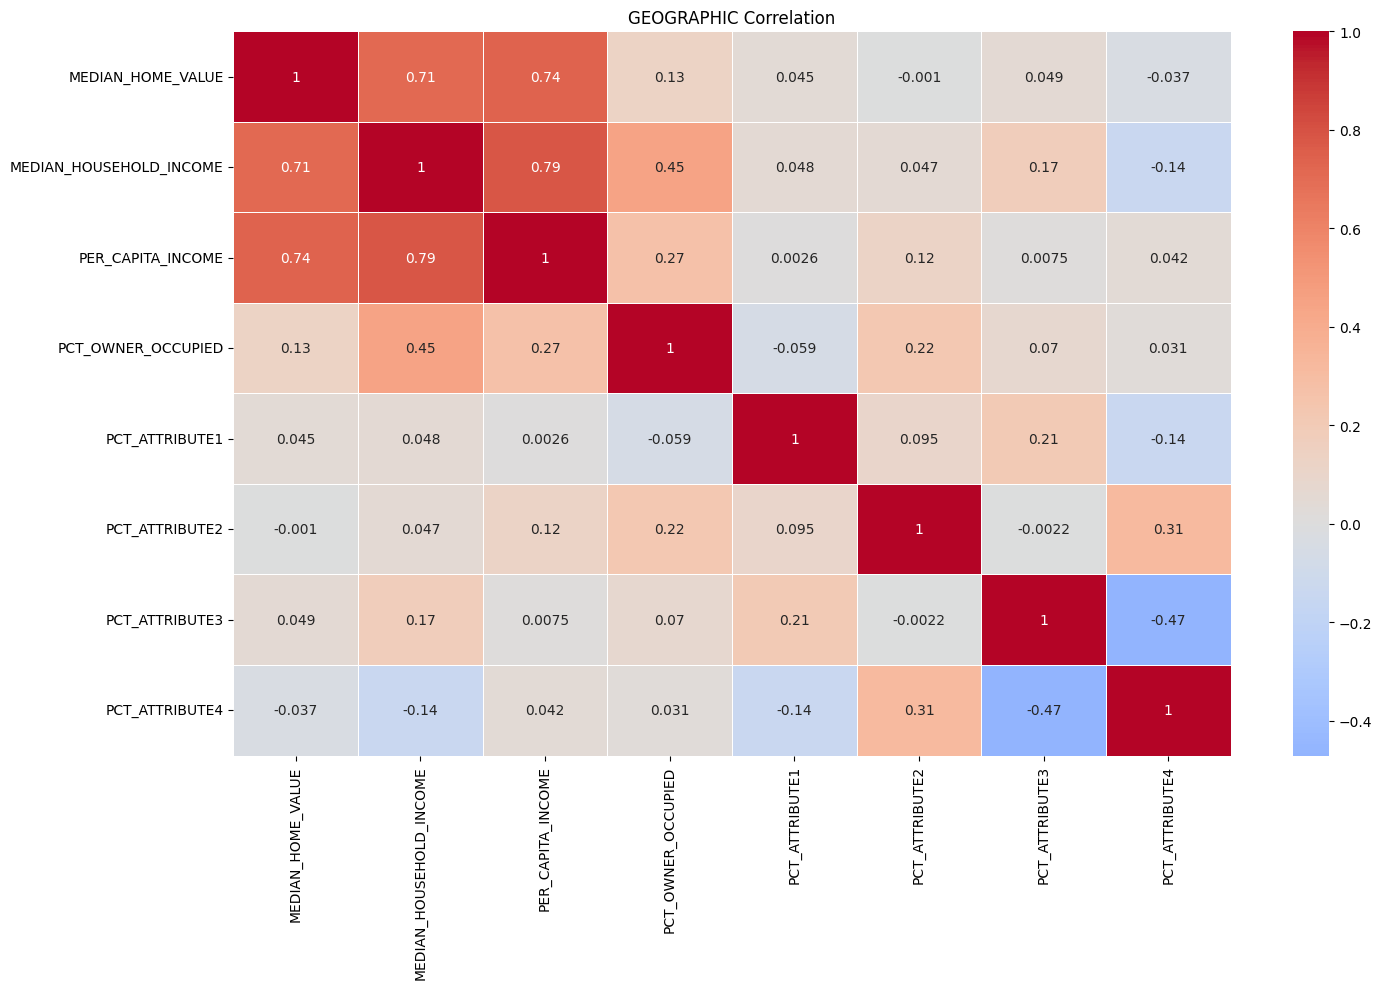

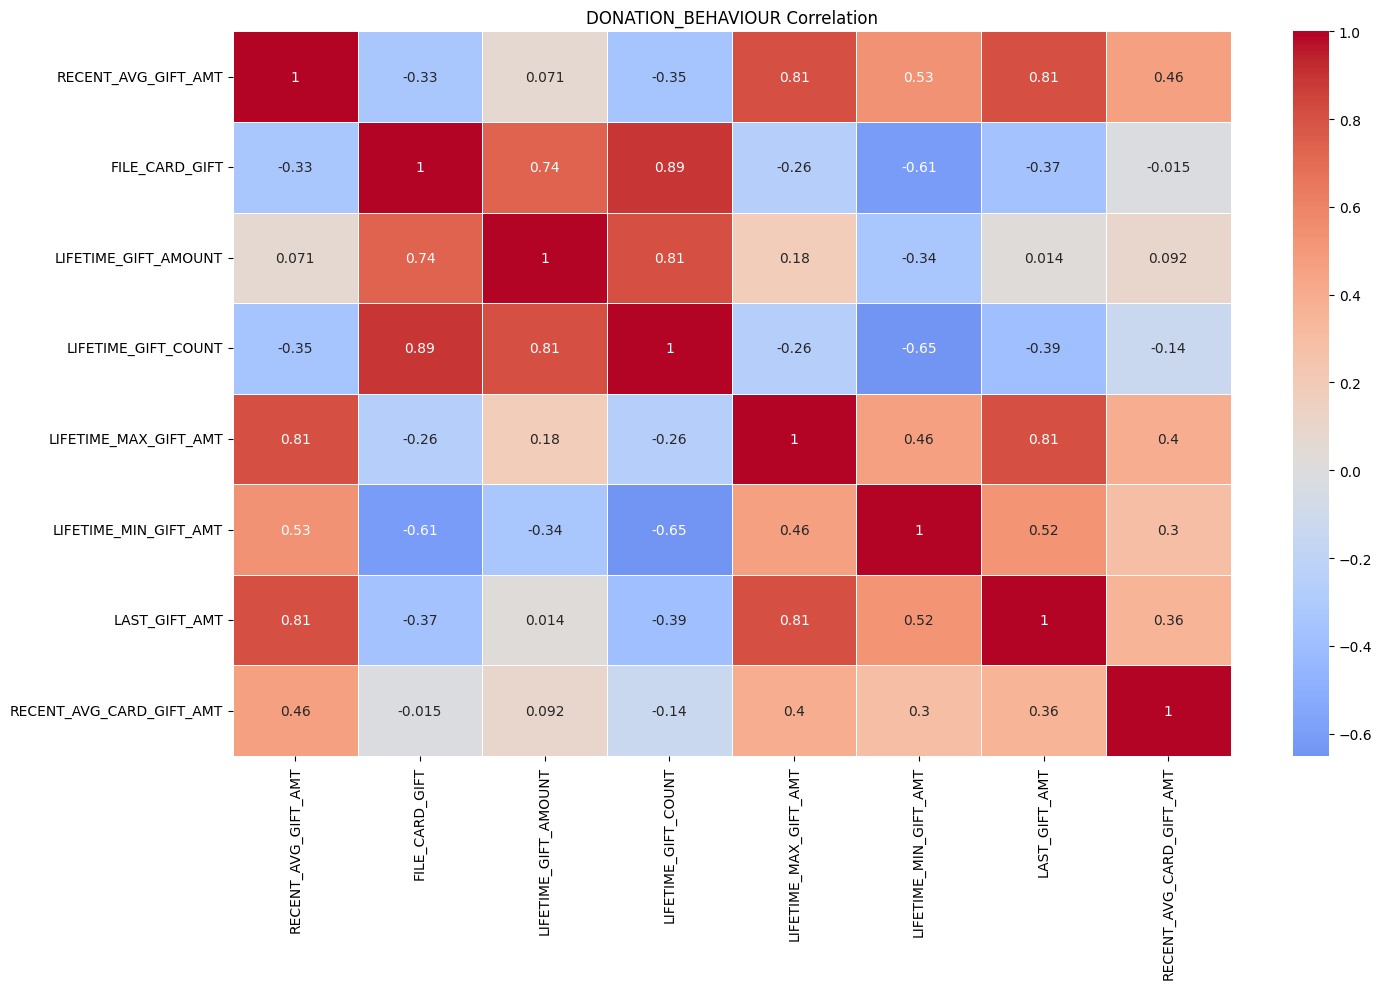

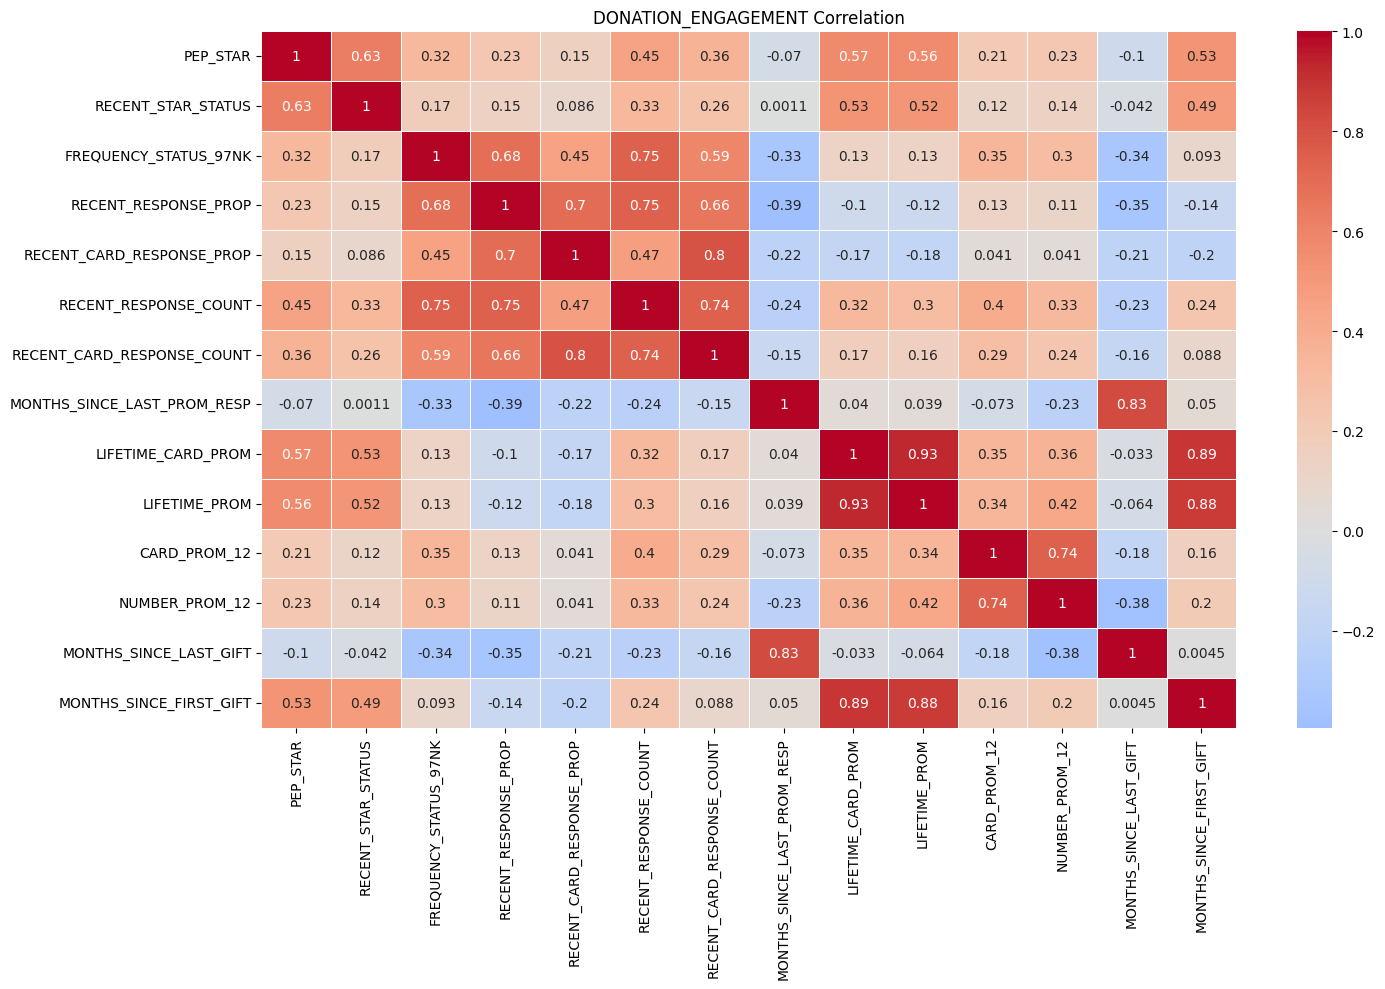

In [23]:
families = {
    "DEMOGRAPHIC": DEMOGRAPHIC,
    "GEOGRAPHIC": GEOGRAPHIC,
    "DONATION_BEHAVIOUR": DONATION_BEHAVIOUR,
    "DONATION_ENGAGEMENT": DONATION_ENGAGEMENT
}

for name, cols in families.items():
    plot_corr_num(df[cols], f"{name} Correlation")

- `Demographic`: this group doesn't show any relevant correlation between its features
- `Geographic`: this group shows some relevant correlation between a few of its features with a score in [0.4,0.8]
- `Donation_behaviour`: this group shows some relevant correlation between a few of its features with a score in [0.4,0.8]
- `Donation_engagement`: this group shows some relevant correlation between a few of its features with a score in [0.4,0.8]

---
## 2.3. Data Preparation <a name="data-preparation"></a>


---
### 2.3.1. Pre-Processing Data  <a name="preprocessing-data"></a>


A copy of the donors descriptive table is created to be used for further pre-processing.

In [24]:
df_copy = df.copy()

The name of the columns are set to lower case and the column control_number as the index.

In [25]:
df_copy.columns = df_copy.columns.str.lower()
if 'control_number' in df_copy.columns: # ensures idempotency when run multiple times
    df_copy.set_index('control_number', inplace=True)

---
### 2.3.2. Data Cleaning <a name="data-cleaning"></a>



This is a summary of the all transformations that were applied to the raw dataset in this section to get to the point where there are no features with null values and the dataset is ready to be used for the predictive model. The cleaning followed a structured sequence, beginning with the creation of the no_response_flag a binary indicator that determines the imputation logic across several dependent features.

The `no_response_flag`:

The first and most consequential transformation was applied to months_since_last_prom_resp. This variable records how many months ago a donor last responded to any promotion. When this value was missing, it was ambiguous: did the donor respond a long time ago, or have they never responded at all? To solve this, a binary flag was created
- no_response_flag = 1 - the donor has no record of ever responding to a promotion
- no_response_flag = 0 - the donor has responded at least once

months_since_last_prom_resp itself was then filled with the maximum observed value when no_response_flag = 1.

*Why does it metter to understand this flag?* Because several response related features are only meaningful if the donor has actually responded. Filling them with a median or mean for someone who has never responded would be wrong. The flag was therefore used as a conditional switch for the next group of variables:

| Feature | If no_response_flag = 1 | If no_response_flag = 0 |
|---|---|---|
| recent_response_count | Filled with 0 | Filled with column median |
| recent_card_response_count | Filled with 0 | Filled with column median |
| recent_response_prop | Filled with 0 | Filled with column median |
| recent_card_response_prop | Filled with 0 | Filled with column median |

---
The `lifetime_gift_count`:

This feature is also a consequential feature. It records the amount of times a donor has donated and it is important because for any donor with the value equal to 0 this will implicate the null inputation for the next ones that depend on a donation to have had happened.
- lifetime_gift_count - Set to 1 if lifetime_gift_amount > 0
- lifetime_gift_count - Else set to 0

| Variable | Invalid Values Treated | Imputation Strategy | Outlier Treatment |
|---|---|---|---|
| lifetime_gift_count | Negative values - NaN | Set to 1 if lifetime_gift_amount > 0, else 0 | Capped at 70 |
| lifetime_gift_amount | Negative values - NaN | 0 if count=0; Median per lifetime_gift_count | Capped at 800 |
| lifetime_min_gift_amt | Negative values - NaN | 0 if count=0; lifetime_gift_amount if count=1; else active median | Capped at 300 enforced ≤ lifetime_max_gift_amt |
| lifetime_max_gift_amt | Negative values - NaN | 0 if count=0; lifetime_gift_amount if count=1; else active median | Capped at 300 enforced ≥ lifetime_min_gift_amt |
| recent_avg_gift_amt | Negative values - NaN | 0 if count=0; lifetime_gift_amount if count=1; else active median | Capped at 300 |
| last_gift_amt | Negative values - NaN | 0 if count=0; lifetime_gift_amount if count=1; else active median | Capped at 300 |
| file_card_gift | Negative values - NaN | 0 if count=0; lifetime_gift_amount x ratio (ratio from observed data); | Capped at 30 |
| recent_avg_card_gift_amt | Negative values - NaN | 0 if count=0;recent_avg_gift_amt x card_ratio (ratio from observed data); | Capped at 90 |
---
Variables input with the *median/mode*:

| Variable | Invalid Values Treated | Imputation Strategy | Outlier Treatment |
|---|---|---|---|
| lifetime_prom | Negative values - NaN | Column median | Capped at 150 |
| children | Negative values - NaN | Column median | - |
| pct_owner_occupied | Values > 100 - NaN | Column median | - |
| pct_attribute1/2/3/4 | Negative values - NaN | Column median | - |
| per_capita_income | Negative values - NaN | Column median | Capped at 100,000 |
| donor_age | Values < 18 or > 100 - NaN | Column median | - |
| income_group | Values outside [1–7] - NaN | Mode within each urbanicity group | - |
| median_home_value | Negative values - NaN | Median within each urbanicity group | - |
| urbanicity | '?' and whitespace - NaN | Column mode | - |
| ses | '?' and non-numeric - NaN | Mode within each urbanicity group; | - |
| median_household_income | Negative values - NaN | Median within each ses group | Capped at 99th percentile |

---
Variables input with the *mode*:
| Variable | Invalid Values Treated | Imputation Strategy | Outlier Treatment |
|---|---|---|---|
| home_owner | - | Filled with 'U' (Unknown category) | - |
| donor_gender | - | Filled with 'U' (Unknown category) | - |
| lifetime_card_prom | Negative values - NaN | lifetime_prom x card_ratio (ratio from observed data) | Enforced ≤ lifetime_prom |
| number_prom_12 | Negative values - NaN | card_prom_12 value if available, else 0 | Capped at 50 |
| card_prom_12 | Negative values - NaN | 0 (assumed no card promotions) | Capped at 15; enforced ≤ number_prom_12 |
| wealth_rating | Values outside [0–9] - NaN | KNN Imputer (k=3) using median_household_income, per_capita_income, median_home_value | Clipped to [0, 9] |
| recency_status_96nk | - | Column mode | - |
| frequency_status_97nk | Negative values - NaN | Mode within each recency_status_96nk group | - |
| months_since_first_gift | Negative values - NaN | Mode within each recency_status_96nk group or months_since_last_gift if greater | Capped at 99th percentile per recency group |
| months_since_last_gift | Negative values - NaN | Filled from months_since_first_gift; max value if lifetime_gift_count=0 | Capped at 99th percentile per recency group |

---

`months_since_last_prom_resp`
- this feature must be > 0
- null values were filled with the maximum value because we assume these values represent individuals that have never responded
- a new feature was created called `no_response_flag` - this feature is 1 for all rows where `months_since_last_prom_resp` is null and 0 for where it is not. This flag represents if someone has ever responded to any type of promotions or not, since when it is null we can´t know for sure it has.
This will help clean other variables based on this fact.

In [26]:
# Months_since_last_prom_resp
# df_copy['months_since_last_prom_resp'].describe()
df_copy.loc[df_copy['months_since_last_prom_resp'] < 0, 'months_since_last_prom_resp'] = np.nan
df_copy['no_response_flag'] = df_copy['months_since_last_prom_resp'].isna().astype(int)
max_months = df_copy['months_since_last_prom_resp'].max()
df_copy['months_since_last_prom_resp'] = df_copy['months_since_last_prom_resp'].fillna(max_months)
# Assure feature consistency
df_copy['months_since_last_prom_resp'] = df_copy['months_since_last_prom_resp'].round(0).astype(int)

/tmp/ipykernel_2808/2809170992.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='no_response_flag', data=df_copy, palette='pink', ax=axes[2])
/tmp/ipykernel_2808/2809170992.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(['Has answered (0)', 'Never answered (1)'])


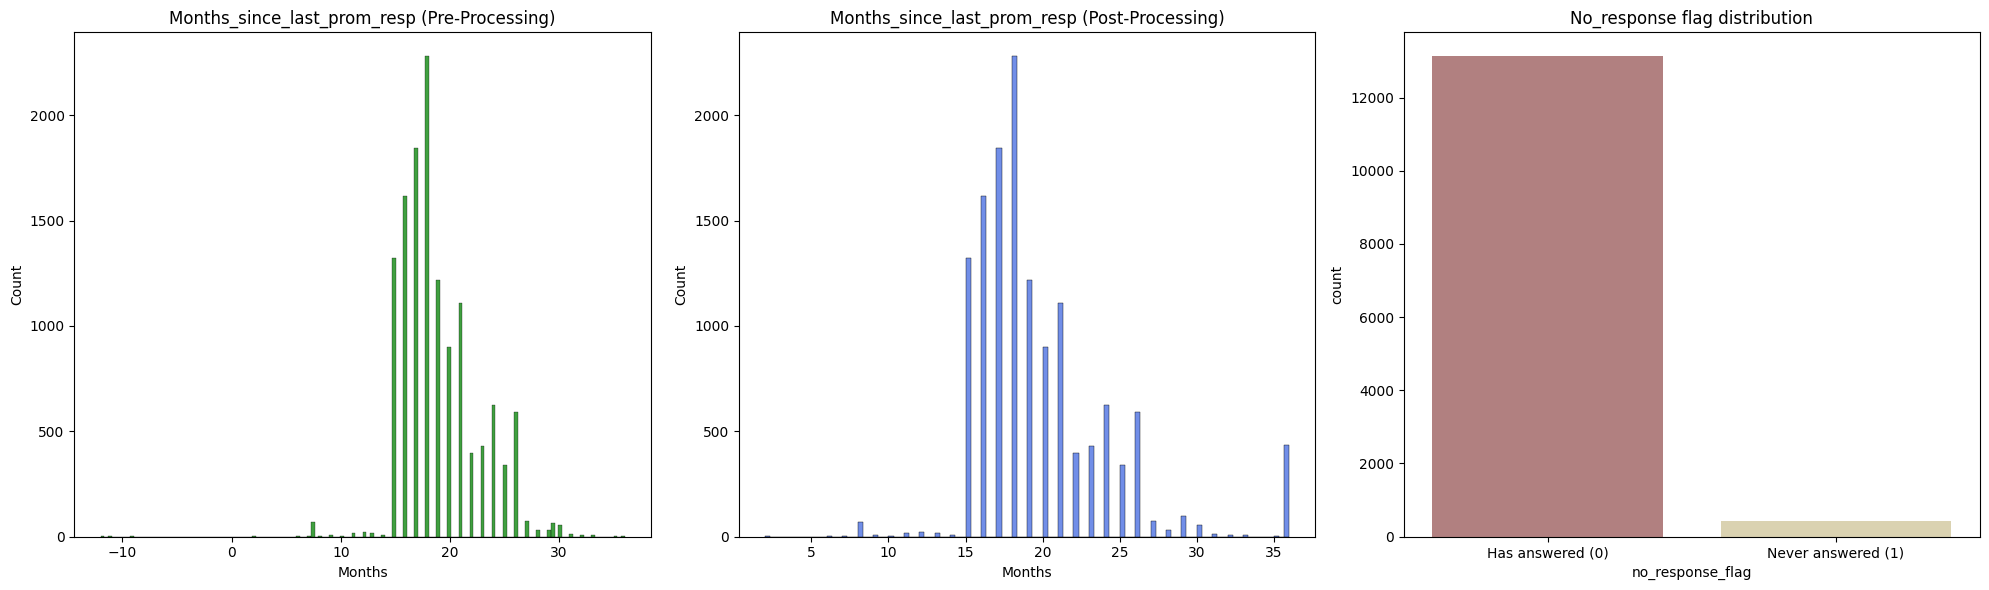

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.histplot(df['MONTHS_SINCE_LAST_PROM_RESP'], color='green', ax=axes[0])
axes[0].set_title('Months_since_last_prom_resp (Pre-Processing)')
axes[0].set_xlabel('Months')

sns.histplot(df_copy['months_since_last_prom_resp'], color='royalblue', ax=axes[1])
axes[1].set_title('Months_since_last_prom_resp (Post-Processing)')
axes[1].set_xlabel('Months')

sns.countplot(x='no_response_flag', data=df_copy, palette='pink', ax=axes[2])
axes[2].set_title('No_response flag distribution')
axes[2].set_xticklabels(['Has answered (0)', 'Never answered (1)'])
plt.tight_layout()
plt.show()

The distribution of `months_since_last_prom_resp` is shown before preprocessing, post-processing and with the `no_response_flag`distribution. This confirms the cleaning logic worked as intended.

`recent_response_count` and `recent_card_response_count` (counts)

`recent_response_prop` and `recent_card_response_prop` (proportions)
- the 4 features must be > 0
- the proportion features must be < 1
- null values were filled taking into consideration the `no_response_flag`:
  - where `no_response_flag` = 1 the null values were filled with 0 because if our individual has never responded it can't have a response count/proportion;
  - where `no_response_flag` = 0 the null values were filled with the median of the respective columns.
- we also ensure that recent_card_response_count is never > than recent_response_count. If that happens we substitute the recent_respose_count for the respective recent_card_response_count.

In [28]:
# Recent_response_count, Recent_card_response_count
# Recent_reponse_prop, Recent_card_response_prop
recent_count = ['recent_response_count','recent_card_response_count']
recent_prop = ['recent_response_prop','recent_card_response_prop']
# df_copy[recent_count + recent_prop].describe()
for col in recent_count + recent_prop:
    df_copy.loc[df_copy[col] < 0, col] = np.nan
    df_copy.loc[df_copy['no_response_flag'] == 1, col] = 0

for col in recent_count + recent_prop:
    med_actives = df_copy.loc[df_copy['no_response_flag'] == 0, col].median()
    df_copy[col] = df_copy[col].fillna(med_actives)

df_copy['recent_response_count'] = np.where(df_copy['recent_response_count'] < df_copy['recent_card_response_count'],
                                            df_copy['recent_card_response_count'],
                                            df_copy['recent_response_count'])

df_copy[recent_prop] = df_copy[recent_prop].clip(0, 1)
# Assure feature consistency
df_copy[recent_count] = df_copy[recent_count].round(0).astype(int)

On the following scatter plots we verify if the rule (recent_card_response_count <= recent_response_count) applied to our data and if it had any affect on the distribution of the data. The expected outcome is the points being distributed on top on the line or above it.

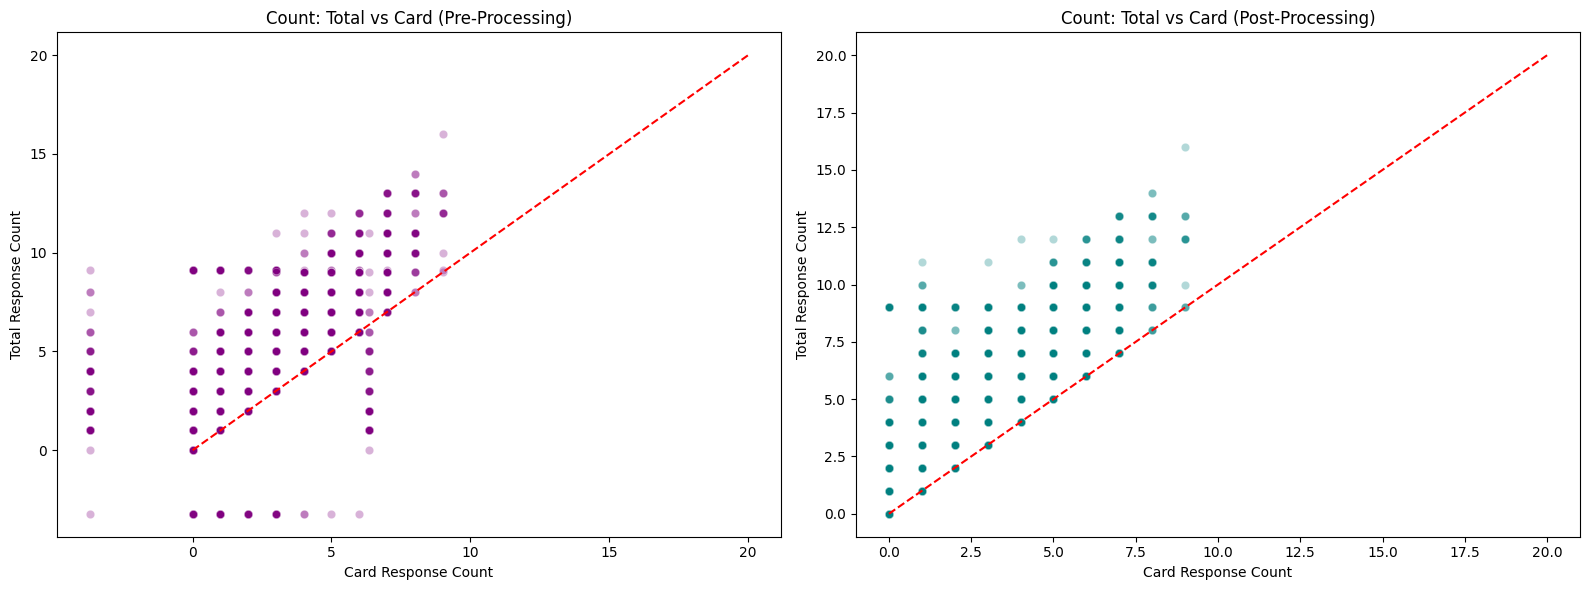

In [29]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x='RECENT_CARD_RESPONSE_COUNT', y='RECENT_RESPONSE_COUNT', data=df, alpha=0.3, color='purple')
plt.plot([0, 20], [0, 20], color='red', linestyle='--')
plt.title('Count: Total vs Card (Pre-Processing)')
plt.xlabel('Card Response Count')
plt.ylabel('Total Response Count')
plt.subplot(1, 2, 2)
sns.scatterplot(x='recent_card_response_count', y='recent_response_count', data=df_copy, alpha=0.3, color='teal')
plt.plot([0, 20], [0, 20], color='red', linestyle='--')
plt.title('Count: Total vs Card (Post-Processing)')
plt.xlabel('Card Response Count')
plt.ylabel('Total Response Count')
plt.tight_layout()
plt.show()

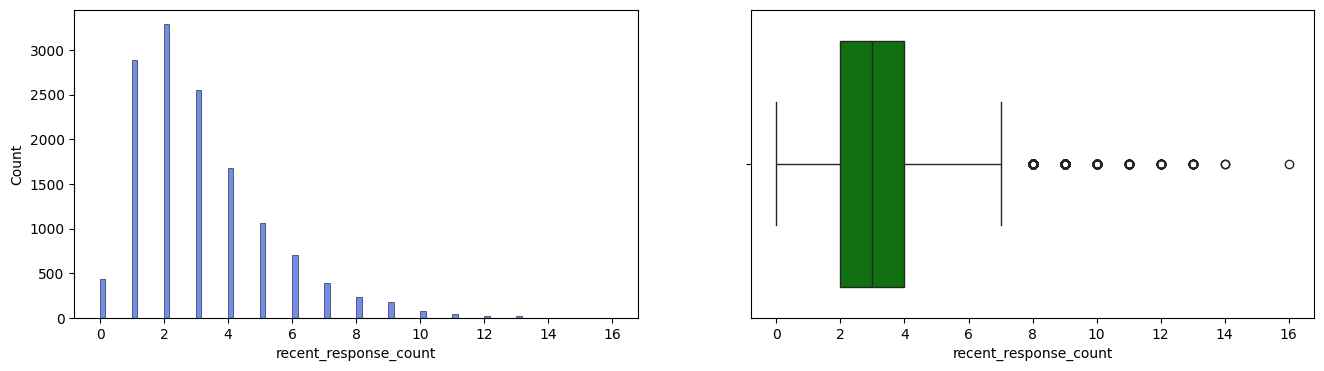

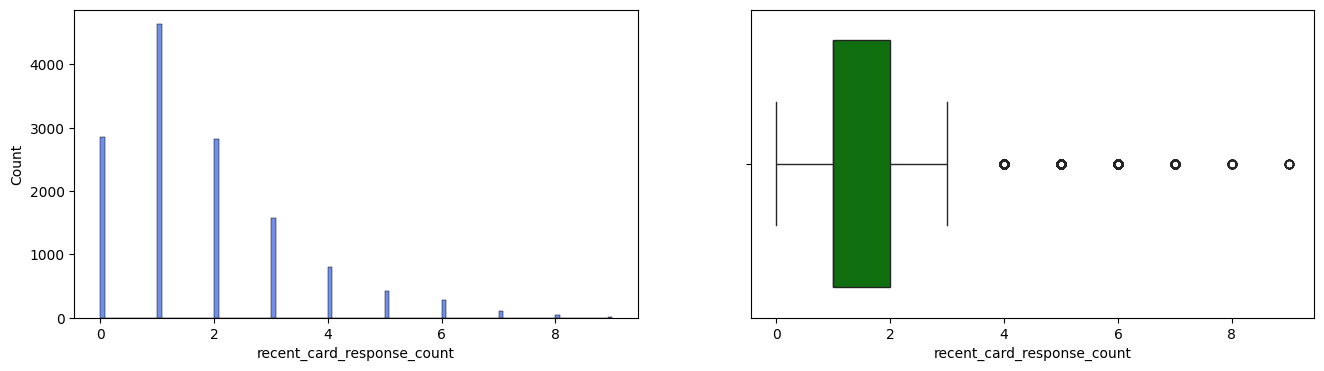

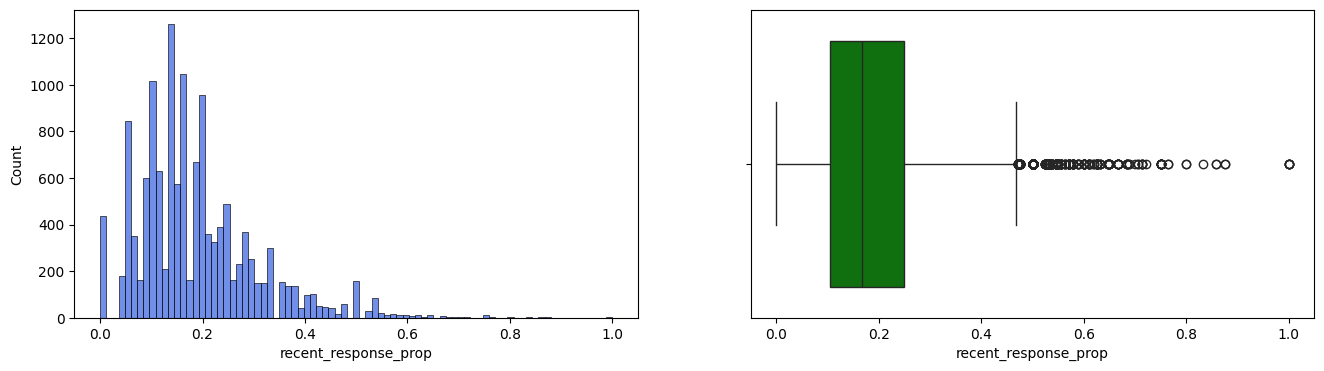

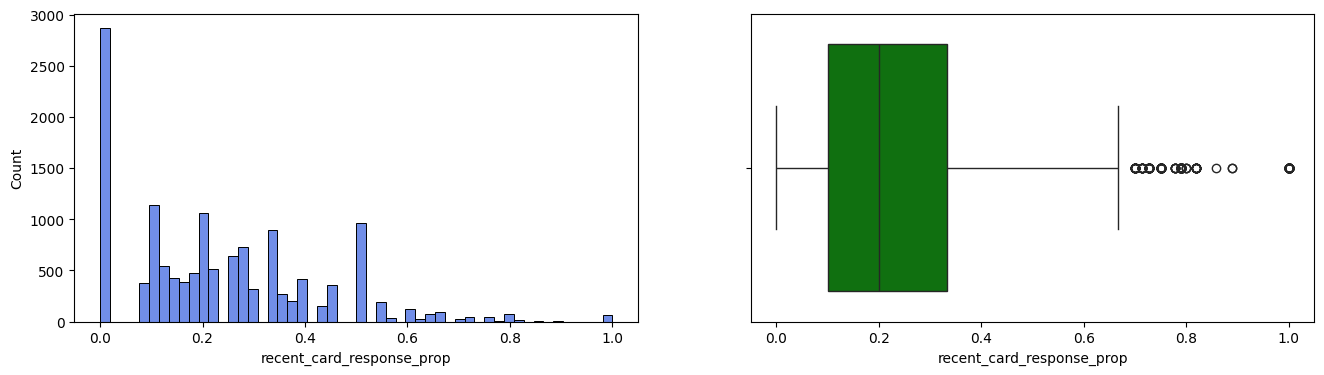

In [30]:
for col in recent_count + recent_prop:
  boxplot_hist(df_copy, col)

These plots allow us to make a distribution check for response counts and proportions after processing the variables. Since these are count and proportion features, outliers are retained as they represent genuine donor behaviour.

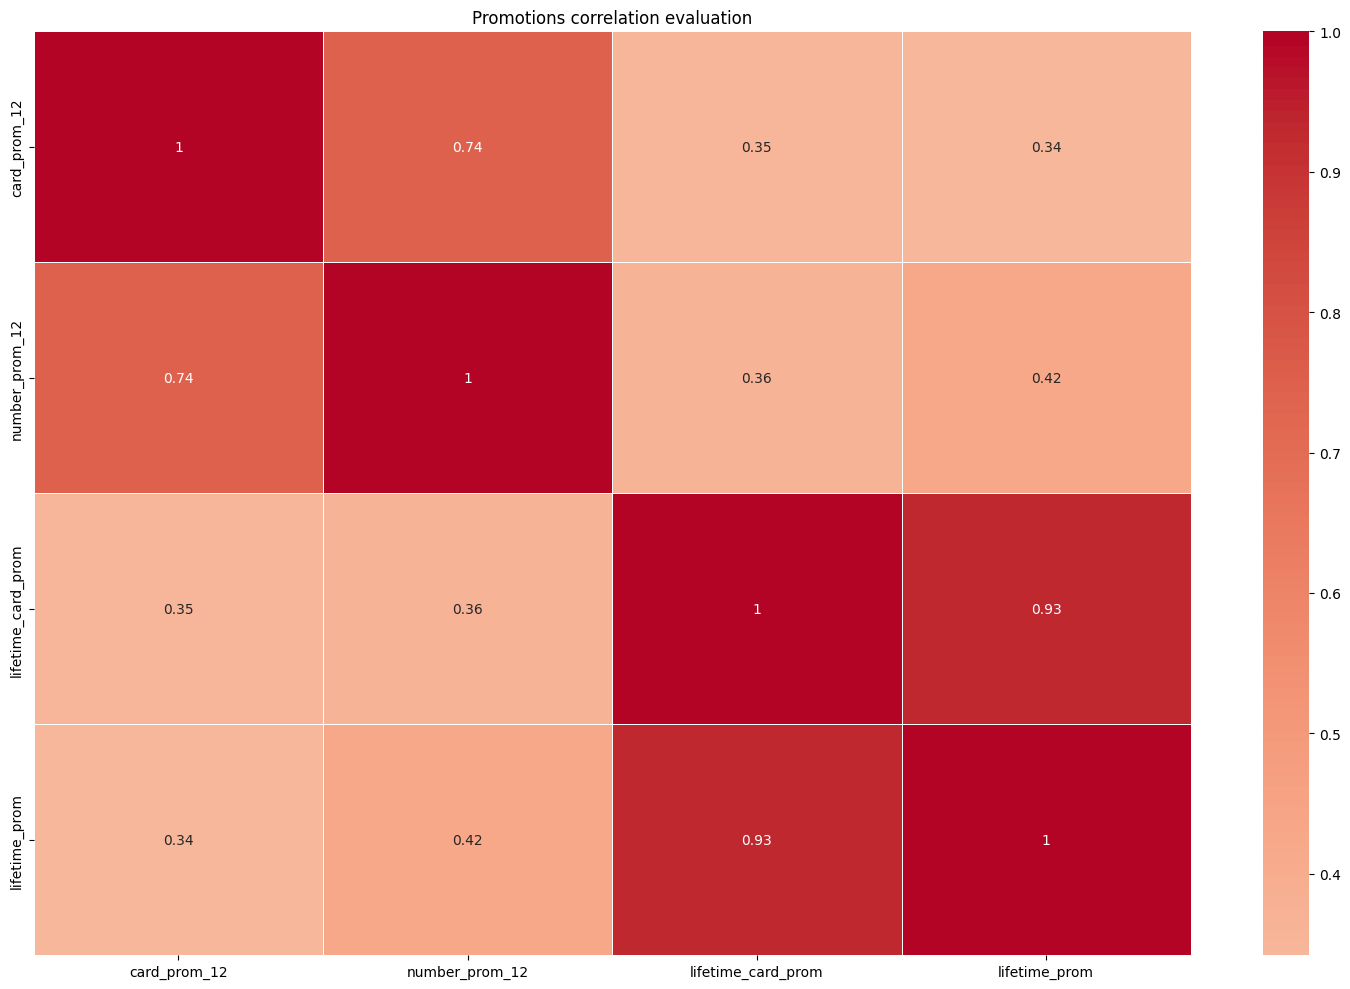

In [31]:
subset = ['card_prom_12', 'number_prom_12','lifetime_card_prom', 'lifetime_prom']
plot_corr_num(df_copy[subset], "Promotions correlation evaluation")

With this heatmap we evaluate the correlation between the variables that are being treated next. The goal is to confirm if they are related and that the inputation strategy is internally consistent.

`lifetime_prom`
- this feature must be > 0
- null values were filled with the median since this feature is count based

In [32]:
# Lifetime_prom
#df_copy['lifetime_prom'].describe()
df_copy.loc[df_copy['lifetime_prom'] < 0, 'lifetime_prom'] = np.nan
df_copy['lifetime_prom'] = df_copy['lifetime_prom'].fillna(df_copy['lifetime_prom'].median())
# Assure feature consistency
df_copy['lifetime_prom'] = df_copy['lifetime_prom'].abs().round(0).astype(int)

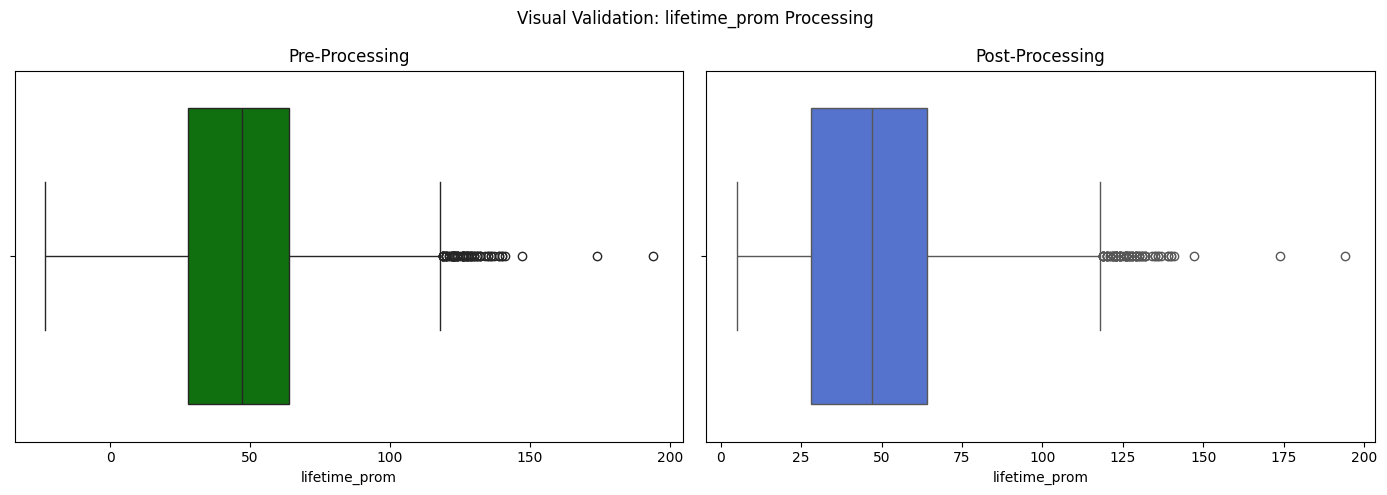

In [33]:
box_plot('lifetime_prom')

By analyzing the boxplots we can see that `lifetime_prom` has prominent outliers superior to 150. So, to treat them we placed a cap on them.
After, we plot the histograms pre- and post-processing to evaluate the distribution of the data.

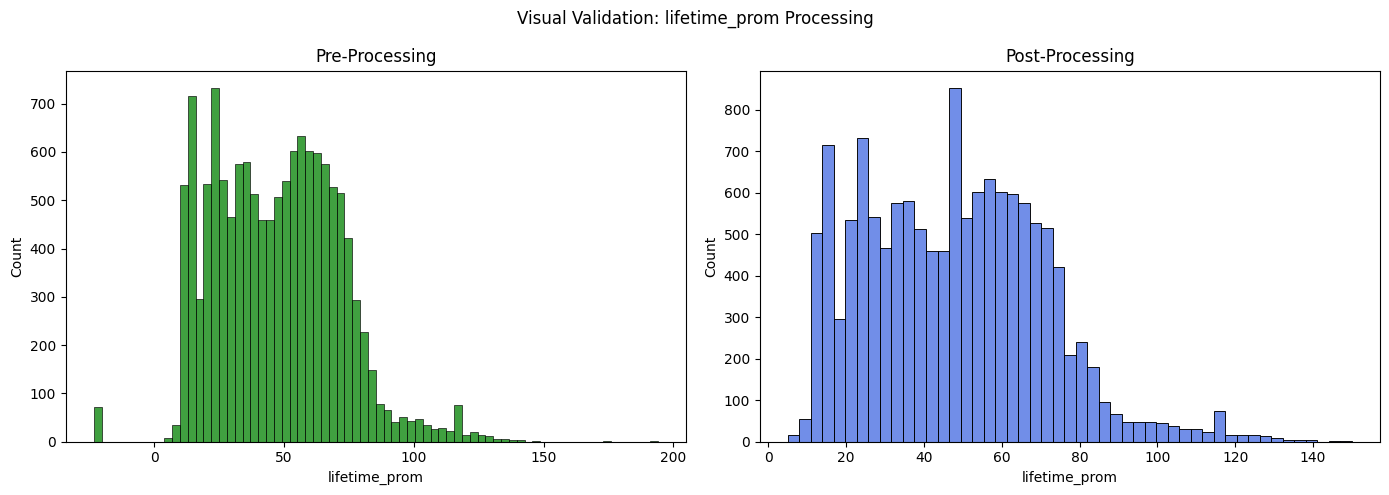

In [34]:
mask = df_copy['lifetime_prom']>150
df_copy['lifetime_prom'] = np.where(mask, 150, df_copy['lifetime_prom'])
hist_plot('lifetime_prom')

`lifetime_card_prom`
- this feature must be > 0
- to fill the null values we calculated the card ratio (average proportion of card-based promotions relative to all promotions) and multiplied it with the total promotions. This ensures that the value is logically scaled to each individuals history
- we also ensure that lifetime_card_prom is never > than lifetime_prom. If that happens we substitute the lifetime_prom for the lifetime_card_prom

In [35]:
# Lifetime_card_prom
#df_copy['lifetime_card_prom'].describe()
df_copy.loc[df_copy['lifetime_card_prom'] < 0, 'lifetime_card_prom'] = np.nan
# Calculate the card ratio
# We filter for donors with lifetime_prom > 0 to prevent division by zero
card_ratio = (df_copy['lifetime_card_prom'] / df_copy.loc[df_copy['lifetime_prom'] >0 ,'lifetime_prom']).mean()
df_copy['lifetime_card_prom'] = df_copy['lifetime_card_prom'].fillna(df_copy['lifetime_prom'] * card_ratio)
df_copy['lifetime_card_prom'] = np.where(df_copy['lifetime_card_prom'] > df_copy['lifetime_prom'], df_copy['lifetime_prom'], df_copy['lifetime_card_prom'])
# Assure feature consistency
df_copy['lifetime_card_prom'] = df_copy['lifetime_card_prom'].abs().round(0).astype(int)

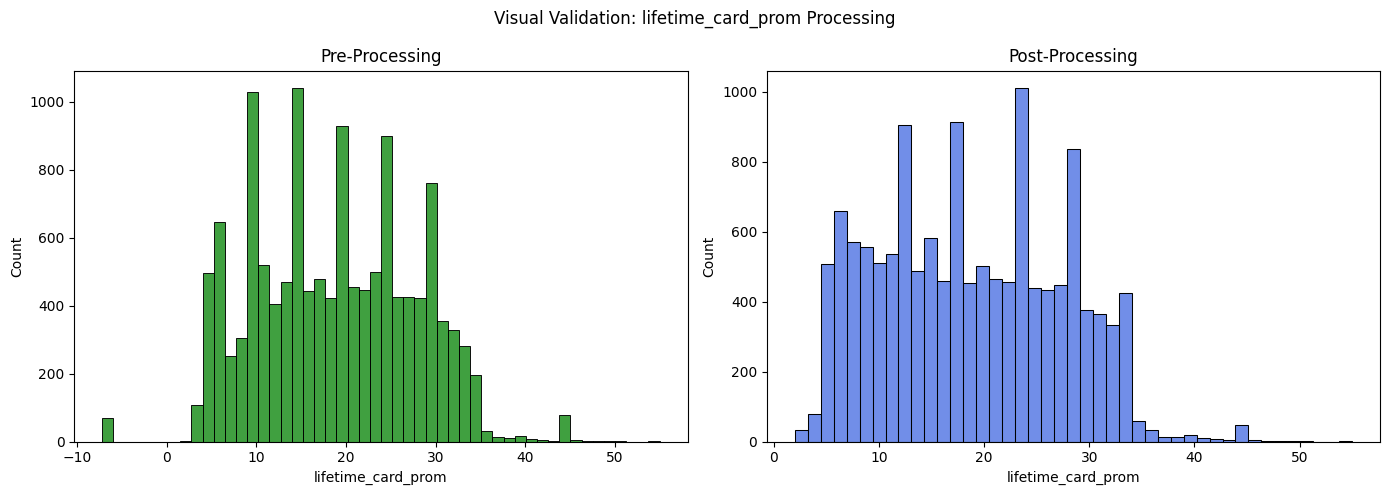

In [36]:
hist_plot('lifetime_card_prom')

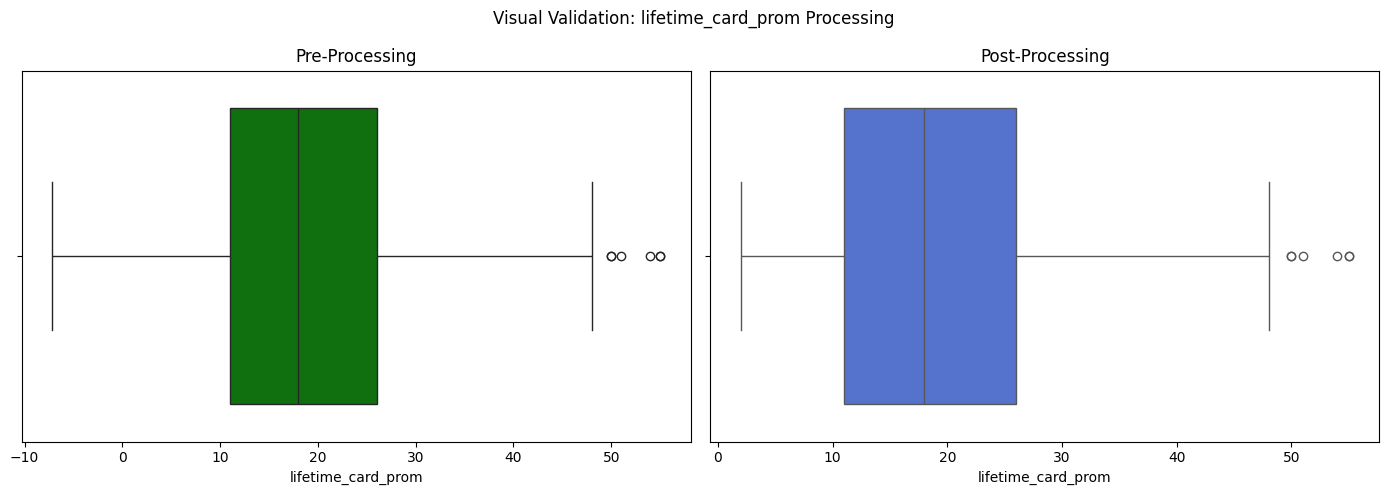

In [37]:
box_plot('lifetime_card_prom')


On the following scatter plots we verify if the rule (lifetime_card_prom <= lifetime_prom) applied to our data and if it had any affect on the distribution of the data. The expected outcome is the points being distributed on top on the line or above it.


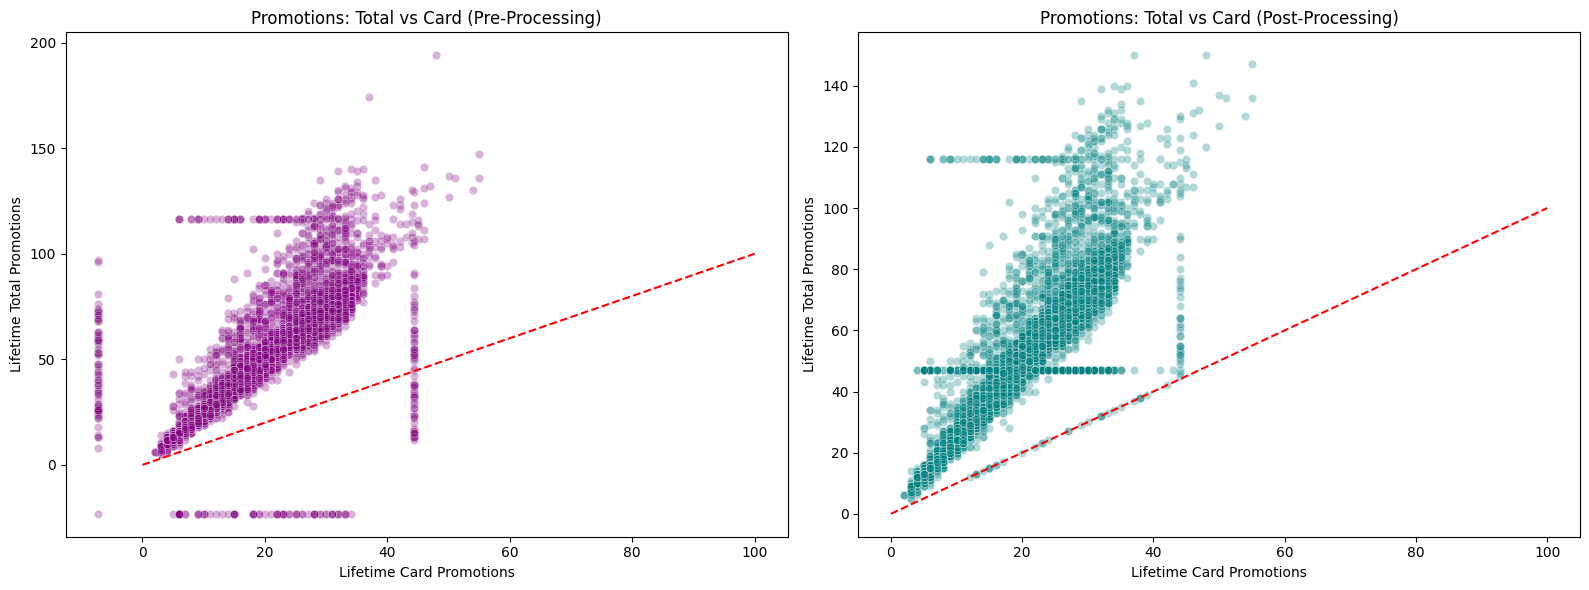

In [38]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x='LIFETIME_CARD_PROM', y='LIFETIME_PROM', data=df, alpha=0.3, color='purple')
plt.plot([0, 100], [0, 100], color='red', linestyle='--')
plt.title('Promotions: Total vs Card (Pre-Processing)')
plt.xlabel('Lifetime Card Promotions')
plt.ylabel('Lifetime Total Promotions')
plt.subplot(1, 2, 2)
sns.scatterplot(x='lifetime_card_prom', y='lifetime_prom', data=df_copy, alpha=0.3, color='teal')
plt.plot([0, 100], [0, 100], color='red', linestyle='--')
plt.title('Promotions: Total vs Card (Post-Processing)')
plt.xlabel('Lifetime Card Promotions')
plt.ylabel('Lifetime Total Promotions')
plt.tight_layout()
plt.show()

`number_prom_12` and `card_prom_12`
- these features must be > 0
- in `number_prom_12` the null values were filled using the following condition: if `card_prom_12`is not null, we input the null value with that respective value; everything else with 0
- in `card_prom_12` the null values were assumed to most likelyy be 0
- we also ensure that card_prom_12 is never > than number_prom_12. If that happens we substitute the number_prom_12 for the card_prom_12

In [39]:
# Number_prom_12, Card_prom_12
cols = ['number_prom_12', 'card_prom_12']
df_copy[cols] = df_copy[cols].mask(df_copy[cols] < 0)

df_copy['number_prom_12'] = df_copy['number_prom_12'].fillna(df_copy['card_prom_12']).fillna(0)
df_copy.loc[df_copy['number_prom_12']<df_copy['card_prom_12'], 'card_prom_12']= df_copy.loc[df_copy['number_prom_12']<df_copy['card_prom_12'], 'number_prom_12']
df_copy['card_prom_12'] = df_copy['card_prom_12'].fillna(0)
# Assure feature consistency
df_copy[cols] = df_copy[cols].abs().round().astype(int)
# cols = ['card_prom_12', 'number_prom_12']
# for col in cols:
#   print(df_copy[col].describe())


On the following scatter plots we verify if the rule (card_prom_12 <= number_prom_12) applied to our data and if it had any affect on the distribution of the data. The expected outcome is the points being distributed on top on the line or above it.


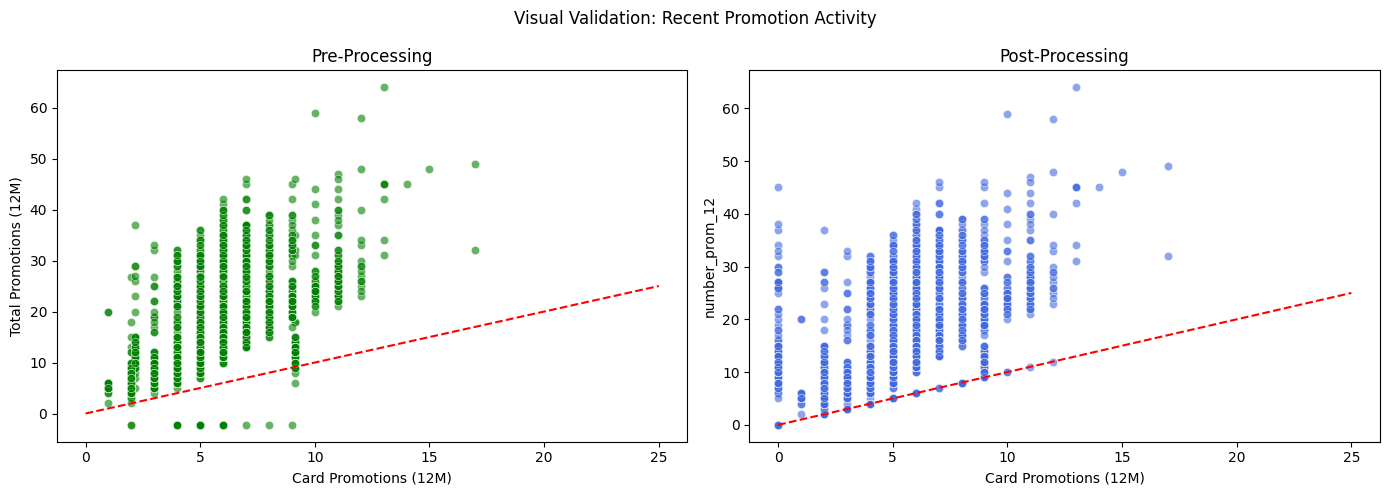

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(x=df['CARD_PROM_12'], y=df['NUMBER_PROM_12'], ax=axes[0], color='green', alpha=0.6)
axes[0].plot([0, 25], [0, 25], linestyle='--', color='red')
axes[0].set_title("Pre-Processing")
axes[0].set_xlabel("Card Promotions (12M)")
axes[0].set_ylabel("Total Promotions (12M)")
sns.scatterplot(x=df_copy['card_prom_12'], y=df_copy['number_prom_12'], ax=axes[1], color='royalblue', alpha=0.6)
axes[1].plot([0, 25], [0, 25], linestyle='--', color='red')
axes[1].set_title("Post-Processing")
axes[1].set_xlabel("Card Promotions (12M)")
plt.suptitle("Visual Validation: Recent Promotion Activity")
plt.tight_layout()
plt.show()

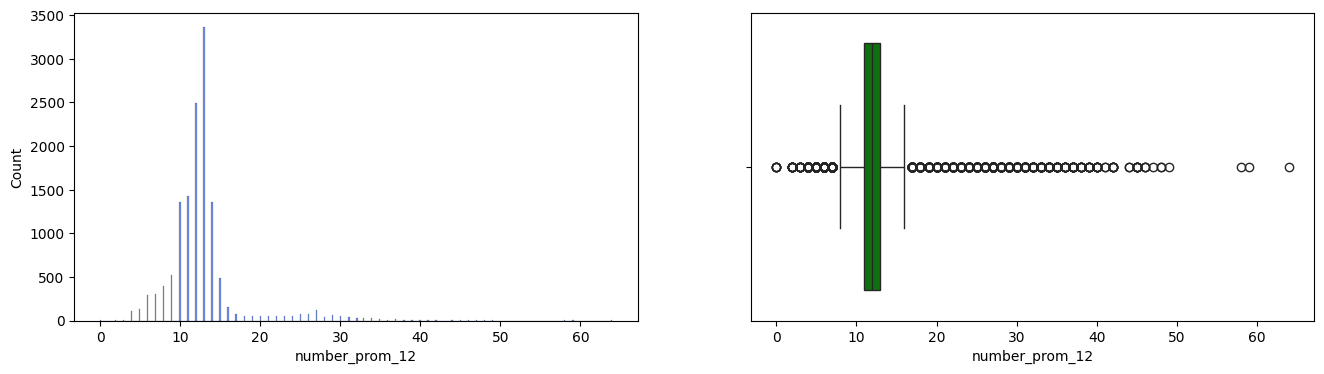

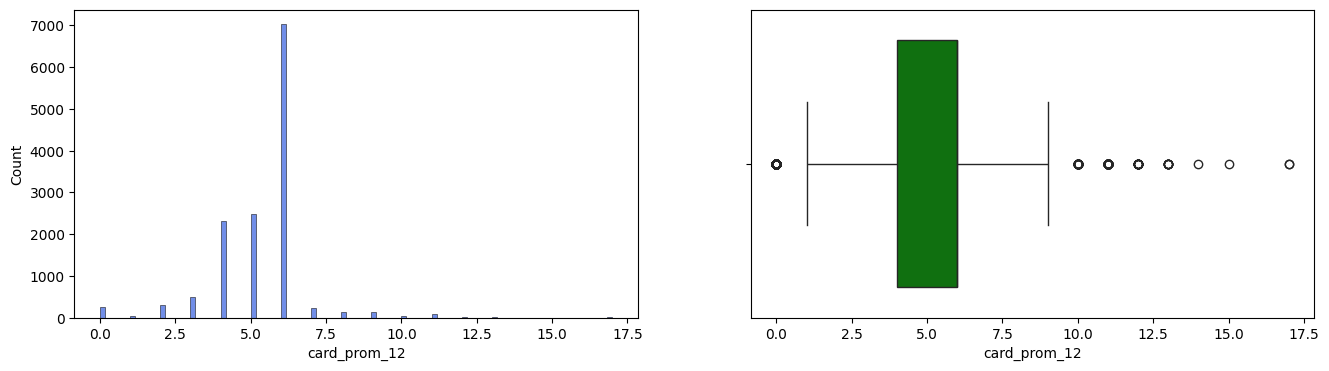

In [41]:
for col in cols:
  boxplot_hist(df_copy,col)

By analyzing the boxplots we can see that `number_prom_12`and `card_prom_12` have prominent outliers. In this case, it makes sense to put a cap on the number of promotions because it' plausible they received a lot of them. Regardless, it is strange that they received so much more.
After, we plot the boxplots pre- and post-processing to evaluate the distribution of the data.

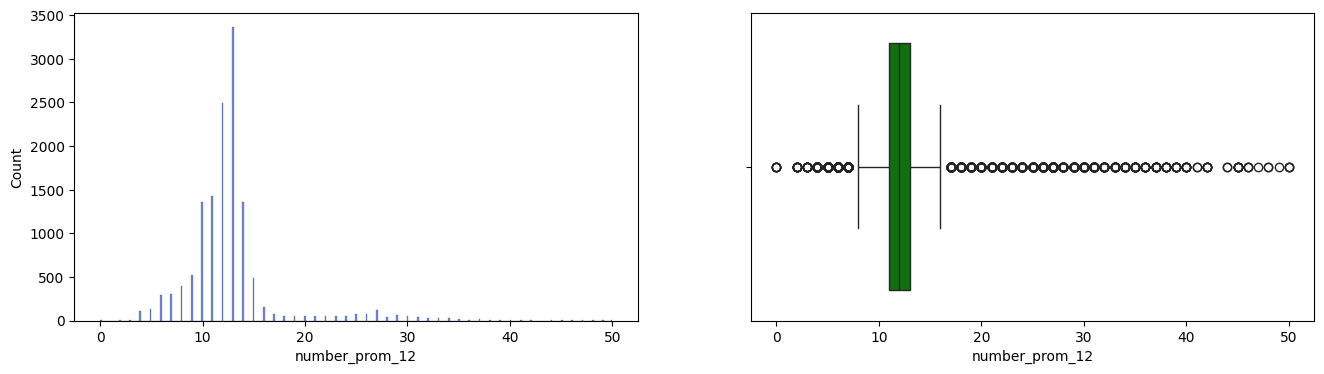

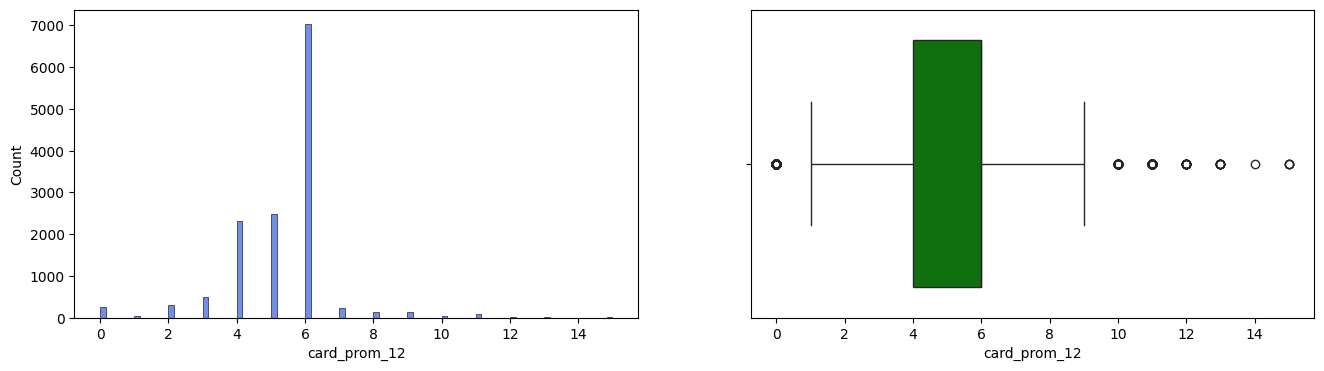

In [42]:
df_copy['number_prom_12'] = np.where(df_copy['number_prom_12'] > 50, 50, df_copy['number_prom_12'])
df_copy['card_prom_12'] = np.where(df_copy['card_prom_12'] > 15, 15, df_copy['card_prom_12'])
for col in cols:
  boxplot_hist(df_copy,col)

`donor_gender`
- the null values were assumed to belong to the category 'Unknown'. So, they were inputed with the respective category

In [43]:
# Donor_gender
# df_copy['donor_gender'].describe()
df_copy['donor_gender'] = df_copy['donor_gender'].fillna('U')

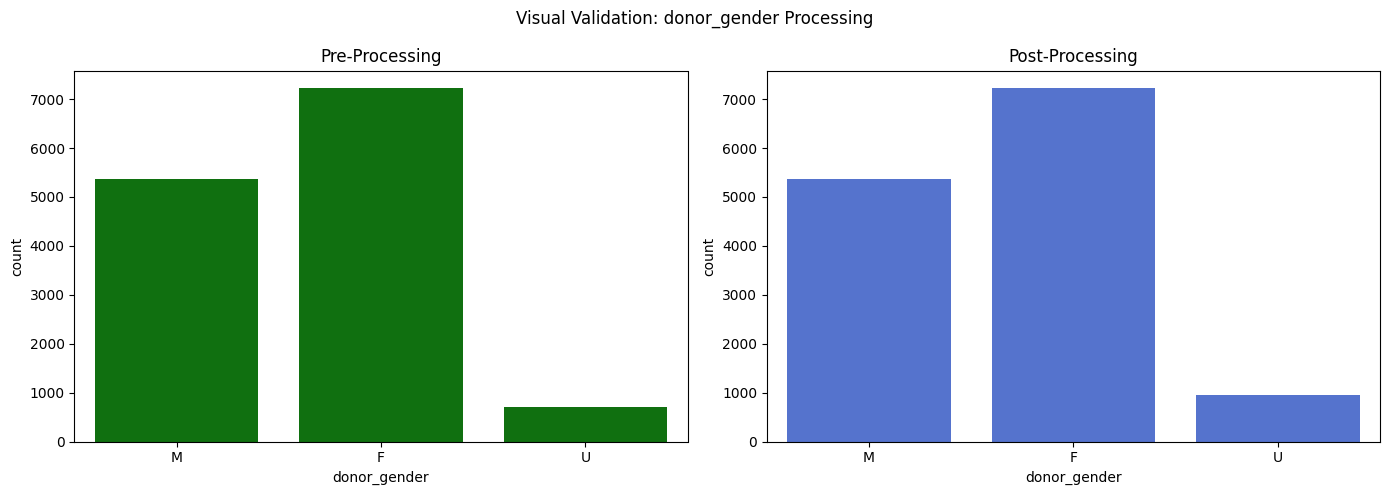

In [44]:
count_plot('donor_gender')

`children`
- this feature must be > 0
- the null values were filled with the median preserving data integrity

In [45]:
# Children
#df_copy['children'].describe()
df_copy.loc[df_copy['children'] < 0, 'children'] = np.nan
df_copy['children'] = df_copy['children'].fillna(df_copy['children'].median())
# Assure feature consistency
df_copy['children'] = df_copy['children'].round(0).astype(int)

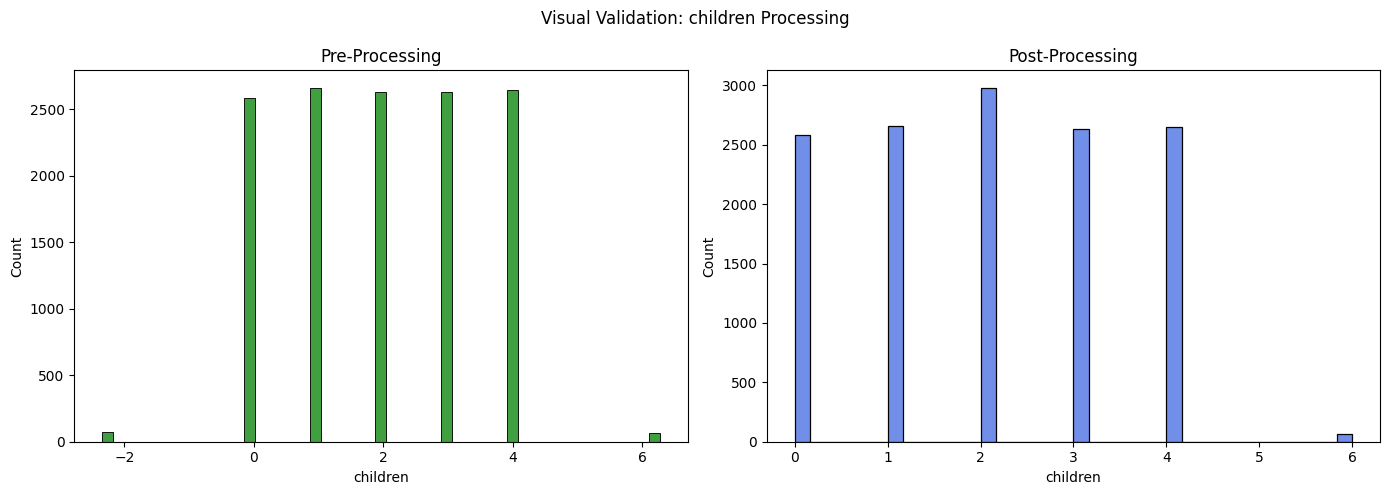

In [46]:
hist_plot('children')

`home_owner`
- the null values were assumed to belong to the category 'Unknown'. So, they were inputed with the respective category

In [47]:
# Home_owner
#df_copy['home_owner'].describe()
df_copy['home_owner'] = df_copy['home_owner'].fillna('U')

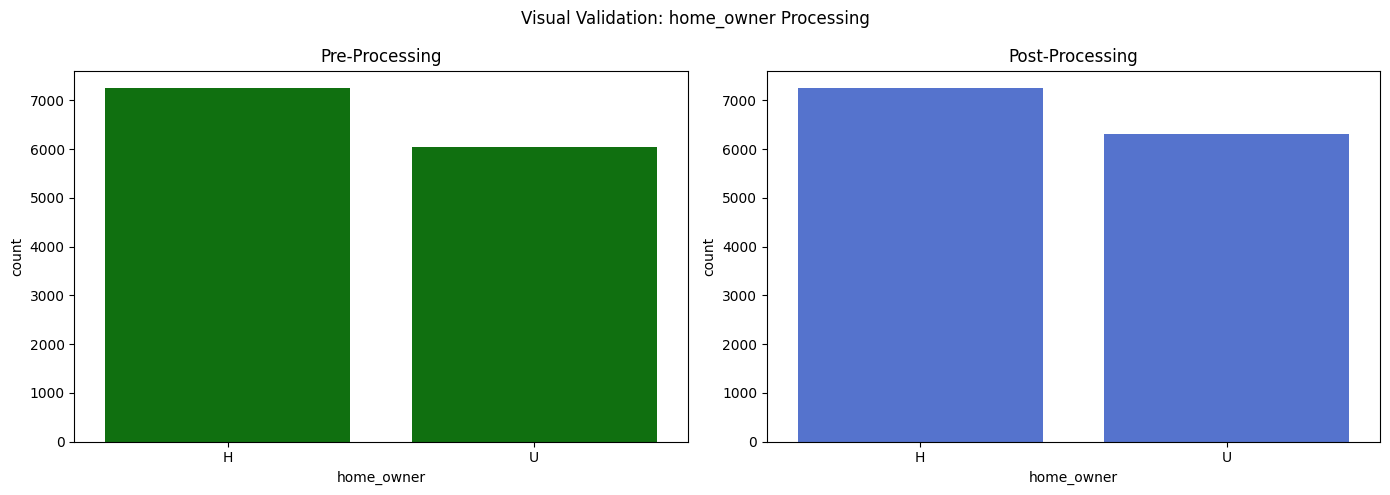

In [48]:
count_plot('home_owner')

`pct_owner_occupied`
- this feature must be < 100, since it represents a percentage
- the null values were filled with the median preserving data integrity

In [49]:
# Pct_owner_occupied
#df_copy['pct_owner_occupied'].describe()
df_copy.loc[df_copy['pct_owner_occupied'] > 100, 'pct_owner_occupied'] = np.nan
df_copy['pct_owner_occupied'] = df_copy['pct_owner_occupied'].fillna(df_copy['pct_owner_occupied'].median())
# Assure feature consistency
df_copy['pct_owner_occupied'] = df_copy['pct_owner_occupied'].round(2)

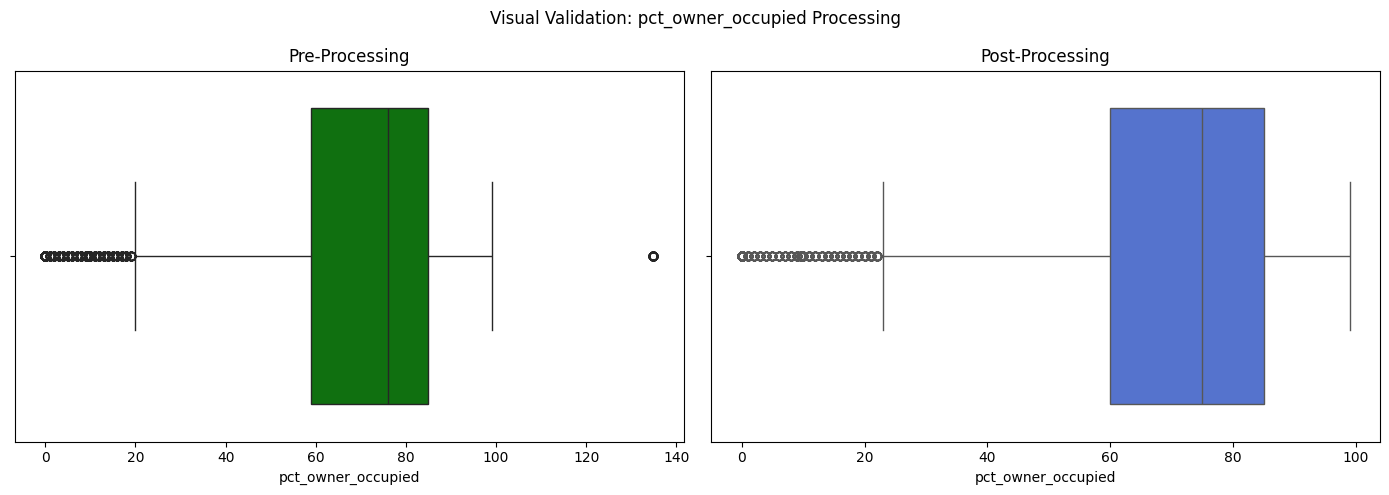

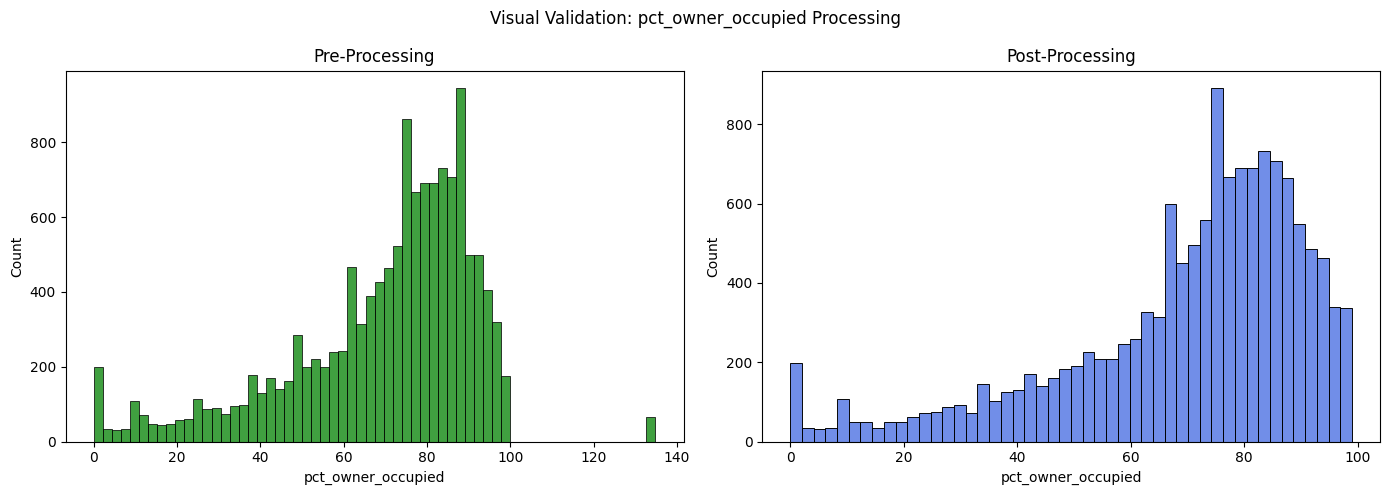

In [50]:
box_plot('pct_owner_occupied')
hist_plot('pct_owner_occupied')

`pct_attribute_1`, `pct_attribute_2`,`pct_attribute_3` and `pct_attribute_4`
- this feature must be > 0
- the null values were filled with the median preserving data integrity

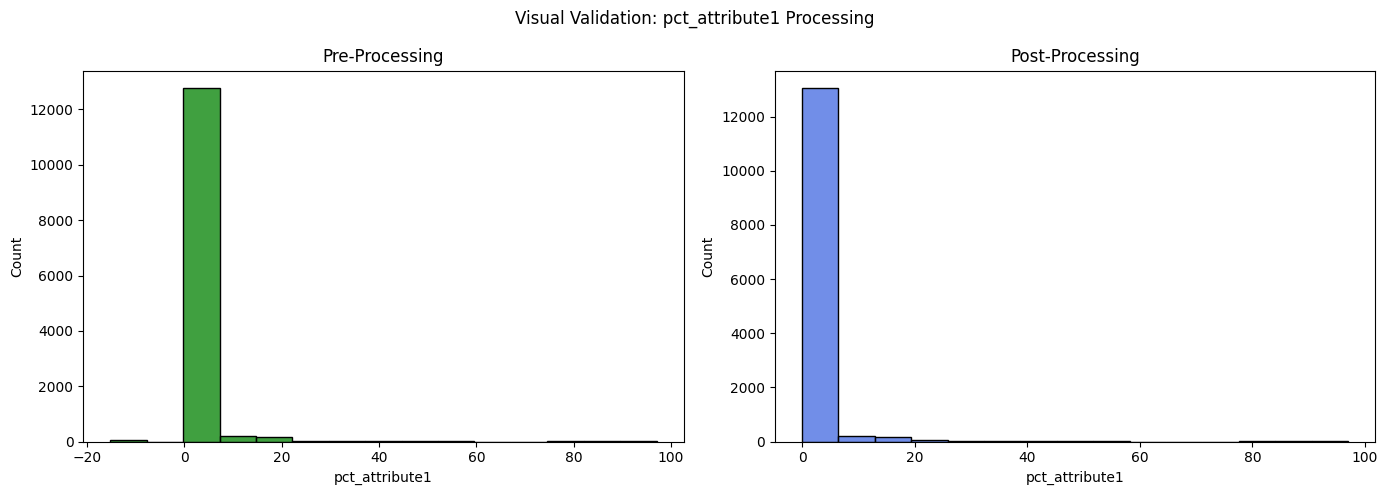

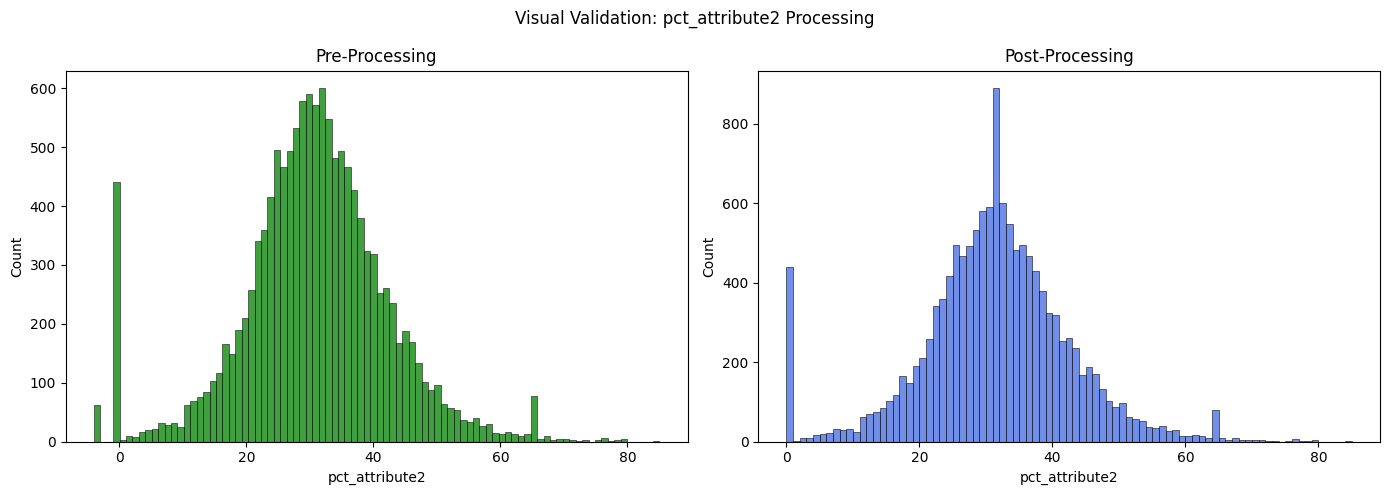

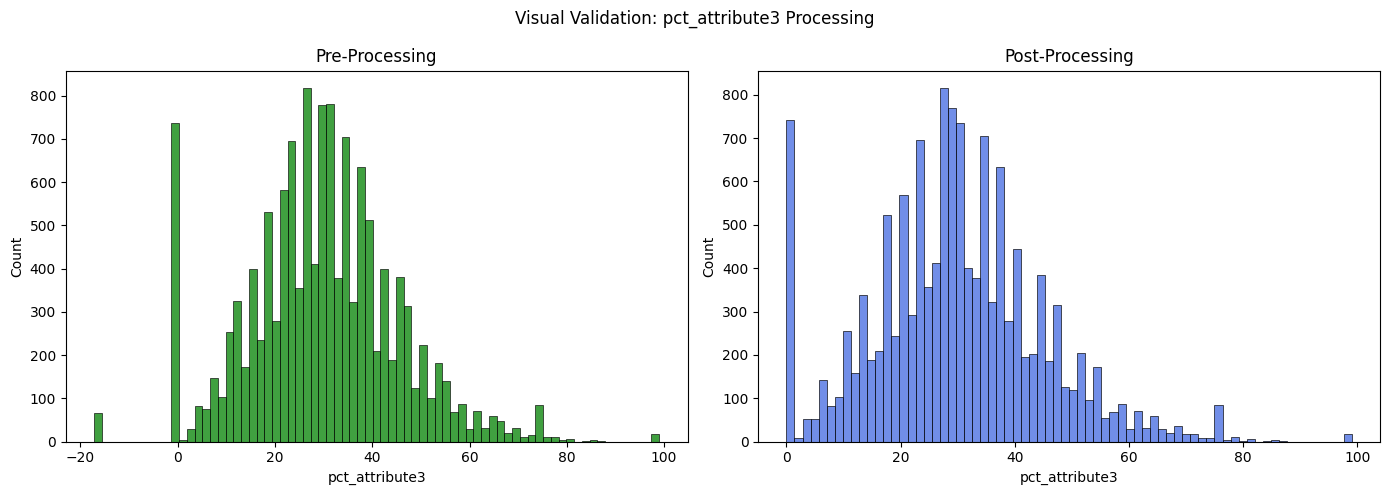

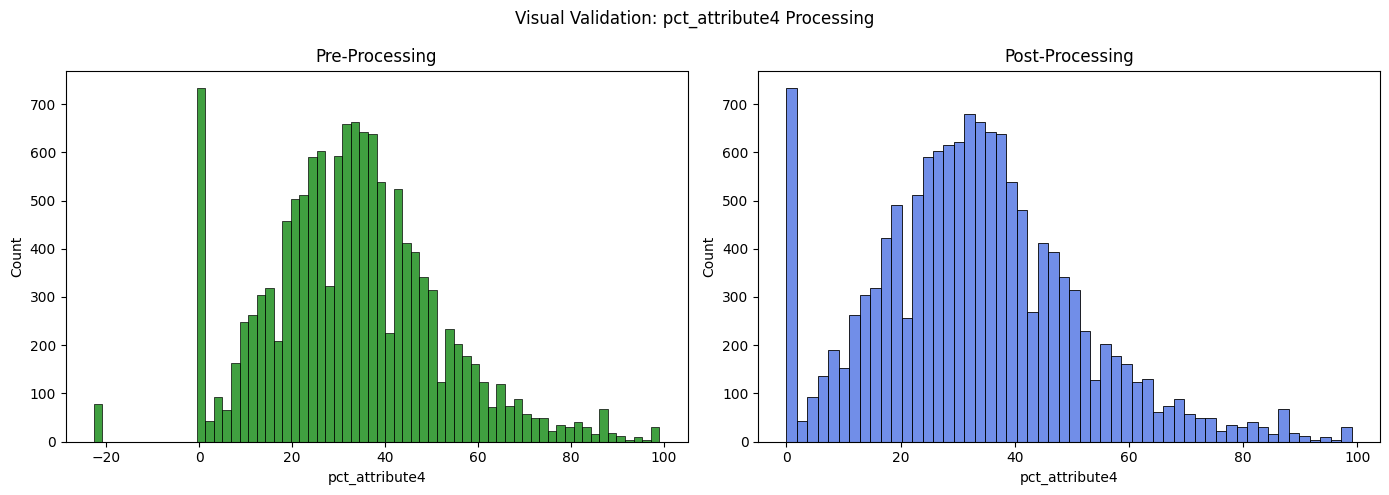

In [51]:
# Pct_attribute 1, 2, 3 and 4
pct_cols = ['pct_attribute1', 'pct_attribute2', 'pct_attribute3', 'pct_attribute4']
#df_copy[pct_cols].describe()
for col in pct_cols:
    df_copy.loc[df_copy[col] < 0, col] = np.nan
    df_copy[col] = df_copy[col].fillna(df_copy[col].median())
# Assure feature consistency
df_copy[pct_cols] = df_copy[pct_cols].round(2)
for col in pct_cols:
  hist_plot(col)

`urbanicity`
- the '?' values where replaced with actual nan values
- the null values were filled with the mode

In [52]:
# Urbanicity
# Correct inconsistencies by removing whitespaces and converting to string
df_copy['urbanicity'] = df_copy['urbanicity'].astype(str).str.strip()
df_copy['urbanicity'] = df_copy['urbanicity'].replace(['?','nan'], np.nan)
df_copy['urbanicity'] = df_copy['urbanicity'].fillna(df_copy['urbanicity'].mode()[0])

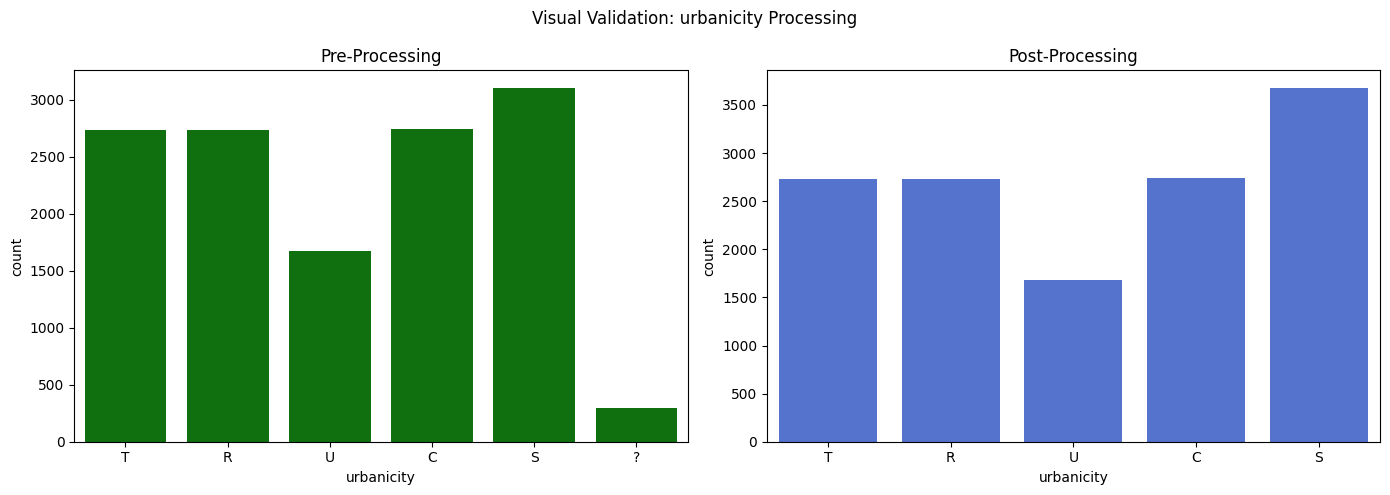

In [53]:
count_plot('urbanicity')

These count plots confirm that the processing did not disturb the natural distribution of the data for this feature.

`ses`
- null values were filled based on the donors urbanicity by selecting the mode of `ses` within each `urbanicity` group

In [54]:
# SES
# Correct inconsistencies by removing whitespaces and converting to string
df_copy['ses'] = df_copy['ses'].astype(str).str.strip().replace('?', np.nan)
df_copy['ses'] = pd.to_numeric(df_copy['ses'], errors='coerce')
df_copy['ses'] = df_copy['ses'].fillna(df_copy.groupby('urbanicity')['ses'].transform(lambda x: x.mode()[0] if not x.mode().empty else np.nan))
# Assure feature consistency
df_copy['ses'] = df_copy['ses'].astype(int)

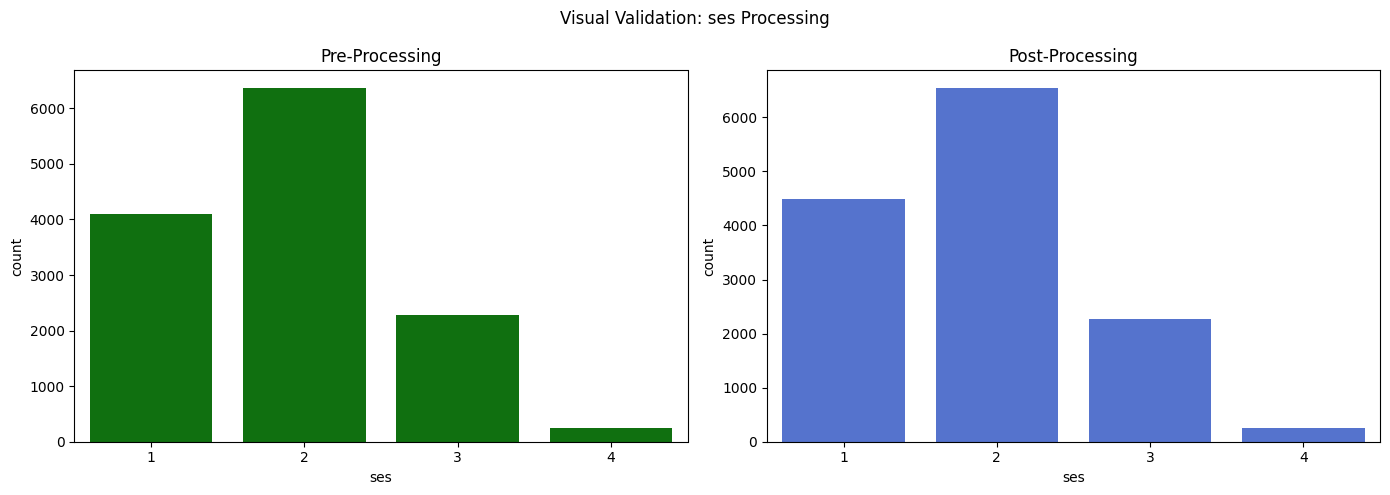

In [55]:
order_ses = [1,2,3,4]
count_plot('ses', order_name=order_ses)

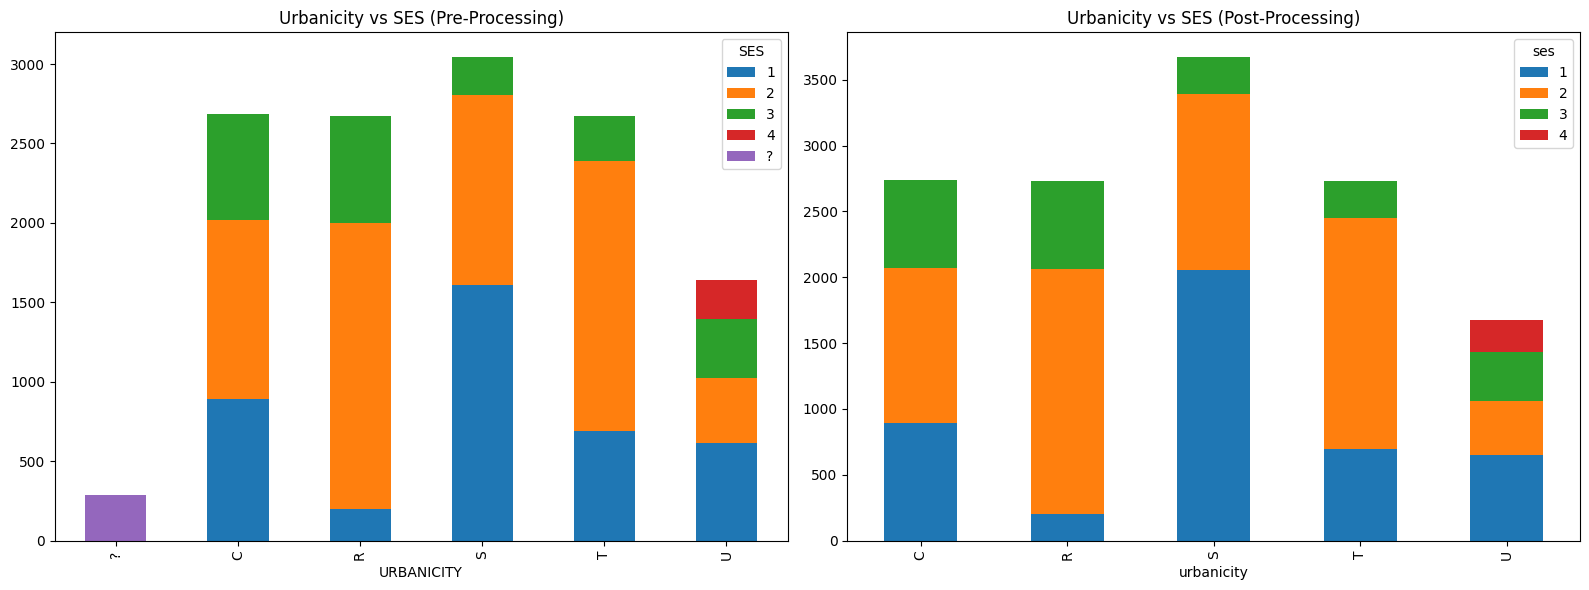

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
pd.crosstab(df['URBANICITY'], df['SES']).plot(kind='bar', stacked=True, ax=ax[0])
ax[0].set_title('Urbanicity vs SES (Pre-Processing)')
pd.crosstab(df_copy['urbanicity'], df_copy['ses']).plot(kind='bar', stacked=True, ax=ax[1])
ax[1].set_title('Urbanicity vs SES (Post-Processing)')
plt.tight_layout()
plt.show()

This stacked bar chart shows the distribution of SES categories across urbanicity groups before and after preprocessing. The post-processing chart shows a similar pattern, confirming the group based imputation preserved existing relationships. Through this plots we can observe that the socioeconomic status ('ses') is linked to where a donor lives.

`per_capita_income`
- this feature must be > 0
- null values were filled with the median preserving data integrity

In [57]:
# Per_capita_income
#df_copy['per_capita_income'].describe()
df_copy.loc[df_copy['per_capita_income'] < 0, 'per_capita_income'] = np.nan
df_copy['per_capita_income'] = df_copy['per_capita_income'].fillna(df_copy['per_capita_income'].median())
# Assure feature consistency
df_copy['per_capita_income'] = df_copy['per_capita_income'].round(0).astype(int)

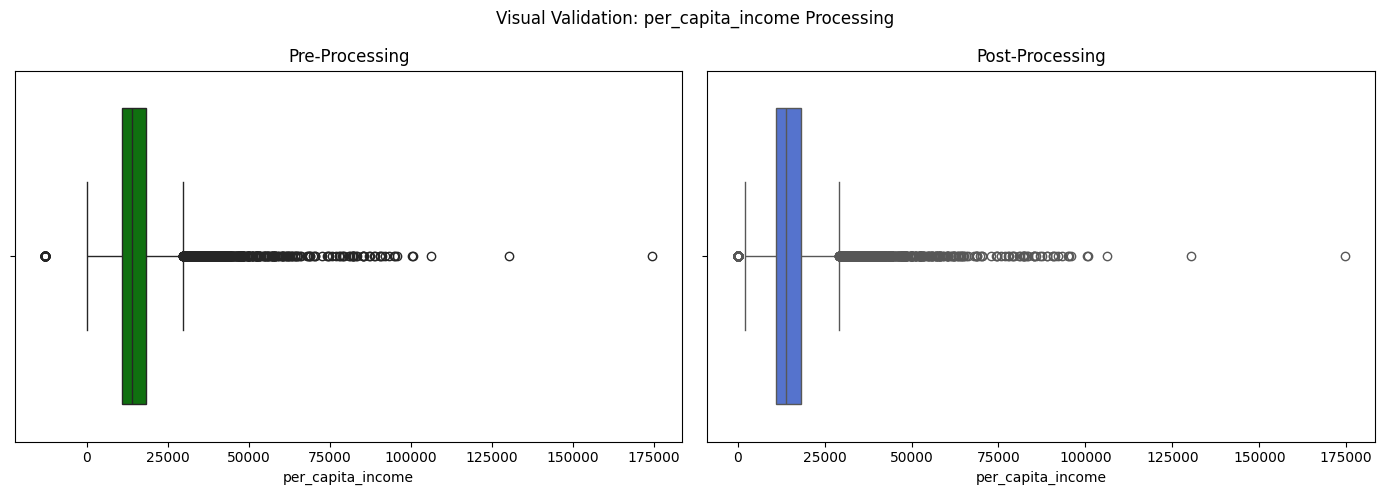

In [58]:
box_plot('per_capita_income')

By analyzing the boxplots we can see that `per_capita_income` has prominent outliers superior to 100000. So, to treat them we placed a cap on them.
After, we plot the histograms pre- and post-processing to evaluate the distribution of the data.

In [59]:
df_copy['per_capita_income'] = np.where(df_copy['per_capita_income'] > 100000, 100000, df_copy['per_capita_income'])

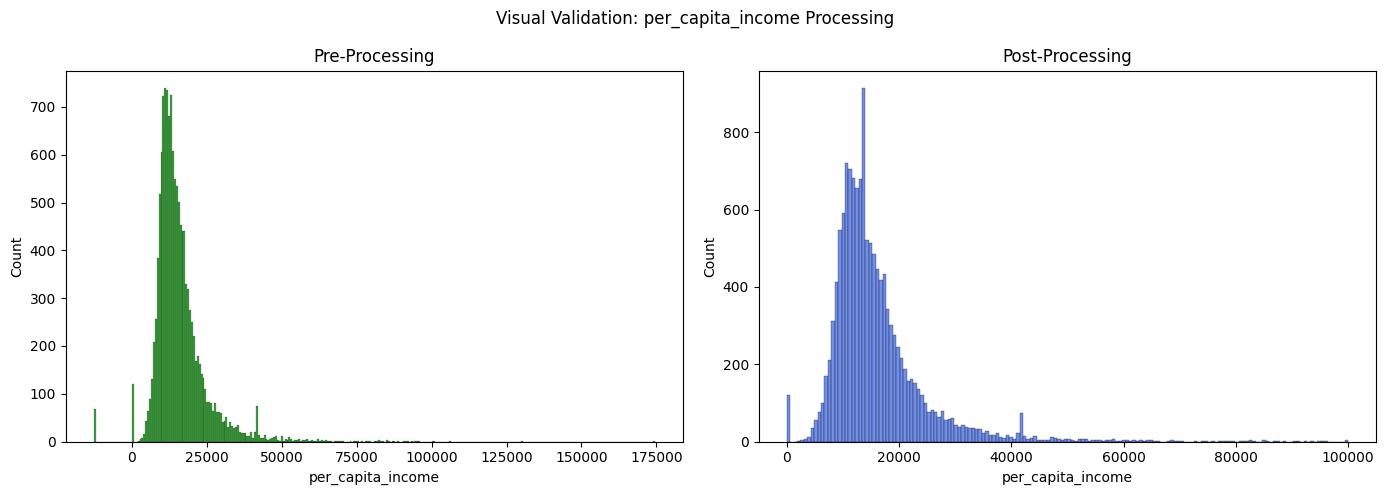

In [60]:
hist_plot('per_capita_income')

`income_group`
- this feature must be between 1 and 7
- null values were filled based on the donors urbanicity by selecting the mode of `ses` within each `urbanicity` group

In [61]:
# Income_group
# df_copy['income_group'].describe()
df_copy.loc[(df_copy['income_group'] <= 0) | (df_copy['income_group'] > 7), 'income_group'] = np.nan
df_copy['income_group'] = df_copy['income_group'].fillna(
    df_copy.groupby('urbanicity')['income_group'].transform(lambda x: x.mode()[0]))
# Assure feature consistency
df_copy['income_group'] = df_copy['income_group'].astype(int)

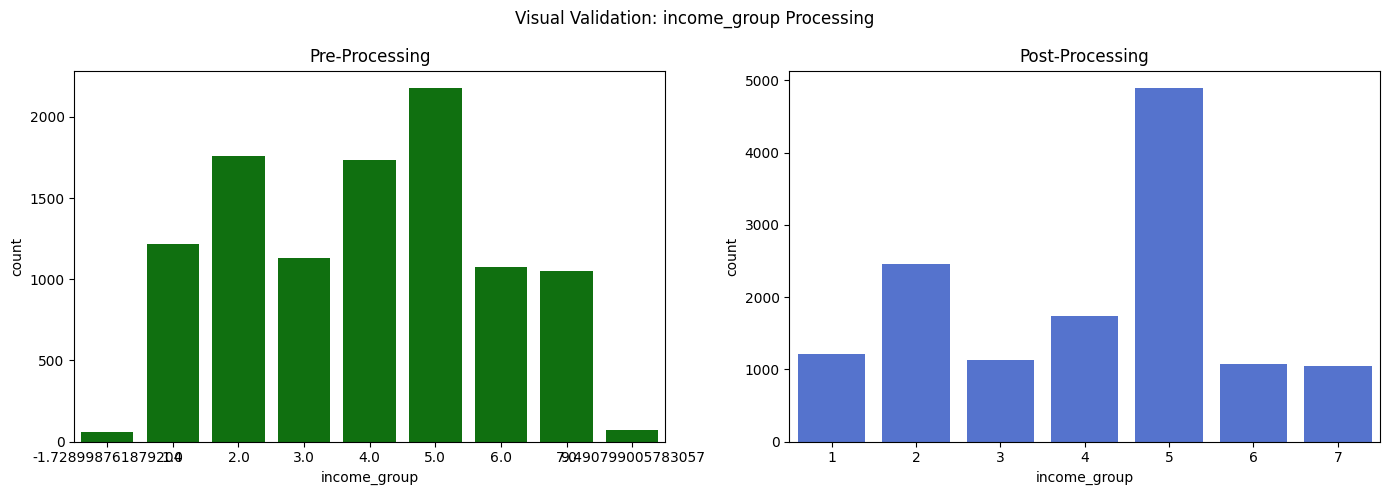

In [62]:
count_plot('income_group')

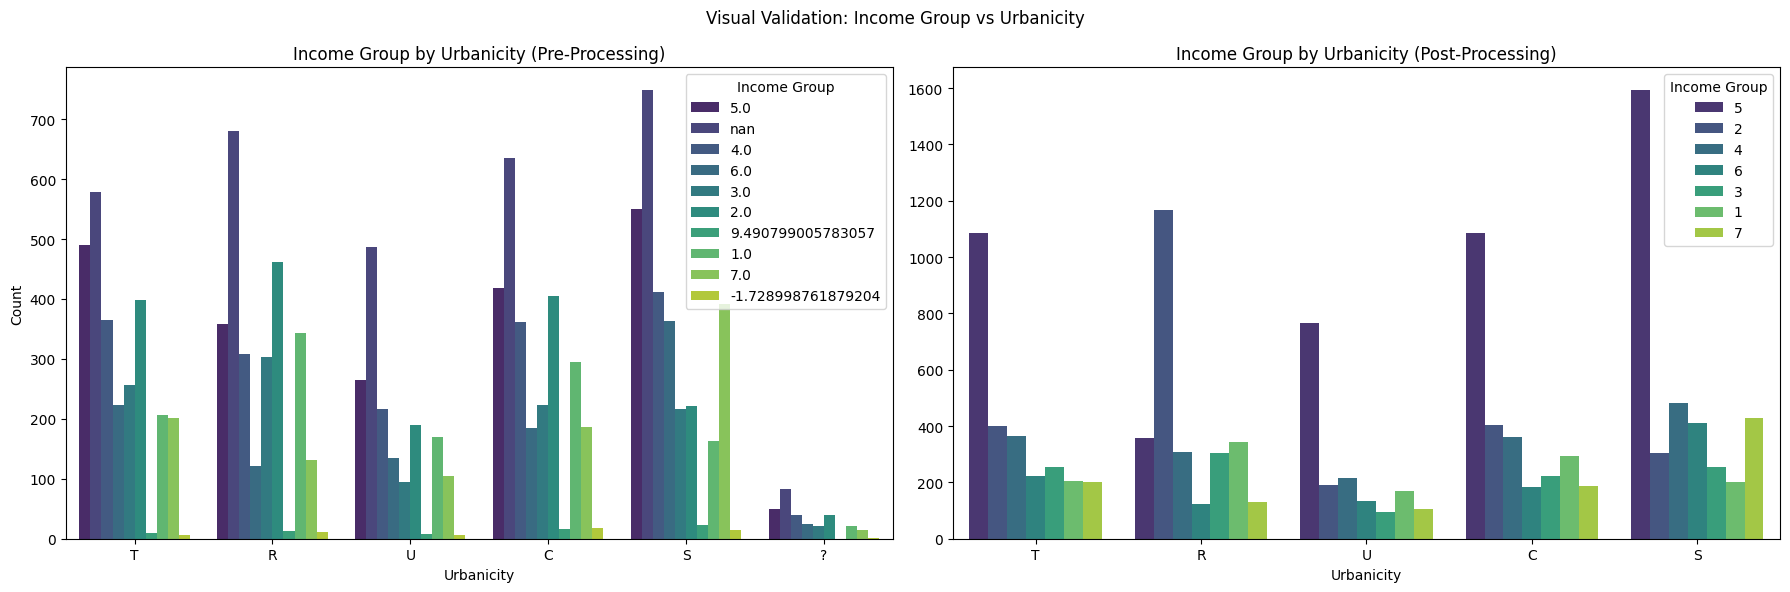

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.countplot(x='URBANICITY', hue=df['INCOME_GROUP'].astype(str), data=df, palette='viridis', ax=axes[0])
axes[0].set_title('Income Group by Urbanicity (Pre-Processing)')
axes[0].set_xlabel('Urbanicity')
axes[0].set_ylabel('Count')
axes[0].legend(title='Income Group')
sns.countplot(x='urbanicity', hue=df_copy['income_group'].astype(str), data=df_copy, palette='viridis', ax=axes[1])
axes[1].set_title('Income Group by Urbanicity (Post-Processing)')
axes[1].set_xlabel('Urbanicity')
axes[1].set_ylabel('')
axes[1].legend(title='Income Group')
plt.suptitle('Visual Validation: Income Group vs Urbanicity')
plt.tight_layout()
plt.show()

This side-by-side bar chart shows the distribution of Income group categories across Urbanicity groups before and after preprocessing. The post-processing chart shows a similar pattern, confirming the group based imputation preserved existing relationships.

`median_home_value`
- this feature must be > 0
- null values were filled based on the individuals urbanicity by selecting the median of `median_home_values` within each `urbanicity` group

In [64]:
# Median_home_value
# df_copy['median_home_value'].describe()
df_copy.loc[df_copy['median_home_value'] < 0, 'median_home_value'] = np.nan
df_copy['median_home_value'] = df_copy['median_home_value'].fillna(df_copy.groupby('urbanicity')['median_home_value'].transform('median'))
# Assure feature consistency
df_copy['median_home_value'] = df_copy['median_home_value'].round(0).astype(int)

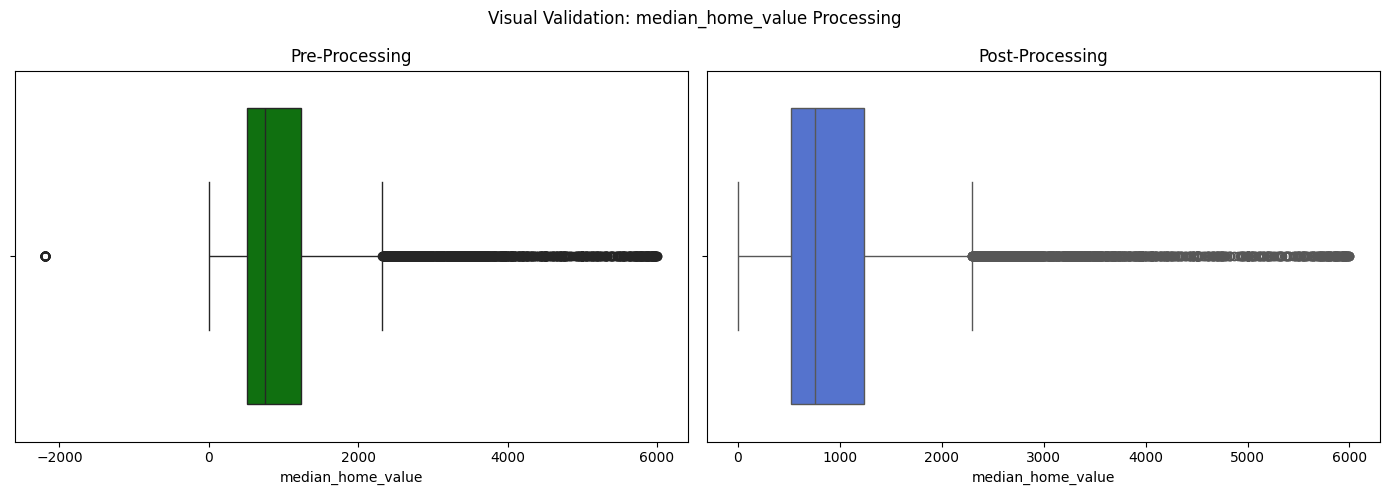

In [65]:
box_plot('median_home_value')

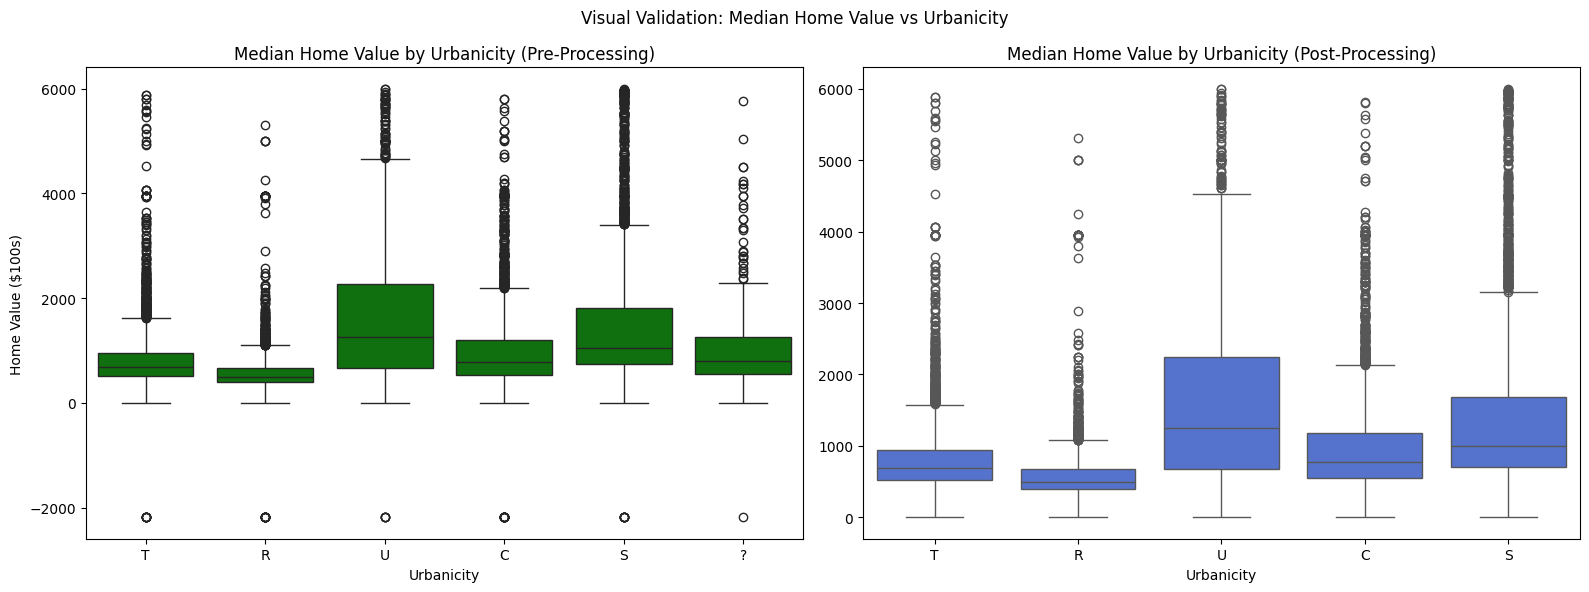

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(x='URBANICITY', y='MEDIAN_HOME_VALUE', data=df, ax=axes[0], color='green')
axes[0].set_title('Median Home Value by Urbanicity (Pre-Processing)')
axes[0].set_xlabel('Urbanicity')
axes[0].set_ylabel('Home Value ($100s)')
sns.boxplot(x='urbanicity', y='median_home_value', data=df_copy, ax=axes[1], color='royalblue')
axes[1].set_title('Median Home Value by Urbanicity (Post-Processing)')
axes[1].set_xlabel('Urbanicity')
axes[1].set_ylabel('')
plt.suptitle('Visual Validation: Median Home Value vs Urbanicity')
plt.tight_layout()
plt.show()

Through this boxplots we can verify that the processing respected the natural distribution of the data

`median_household_income`
- this feature must be > 0
- null values were filled based on the individuals socioeconomic status (`ses`) by selecting the median of `median_household_income` within each `ses` group

In [67]:
# Media_household_income
# df_copy['median_household_income'].describe()
df_copy.loc[df_copy['median_household_income'] < 0, 'median_household_income'] = np.nan
df_copy['median_household_income'] = df_copy['median_household_income'].fillna(df_copy.groupby('ses')['median_household_income'].transform('median'))
# Assure feature consistency
df_copy['median_household_income'] = df_copy['median_household_income'].round(0).astype(int)

In [68]:
df_copy['median_household_income'] = np.where(df_copy['median_household_income'] > df_copy['median_household_income'].quantile(0.99),
                                              df_copy['median_household_income'].quantile(0.99),
                                              df_copy['median_household_income'])

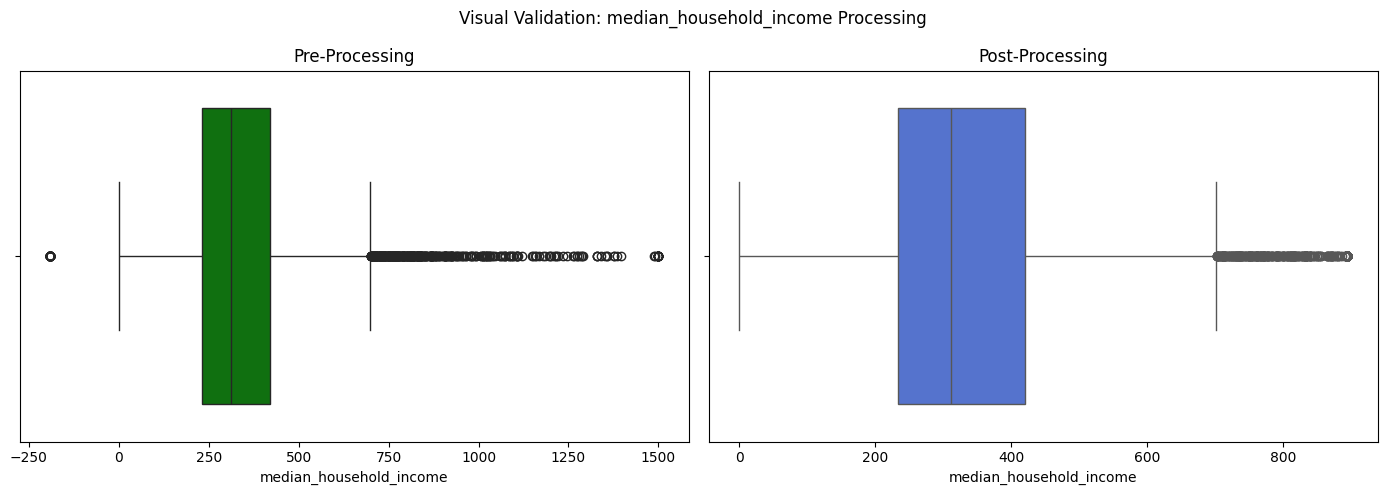

In [69]:
box_plot('median_household_income')

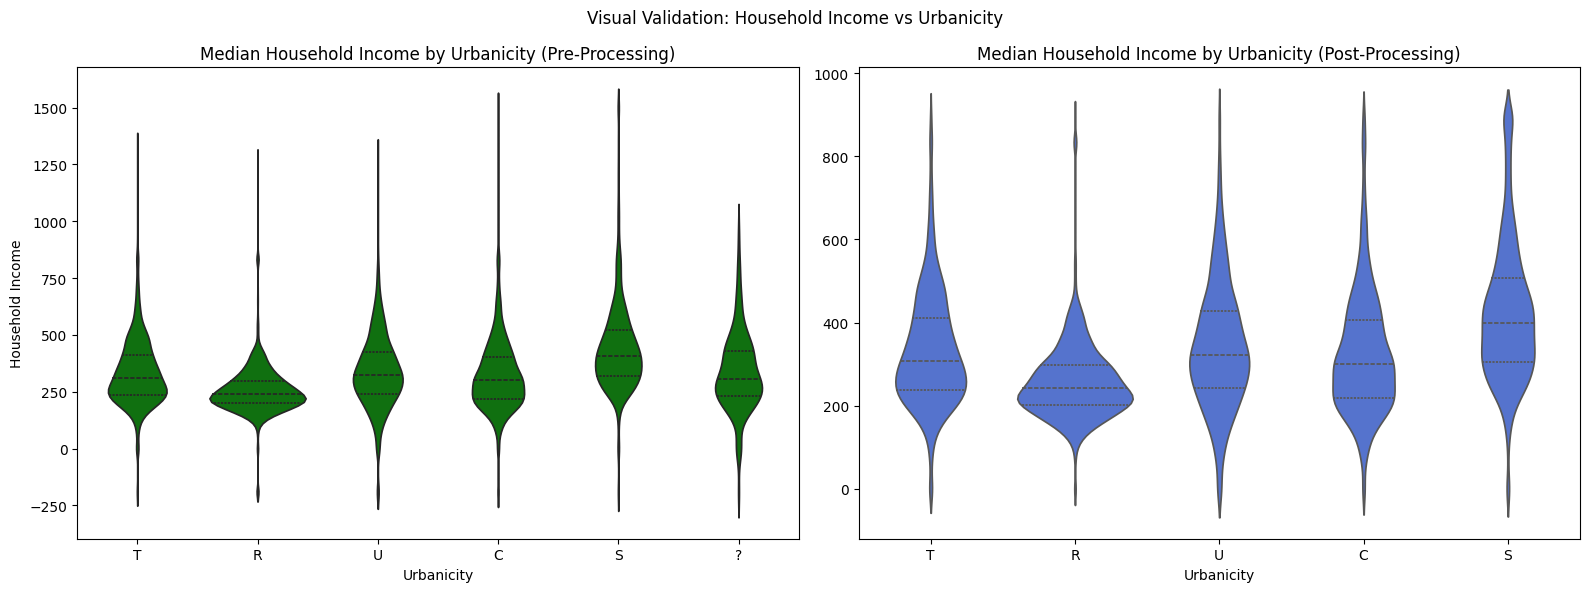

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.violinplot(x='URBANICITY', y='MEDIAN_HOUSEHOLD_INCOME', data=df, inner="quartile", ax=axes[0], color='green')
axes[0].set_title('Median Household Income by Urbanicity (Pre-Processing)')
axes[0].set_xlabel('Urbanicity')
axes[0].set_ylabel('Household Income')
sns.violinplot(x='urbanicity', y='median_household_income', data=df_copy, inner="quartile", ax=axes[1], color='royalblue')
axes[1].set_title('Median Household Income by Urbanicity (Post-Processing)')
axes[1].set_xlabel('Urbanicity')
axes[1].set_ylabel('')
plt.suptitle('Visual Validation: Household Income vs Urbanicity')
plt.tight_layout()
plt.show()

Through this plots we can verify that the processing respected the natural distribution of the data

/tmp/ipykernel_2808/3508736075.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


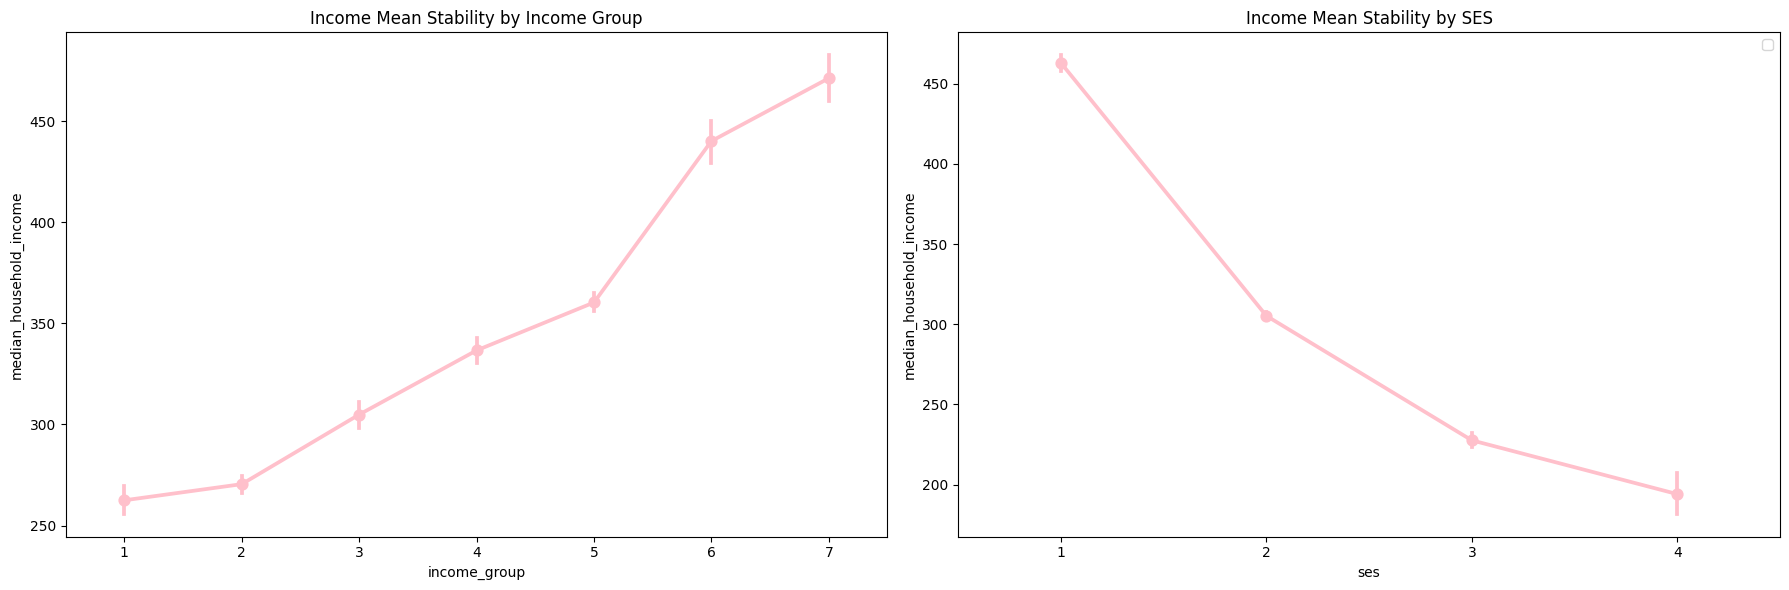

In [71]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.pointplot(x='income_group', y='median_household_income', data=df_copy, color='pink', ax=ax[0])
ax[0].set_title('Income Mean Stability by Income Group')
sns.pointplot(x='ses', y='median_household_income', data=df_copy, order=order_ses, color='pink', ax=ax[1])
ax[1].set_title('Income Mean Stability by SES')
ax[1].legend()
plt.tight_layout()
plt.show()

These plots validate the internal consistency of the economic variables. `median_household_income` should increase monotically with `income_group`and `ses`, if any deviations were identified they would suggest imputation errors.

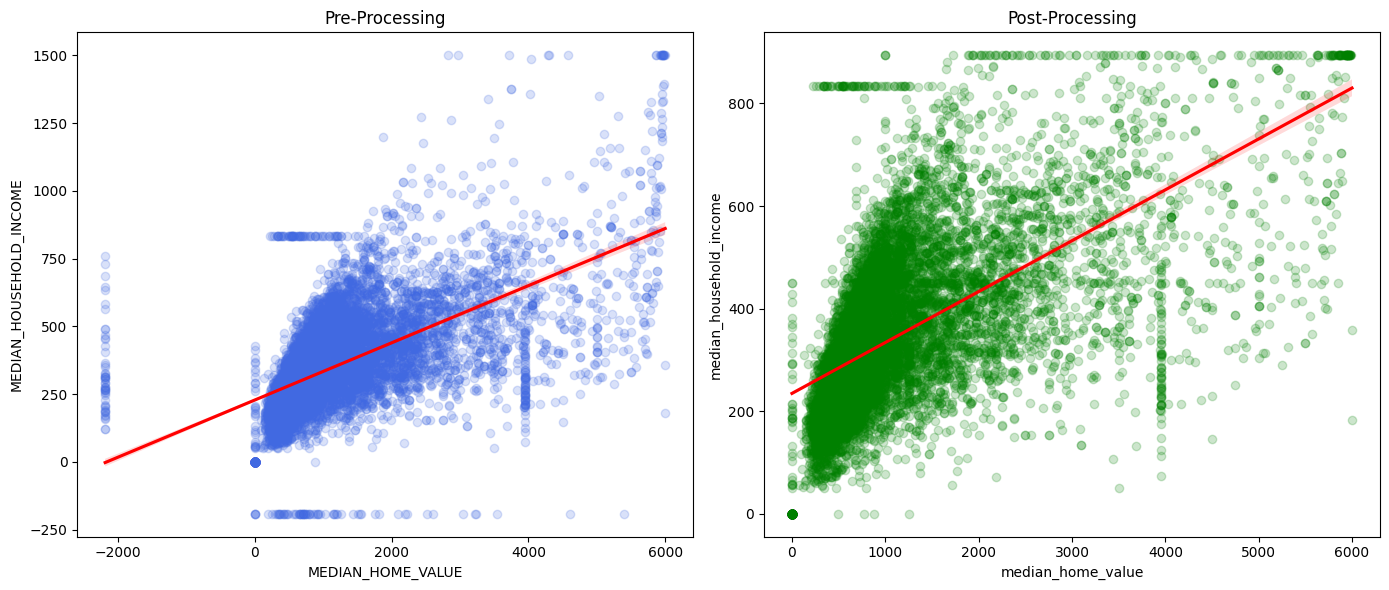

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.regplot(x='MEDIAN_HOME_VALUE', y='MEDIAN_HOUSEHOLD_INCOME', data=df, scatter_kws={'alpha': 0.2, 'color': 'royalblue'}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('Pre-Processing')
sns.regplot(x='median_home_value', y='median_household_income', data=df_copy, scatter_kws={'alpha': 0.2, 'color': 'green'}, line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title('Post-Processing')
plt.tight_layout()
plt.show()

Through this plots we can verify if the processing respected the natural distribution of the data.

`weatlh_rating`
- this feature must be >0
- when a variable has to many null values like this one, inputing them with the mean, median, or other methods, is going to introduce a big bias to it. In this case, we used knn to estimate values by considering the values of the closest data points of the features that are the most correlated

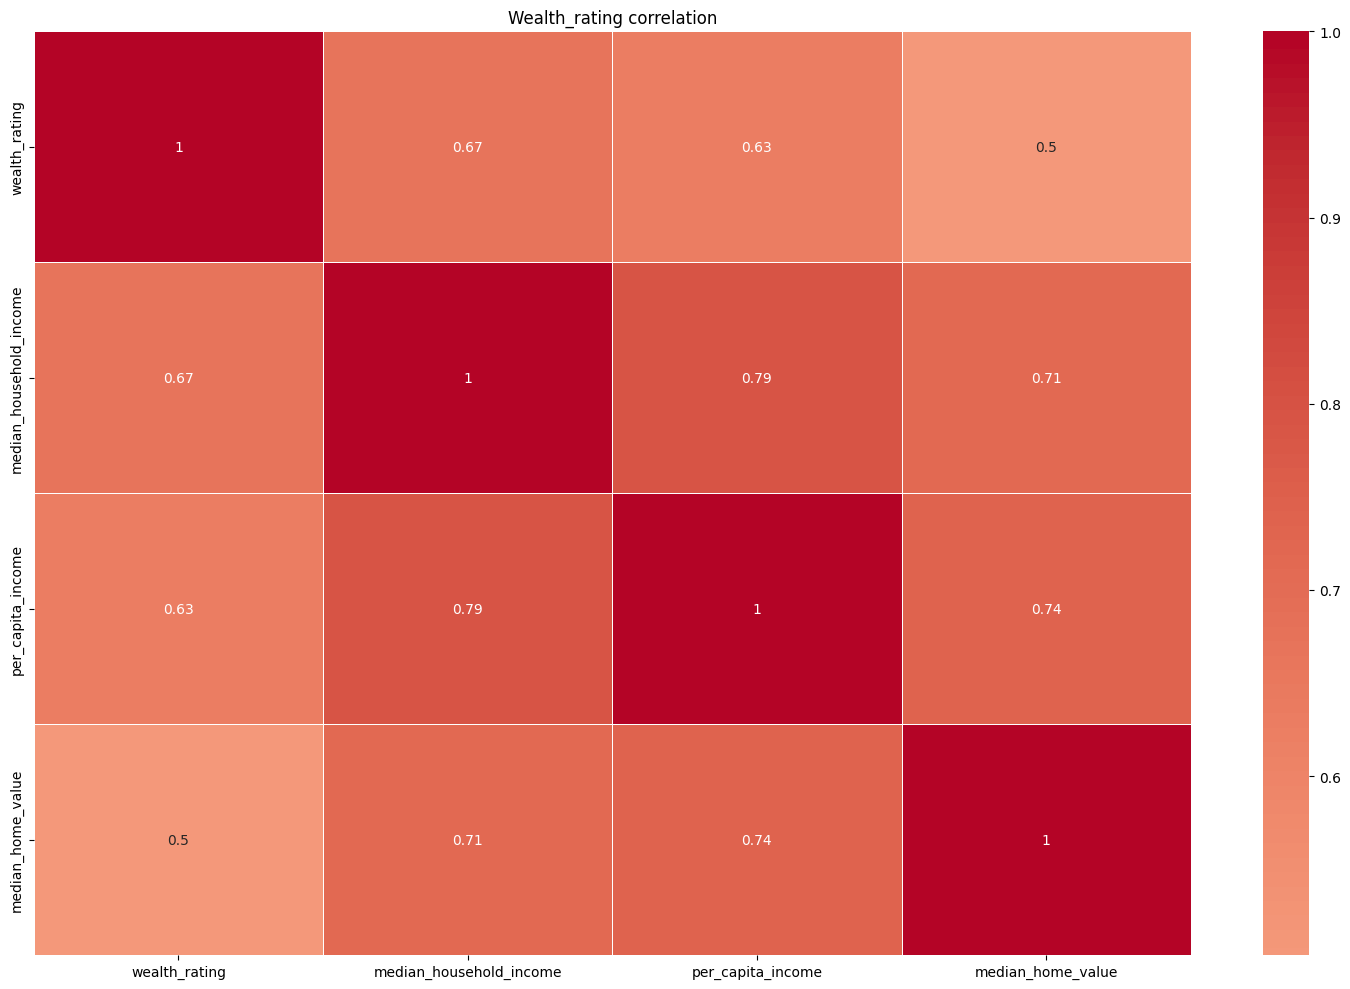

In [73]:
# Wealth Rating
df_copy.loc[(df_copy['wealth_rating']<0) | (df_copy['wealth_rating']>9), 'wealth_rating'] = np.nan
# print(df_copy['wealth_rating'].value_counts())
# print(df_copy['wealth_rating'].isnull().sum())
subset = ['wealth_rating','median_household_income', 'per_capita_income', 'median_home_value']
plot_corr_num(df_copy[subset], 'Wealth_rating correlation')
df_wealth = df_copy[subset]
imputer = KNNImputer(n_neighbors=3)
df_imputed = pd.DataFrame(imputer.fit_transform(df_wealth), columns=subset, index=df_copy.index)
df_copy['wealth_rating'] = df_imputed['wealth_rating'].round().clip(0,9).astype('Int64')
#print(df_copy['wealth_rating'].value_counts())
#print(df_copy['wealth_rating'].isnull().sum())

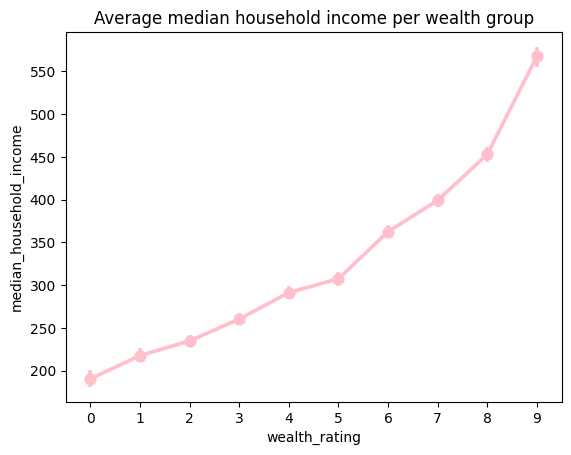

In [74]:
sns.pointplot(x='wealth_rating', y='median_household_income', data=df_copy, color='pink')
plt.title('Average median household income per wealth group')
plt.show()

Through this plot we can understand the order of this ordinal feature

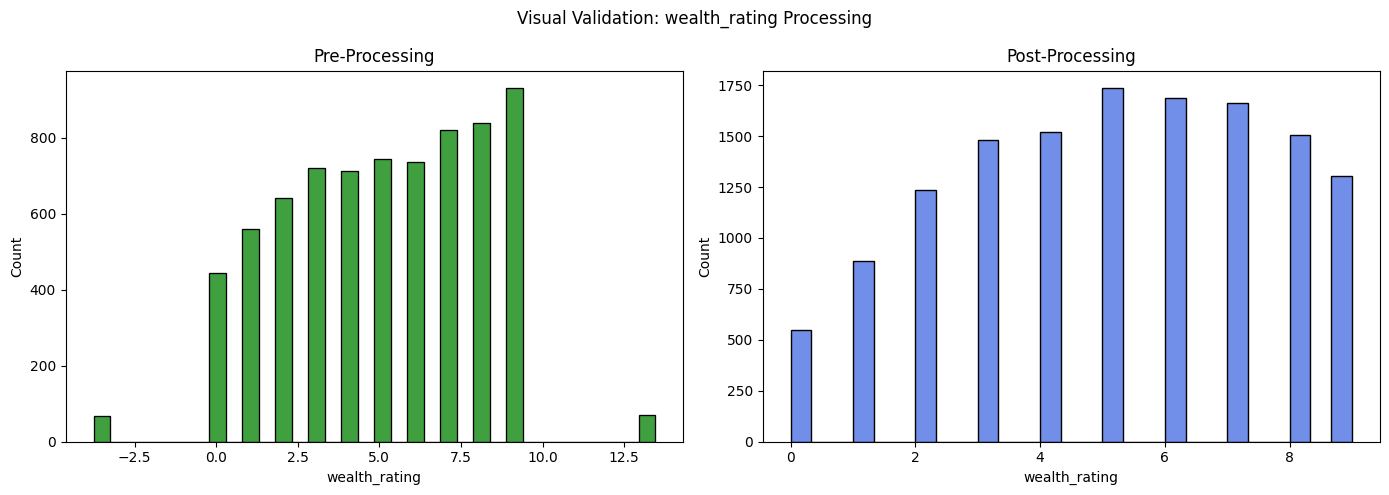

In [75]:
hist_plot('wealth_rating')

`donor_age`
- this feature must be >= 18
- Since being more than 100 years old is an outlier it was added a filter to transform these values into null values
- null values were filled with the median preserving data integrity

In [76]:
# Donor_age
# df_copy['donor_age'].isnull().sum()
# df_copy['donor_age'].describe()
df_copy.loc[(df_copy['donor_age'] < 18) | (df_copy['donor_age'] >100) , 'donor_age'] = np.nan
df_copy['donor_age'] = df_copy['donor_age'].fillna(df_copy['donor_age'].median())
# Assure feature consistency
df_copy['donor_age'] = df_copy['donor_age'].round(0).astype(int)

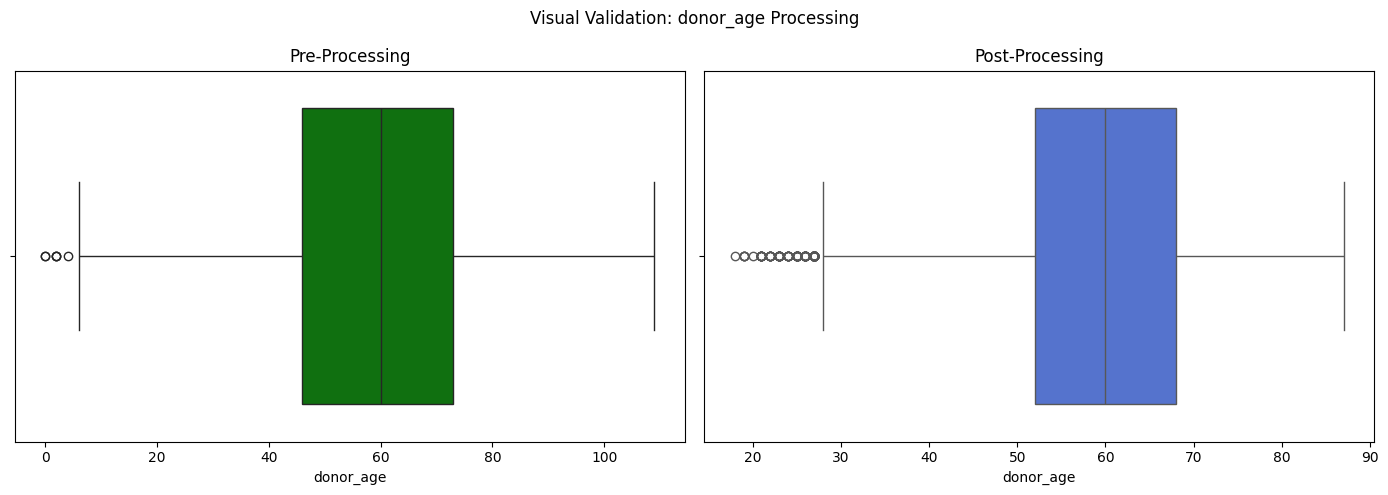

In [77]:
box_plot('donor_age')

`lifetime_gift_count` and `lifetime_gift_amount`
- both variables must be > 0
- To impute the nulls on these variables we took into consideration two rules:
          - If we have an amount described - count has to be at least 1
          - If we have a count then the amount must be the median for that count
- The rest of the nulls is where both count and amount are null so both go to 0
- Even though there are outliers they aren't necessarly wrong. To make sure they are considered but do not impact to much the algorithms we placed a cap in both count and amount

In [78]:
# lifetime_gift_count and lifetime_gift_amount
cols = ['lifetime_gift_count','lifetime_gift_amount']
df_copy[cols] = df_copy[cols].mask(df_copy[cols] < 0)
df_copy.loc[(df_copy['lifetime_gift_amount'] > 0) & (df_copy['lifetime_gift_count'].isnull()), 'lifetime_gift_count'] = 1

df_copy['lifetime_gift_amount'] = (df_copy.groupby('lifetime_gift_count')['lifetime_gift_amount'].transform(lambda x: x.fillna(x.median())))

df_copy['lifetime_gift_amount'].fillna(0, inplace=True)
df_copy['lifetime_gift_count'].fillna(0,inplace=True)
# print(df_copy['lifetime_gift_amount'].isnull().sum())
# print(df_copy['lifetime_gift_count'].isnull().sum())

df_copy.loc[df_copy['lifetime_gift_count']>70,'lifetime_gift_count'] = 70
df_copy.loc[df_copy['lifetime_gift_amount']>1250,'lifetime_gift_amount'] = 1250
#print(df_copy[((df_copy['lifetime_gift_amount']==0)&(df_copy['lifetime_gift_count']!=0))|((df_copy['lifetime_gift_amount']!=0)&(df_copy['lifetime_gift_count']==0))])

/tmp/ipykernel_2808/1486194360.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy['lifetime_gift_amount'].fillna(0, inplace=True)
/tmp/ipykernel_2808/1486194360.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)

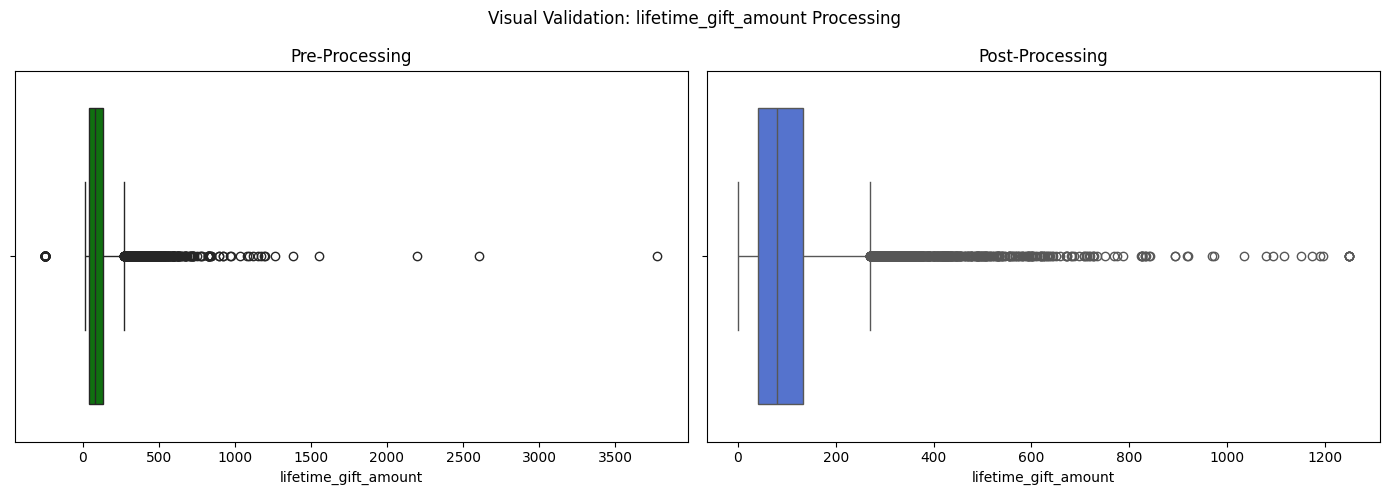

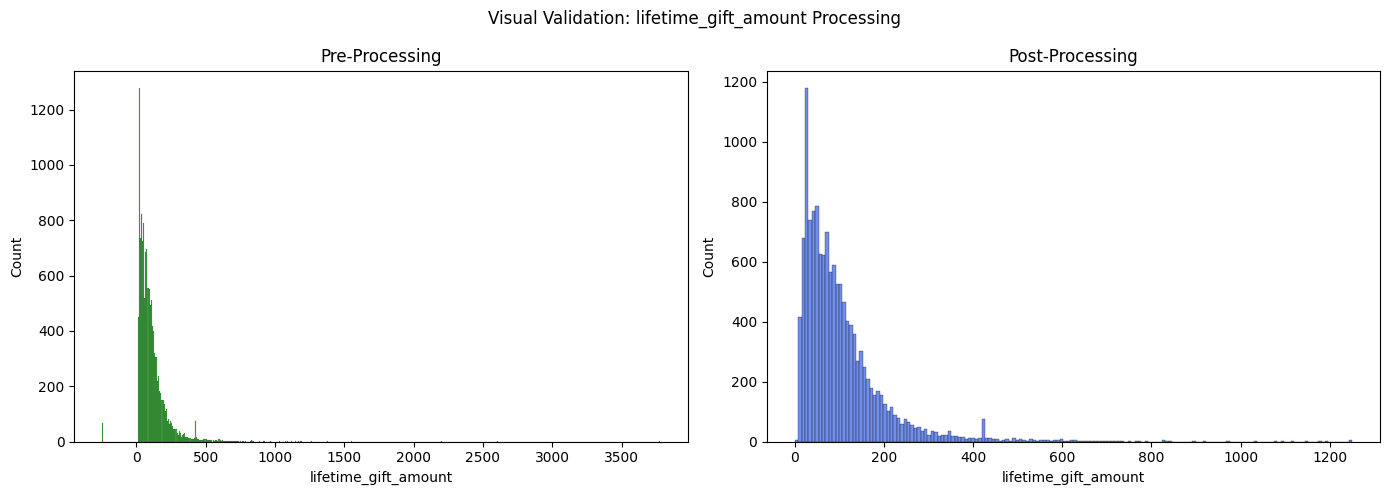

In [79]:
box_plot('lifetime_gift_amount')
hist_plot('lifetime_gift_amount')

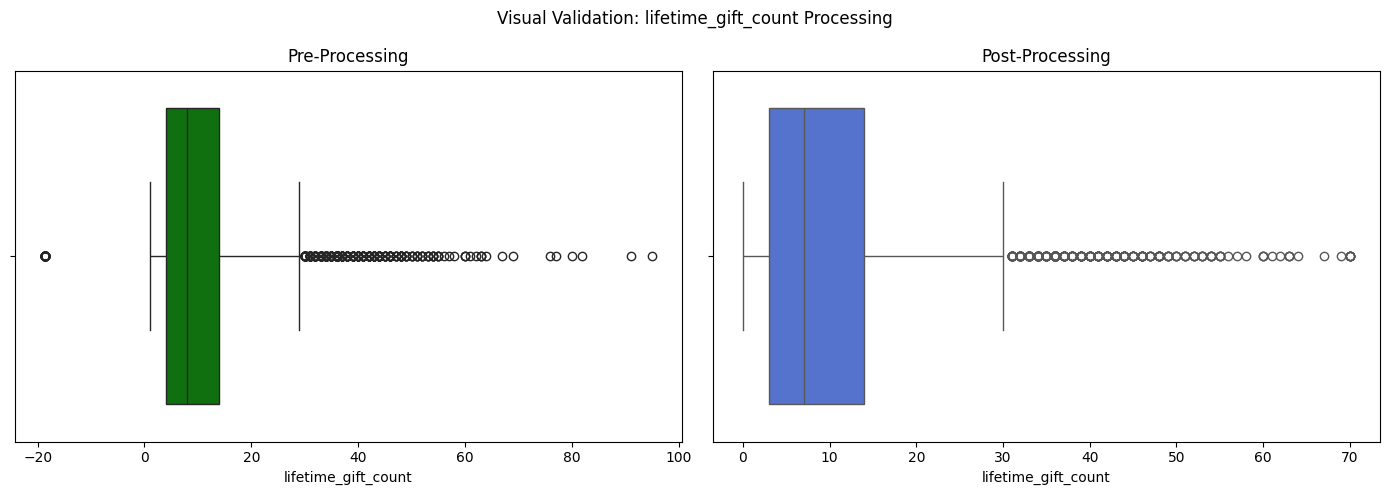

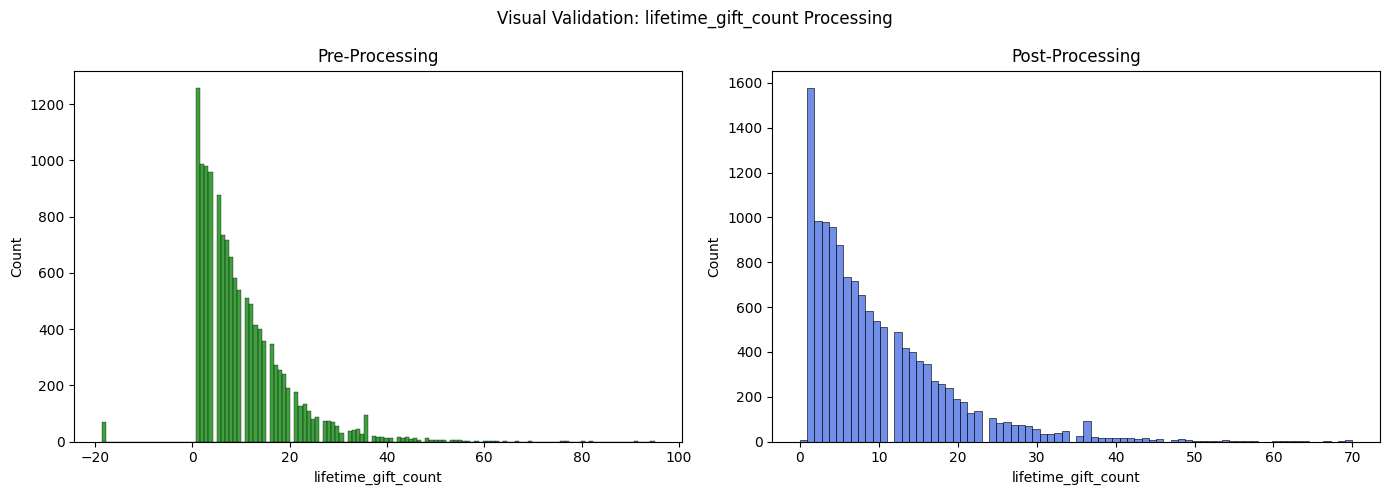

In [80]:
box_plot('lifetime_gift_count')
hist_plot('lifetime_gift_count')

<Axes: xlabel='lifetime_gift_amount', ylabel='lifetime_gift_count'>

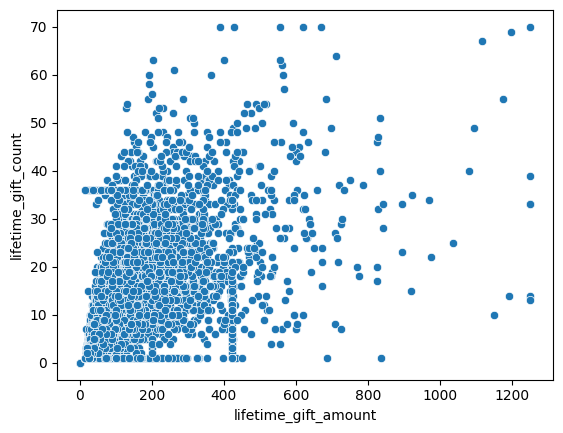

In [81]:
sns.scatterplot(x = 'lifetime_gift_amount', y = 'lifetime_gift_count', data = df_copy)
# This graph it is only used to make sure that any count/amount that is 0 it is met with the same amount/count from the other value

`lifetime_min_gift_amt`, `lifetime_max_gift_amt`, `recent_avg_git_amt` and `last_gift_amt`
- these features must be > 0
- To impute the nulls, we had into consideration the transformations made in the other 2 variables before these.
  - If we have an inactive donor, both count and amount are 0; all the other columns should follow this exception and have values substituted with 0
  - If we have a fairly new donor - count=1 (only 1 donation was made); all the other columns should have the same value as lifetime_gift_amount
- For the values that were not treated in the previous conditions, we filled them with the median of each column when the donor is active (count>0)
- Then we make sure that the max amount is greater or equal to the max(`lifetime_min_gift_amt`,`recent_avg_gift_amt`, `last_gift_amt`) and that the min amount is less or equal to the min(`lifetime_max_gift_amt`, `recent_avg_gift_amt`, `last_gift_amt`)

In [82]:
# lifetime_min_gift_amt, lifetime_max_gift_amt, Recent_avg_git_amt and Last_gift_amt
cols = ['lifetime_min_gift_amt','lifetime_max_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']
df_copy[cols] = df_copy[cols].mask(df_copy[cols]<0)

df_copy.loc[df_copy['lifetime_gift_count'] == 0, cols] = 0

df_copy.loc[df_copy['lifetime_gift_count'] == 1, cols] = df_copy.loc[df_copy['lifetime_gift_count'] == 1, 'lifetime_gift_amount']

median_value = df_copy.loc[df_copy['lifetime_gift_count'] > 0, cols].median()
df_copy[cols] = df_copy[cols].fillna(median_value)

maximum_vals = df_copy[['lifetime_min_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']].max(axis=1)
df_copy['lifetime_max_gift_amt'] = np.maximum(df_copy['lifetime_max_gift_amt'], maximum_vals)

minimum_vals = df_copy[['lifetime_max_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']].min(axis=1)
df_copy['lifetime_min_gift_amt'] = np.minimum(df_copy['lifetime_min_gift_amt'], minimum_vals)

In [83]:
# for col in cols:
#   print(df_copy[col].describe())
#   print(df_copy[col].isnull().sum())

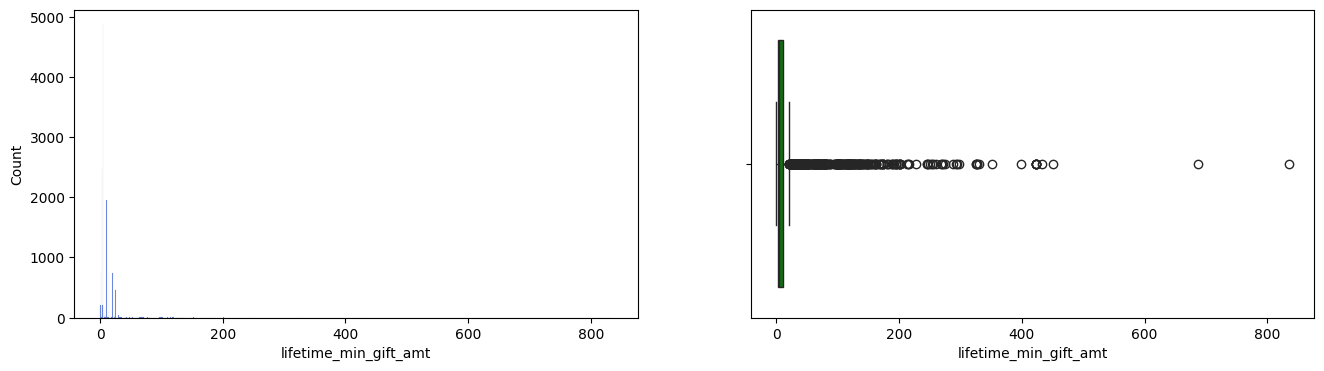

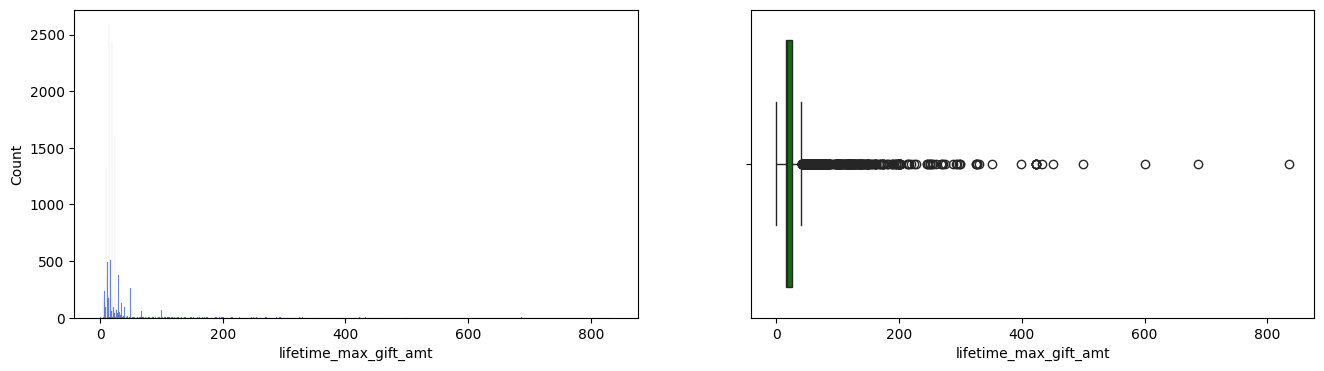

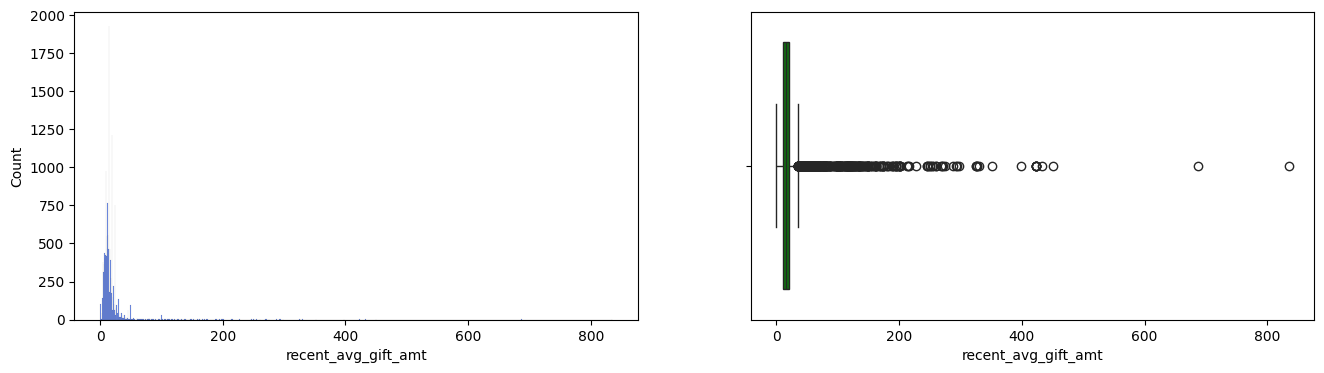

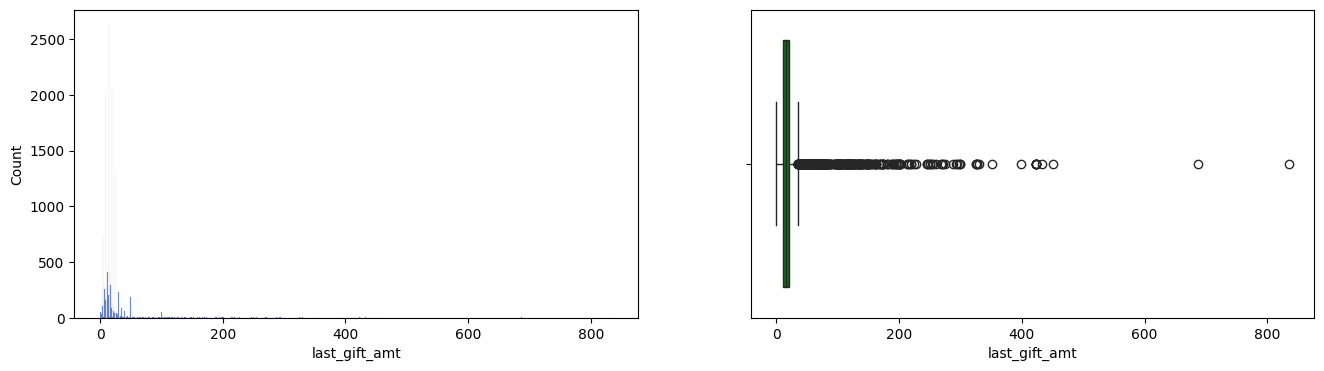

In [84]:
for col in cols:
  boxplot_hist(df_copy,col)

The boxplots for this 4 features are very similiar. We only need one line for all of them. Their information is very valiable but because they have really big outliers they must be capped at 380

In [85]:
df_copy[cols] = df_copy[cols].clip(upper=300)

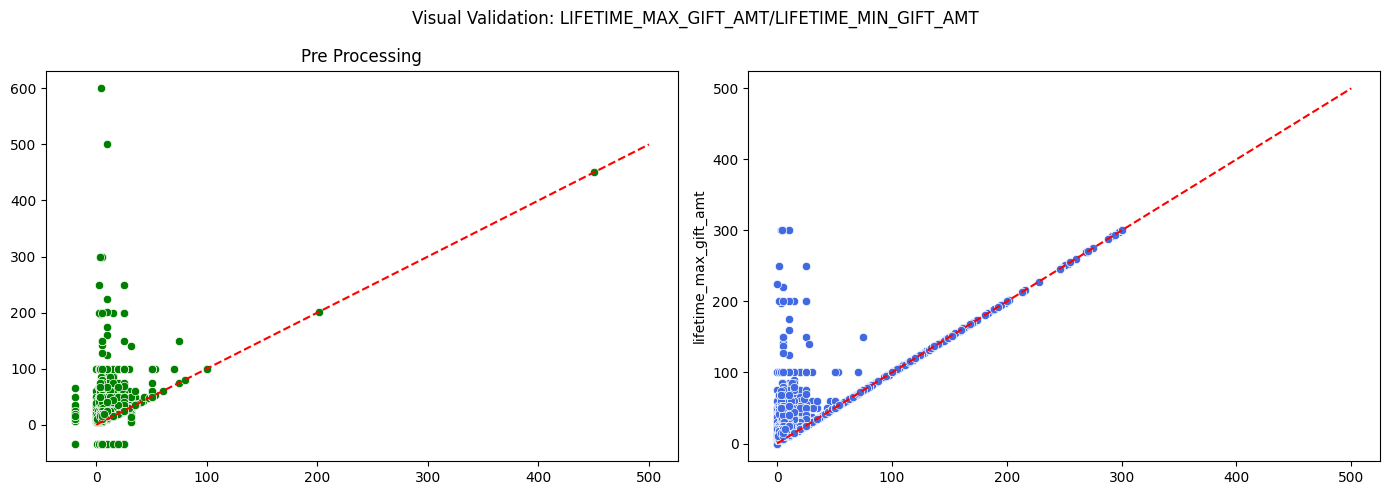

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(y=df['LIFETIME_MAX_GIFT_AMT'], x=df['LIFETIME_MIN_GIFT_AMT'], ax=axes[0], color='green')
axes[0].plot([0, 500], [0, 500], linestyle='--', color='red')
axes[0].set_title("Pre Processing")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
sns.scatterplot(y=df_copy['lifetime_max_gift_amt'], x=df_copy['lifetime_min_gift_amt'], ax=axes[1], color='royalblue')
axes[1].plot([0, 500], [0, 500], linestyle='--', color='red')
axes[1].set_title("")
axes[1].set_xlabel("")
plt.suptitle("Visual Validation: LIFETIME_MAX_GIFT_AMT/LIFETIME_MIN_GIFT_AMT")
plt.tight_layout()
plt.show()

This scatter plot confirm that `lifetime_max_gift_amt` is always greater than or equal to `lifetime_min_gift_amt`. Points bellow above the diagonal line would indicate inconsistencies.

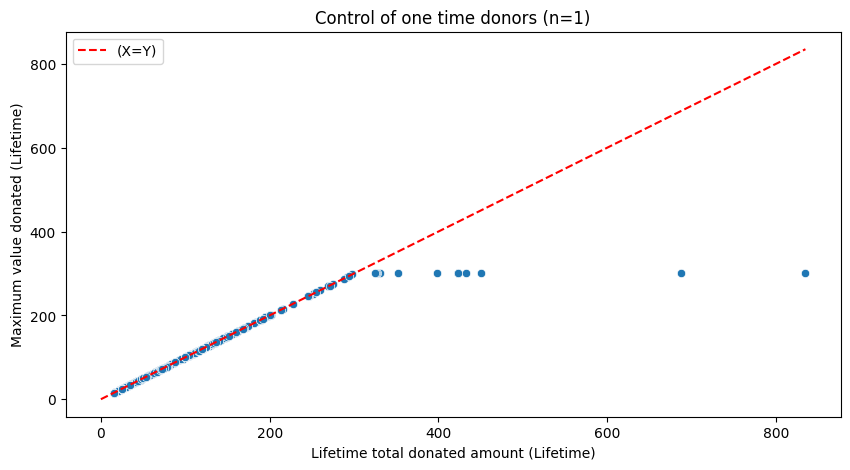

In [87]:
# lifetime_gift_count and lifetime_gift_amount
# Filtering for donors with only one donation made
df_1d = df_copy[df_copy['lifetime_gift_count'] == 1]
plt.figure(figsize=(10, 5))
sns.scatterplot(x='lifetime_gift_amount', y='lifetime_max_gift_amt', data=df_1d)
max_val = df_1d['lifetime_gift_amount'].max()
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='(X=Y)')
plt.title('Control of one time donors (n=1)')
plt.xlabel('Lifetime total donated amount (Lifetime)')
plt.ylabel('Maximum value donated (Lifetime)')
plt.legend()
plt.show()

This chart is used to check for any one time donor wich the max amount and lifetime amount do not match

In [88]:
df_copy['lifetime_gift_amount'] = df_copy['lifetime_gift_amount'].clip(upper=800)

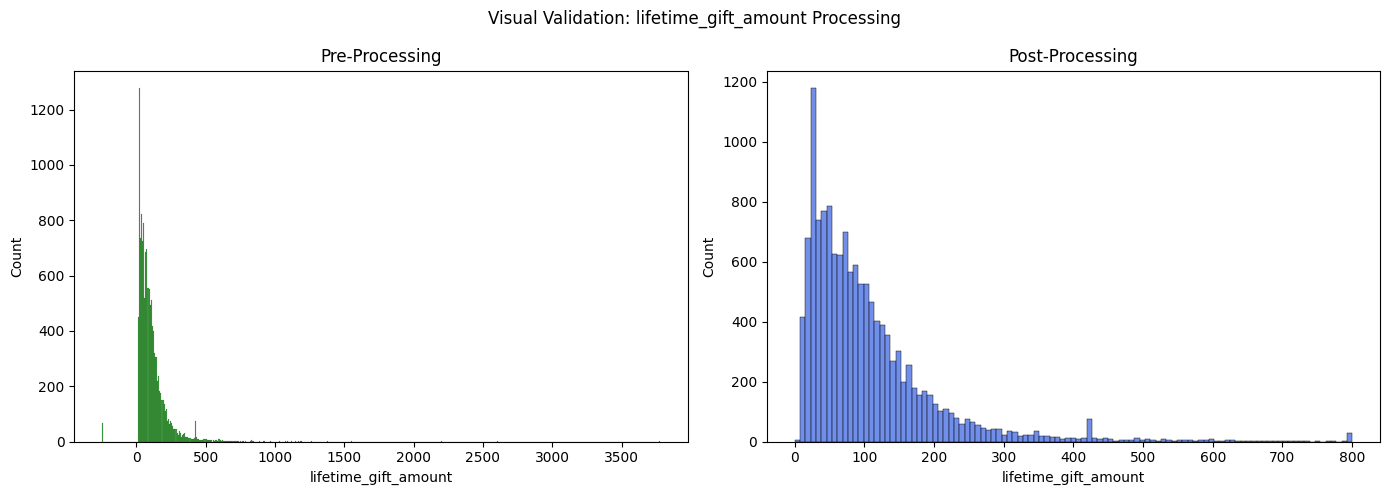

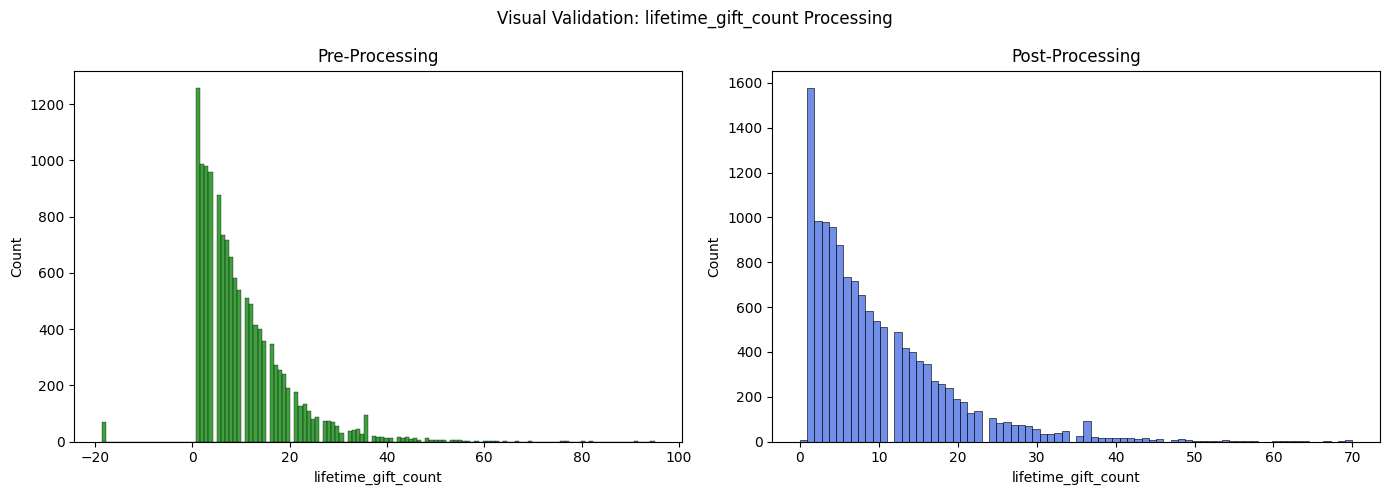

In [89]:
hist_plot('lifetime_gift_amount')
hist_plot('lifetime_gift_count')

`Recent_avg_card_gift_amt`
- this feature must be >0
- null values were filled by calculating a ratio for the avg donation made in response to a card. The null values are filled taking into consideration that ratio
- Then, we still have to guarantee that when we do not have an active donor (count=0) that the corresponding value is 0
- Finally we cap outliers that are above 100

In [90]:
# Recent_avg_card_gift_amt
#print(df_copy['recent_avg_card_gift_amt'].isnull().sum())
df_copy.loc[df_copy['recent_avg_card_gift_amt'] < 0, 'recent_avg_card_gift_amt'] = np.nan

mask = (df_copy['recent_avg_gift_amt'].notna() & df_copy['recent_avg_gift_amt']>0)
ratio_card = (df_copy.loc[mask, 'recent_avg_card_gift_amt'] / df_copy.loc[mask,'recent_avg_gift_amt']).mean()

df_copy['recent_avg_card_gift_amt'] = df_copy['recent_avg_card_gift_amt'].fillna(df_copy['recent_avg_gift_amt'] * ratio_card)
df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'recent_avg_card_gift_amt'] = 0
#print(df_copy['recent_avg_card_gift_amt'].isnull().sum())
df_copy['recent_avg_card_gift_amt'] = df_copy['recent_avg_card_gift_amt'].clip(upper=90)

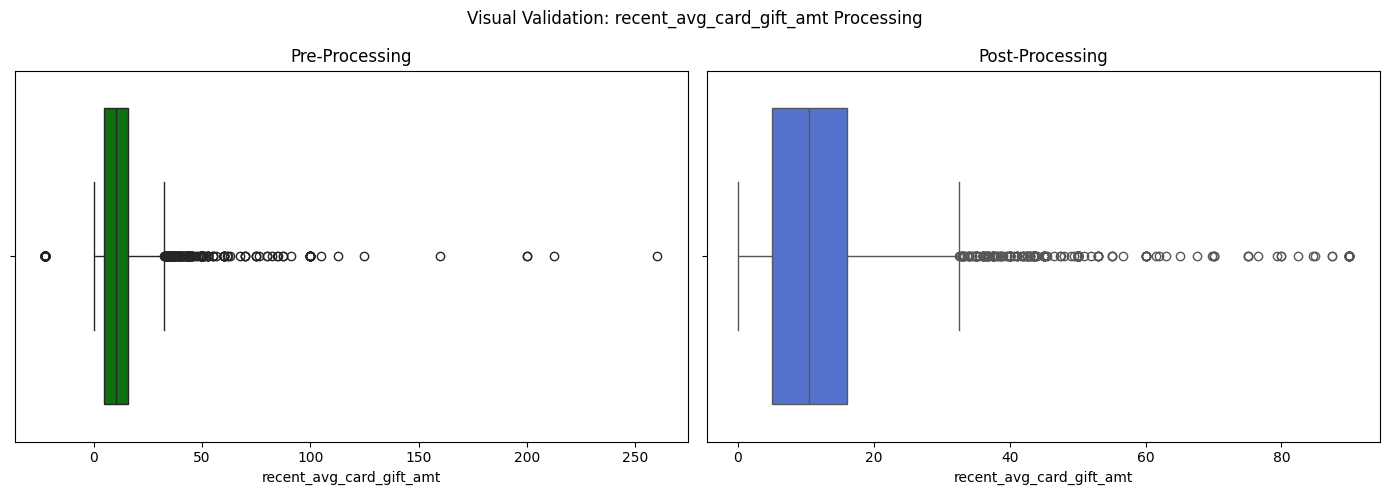

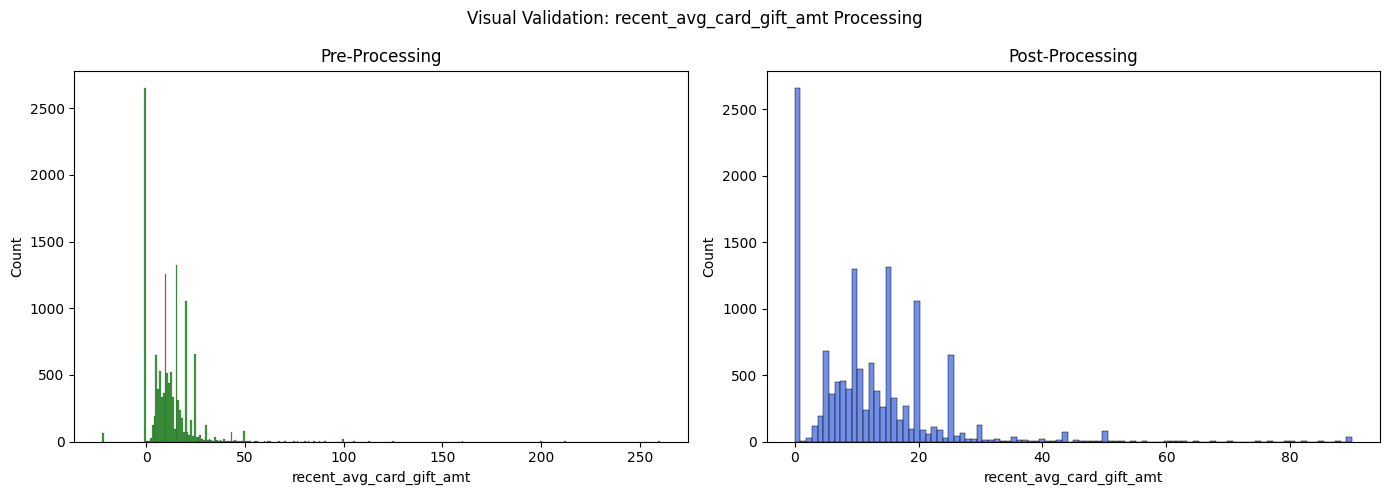

In [91]:
box_plot('recent_avg_card_gift_amt')
hist_plot('recent_avg_card_gift_amt')

`file_card_gift`
- this feature must be > 0
- to treat the null values a ratio for the lifetime avg donation amount made in response to all cards was calculated and the null values were filled taking into consideration this ratio
- Then, we still have to guarantee that when we do not have an active donor (count=0) that the corresponding value is 0
- Finally we cap outliers that are above 30

In [92]:
# file_card_gift
#print(df_copy['file_card_gift'].isnull().sum())
df_copy.loc[df_copy['file_card_gift'] < 0, 'file_card_gift'] = np.nan

mask = (df_copy['lifetime_gift_amount'].notna() & df_copy['lifetime_gift_amount']>0)
ratio_amt = (df_copy.loc[mask,'file_card_gift'] / df_copy.loc[mask,'lifetime_gift_amount']).mean()

df_copy['file_card_gift'] = df_copy['file_card_gift'].fillna(df_copy['lifetime_gift_amount'] * ratio_amt)

df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'file_card_gift'] = 0
#print(df_copy['file_card_gift'].isnull().sum())

df_copy['file_card_gift'] = df_copy['file_card_gift'].clip(upper=30)

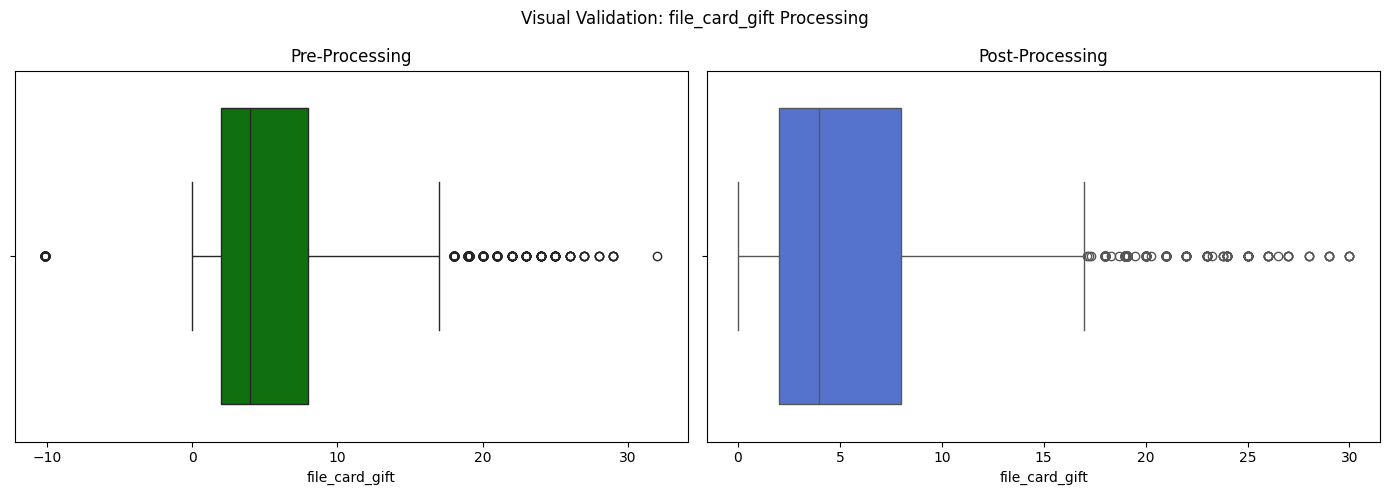

In [93]:
box_plot('file_card_gift')

`recency_status_96nk`
* For this feature it was assumed as a screenshot taken the moment the dataset was extracted. This means that it can't just be imput with `months_since_first_gift` or `months_since_last_gift`.
* the null values were filled with the mode

In [94]:
# recency_status_96nk
# print(df_copy['recency_status_96nk'].value_counts(dropna=False))
df_copy['recency_status_96nk'] = df_copy['recency_status_96nk'].fillna(df_copy['recency_status_96nk'].mode()[0])
# df_copy['recency_status_96nk'].isnull().sum()

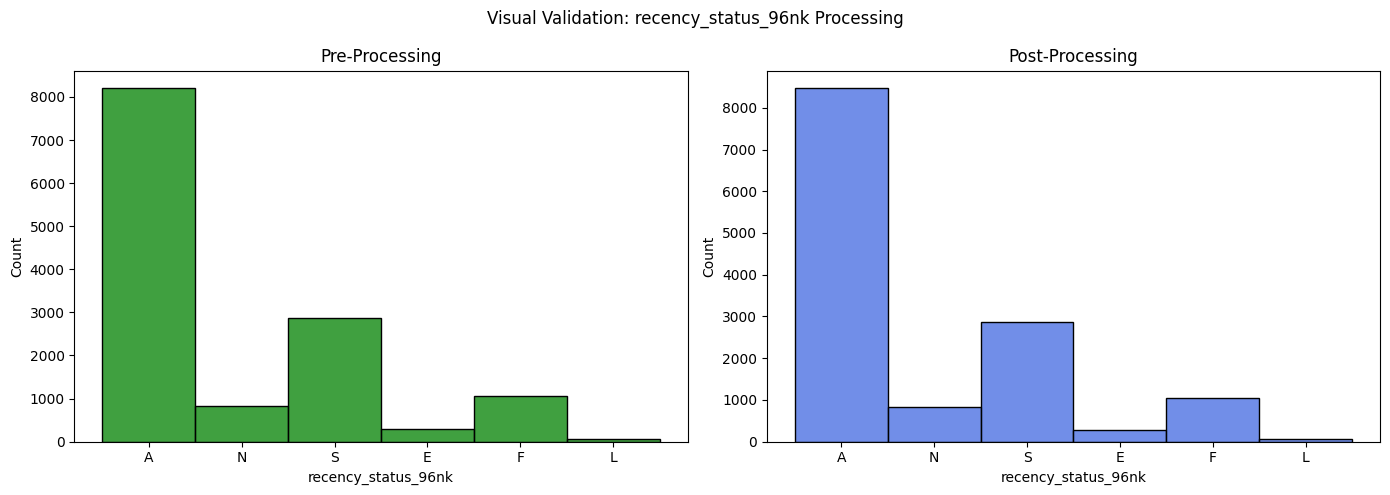

In [95]:
hist_plot('recency_status_96nk')

`frequency_status_97nk`
- this feature must be >0
- value input with mode based on wich `recency_status_96nk` because donors with the same status will have similar number of status donated in last period
- Round decimal values to assure feature consistency

In [96]:
# frequency_status_97nk
# print(df_copy['frequency_status_97nk'].describe())
df_copy.loc[df_copy['frequency_status_97nk']<0, 'frequency_status_97nk'] = np.nan
df_copy['frequency_status_97nk'] = df_copy.groupby(df_copy['recency_status_96nk'])['frequency_status_97nk'].transform(lambda x: x.fillna(x.mode()[0]))
df_copy['frequency_status_97nk'] = df_copy['frequency_status_97nk'].abs().round().astype(int)
# print(df_copy['frequency_status_97nk'].value_counts(dropna=False))

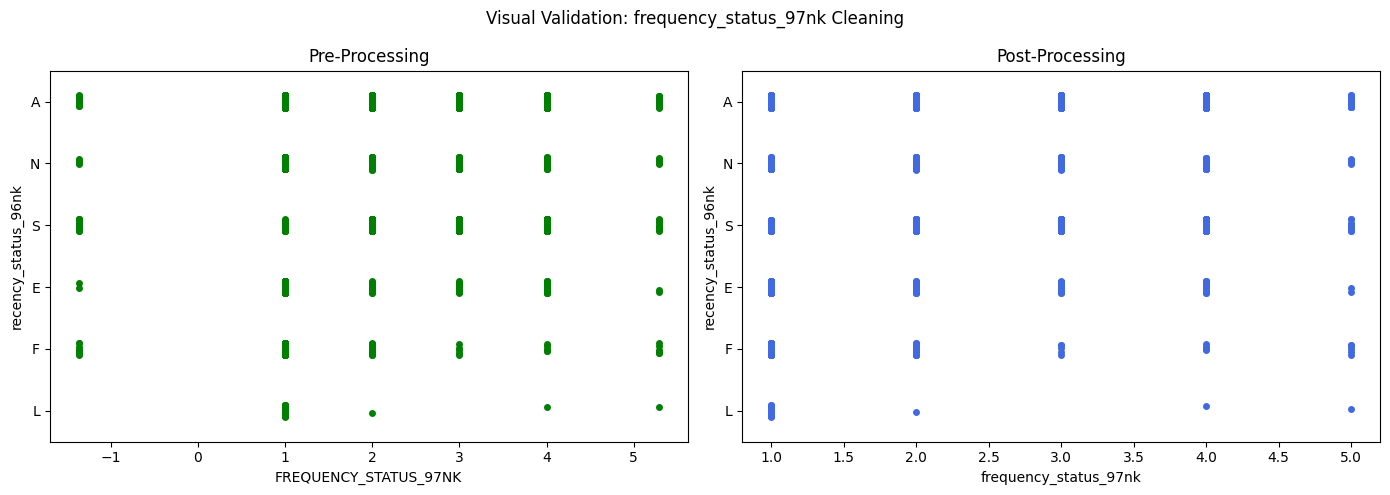

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.stripplot(x ='FREQUENCY_STATUS_97NK', y = 'RECENCY_STATUS_96NK', data = df, ax=axes[0], color='green')
axes[0].set_title("Pre-Processing")
axes[0].set_ylabel("recency_status_96nk")
sns.stripplot(x ='frequency_status_97nk', y = 'recency_status_96nk', data = df_copy, ax=axes[1], color='royalblue')
axes[1].set_title("Post-Processing")
axes[1].set_ylabel("recency_status_96nk")
plt.suptitle("Visual Validation: frequency_status_97nk Cleaning")
plt.tight_layout()
plt.show()

With this plot we verify if frequency status will stay in the same range for all status before and after cleaning since they are dependent on each other

`months_since_first_gift` and `months_since_last_gift`
- these features must be > 0
- The moment the dataset was extracted all the status were calculated based on the months columns. This means that we can input the months columns with the mode for the specific donor recency_status. Since `months_since_first_gift` must be greater than `months_since_last_gift` than we input `months_since_first_gift` with either the mode function or `months_since_last_gift`, whichever is greater
- The rest of null values of `months_since_last_gift` are input with the respective value from `months_since_first_gift`
- The outliers of both these features are controlled inside each `recency_status_96nk` with a cap at 99th percentile
- There are a few donors with the count =0. These shouldn't have a months_since_last_gift(first_gift) so we imput these with the max. This is just to create a penalization system wich won't appear in the cluster because we exclude people with 0 gifts

In [98]:
# months_since_first_gift & months_since_last_gift
cols = ['months_since_first_gift', 'months_since_last_gift']

df_copy.loc[df_copy['months_since_first_gift']<0, 'months_since_first_gift' ] = np.nan
df_copy.loc[df_copy['months_since_last_gift']<0, 'months_since_last_gift' ] = np.nan

group_modes = df_copy.groupby('recency_status_96nk')['months_since_first_gift'].transform(lambda x: x.mode()[0] if not x.mode().empty else np.nan)

fill_values = np.maximum(group_modes, df_copy['months_since_last_gift'].fillna(0))

df_copy['months_since_first_gift'] = df_copy['months_since_first_gift'].fillna(fill_values)

mask = df_copy["months_since_first_gift"] < df_copy["months_since_last_gift"]
df_copy.loc[mask, 'months_since_first_gift'] = df_copy.loc[mask, 'months_since_last_gift']

df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].fillna(df_copy['months_since_first_gift'])
df_copy['months_since_first_gift'] = df_copy['months_since_first_gift'].abs().round().astype(int)
df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].abs().round().astype(int)
# for col in cols:
#   print(df_copy[col].isnull().sum())
#   print(df_copy[col].describe())
# df_copy.loc[df_copy['months_since_first_gift']<df_copy['months_since_first_gift'], ['months_since_first_gift','months_since_last_gift']]

for col in cols:
    # Calculate the 99th percentile per group
    upper_limits = df_copy.groupby('recency_status_96nk')[col].transform(lambda x: x.quantile(0.99))
    # Cap values that exceed their specific group's threshold
    df_copy[col] = np.where(df_copy[col] > upper_limits, upper_limits, df_copy[col])

max_first = df_copy.groupby('recency_status_96nk')['months_since_first_gift'].transform('max')
max_last = df_copy.groupby('recency_status_96nk')['months_since_last_gift'].transform('max')
df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'months_since_first_gift'] = max_first[df_copy['lifetime_gift_count'] == 0]
df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'months_since_last_gift'] = max_last[df_copy['lifetime_gift_count'] == 0]

upper_limit = df_copy['months_since_last_gift'].quantile(0.99)
df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].clip(upper=upper_limit)

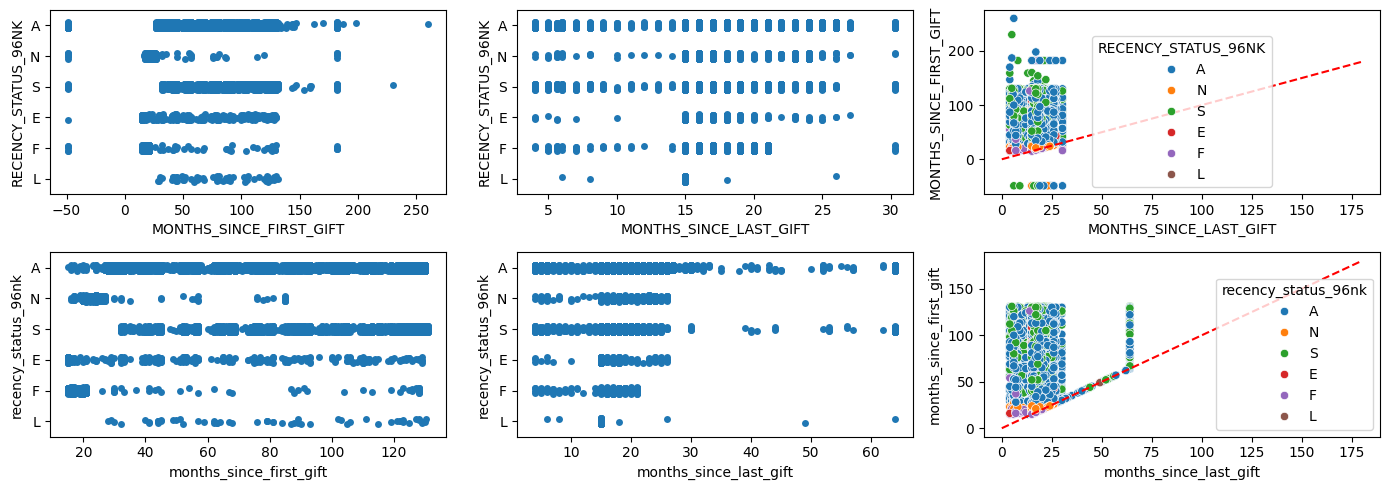

In [99]:
fig, axes = plt.subplots(2, 3, figsize=(14, 5))
sns.stripplot(x = 'MONTHS_SINCE_FIRST_GIFT', y = 'RECENCY_STATUS_96NK', data = df, ax = axes[0,0])
sns.stripplot(x = 'MONTHS_SINCE_LAST_GIFT', y = 'RECENCY_STATUS_96NK', data = df, ax = axes[0,1])
sns.scatterplot(x='MONTHS_SINCE_LAST_GIFT', y='MONTHS_SINCE_FIRST_GIFT',hue = 'RECENCY_STATUS_96NK', data=df, ax = axes[0,2])
axes[0, 2].plot([0, 180], [0, 180], color='red', linestyle='--')
sns.stripplot(x = 'months_since_first_gift', y = 'recency_status_96nk', data = df_copy, ax = axes[1,0])
sns.stripplot(x = 'months_since_last_gift', y = 'recency_status_96nk', data = df_copy, ax = axes[1,1])
sns.scatterplot(x='months_since_last_gift', y='months_since_first_gift',hue = 'recency_status_96nk', data=df_copy, ax = axes[1,2])
axes[1, 2].plot([0, 180], [0, 180], color='red', linestyle='--')
plt.tight_layout()
plt.show()

 When a scatterplot of recency_status and months_since_first_gift(last_gift) is made we can see that it does not follow the pattern it is descrbed in the guidelines. This happens because we assume that from the moment the dataset was extracted no one has made a change in the status, but the months continue to pass and because the months columns are calculated columns they continued to increase in value.

`pep_star` and `recent_star_status`
- Both features should have only values of 0 or 1. Even though `recent_star_status` has values ranging to 22, does't make sense with the variable guidelines.
- If `recent_star_status` is at least 1 or `recency_status_96nk` is 'S' status then `pep_star` should also be 1
- the leftover nulls we can only assume that probably there hasn't been a star status

In [100]:
# Pep_star and Recent_star_status

df_copy.loc[~df_copy['pep_star'].isin([0,1]), 'pep_star'] = np.nan
df_copy.loc[df_copy['recent_star_status'] < 0, 'recent_star_status'] = np.nan
df_copy.loc[df_copy['recent_star_status'] > 1, 'recent_star_status'] = 1


mask = (df_copy['recent_star_status']==1) | (df_copy['recency_status_96nk']=='S')
df_copy.loc[mask, 'pep_star'] = df_copy.loc[mask, 'pep_star'].fillna(1)


df_copy['recent_star_status'].fillna(0, inplace=True)
df_copy['pep_star'].fillna(0,inplace = True)
# print(df_copy['recent_star_status'].value_counts(dropna=False))
# print(df_copy['pep_star'].value_counts(dropna=False))

/tmp/ipykernel_2808/1417848154.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy['recent_star_status'].fillna(0, inplace=True)
/tmp/ipykernel_2808/1417848154.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)

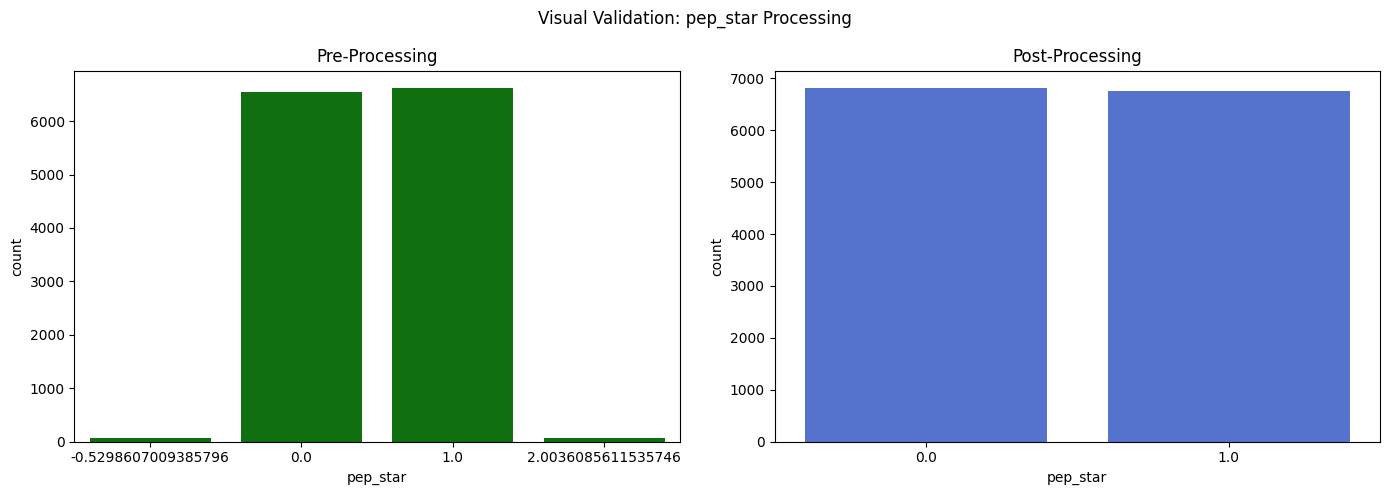

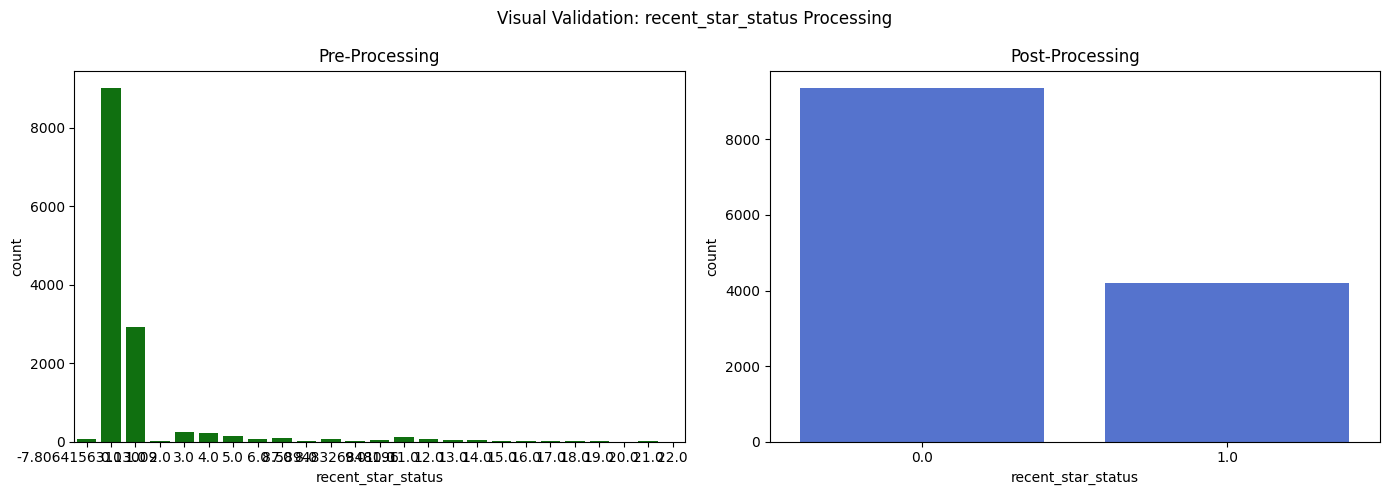

In [101]:
count_plot('pep_star')
count_plot('recent_star_status')

Finally, we verify if the process occured and applied the transformations as expected. Otherwise, something could have gone wrong in terms of logic on our code before.

In [102]:
nulls = df_copy.isnull().sum()
nulls[nulls>0]

,0


In [103]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13560 entries, 61745 to 45722
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   card_prom_12                 13560 non-null  int64  
 1   children                     13560 non-null  int64  
 2   donor_age                    13560 non-null  int64  
 3   donor_gender                 13560 non-null  object 
 4   file_card_gift               13560 non-null  float64
 5   frequency_status_97nk        13560 non-null  int64  
 6   home_owner                   13560 non-null  object 
 7   income_group                 13560 non-null  int64  
 8   last_gift_amt                13560 non-null  float64
 9   lifetime_card_prom           13560 non-null  int64  
 10  lifetime_gift_amount         13560 non-null  float64
 11  lifetime_gift_count          13560 non-null  float64
 12  lifetime_max_gift_amt        13560 non-null  float64
 13  lifetime_min_gift

---
# 3. Binary Classification and Optimization


Following the data preparation, our primary objective in this phase is to build a robust predictive system to answer our main challenge: **Will this person donate if contacted?** This task is approached through **Supervised Learning Binary Classification**.

To achieve this, we developed a set of functions and resources to ensure consistency and efficiency across the pipeline. We followed this structured methodology:

*   **Hybrid Feature Selection:** To address the Curse of Dimensionality, we combine multiple strategies to identify the most stable predictors:
    *   **Filter Methods:** Using `Chi-Square tests` for categorical relevance and `Variance Filtering` / `Spearman Correlation` to remove redundant numerical features.
    *   **Embedded and Wrapper Methods:** Utilizing `LassoCV`, `Recursive Feature Elimination (RFE)`, and `Decision Tree Importances` to rank feature predictive power.

*   **Model Training and Evaluation:** We evaluate four distinct classification algorithms to capture both linear and non-linear relationships:
    *   **Logistic Regression:** Serving as our baseline and interpretable parametric model.
    *   **Neural Networks (MLP), Random Forest, and Decision Trees:** To capture complex non-linear patterns in donor behavior.
    *   All models are evaluated using `Stratified 5-Fold Cross-Validation` with **F1-Score** as the primary metric due to class imbalance.

*   **Hyperparameter Tuning and Optimization:**
    *   We use `RandomizedSearchCV` to systematically explore the hyperparameter space for each model.
    *   **Threshold Tuning:** Applying Precision-Recall curves to find the optimal classification threshold for our final winning model.

By centralizing these processes, we guarantee a reproducible and optimized path from raw cleaned data to our final prediction.

A copy of the donors descriptive table cleaned is created to be used for further pre-model preparation.

In [104]:
df_clean = df_copy.copy()

---
## 3.1. Feature Engineering

Since the raw dataset does not contain features that directly capture behavioural profiles, eight features were engineered inside 2 perspectives:
 - Donation Behaviour - We explore te donors behaviour in terms of donation frequency, variability and activity;
 - Donation Engagement - We explore the donors engagement to promotions, more specifically focused on the card ones if they prefer cards or are more eficient to respond if a card is envolved.


---
### 3.1.1. Donation_Behaviour <a name="donation-behavior"></a>


`lifetime_avg_gift`

**Meaning**: Represents the average donation of a donor

**Relevance**: Allows us to distinguish between donors who give a large amount at a time from donors who give small amounts

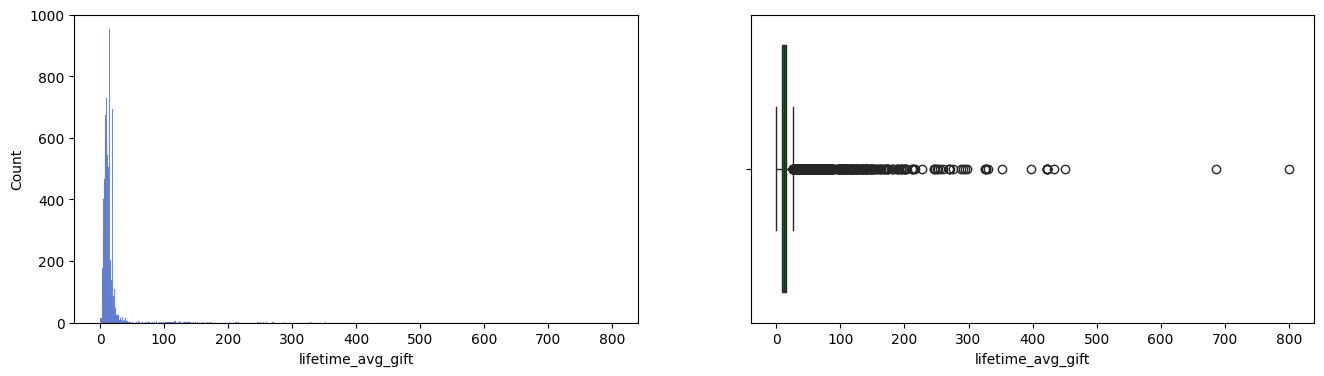

In [105]:
df_clean['lifetime_avg_gift'] = np.where(df_clean['lifetime_gift_count'] > 0, df_clean['lifetime_gift_amount']/df_clean['lifetime_gift_count'],0)
boxplot_hist(df_clean, 'lifetime_avg_gift', color_name = 'green')

`gift_variability`

**Meaning**: Measures the behaviour of donations

**Relevance**: A low variability indicates a stable/predictable donor, whilst a high variability  suggests that the donor  can be highly influenced by the campaigns

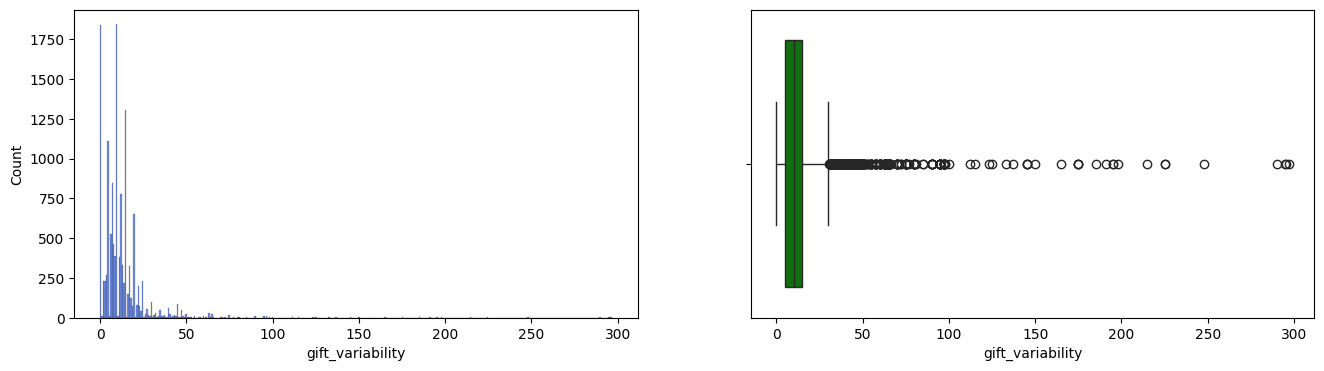

In [106]:
df_clean['gift_variability'] = df_clean['lifetime_max_gift_amt'] - df_clean['lifetime_min_gift_amt']
boxplot_hist(df_clean, 'gift_variability', color_name = 'green')

`dontion_freq`

**Meaning**: Measures the level of commitment and loyalty through the time

**Relevance**: A donor with a high frequency is a faithfull donors independently of the donation amount

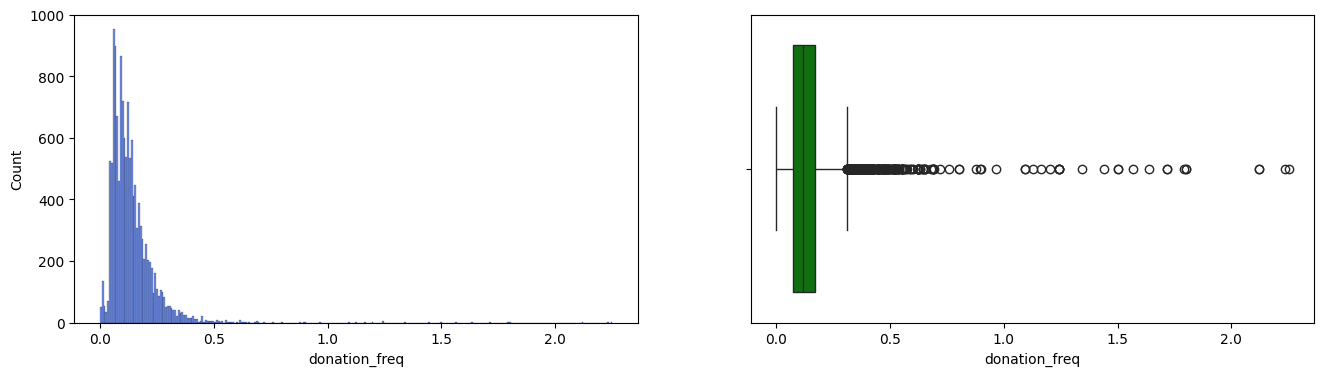

In [107]:
df_clean['donation_freq'] = np.where(df_clean['months_since_first_gift'] > 0, df_clean['lifetime_gift_count']/(df_clean['months_since_first_gift']),0)
boxplot_hist(df_clean, 'donation_freq', color_name = 'green')

`recency_value`

**Meaning**: Evaluates the "current value" of the donor for the organization

**Relevance**: Donors with a low value used to be frequent donors in the past, whilst a high value means that the donors are active in the current days. This feature is crucial in identifying donors at risk of churn and thos who are active and generous in the present

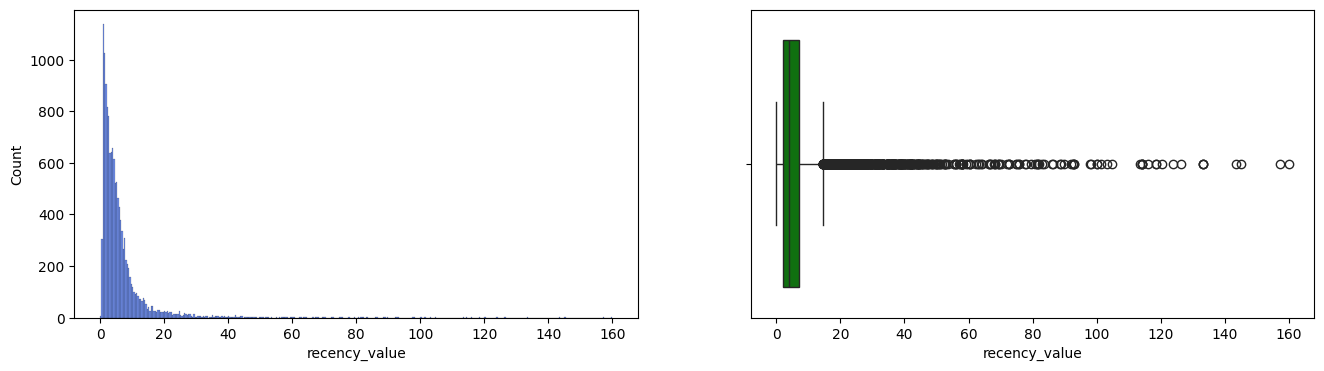

In [108]:
df_clean['recency_value'] = df_clean['lifetime_gift_amount'] / (1 + df_clean['months_since_last_gift'])
boxplot_hist(df_clean, 'recency_value', color_name = 'green')

---
### 3.1.2. Donation_Engagement <a name="donation-engagement"></a>

`engagment_recency_score`

**Meaning**: It is like a score and tells if a donor is active or inactive

**Relevance**: The more recent the activity is for that donor the higher is the score

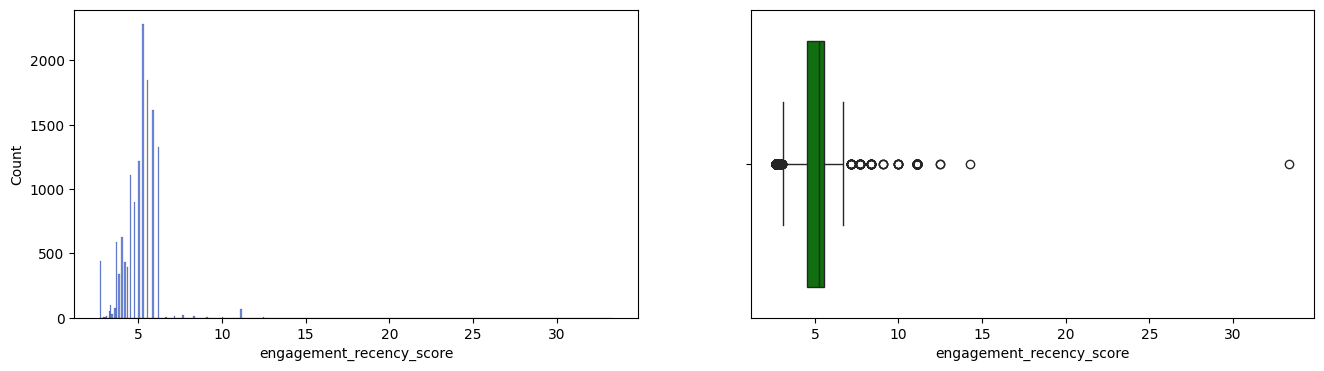

In [109]:
df_clean['engagement_recency_score'] = 100/ (1+df_clean['months_since_last_prom_resp']) # active or not
boxplot_hist(df_clean, 'engagement_recency_score', 'green')

`response_intensity`

**Meaning**: Proportion between the recent response count and the total amount of promotions sent to that individual. It tells us how much people respond to promotions.

**Relevance**: It helps seperate the more passive donors from the more enthusiasts


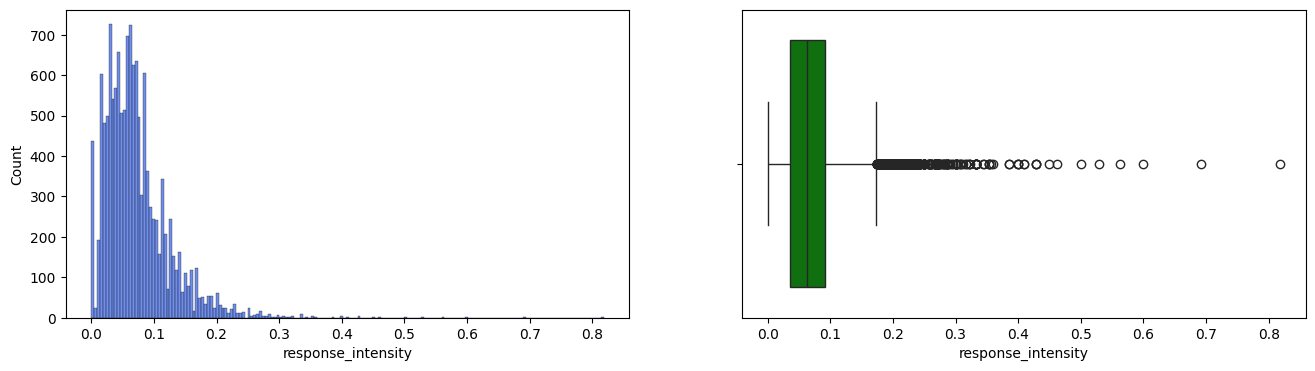

In [110]:
df_clean['response_intensity'] = (df_clean['recent_response_count'].astype(float))/(1+df_clean['lifetime_prom'].astype(float))
boxplot_hist(df_clean, 'response_intensity', 'green')

`card_efficiency`

**Meaning**: The efficiency of their response to card promotions.

**Relevance**: If they have a high count with low card promotion amount this means that this group is very effective to respond to cards if they aren't given to many

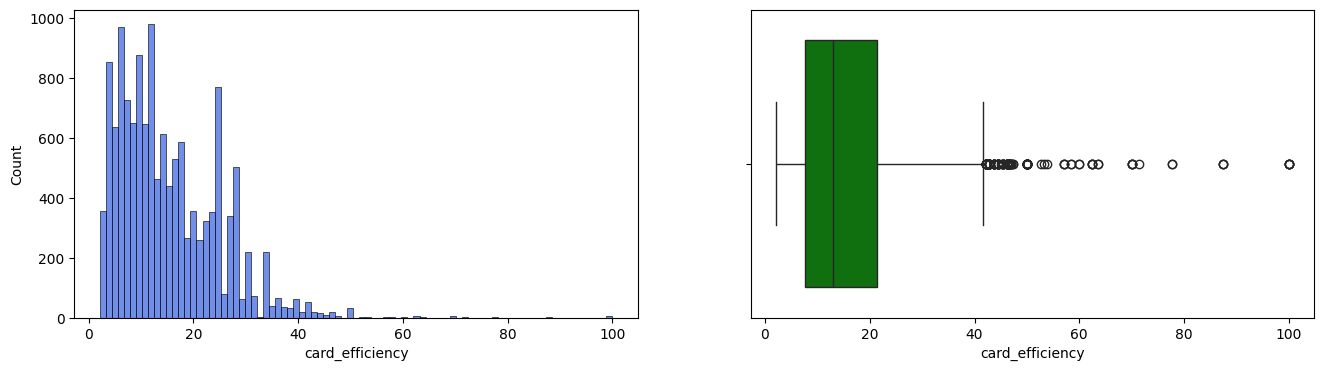

In [111]:
df_clean['card_efficiency'] = (df_clean['recent_card_response_count']+1)*100/ (2+df_clean['lifetime_card_prom'])
#The multiplication by 100 derives from the fact that these values are to small and kmeans will have a hard time seperating them. this way it's more like a percentage
boxplot_hist(df_clean, 'card_efficiency', 'green')

`card_preference`

**Meaning**: If they prefer cards or other promotions

**Relevance**: If this value is closer to 1 than it means that the organization shuld only send cards to this donors

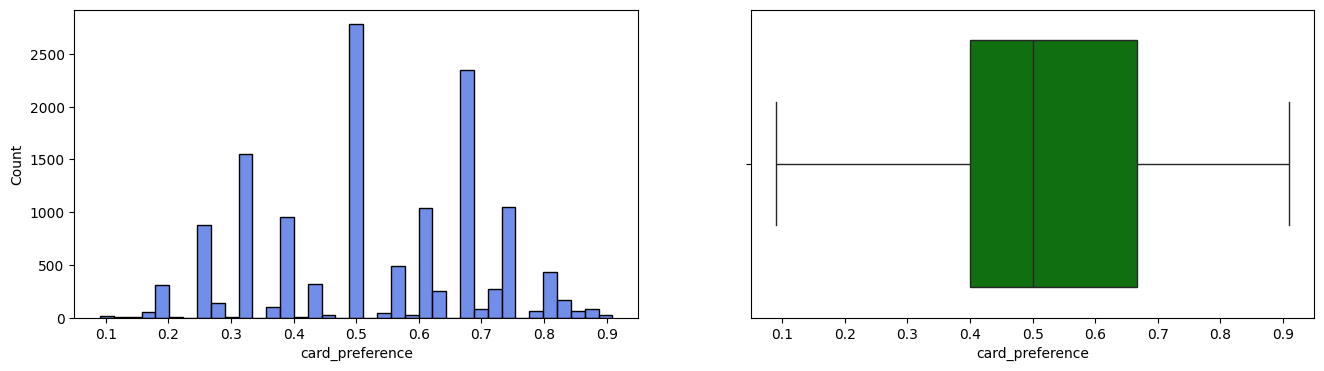

In [112]:
df_clean['card_preference'] = ((df_clean['recent_card_response_count']+1) / (2+df_clean['recent_response_count']))
boxplot_hist(df_clean, 'card_preference', 'green')

---
## 3.2. Feature Selection


Here we merge the cleaned data table with our target feature to construct the modeling dataset. The target file is imported using CONTROL_NUMBER as the index, its columns are standardized to lowercase, and an inner merge is performed on the indices to ensure perfect alignment between the donors' attributes and their respective target labels.

In [113]:
df_target = pd.read_csv(path+'donors_train_target.csv', index_col='CONTROL_NUMBER')
df_target.columns = df_target.columns.str.lower()
df_target = df_target.merge(df_clean, how='inner', left_index=True, right_index=True)

In [114]:
df_target.head()

,target_b,card_prom_12,children,donor_age,donor_gender,file_card_gift,frequency_status_97nk,home_owner,income_group,last_gift_amt,...,wealth_rating,no_response_flag,lifetime_avg_gift,gift_variability,donation_freq,recency_value,engagement_recency_score,response_intensity,card_efficiency,card_preference
61745,1,4,2,33,M,0.0,1,H,5,20.0,...,3,0,17.500000,5.0,0.071429,1.842105,5.263158,0.090909,9.090909,0.250000
112703,1,3,2,60,F,1.0,1,U,2,15.0,...,1,0,15.000000,0.0,0.041667,0.600000,4.000000,0.062500,25.000000,0.666667
166437,0,4,0,74,F,7.0,3,H,4,10.0,...,7,0,7.181818,7.0,0.085271,4.937500,6.250000,0.073171,5.263158,0.200000
170621,0,4,4,61,M,13.0,1,H,6,11.0,...,7,0,4.705882,8.0,0.130769,4.705882,5.882353,0.026316,10.000000,0.750000
44428,0,6,3,75,M,3.0,4,H,3,7.0,...,7,0,5.400000,2.0,0.208333,1.500000,5.555556,0.217391,36.363636,0.571429


While several approaches exist for data partitioning and evaluation we opted for K-Fold Cross-Validation taking into consideration the size of our dataset. This method allows every observation to be used for both training and validation, what is an advantage because if we selected a more simple method, such as Hold-Out, we could be biasing our results since the spliting could cause an "unlucky" distribution (for example, only getting individuals who don't donate).

In [115]:
skf = StratifiedKFold(n_splits = 5, random_state = 42, shuffle = True)
X = df_target.drop('target_b', axis = 1)
y = df_target['target_b'].copy()

We implemented the following specifications:

n_splits = 5: Provides a sufficiently large training set for the model to learn the underlying patterns of the features while maintaining a substantial validation set. Additionally, this value ensures computational efficiency for iterative testing and feature selection.

shuffle = True: Ensures that the original order of the data does not influence the training process by shuffling samples before each split.

We also separate the predictive features from the target variable. The dataset is divided into:

X: The feature matrix, excluding the target_b column.

y: A safe copy of the target_b column, serving as our target label for the classification models.

In machine learning, high-dimensional datasets often contain irrelevant, redundant, or noisy variables that can lead to overfitting and increased computational costs. Feature Selection is crucial to address this "Curse of Dimensionality," improving both model performance and interpretability.

Since individual selection methods have inherent biases, we adopted for a hybrid approach. By combining multiple techniques and established a robust voting system. This ensures that the finalized subset of features represents the most stable and variables with more predictive power for our models.


| Predictor | Data Type |
| --- | --- |
| donor_age | Continuos |
| urbanicity | Categorical |
| ses | Ordinal |
| home_owner | Categorical |
| donor_gender | Categorical |
| income_group | Ordinal |
| wealth_rating | Ordinal |
| median_home_value | Continuous |
|median_household_income | Continuous |
| pct_owner_occupied | Continuous |
| per_capita_income | Continuous |
| pct_attribute(1 - 4) | Continuous |
| pep_star | Binary |
| recent_star_status | Binary |
| children | Continuous |
| recent_avg_gift_amt | Continuos |
| recent_card_response_prop | Continuous |
| recency_status_96nk | Categorical |
| frequency_status_96nk | Continuos |
| recent_response_ prop | Continuos |
| file_card_gift | Continuos |
| lifetime_card_prom | Continuos |
| lifetime_prom | Continuos |
| recent_avg_card_gift_amt | Continuos |
| recent_response_count | Continuos |
| recen t_card_response_count| Continuos |
| months_since_last_prom_resp | Continuos |
| lifetime_gift_amount | Continuos |
| lifetime_gift_count | Continuos |
| lifetime_max_gift_amt | Continuos |
| lifetime_min_gift_amt | Continuos |
| last_gift_amt | Continuos |
| card_prom_12 | Continuos |
| number_prom_12 | Continuos |
| months_since_last_gift | Continuos |
| months_since_first_gift | Continuos |
| no_response_flag | Binary |
| lifetime_avg_gigt | Continuos |
| gift_variability | Continuos |
| dontaion_freq | Continuos |
| recency_value | Continuos |
| engagement_recency_score | Continuos |
| response_intensity | Continuos |
| card_efficiency | Continuos |
| card_preference | Continuos |
| --- | --- |
| target_b | Binary |

### 3.2.1. Categorical features: Chi-square method

To evaluate the statistical relevance of our categorical features, two functions were implemented:
* `skf_splits`: Generates balanced training and validation splits using Stratified K-Fold validation to guarantee consistent target distribution during feature selection.
* `apply_chisquare`: Executes a Chi-Square test of independence between a feature (X) and the target (y). Using a significance threshold ($\alpha = 0.05$), it automatically determines whether a categorical variable shares a statistically significant relationship with the target (retained) or if it behaves independently and should be discarded.

In [116]:
def skf_splits(X,y):
  for train_index, val_index in skf.split(X, y):
    X_train, X_val = X.iloc[train_index], X.iloc[val_index]
    y_train, y_val = y.iloc[train_index], y.iloc[val_index]
    yield X_train, X_val, y_train, y_val

In [117]:
def apply_chisquare(X, y, var, alpha=0.05):
  dfObserved = pd.crosstab(y, X)
  chi2, p, dof, expected = stats.chi2_contingency(dfObserved.values)
  dfExpected = pd.DataFrame(expected, columns=dfObserved.columns, index = dfObserved.index)
  if p<alpha:
      result="{0} is IMPORTANT for Prediction".format(var)
  else:
      result="{0} is NOT an important predictor. (Discard {0} from model)".format(var)
  print(result)

`select_best_cat_features` - applies the 2 functions above to select the best categorical features from our dataset

In [118]:
def select_best_cat_features(X, y, skf):
  count = 1
  # here we apply the skf
  for X_train, X_val, y_train, y_val in skf_splits(X, y):
    # select the features with chi-square
    print('_________________________________________________________________________________________________\n')
    print('                                     SPLIT ' + str(count) + '                                    \n')

    # We pass the categorical features
    X_train_cat = X_train[['donor_gender','urbanicity','home_owner','recency_status_96nk','ses', 'income_group', 'wealth_rating',
                            'pep_star', 'recent_star_status', 'no_response_flag']].copy()
    for var in X_train_cat:
      apply_chisquare(X_train_cat[var], y_train, var)
    count+=1

In [119]:
select_best_cat_features(X, y, skf)

_________________________________________________________________________________________________

                                     SPLIT 1                                    

donor_gender is NOT an important predictor. (Discard donor_gender from model)
urbanicity is IMPORTANT for Prediction
home_owner is IMPORTANT for Prediction
recency_status_96nk is IMPORTANT for Prediction
ses is IMPORTANT for Prediction
income_group is IMPORTANT for Prediction
wealth_rating is IMPORTANT for Prediction
pep_star is IMPORTANT for Prediction
recent_star_status is IMPORTANT for Prediction
no_response_flag is NOT an important predictor. (Discard no_response_flag from model)
_________________________________________________________________________________________________

                                     SPLIT 2                                    

donor_gender is NOT an important predictor. (Discard donor_gender from model)
urbanicity is IMPORTANT for Prediction
home_owner is NOT an important p

| Predictor | Chi-Square | Decision |
| --- | --- | --- |
| donor_gender | 0 YES | Remove |
| urbanicity | 3 YES | Keep |
| home_owner | 2 YES | Remove |
| recency_status_96nk | 5 YES | Keep |
| ses | 5 YES | Keep |
| income_group | 5 YES | Keep |
| wealth_rating | 3 YES | Keep |
| pep_star | 5 YES | Keep |
| recent_star_status | 5 YES | Keep |
| no_response_flag | 0 YES | Remove |


In [120]:
X = X.drop(['donor_gender','home_owner','no_response_flag'], axis = 1)

### 3.2.2. Numerical features

#### Variance (Filter Method)

Here we evaluate numerical variables based on their variance. Features with extremely low variance offer minimal information since their values barely change across donors. This makes them poor predictors for machine learning models.

To integrate this into our cross-validation pipeline, we implemented two functions:

* `apply_variance(X_train, var)`: Calculates and prints the rounded variance of a specific numerical feature within the current training fold;

* `select_features_variance(X, y)`: Targets all numeric data types (np.number), loops through each stratified fold via skf_splits, and computes the variance for every numerical attribute contextually.

In [121]:
def apply_variance(X_train, var):
  print(var + ':' + str(round(X_train.var(),2)))

In [122]:
def select_features_variance(X, y):
  count = 1
  numerical_columns = X.select_dtypes(include=[np.number]).columns
  # apply the skf
  for X_train, X_val, y_train, y_val in skf_splits(X, y):
    # select features based on variance
    print('_________________________________________________________________________________________________\n')
    print('                                     SPLIT ' + str(count) + '                                    \n')
    # check which features to use
    for var in numerical_columns:
      apply_variance(X_train[var], var)
    count+=1

In [123]:
select_features_variance(X, y)

_________________________________________________________________________________________________

                                     SPLIT 1                                    

card_prom_12:2.21
children:2.02
donor_age:180.71
file_card_gift:22.22
frequency_status_97nk:1.24
income_group:2.97
last_gift_amt:530.31
lifetime_card_prom:75.02
lifetime_gift_amount:9697.38
lifetime_gift_count:78.64
lifetime_max_gift_amt:572.03
lifetime_min_gift_amt:478.73
lifetime_prom:533.5
median_home_value:952101.46
median_household_income:24380.71
months_since_first_gift:1426.45
months_since_last_gift:42.3
months_since_last_prom_resp:20.93
number_prom_12:23.69
pct_attribute1:27.96
pct_attribute2:131.82
pct_attribute3:231.98
pct_attribute4:321.24
pct_owner_occupied:477.65
pep_star:0.25
per_capita_income:78850505.3
recent_avg_card_gift_amt:107.88
recent_avg_gift_amt:497.88
recent_card_response_count:2.44
recent_card_response_prop:0.04
recent_response_count:4.4
recent_response_prop:0.01
recent_star_status:

By evaluating the output across splits, we can safely discard `recent_response_prop`.

In [124]:
X = X.drop(['recent_response_prop', 'response_intensity', 'card_preference', 'donation_freq'], axis = 1)

#### Spearman Correlation (Filter Method)

High correlation between independent numerical variables leads to multicollinearity, which can destabilize model coefficients and cause overfitting. To prevent this, we analyze the relationships between features using Spearman's Correlation.To monitor this we defined the following functions:

* `color(val)`: A styling function that highlights highly correlated pairs ($|r_s| > 0.8$) in red and diagonal identity correlations ($r_s = 1.0$) in grey for immediate visual screening;

* `redundant_features(X, y)`: The main execution pipeline. Within each stratified cross-validation split, it isolates numerical data types, computes the absolute Spearman correlation matrix, and applies our custom cell-coloring function.

By running this across multiple folds, we ensure that the detected collinear patterns are consistent across different training samples, allowing us to confidently drop one feature from each highly correlated pair.

In [125]:
def color(val):
  """ This function applies a red color to all correlation values that are superior than 0.8"""
  if val > 0.8 and val != 1:
      color = 'red'
  elif val == 1:
      color = 'grey'
  else:
      color = 'black'
  return f'color: {color}'

In [126]:
def redundant_features(X, y):
  count = 1
  # aplies the skf
  for X_train, X_val, y_train, y_val in skf_splits(X, y):
    # selects the features
    print('_________________________________________________________________________________________________\n')
    print('                                     SPLIT ' + str(count) + '                                    \n')

    # check which features to use using spearman correlation
    numeric = X_train.select_dtypes(include=[np.number]).copy()
    corr_matrix = numeric.corr(method="spearman").abs()
    display(corr_matrix.style.map(color))
    count+=1
  return None

In [127]:
redundant_features(X, y)

_________________________________________________________________________________________________

                                     SPLIT 1                                    



,card_prom_12,children,donor_age,file_card_gift,frequency_status_97nk,income_group,last_gift_amt,lifetime_card_prom,lifetime_gift_amount,lifetime_gift_count,lifetime_max_gift_amt,lifetime_min_gift_amt,lifetime_prom,median_home_value,median_household_income,months_since_first_gift,months_since_last_gift,months_since_last_prom_resp,number_prom_12,pct_attribute1,pct_attribute2,pct_attribute3,pct_attribute4,pct_owner_occupied,pep_star,per_capita_income,recent_avg_card_gift_amt,recent_avg_gift_amt,recent_card_response_count,recent_card_response_prop,recent_response_count,recent_star_status,ses,wealth_rating,lifetime_avg_gift,gift_variability,recency_value,engagement_recency_score,card_efficiency
card_prom_12,1.000000,0.018493,0.032759,0.233341,0.326691,0.009485,0.010018,0.347303,0.336957,0.266980,0.076864,0.159287,0.327108,0.015222,0.014905,0.163664,0.150923,0.073867,0.681643,0.004329,0.011377,0.009101,0.006498,0.003020,0.201352,0.016817,0.097618,0.030518,0.268912,0.035016,0.365174,0.132383,0.014880,0.015904,0.064545,0.271163,0.366025,0.073867,0.073472
children,0.018493,1.000000,0.005385,0.011102,0.003592,0.001131,0.000782,0.018747,0.011790,0.009445,0.007143,0.002748,0.013973,0.008996,0.005136,0.014452,0.008297,0.002636,0.011523,0.001346,0.005160,0.009505,0.002005,0.007006,0.014867,0.002022,0.000395,0.003035,0.004793,0.002349,0.003131,0.000949,0.013803,0.011398,0.004099,0.004905,0.013375,0.002636,0.013042
donor_age,0.032759,0.005385,1.000000,0.191603,0.052803,0.185998,0.084356,0.198428,0.166524,0.193856,0.060297,0.122151,0.202262,0.027532,0.087932,0.208147,0.060752,0.029885,0.064131,0.023884,0.098985,0.121478,0.143402,0.048267,0.128892,0.012523,0.041998,0.068534,0.032811,0.013727,0.074615,0.130459,0.042144,0.065185,0.111240,0.042022,0.174617,0.029885,0.108915
file_card_gift,0.233341,0.011102,0.191603,1.000000,0.343809,0.076902,0.339596,0.822833,0.761897,0.866384,0.217066,0.568523,0.795988,0.049638,0.047637,0.787707,0.085189,0.058562,0.261998,0.013754,0.018161,0.052663,0.043754,0.012979,0.734406,0.020126,0.013700,0.318849,0.474894,0.204436,0.483832,0.652444,0.026251,0.029256,0.468437,0.262513,0.736143,0.058562,0.188623
frequency_status_97nk,0.326691,0.003592,0.052803,0.343809,1.000000,0.069439,0.511668,0.138525,0.169400,0.369687,0.398812,0.355701,0.125193,0.040235,0.045556,0.107827,0.312784,0.326485,0.288391,0.013590,0.004396,0.018040,0.000476,0.013316,0.325506,0.035035,0.118129,0.506008,0.572215,0.442433,0.718148,0.260160,0.037751,0.039181,0.461226,0.081520,0.227943,0.326485,0.340295
income_group,0.009485,0.001131,0.185998,0.076902,0.069439,1.000000,0.104906,0.065649,0.035407,0.094414,0.094973,0.096692,0.061701,0.362157,0.396748,0.074562,0.017202,0.018015,0.005240,0.018638,0.026087,0.077250,0.099816,0.117990,0.075650,0.368174,0.073373,0.100997,0.025398,0.009576,0.069177,0.070293,0.354492,0.359736,0.119740,0.014509,0.035017,0.018015,0.025373
last_gift_amt,0.010018,0.000782,0.084356,0.339596,0.511668,0.104906,1.000000,0.142623,0.018238,0.428967,0.817460,0.551069,0.139177,0.084714,0.079280,0.175733,0.187196,0.168399,0.014219,0.002014,0.017262,0.020551,0.015983,0.001246,0.313577,0.075298,0.362306,0.834511,0.357628,0.297623,0.438177,0.274737,0.081041,0.086786,0.785709,0.264178,0.035494,0.168399,0.183826
lifetime_card_prom,0.347303,0.018747,0.198428,0.822833,0.138525,0.065649,0.142623,1.000000,0.843312,0.824294,0.023976,0.493548,0.948170,0.046274,0.033582,0.898942,0.018473,0.031048,0.360691,0.014134,0.020984,0.047782,0.038779,0.023748,0.586699,0.014271,0.073676,0.120827,0.170496,0.165851,0.309723,0.534018,0.019716,0.019915,0.305665,0.427334,0.799609,0.031048,0.570403
lifetime_gift_amount,0.336957,0.011790,0.166524,0.761897,0.169400,0.035407,0.018238,0.843312,1.000000,0.785591,0.185645,0.321401,0.845686,0.004149,0.004761,0.751967,0.048628,0.036152,0.396073,0.004895,0.010390,0.036778,0.027589,0.013677,0.566349,0.022642,0.088277,0.054446,0.218122,0.101110,0.329728,0.509199,0.014142,0.009782,0.046123,0.516705,0.952230,0.036152,0.432219
lifet

_________________________________________________________________________________________________

                                     SPLIT 2                                    



,card_prom_12,children,donor_age,file_card_gift,frequency_status_97nk,income_group,last_gift_amt,lifetime_card_prom,lifetime_gift_amount,lifetime_gift_count,lifetime_max_gift_amt,lifetime_min_gift_amt,lifetime_prom,median_home_value,median_household_income,months_since_first_gift,months_since_last_gift,months_since_last_prom_resp,number_prom_12,pct_attribute1,pct_attribute2,pct_attribute3,pct_attribute4,pct_owner_occupied,pep_star,per_capita_income,recent_avg_card_gift_amt,recent_avg_gift_amt,recent_card_response_count,recent_card_response_prop,recent_response_count,recent_star_status,ses,wealth_rating,lifetime_avg_gift,gift_variability,recency_value,engagement_recency_score,card_efficiency
card_prom_12,1.000000,0.010918,0.034633,0.239057,0.332650,0.007275,0.012774,0.354800,0.342567,0.275170,0.073766,0.163436,0.332929,0.012139,0.014616,0.169457,0.157963,0.085142,0.683805,0.004843,0.004651,0.002995,0.010164,0.006593,0.203326,0.007751,0.096858,0.032231,0.266436,0.035016,0.372845,0.129946,0.008979,0.012114,0.070655,0.268250,0.373872,0.085142,0.080151
children,0.010918,1.000000,0.017368,0.011290,0.008128,0.001269,0.000013,0.016452,0.009587,0.011056,0.013144,0.000965,0.013258,0.011756,0.013292,0.022071,0.009550,0.005678,0.007853,0.004372,0.014752,0.001451,0.005881,0.000845,0.022753,0.003309,0.000084,0.008996,0.001891,0.000020,0.001120,0.015017,0.013713,0.014566,0.003903,0.003730,0.010294,0.005678,0.011573
donor_age,0.034633,0.017368,1.000000,0.194615,0.060929,0.185050,0.090144,0.204451,0.176768,0.202599,0.054640,0.128219,0.208180,0.043521,0.091501,0.215181,0.064740,0.030725,0.065495,0.024787,0.093674,0.127382,0.140273,0.041552,0.134228,0.019533,0.052325,0.070759,0.029761,0.018575,0.078658,0.128372,0.053289,0.073765,0.115007,0.055716,0.185937,0.030725,0.116345
file_card_gift,0.239057,0.011290,0.194615,1.000000,0.350300,0.076036,0.345963,0.822594,0.763812,0.870938,0.216488,0.569829,0.793705,0.048938,0.044466,0.788903,0.093893,0.066336,0.262857,0.023469,0.027798,0.051799,0.048272,0.017325,0.733003,0.021477,0.011472,0.321484,0.468347,0.203285,0.485263,0.654007,0.028110,0.032557,0.472555,0.269442,0.740172,0.066336,0.193431
frequency_status_97nk,0.332650,0.008128,0.060929,0.350300,1.000000,0.074609,0.519073,0.149888,0.172649,0.376877,0.407367,0.358362,0.134089,0.044909,0.040865,0.120921,0.324685,0.334130,0.292621,0.012753,0.009779,0.011245,0.003807,0.001172,0.328156,0.039647,0.114150,0.509068,0.564362,0.432421,0.717196,0.260383,0.045475,0.042339,0.469946,0.084732,0.233731,0.334130,0.324683
income_group,0.007275,0.001269,0.185050,0.076036,0.074609,1.000000,0.106364,0.061499,0.033405,0.095261,0.095330,0.097426,0.060656,0.363605,0.390015,0.073133,0.028257,0.028751,0.016218,0.013628,0.033581,0.078228,0.096329,0.121111,0.069466,0.357117,0.061265,0.100639,0.032359,0.019942,0.071197,0.073157,0.354949,0.355074,0.118444,0.019402,0.036380,0.028751,0.016564
last_gift_amt,0.012774,0.000013,0.090144,0.345963,0.519073,0.106364,1.000000,0.155304,0.006889,0.432983,0.817596,0.549087,0.149302,0.080887,0.072879,0.188229,0.195010,0.169922,0.014993,0.001636,0.015796,0.026106,0.027551,0.008828,0.322708,0.067987,0.358374,0.831941,0.357354,0.297374,0.443070,0.287396,0.073623,0.085336,0.787634,0.266833,0.046895,0.169922,0.176788
lifetime_card_prom,0.354800,0.016452,0.204451,0.822594,0.149888,0.061499,0.155304,1.000000,0.845151,0.832748,0.028358,0.500654,0.946106,0.046553,0.037118,0.897631,0.025751,0.025446,0.364257,0.021496,0.024862,0.046169,0.036581,0.020814,0.587916,0.024157,0.077971,0.130536,0.164284,0.166611,0.313306,0.534544,0.024037,0.028645,0.315082,0.431080,0.803242,0.025446,0.572785
lifetime_gift_amount,0.342567,0.009587,0.176768,0.763812,0.172649,0.033405,0.006889,0.845151,1.000000,0.796041,0.184446,0.329633,0.847106,0.003151,0.008071,0.752702,0.047865,0.035389,0.400125,0.011345,0.019262,0.035811,0.023738,0.016083,0.563477,0.012312,0.087507,0.048204,0.209587,0.106242,0.329347,0.509039,0.006953,0.004508,0.054662,0.523162,0.951232,0.035389,0.439973
lifet

_________________________________________________________________________________________________

                                     SPLIT 3                                    



,card_prom_12,children,donor_age,file_card_gift,frequency_status_97nk,income_group,last_gift_amt,lifetime_card_prom,lifetime_gift_amount,lifetime_gift_count,lifetime_max_gift_amt,lifetime_min_gift_amt,lifetime_prom,median_home_value,median_household_income,months_since_first_gift,months_since_last_gift,months_since_last_prom_resp,number_prom_12,pct_attribute1,pct_attribute2,pct_attribute3,pct_attribute4,pct_owner_occupied,pep_star,per_capita_income,recent_avg_card_gift_amt,recent_avg_gift_amt,recent_card_response_count,recent_card_response_prop,recent_response_count,recent_star_status,ses,wealth_rating,lifetime_avg_gift,gift_variability,recency_value,engagement_recency_score,card_efficiency
card_prom_12,1.000000,0.003950,0.042448,0.227799,0.329926,0.001474,0.007897,0.340944,0.333975,0.259919,0.080902,0.154769,0.316991,0.017767,0.016293,0.155454,0.154874,0.078965,0.683644,0.004918,0.006497,0.000359,0.012510,0.003800,0.195527,0.009252,0.101359,0.026867,0.264481,0.039633,0.366607,0.122782,0.010776,0.010809,0.065179,0.268261,0.364522,0.078965,0.072729
children,0.003950,1.000000,0.003439,0.007824,0.002970,0.000318,0.004110,0.012061,0.006493,0.006074,0.008718,0.000930,0.007481,0.004182,0.010937,0.009065,0.009331,0.003112,0.009072,0.000297,0.004119,0.006082,0.002562,0.000967,0.018405,0.000630,0.002152,0.000569,0.000925,0.003382,0.000433,0.002292,0.010928,0.011697,0.004018,0.007788,0.007310,0.003112,0.011917
donor_age,0.042448,0.003439,1.000000,0.191931,0.061801,0.177793,0.094175,0.202350,0.173839,0.205411,0.068149,0.131035,0.206898,0.035301,0.085512,0.209530,0.068078,0.030637,0.075133,0.025233,0.082682,0.122806,0.137855,0.051372,0.132010,0.019049,0.050892,0.076205,0.036942,0.017030,0.081216,0.127256,0.048131,0.071224,0.122997,0.047223,0.184574,0.030637,0.110572
file_card_gift,0.227799,0.007824,0.191931,1.000000,0.338932,0.069003,0.347859,0.824713,0.763015,0.870659,0.220872,0.575934,0.797076,0.055377,0.043680,0.785762,0.087358,0.057475,0.258095,0.026163,0.028717,0.053024,0.050909,0.024437,0.734759,0.022954,0.010869,0.326432,0.472907,0.203277,0.484294,0.651256,0.027214,0.031361,0.478500,0.271463,0.738418,0.057475,0.192161
frequency_status_97nk,0.329926,0.002970,0.061801,0.338932,1.000000,0.075358,0.514789,0.134464,0.165846,0.365537,0.401758,0.354298,0.122082,0.042161,0.042968,0.107711,0.317884,0.324313,0.295252,0.014933,0.009012,0.018568,0.007902,0.000793,0.317556,0.041703,0.116926,0.510850,0.563304,0.434730,0.710297,0.252572,0.041629,0.040767,0.464258,0.081444,0.225451,0.324313,0.334325
income_group,0.001474,0.000318,0.177793,0.069003,0.075358,1.000000,0.109732,0.057333,0.027052,0.092249,0.100043,0.095988,0.055656,0.363977,0.400668,0.068735,0.029813,0.030572,0.004151,0.016266,0.030595,0.080535,0.096491,0.125304,0.059997,0.368824,0.068271,0.105289,0.030701,0.023275,0.066433,0.057593,0.361366,0.366821,0.121683,0.018097,0.030852,0.030572,0.012817
last_gift_amt,0.007897,0.004110,0.094175,0.347859,0.514789,0.109732,1.000000,0.152853,0.003312,0.432624,0.820397,0.545517,0.148188,0.099472,0.090076,0.188143,0.187721,0.166924,0.014071,0.004090,0.014311,0.031954,0.030182,0.002606,0.321874,0.083107,0.353005,0.833782,0.361665,0.300145,0.443727,0.282582,0.087318,0.092924,0.781256,0.267112,0.047141,0.166924,0.181445
lifetime_card_prom,0.340944,0.012061,0.202350,0.824713,0.134464,0.057333,0.152853,1.000000,0.844476,0.830276,0.029982,0.504954,0.947556,0.046459,0.029031,0.896814,0.020399,0.033486,0.352955,0.021262,0.022966,0.043795,0.037924,0.028604,0.589141,0.016936,0.069545,0.127683,0.168762,0.166781,0.311784,0.530357,0.018340,0.025864,0.317386,0.432496,0.802013,0.033486,0.570836
lifetime_gift_amount,0.333975,0.006493,0.173839,0.763015,0.165846,0.027052,0.003312,0.844476,1.000000,0.794601,0.179101,0.335545,0.844049,0.001335,0.000143,0.748290,0.043279,0.043839,0.391290,0.012846,0.019622,0.035766,0.027501,0.022399,0.567064,0.019491,0.085597,0.043367,0.214849,0.105980,0.331736,0.503700,0.012001,0.005132,0.060230,0.523465,0.951548,0.043839,0.436591
lifet

_________________________________________________________________________________________________

                                     SPLIT 4                                    



,card_prom_12,children,donor_age,file_card_gift,frequency_status_97nk,income_group,last_gift_amt,lifetime_card_prom,lifetime_gift_amount,lifetime_gift_count,lifetime_max_gift_amt,lifetime_min_gift_amt,lifetime_prom,median_home_value,median_household_income,months_since_first_gift,months_since_last_gift,months_since_last_prom_resp,number_prom_12,pct_attribute1,pct_attribute2,pct_attribute3,pct_attribute4,pct_owner_occupied,pep_star,per_capita_income,recent_avg_card_gift_amt,recent_avg_gift_amt,recent_card_response_count,recent_card_response_prop,recent_response_count,recent_star_status,ses,wealth_rating,lifetime_avg_gift,gift_variability,recency_value,engagement_recency_score,card_efficiency
card_prom_12,1.000000,0.013896,0.037813,0.237146,0.331081,0.012143,0.022884,0.351610,0.336446,0.271495,0.065722,0.169060,0.328556,0.001995,0.011094,0.166808,0.162115,0.085861,0.683169,0.006094,0.001327,0.002853,0.008729,0.004753,0.210234,0.002551,0.085066,0.035874,0.259411,0.030790,0.368412,0.133989,0.007944,0.006238,0.076968,0.267647,0.365785,0.085861,0.083996
children,0.013896,1.000000,0.000869,0.003077,0.006928,0.008920,0.003601,0.003817,0.000974,0.001315,0.007071,0.001045,0.000277,0.001253,0.003832,0.004943,0.012505,0.007621,0.006644,0.000495,0.011322,0.002886,0.005191,0.000717,0.015837,0.005117,0.005414,0.008007,0.003461,0.003347,0.004622,0.003395,0.009405,0.002166,0.000606,0.002130,0.003589,0.007621,0.003411
donor_age,0.037813,0.000869,1.000000,0.182265,0.060319,0.178079,0.093298,0.193268,0.165279,0.193970,0.064807,0.121400,0.196878,0.037901,0.089994,0.203281,0.067305,0.032700,0.064866,0.017873,0.088888,0.122431,0.141366,0.043083,0.126910,0.022272,0.050368,0.071485,0.037938,0.008010,0.077544,0.120867,0.053478,0.068342,0.114828,0.041074,0.175234,0.032700,0.101328
file_card_gift,0.237146,0.003077,0.182265,1.000000,0.344264,0.074155,0.346918,0.822451,0.764072,0.869703,0.222496,0.579542,0.792318,0.058279,0.051365,0.787477,0.089959,0.063726,0.264814,0.027130,0.023866,0.046119,0.038707,0.013334,0.737614,0.023079,0.017226,0.326355,0.476182,0.206769,0.489381,0.654082,0.026112,0.035212,0.478100,0.267311,0.739323,0.063726,0.186378
frequency_status_97nk,0.331081,0.006928,0.060319,0.344264,1.000000,0.070239,0.519112,0.142311,0.175345,0.368822,0.402456,0.357467,0.128088,0.055485,0.053675,0.111752,0.317260,0.323429,0.295352,0.006893,0.005878,0.010156,0.000730,0.015527,0.324416,0.046202,0.121877,0.511614,0.566951,0.437647,0.714350,0.264865,0.044763,0.047993,0.463091,0.083744,0.233606,0.323429,0.334782
income_group,0.012143,0.008920,0.178079,0.074155,0.070239,1.000000,0.107435,0.064066,0.036343,0.094894,0.095523,0.093947,0.063506,0.360105,0.391420,0.072805,0.020716,0.018928,0.009716,0.010861,0.029603,0.078189,0.093831,0.125437,0.071557,0.362308,0.067846,0.105143,0.030957,0.014331,0.068937,0.067439,0.352553,0.357668,0.118060,0.018348,0.036102,0.018928,0.019896
last_gift_amt,0.022884,0.003601,0.093298,0.346918,0.519112,0.107435,1.000000,0.156940,0.002244,0.436001,0.814735,0.553649,0.151263,0.098992,0.091827,0.185714,0.191233,0.167520,0.026316,0.007446,0.007440,0.020550,0.018529,0.007825,0.321060,0.082787,0.365360,0.834416,0.359442,0.293652,0.445167,0.284924,0.082711,0.090796,0.784931,0.260558,0.054463,0.167520,0.177954
lifetime_card_prom,0.351610,0.003817,0.193268,0.822451,0.142311,0.064066,0.156940,1.000000,0.845491,0.833353,0.036372,0.507285,0.947193,0.055835,0.038235,0.900698,0.025504,0.027800,0.362290,0.023958,0.023221,0.046349,0.032646,0.025032,0.593780,0.024476,0.081903,0.131612,0.171166,0.165045,0.315840,0.535702,0.023339,0.030977,0.322408,0.427904,0.804237,0.027800,0.569522
lifetime_gift_amount,0.336446,0.000974,0.165279,0.764072,0.175345,0.036343,0.002244,0.845491,1.000000,0.796585,0.171829,0.339716,0.844044,0.008601,0.010117,0.755262,0.052040,0.036225,0.394649,0.014142,0.019545,0.034707,0.019789,0.013239,0.570801,0.014661,0.081069,0.041894,0.218513,0.100342,0.337220,0.513087,0.010691,0.002127,0.065549,0.517816,0.953455,0.036225,0.433492
lifet

_________________________________________________________________________________________________

                                     SPLIT 5                                    



,card_prom_12,children,donor_age,file_card_gift,frequency_status_97nk,income_group,last_gift_amt,lifetime_card_prom,lifetime_gift_amount,lifetime_gift_count,lifetime_max_gift_amt,lifetime_min_gift_amt,lifetime_prom,median_home_value,median_household_income,months_since_first_gift,months_since_last_gift,months_since_last_prom_resp,number_prom_12,pct_attribute1,pct_attribute2,pct_attribute3,pct_attribute4,pct_owner_occupied,pep_star,per_capita_income,recent_avg_card_gift_amt,recent_avg_gift_amt,recent_card_response_count,recent_card_response_prop,recent_response_count,recent_star_status,ses,wealth_rating,lifetime_avg_gift,gift_variability,recency_value,engagement_recency_score,card_efficiency
card_prom_12,1.000000,0.015143,0.030287,0.240936,0.336621,0.007196,0.015263,0.347367,0.341096,0.276622,0.067952,0.165333,0.326714,0.003242,0.008826,0.166009,0.153431,0.079588,0.681058,0.001590,0.003096,0.001079,0.010267,0.008453,0.206180,0.001775,0.097860,0.035530,0.272740,0.044564,0.371338,0.137287,0.007248,0.010226,0.073275,0.267352,0.368815,0.079588,0.072610
children,0.015143,1.000000,0.012642,0.014498,0.013282,0.006832,0.004634,0.018650,0.011807,0.011843,0.001073,0.006669,0.014294,0.010105,0.012579,0.016488,0.023659,0.010900,0.011629,0.001869,0.006906,0.010197,0.001006,0.003064,0.024813,0.006906,0.004435,0.004877,0.006863,0.003174,0.010443,0.012412,0.010791,0.015779,0.008931,0.003159,0.018182,0.010900,0.009277
donor_age,0.030287,0.012642,1.000000,0.184965,0.052248,0.175086,0.091980,0.196771,0.168359,0.194351,0.062606,0.129550,0.204792,0.036998,0.089502,0.208990,0.063395,0.019528,0.065756,0.014561,0.097567,0.119613,0.141833,0.048302,0.126711,0.024207,0.052443,0.070986,0.021556,0.023988,0.065561,0.122467,0.048649,0.066603,0.112946,0.045573,0.177897,0.019528,0.118143
file_card_gift,0.240936,0.014498,0.184965,1.000000,0.352438,0.067159,0.341615,0.822407,0.762864,0.868563,0.216093,0.568761,0.794942,0.053592,0.049001,0.783219,0.093442,0.064258,0.270235,0.014796,0.022720,0.050247,0.051363,0.014613,0.736094,0.024449,0.009899,0.317190,0.477503,0.209579,0.487116,0.654703,0.025149,0.028376,0.469807,0.262815,0.738660,0.064258,0.185351
frequency_status_97nk,0.336621,0.013282,0.052248,0.352438,1.000000,0.060545,0.509930,0.141637,0.173328,0.373813,0.398571,0.357431,0.128490,0.046845,0.039173,0.109949,0.312516,0.324146,0.291422,0.013560,0.005509,0.011442,0.005368,0.004399,0.334306,0.037718,0.110039,0.502860,0.572138,0.446566,0.717916,0.268672,0.037577,0.038411,0.463069,0.084195,0.229952,0.324146,0.339232
income_group,0.007196,0.006832,0.175086,0.067159,0.060545,1.000000,0.100134,0.057450,0.030887,0.089487,0.093334,0.091484,0.057994,0.362183,0.392078,0.067731,0.022587,0.021275,0.015422,0.019274,0.023232,0.071772,0.095014,0.119612,0.063620,0.366454,0.065263,0.096146,0.021811,0.014948,0.056248,0.068313,0.354651,0.362630,0.112290,0.021901,0.031198,0.021275,0.020657
last_gift_amt,0.015263,0.004634,0.091980,0.341615,0.509930,0.100134,1.000000,0.149706,0.009789,0.429610,0.819220,0.554001,0.145642,0.091568,0.081727,0.179011,0.184329,0.163718,0.017422,0.001349,0.003699,0.021960,0.028338,0.003146,0.315009,0.076427,0.363110,0.829251,0.348547,0.292521,0.432147,0.275446,0.080626,0.087095,0.785659,0.271896,0.041768,0.163718,0.175428
lifetime_card_prom,0.347367,0.018650,0.196771,0.822407,0.141637,0.057450,0.149706,1.000000,0.845197,0.831649,0.027648,0.498412,0.946817,0.050334,0.041085,0.899291,0.022928,0.029608,0.362019,0.014084,0.025255,0.052133,0.045224,0.020443,0.587096,0.022840,0.071453,0.121702,0.172728,0.160444,0.309871,0.534481,0.019721,0.023980,0.311374,0.426714,0.801393,0.029608,0.567490
lifetime_gift_amount,0.341096,0.011807,0.168359,0.762864,0.173328,0.030887,0.009789,0.845197,1.000000,0.794312,0.181936,0.327805,0.845067,0.003401,0.011693,0.750984,0.053456,0.034162,0.402322,0.003680,0.026600,0.043914,0.031016,0.013300,0.564716,0.011699,0.096869,0.054923,0.222917,0.096998,0.332383,0.512524,0.014000,0.010710,0.052989,0.519267,0.951432,0.034162,0.429989
lifet


| Combination | Split 1 | Split 2 | Split 3 | Split 4 | Split 5 |
| --- | --- | --- | --- | --- | --- |
| file_card_gift Vs lifetime_card_prom | 0.82 | 0.82 | 0.82 | 0.82 | 0.82 |
| file_card_gift Vs lifetime_gift_count | 0.87 | 0.87 | 0.87 | 0.87 | 0.87 |
| last_gift_amt Vs lifetime_max_gift_amt | 0.82 | 0.82 | 0.82 | 0.82 | 0.82 |
| last_gift_amt Vs recent_avg_gift_amt |0.83 | 0.83 | 0.83 | 0.83 | 0.83 |
| lifetime_card_prom Vs lifetime_gift_amount |0.84 | 0.85 | 0.84 | 0.84 | 0.84 |
| lifetime_card_prom Vs lifetime_gift_count | 0.82 | 0.83 | 0.83 | 0.83 | 0.83 |
| lifetime_card_prom Vs lifetime_prom | 0.95 | 0.95 | 0.95 | 0.95 | 0.95 |
| lifetime_card_prom Vs months_since_first_gift | 0.90 | 0.90 | 0.90 | 0.90 | 0.90 |
| lifetime_card_prom Vs recency_value | 0.80 | 0.80 | 0.80 | 0.80 | 0.80 |
| lifetime_gift_amount Vs lifetime_prom | 0.85 | 0.85 | 0.84 | 0.84 | 0.84 |
| lifetime_gift_amount Vs recency_value | 0.95 | 0.95 | 0.95 | 0.95 | 0.95 |
| lifetime_gift_count Vs lifetime_prom | 0.81 | 0.82 | 0.82 | 0.82 | 0.82 |
| lifetime_max_gift_amt Vs recent_avg_gift_amt | 0.83 | 0.82 | 0.83 | 0.83 | 0.83 |
| lifetime_prom Vs months_since_first_gift | 0.87 | 0.87 | 0.87 | 0.87 | 0.87 |
| lifetime_prom Vs recency_value | 0.81 | 0.81 | 0.81 | 0.81 | 0.81 |
| months_since_last_prom_resp Vs engagement_recency_score | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 |
| recent_avg_gift_amt Vs lifetime_avg_gift | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 |
| recent_card_response_count Vs recent_card_response_prop | 0.81 | 0.81 | 0.81 | 0.81 | 0.81 |
| recent_card_response_prop Vs card_efficiency | 0.83 | 0.83 | 0.83 | 0.83 | 0.83 |


The results allow to identify four groups of features that have high correlation between each other:

* **Group 1:** lifetime_prom, lifetime_card_prom, months_since_first_gift, lifetime_gift_amount, file_card_gift, lifetime_gift_count and recency_value

* **Group 2:** recent_avg_gift_amt, last_gift_amt, lifetime_max_gift_amt and lifetime_avg_gift

* **Group 3:** recent_card_response_count and recent_card_response_prop

* **Group 4:** months_since_last_prom_resp and engagement_recency_score


##### Decision Trees - Feature elimination from groups

* `plot_importance` - Plots a horizontal bar chart of feature importances, sorted by value.

* `apply_dt` - Trains a Decision Tree classifier and returns the feature importances as a Pandas Series, also printing and plotting them.

* `select_best_features_dt` - Applies a Decision Tree across 5 stratified cross-validation splits to compute feature importances per split, then prints a final table with the mean importance across all splits.

In [128]:
def plot_importance(variables, name):
  imp_features = variables.sort_values()
  plt.figure(figsize=(4,5))
  imp_features.plot(kind = "barh")
  plt.title("Feature importance using " + name + " Model")
  plt.show()

In [129]:
def apply_dt(X_train, y_train):
  dt = DecisionTreeClassifier(random_state = 42).fit(X_train, y_train)
  feature_importances = pd.Series(dt.feature_importances_, index = X_train.columns)
  plot_importance(feature_importances, 'DT')
  print(feature_importances)
  return feature_importances

In [130]:
def select_best_features_dt(X, y):
  count = 1
  all_importances = []
  # apply the skf
  for X_train, X_val, y_train, y_val in skf_splits(X, y):
      # select the features
      print('_________________________________________________________________________________________________\n')
      print('                                     SPLIT ' + str(count) + '                                    \n')

      # check which features to use using decision Tree
      X_train = X_train.drop(['urbanicity','recency_status_96nk','frequency_status_97nk'], axis = 1)
      feature_importances = apply_dt(X_train, y_train)
      all_importances.append(feature_importances)

      count+=1
  importance_table = pd.concat(all_importances, axis=1)
  mean_importance = importance_table.mean(axis=1).sort_values(ascending=False)
  print('_________________________________________________________________________________________________\n')
  print('                                     FINAL TABLE (MEAN OF SPLITS)                                 \n')
  print(mean_importance)

_________________________________________________________________________________________________

                                     SPLIT 1                                    



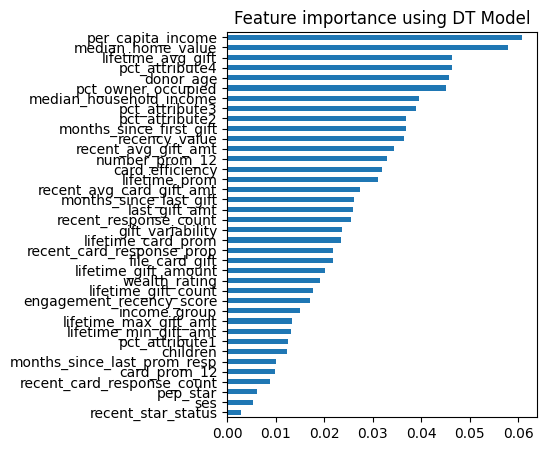

card_prom_12                   0.009845
children                       0.012416
donor_age                      0.045766
file_card_gift                 0.021703
income_group                   0.015006
last_gift_amt                  0.025968
lifetime_card_prom             0.023353
lifetime_gift_amount           0.020252
lifetime_gift_count            0.017700
lifetime_max_gift_amt          0.013398
lifetime_min_gift_amt          0.013139
lifetime_prom                  0.031002
median_home_value              0.057934
median_household_income        0.039462
months_since_first_gift        0.036753
months_since_last_gift         0.026124
months_since_last_prom_resp    0.010017
number_prom_12                 0.032927
pct_attribute1                 0.012611
pct_attribute2                 0.036789
pct_attribute3                 0.038996
pct_attribute4                 0.046294
pct_owner_occupied             0.045045
pep_star                       0.006204
per_capita_income              0.060844


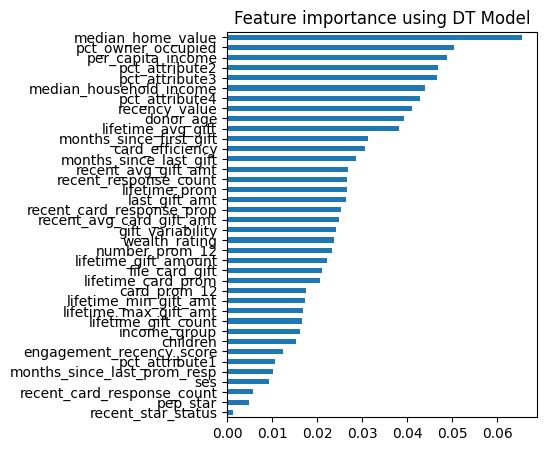

card_prom_12                   0.017476
children                       0.015199
donor_age                      0.039388
file_card_gift                 0.020958
income_group                   0.016244
last_gift_amt                  0.026354
lifetime_card_prom             0.020622
lifetime_gift_amount           0.022225
lifetime_gift_count            0.016571
lifetime_max_gift_amt          0.016740
lifetime_min_gift_amt          0.017309
lifetime_prom                  0.026711
median_home_value              0.065615
median_household_income        0.043993
months_since_first_gift        0.031262
months_since_last_gift         0.028723
months_since_last_prom_resp    0.010135
number_prom_12                 0.023343
pct_attribute1                 0.010568
pct_attribute2                 0.046762
pct_attribute3                 0.046588
pct_attribute4                 0.042734
pct_owner_occupied             0.050430
pep_star                       0.004858
per_capita_income              0.048955


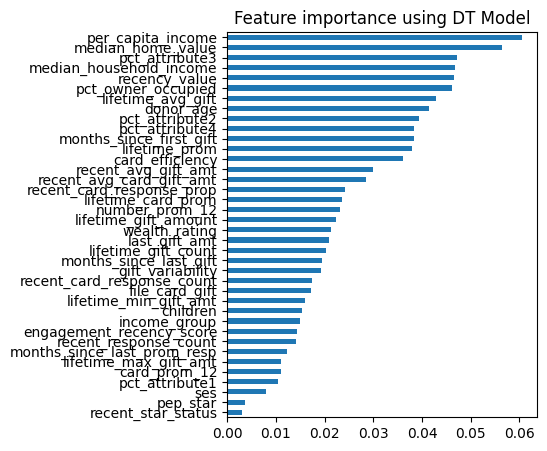

card_prom_12                   0.010955
children                       0.015400
donor_age                      0.041497
file_card_gift                 0.017302
income_group                   0.014921
last_gift_amt                  0.020848
lifetime_card_prom             0.023501
lifetime_gift_amount           0.022267
lifetime_gift_count            0.020225
lifetime_max_gift_amt          0.011040
lifetime_min_gift_amt          0.016043
lifetime_prom                  0.038015
median_home_value              0.056504
median_household_income        0.046852
months_since_first_gift        0.038398
months_since_last_gift         0.019394
months_since_last_prom_resp    0.012266
number_prom_12                 0.023199
pct_attribute1                 0.010431
pct_attribute2                 0.039337
pct_attribute3                 0.047158
pct_attribute4                 0.038419
pct_owner_occupied             0.046118
pep_star                       0.003622
per_capita_income              0.060633


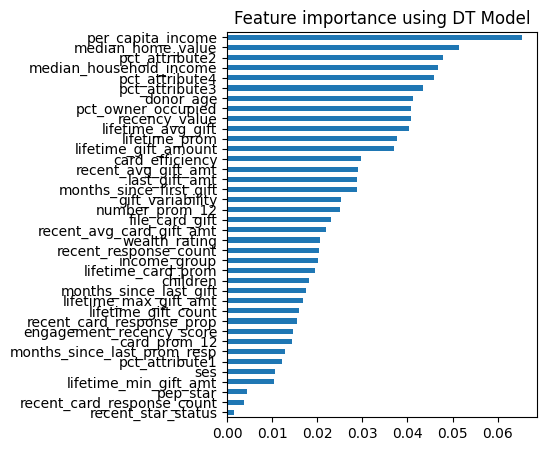

card_prom_12                   0.014486
children                       0.018066
donor_age                      0.041333
file_card_gift                 0.023054
income_group                   0.020147
last_gift_amt                  0.028839
lifetime_card_prom             0.019413
lifetime_gift_amount           0.037100
lifetime_gift_count            0.016016
lifetime_max_gift_amt          0.016754
lifetime_min_gift_amt          0.010319
lifetime_prom                  0.037589
median_home_value              0.051472
median_household_income        0.046836
months_since_first_gift        0.028822
months_since_last_gift         0.017558
months_since_last_prom_resp    0.012892
number_prom_12                 0.025039
pct_attribute1                 0.012078
pct_attribute2                 0.047824
pct_attribute3                 0.043559
pct_attribute4                 0.045952
pct_owner_occupied             0.040880
pep_star                       0.004359
per_capita_income              0.065524


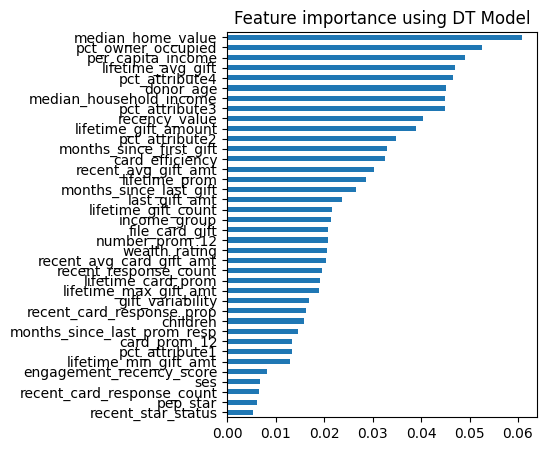

card_prom_12                   0.013423
children                       0.015842
donor_age                      0.045194
file_card_gift                 0.020880
income_group                   0.021483
last_gift_amt                  0.023608
lifetime_card_prom             0.019146
lifetime_gift_amount           0.038927
lifetime_gift_count            0.021620
lifetime_max_gift_amt          0.018896
lifetime_min_gift_amt          0.013054
lifetime_prom                  0.028568
median_home_value              0.060927
median_household_income        0.044926
months_since_first_gift        0.032922
months_since_last_gift         0.026536
months_since_last_prom_resp    0.014621
number_prom_12                 0.020859
pct_attribute1                 0.013389
pct_attribute2                 0.034918
pct_attribute3                 0.044854
pct_attribute4                 0.046678
pct_owner_occupied             0.052628
pep_star                       0.006097
per_capita_income              0.049155


In [131]:
select_best_features_dt(X, y)

* **Group 1:** lifetime_prom, lifetime_card_prom, months_since_first_gift, lifetime_gift_amount, file_card_gift, lifetime_gift_count and recency_value

* **Group 2:** recent_avg_gift_amt, last_gift_amt, lifetime_max_gift_amt and lifetime_avg_gift

* **Group 3:** recent_card_response_count and recent_card_response_prop

* **Group 4:** months_since_last_prom_resp and engagement_recency_score

From the groups we now eliminate those that carry less value to the model:
- recent_avg_gift_amt
- last_gift_amt
- lifetime_max_gift_amt
- lifetime_prom
- lifetime_card_prom
- months_since_first_gift
- lifetime_gift_amount
- file_card_gift
- lifetime_gift_count
- recent_card_response_prop
- months_since_last_prom_resp

In [132]:
X = X.drop(['recent_avg_gift_amt',
'last_gift_amt',
'lifetime_max_gift_amt',
'lifetime_prom' ,
'lifetime_card_prom' ,
'months_since_first_gift' ,
'lifetime_gift_amount' ,
'file_card_gift' ,
'lifetime_gift_count',
'recent_card_response_prop',
'months_since_last_prom_resp'], axis = 1)

#### Hybrid selection (RFE, LassoCV and DT)

To finalize our variable selection, we combine multiple algorithmic strategies and by cross-referencing their outputs, we select a highly stable subset of predictors.
This section defines the core modeling wrappers and the final execution pipeline:
* `apply_rfe(X_train, y_train, est)`: Implements a Wrapper method. It recursively prunes features using an external estimator, forcing the selection of the top 5 most critical features (n_features_to_select=5);

* `apply_lasso(X_train, y_train)`: Implements an Embedded regularization method. It utilizes LassoCV to apply an $L_1$ penalty, automatically driving the coefficients of non-essential, redundant, or noisy features directly to zero;

* `select_best_features(X, y, pred_module)`: Executes the cross-validation loop and applies MinMaxScaler data scaling strictly inside each split to guarantee that validation data statistics do not leak into the training stage.

In every fold, it sequentially runs RFE, Lasso, and Decision Trees, tracking their consensus.

In [133]:
def apply_rfe(X_train, y_train, est):
  rfe = RFE(estimator = est, n_features_to_select = 5)
  rfe.fit_transform(X = X_train, y = y_train)
  selected_features = pd.Series(rfe.support_, index = X_train.columns)
  print(selected_features)
  return selected_features

In [134]:
def apply_lasso(X_train, y_train):
  X_train = X_train.drop(['pep_star','recent_star_status'], axis = 1) #,'no_response_flag'
  lasso = LassoCV().fit(X_train, y_train)
  coef = pd.Series(lasso.coef_, index = X_train.columns)
  plot_importance(coef,'Lasso')
  print(coef)
  return coef

In [135]:
def select_best_features(X, y, pred_module):
  count = 1
  # apply the skf
  for X_train, X_val, y_train, y_val in skf_splits(X, y):
      # scale the data
      numerical_data = X_train.drop(['urbanicity','recency_status_96nk'], axis = 1).copy()
      scaler = MinMaxScaler().fit(numerical_data)
      X_train_scaled = scaler.transform(numerical_data)
      X_train_scaled = pd.DataFrame(X_train_scaled, columns = numerical_data.columns)

      # select the features
      print('_________________________________________________________________________________________________\n')
      print('                                     SPLIT ' + str(count) + '                                    \n')

      # check which features to use using RFE
      print('')
      print('------------------ RFE ----------------------')
      apply_rfe(X_train_scaled, y_train, pred_module())
      # check which features to use using lasso
      print('')
      print('----------------- LASSO ----------------------')
      apply_lasso(X_train_scaled, y_train)

      # check which features to use using decision tree
      print('')
      print('------------------ DT -----------------------')
      apply_dt(X_train_scaled, y_train)

      count+=1

To ensure that our feature selection is robust and not biased toward a specific type of algorithm, we pass three distinct machine learning estimators through our ensemble pipeline: LogisticRegression, RandomForestClassifier, and GradientBoostingClassifier.

This multi-model validation allows us to analyze how feature importance shifts across different algorithms:

* `Linear Models (LogisticRegression)`: Assumes linearity and evaluates features based on their direct, monotonic relationship with the target.

* `Tree-Based Models (RandomForest & GradientBoosting)`: Capture non-linear relationships, feature interactions, and structural thresholds.

A feature will be considered highly robust if it maintains a high consensus rank across all three models. Variables that only perform well in a single algorithm will be treated with caution, as they might indicate model-specific overfitting rather than true generalizable predictive power.

##### RandomForestClassifier

_________________________________________________________________________________________________

                                     SPLIT 1                                    


------------------ RFE ----------------------
card_prom_12                  False
children                      False
donor_age                     False
frequency_status_97nk         False
income_group                  False
lifetime_min_gift_amt         False
median_home_value              True
median_household_income        True
months_since_last_gift        False
number_prom_12                False
pct_attribute1                False
pct_attribute2                False
pct_attribute3                False
pct_attribute4                False
pct_owner_occupied            False
pep_star                      False
per_capita_income              True
recent_avg_card_gift_amt      False
recent_card_response_count    False
recent_response_count         False
recent_star_status            False
ses             

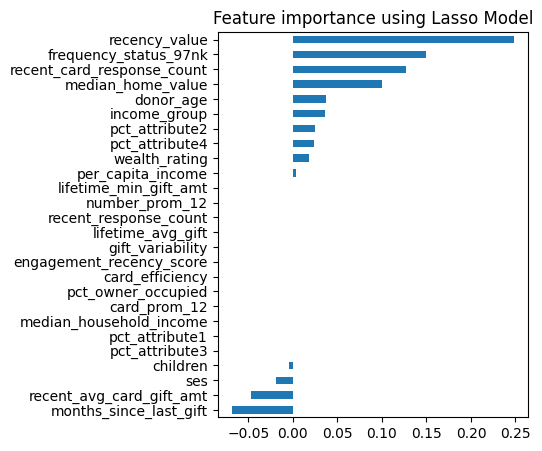

card_prom_12                 -0.000000
children                     -0.004628
donor_age                     0.037515
frequency_status_97nk         0.149208
income_group                  0.036094
lifetime_min_gift_amt        -0.000000
median_home_value             0.099662
median_household_income      -0.000000
months_since_last_gift       -0.068349
number_prom_12                0.000000
pct_attribute1                0.000000
pct_attribute2                0.024785
pct_attribute3               -0.000000
pct_attribute4                0.023612
pct_owner_occupied            0.000000
per_capita_income             0.003518
recent_avg_card_gift_amt     -0.046268
recent_card_response_count    0.127666
recent_response_count         0.000000
ses                          -0.018587
wealth_rating                 0.018584
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.247904
engagement_recency_score      0.000000
card_efficiency          

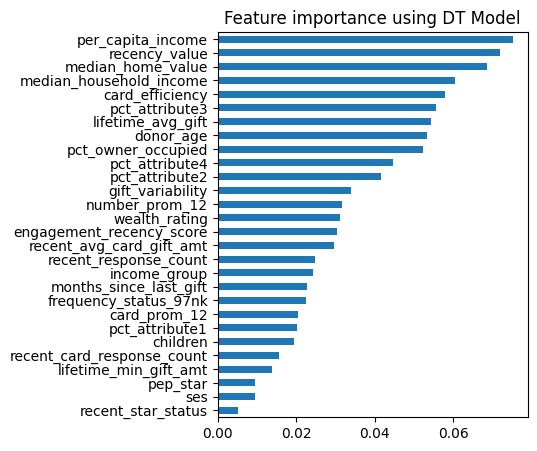

card_prom_12                  0.020473
children                      0.019512
donor_age                     0.053227
frequency_status_97nk         0.022429
income_group                  0.024356
lifetime_min_gift_amt         0.013738
median_home_value             0.068689
median_household_income       0.060382
months_since_last_gift        0.022674
number_prom_12                0.031524
pct_attribute1                0.020199
pct_attribute2                0.041695
pct_attribute3                0.055599
pct_attribute4                0.044627
pct_owner_occupied            0.052268
pep_star                      0.009475
per_capita_income             0.075188
recent_avg_card_gift_amt      0.029522
recent_card_response_count    0.015507
recent_response_count         0.024777
recent_star_status            0.005131
ses                           0.009410
wealth_rating                 0.031075
lifetime_avg_gift             0.054432
gift_variability              0.034021
recency_value            

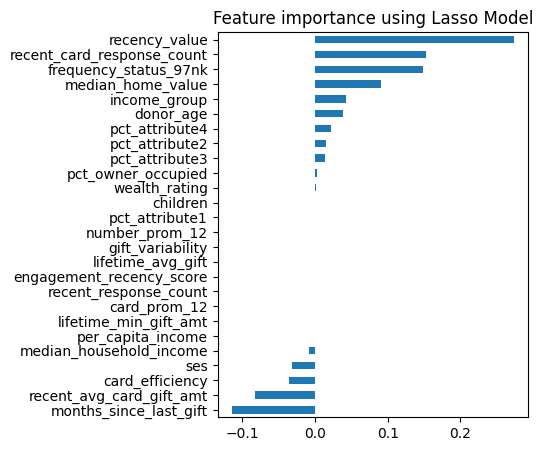

card_prom_12                 -0.000000
children                     -0.000000
donor_age                     0.039200
frequency_status_97nk         0.148718
income_group                  0.042527
lifetime_min_gift_amt        -0.000000
median_home_value             0.090300
median_household_income      -0.007675
months_since_last_gift       -0.114045
number_prom_12                0.000000
pct_attribute1                0.000000
pct_attribute2                0.014731
pct_attribute3                0.013608
pct_attribute4                0.021530
pct_owner_occupied            0.002858
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.082118
recent_card_response_count    0.152369
recent_response_count         0.000000
ses                          -0.031921
wealth_rating                 0.001818
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.273025
engagement_recency_score      0.000000
card_efficiency          

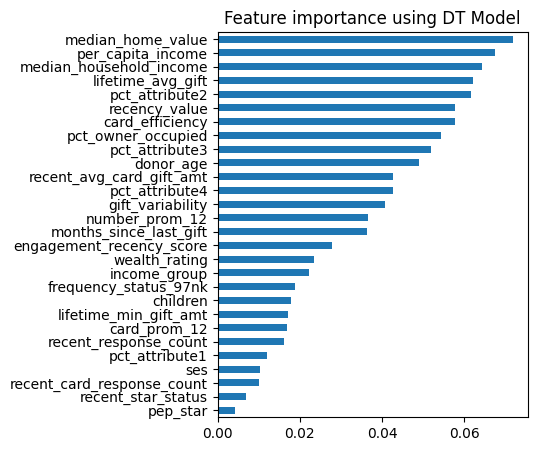

card_prom_12                  0.016831
children                      0.017754
donor_age                     0.048846
frequency_status_97nk         0.018710
income_group                  0.022161
lifetime_min_gift_amt         0.017078
median_home_value             0.071825
median_household_income       0.064336
months_since_last_gift        0.036355
number_prom_12                0.036583
pct_attribute1                0.011986
pct_attribute2                0.061626
pct_attribute3                0.051849
pct_attribute4                0.042526
pct_owner_occupied            0.054227
pep_star                      0.004185
per_capita_income             0.067361
recent_avg_card_gift_amt      0.042639
recent_card_response_count    0.010095
recent_response_count         0.016220
recent_star_status            0.006915
ses                           0.010338
wealth_rating                 0.023433
lifetime_avg_gift             0.062107
gift_variability              0.040789
recency_value            

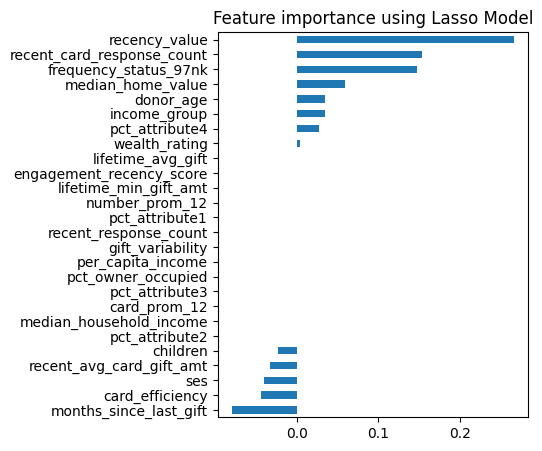

card_prom_12                 -0.000000
children                     -0.022188
donor_age                     0.035058
frequency_status_97nk         0.147847
income_group                  0.034858
lifetime_min_gift_amt        -0.000000
median_home_value             0.059819
median_household_income      -0.000000
months_since_last_gift       -0.079337
number_prom_12                0.000000
pct_attribute1               -0.000000
pct_attribute2                0.000000
pct_attribute3               -0.000000
pct_attribute4                0.027470
pct_owner_occupied           -0.000000
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.033021
recent_card_response_count    0.153032
recent_response_count        -0.000000
ses                          -0.039629
wealth_rating                 0.004228
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.265681
engagement_recency_score      0.000000
card_efficiency          

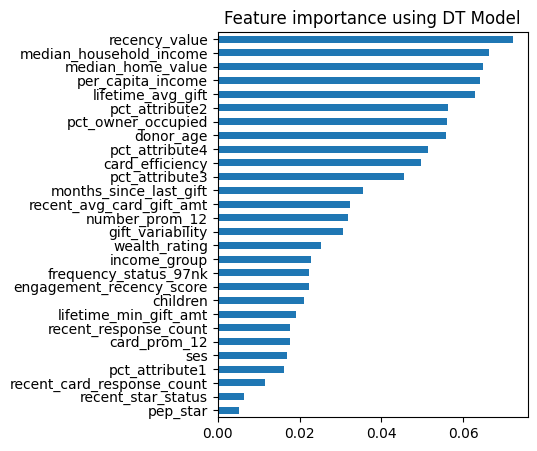

card_prom_12                  0.017608
children                      0.021003
donor_age                     0.055723
frequency_status_97nk         0.022412
income_group                  0.022791
lifetime_min_gift_amt         0.019218
median_home_value             0.064712
median_household_income       0.066387
months_since_last_gift        0.035591
number_prom_12                0.031734
pct_attribute1                0.016302
pct_attribute2                0.056256
pct_attribute3                0.045611
pct_attribute4                0.051351
pct_owner_occupied            0.056114
pep_star                      0.005251
per_capita_income             0.064196
recent_avg_card_gift_amt      0.032353
recent_card_response_count    0.011529
recent_response_count         0.017692
recent_star_status            0.006466
ses                           0.016813
wealth_rating                 0.025280
lifetime_avg_gift             0.062806
gift_variability              0.030618
recency_value            

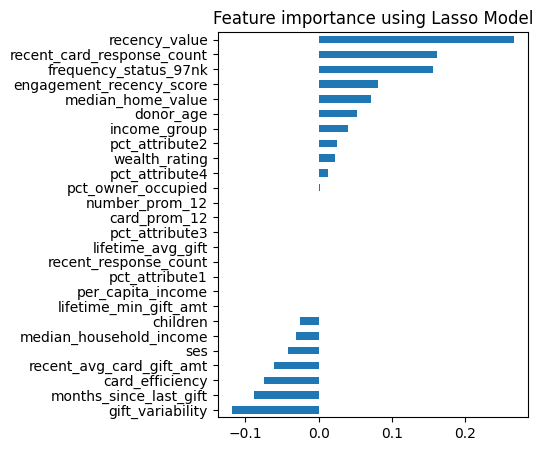

card_prom_12                 -0.000000
children                     -0.024882
donor_age                     0.052749
frequency_status_97nk         0.155285
income_group                  0.040421
lifetime_min_gift_amt        -0.000000
median_home_value             0.070739
median_household_income      -0.030438
months_since_last_gift       -0.087860
number_prom_12                0.000000
pct_attribute1               -0.000000
pct_attribute2                0.025333
pct_attribute3               -0.000000
pct_attribute4                0.013223
pct_owner_occupied            0.001327
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.060519
recent_card_response_count    0.161865
recent_response_count        -0.000000
ses                          -0.042043
wealth_rating                 0.022469
lifetime_avg_gift            -0.000000
gift_variability             -0.118340
recency_value                 0.265851
engagement_recency_score      0.081500
card_efficiency          

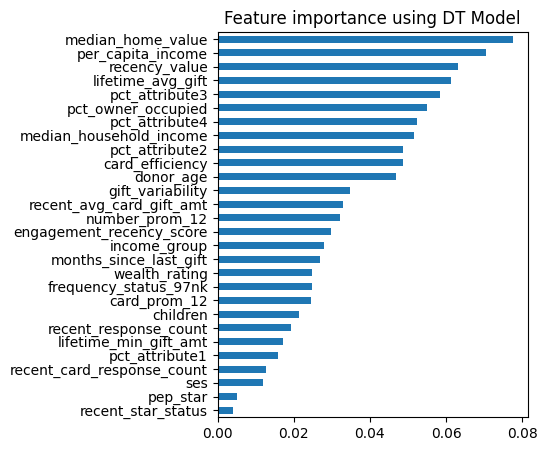

card_prom_12                  0.024431
children                      0.021316
donor_age                     0.046802
frequency_status_97nk         0.024765
income_group                  0.028016
lifetime_min_gift_amt         0.017285
median_home_value             0.077587
median_household_income       0.051654
months_since_last_gift        0.026964
number_prom_12                0.032231
pct_attribute1                0.015929
pct_attribute2                0.048706
pct_attribute3                0.058395
pct_attribute4                0.052332
pct_owner_occupied            0.054983
pep_star                      0.005035
per_capita_income             0.070580
recent_avg_card_gift_amt      0.032905
recent_card_response_count    0.012672
recent_response_count         0.019128
recent_star_status            0.004075
ses                           0.011865
wealth_rating                 0.024776
lifetime_avg_gift             0.061322
gift_variability              0.034662
recency_value            

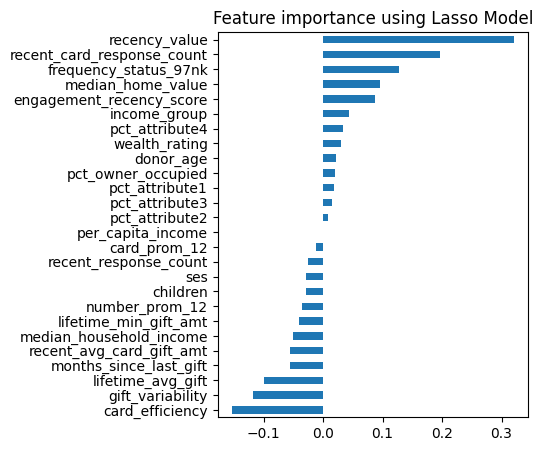

card_prom_12                 -0.012711
children                     -0.028661
donor_age                     0.021725
frequency_status_97nk         0.127876
income_group                  0.043924
lifetime_min_gift_amt        -0.039975
median_home_value             0.096249
median_household_income      -0.050089
months_since_last_gift       -0.055900
number_prom_12               -0.035841
pct_attribute1                0.017975
pct_attribute2                0.008110
pct_attribute3                0.014661
pct_attribute4                0.033444
pct_owner_occupied            0.019989
per_capita_income            -0.000000
recent_avg_card_gift_amt     -0.055821
recent_card_response_count    0.197240
recent_response_count        -0.025643
ses                          -0.028284
wealth_rating                 0.029823
lifetime_avg_gift            -0.100237
gift_variability             -0.118651
recency_value                 0.320301
engagement_recency_score      0.087390
card_efficiency          

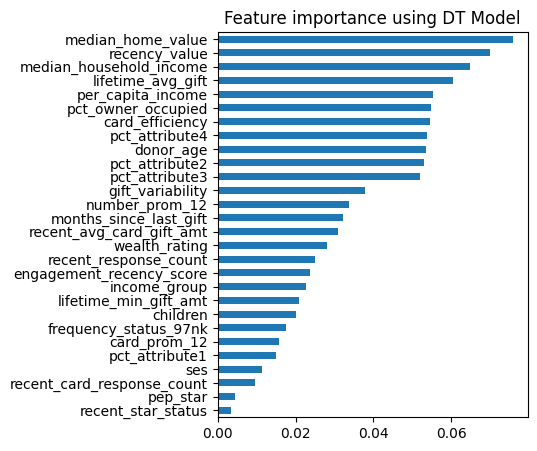

card_prom_12                  0.015616
children                      0.020091
donor_age                     0.053572
frequency_status_97nk         0.017566
income_group                  0.022635
lifetime_min_gift_amt         0.020958
median_home_value             0.075843
median_household_income       0.064794
months_since_last_gift        0.032255
number_prom_12                0.033617
pct_attribute1                0.015008
pct_attribute2                0.052996
pct_attribute3                0.051864
pct_attribute4                0.053693
pct_owner_occupied            0.054871
pep_star                      0.004393
per_capita_income             0.055388
recent_avg_card_gift_amt      0.031011
recent_card_response_count    0.009542
recent_response_count         0.025006
recent_star_status            0.003410
ses                           0.011439
wealth_rating                 0.028130
lifetime_avg_gift             0.060324
gift_variability              0.037888
recency_value            

In [136]:
select_best_features(X, y, RandomForestClassifier)

##### Logistic Regression

_________________________________________________________________________________________________

                                     SPLIT 1                                    


------------------ RFE ----------------------
card_prom_12                  False
children                      False
donor_age                     False
frequency_status_97nk          True
income_group                  False
lifetime_min_gift_amt         False
median_home_value             False
median_household_income       False
months_since_last_gift        False
number_prom_12                False
pct_attribute1                False
pct_attribute2                False
pct_attribute3                False
pct_attribute4                False
pct_owner_occupied            False
pep_star                      False
per_capita_income              True
recent_avg_card_gift_amt      False
recent_card_response_count    False
recent_response_count         False
recent_star_status            False
ses             

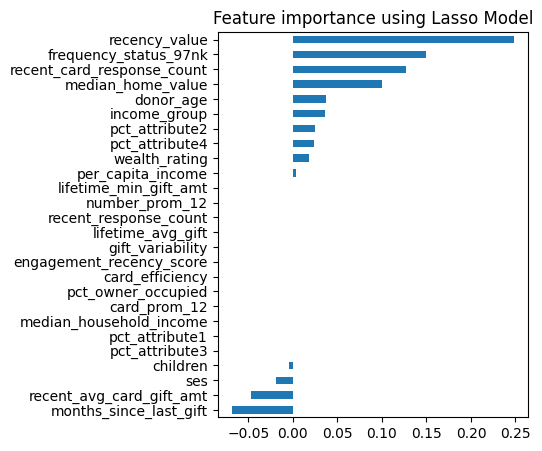

card_prom_12                 -0.000000
children                     -0.004628
donor_age                     0.037515
frequency_status_97nk         0.149208
income_group                  0.036094
lifetime_min_gift_amt        -0.000000
median_home_value             0.099662
median_household_income      -0.000000
months_since_last_gift       -0.068349
number_prom_12                0.000000
pct_attribute1                0.000000
pct_attribute2                0.024785
pct_attribute3               -0.000000
pct_attribute4                0.023612
pct_owner_occupied            0.000000
per_capita_income             0.003518
recent_avg_card_gift_amt     -0.046268
recent_card_response_count    0.127666
recent_response_count         0.000000
ses                          -0.018587
wealth_rating                 0.018584
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.247904
engagement_recency_score      0.000000
card_efficiency          

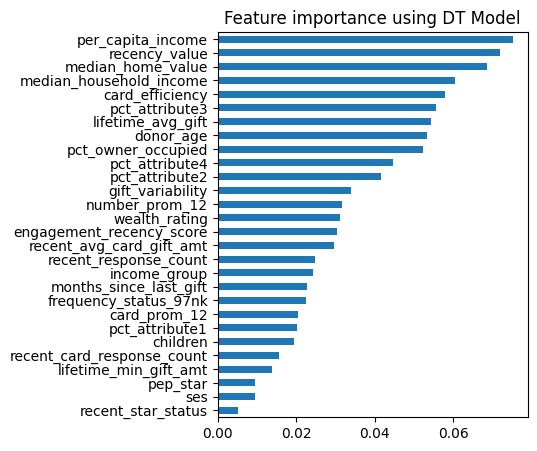

card_prom_12                  0.020473
children                      0.019512
donor_age                     0.053227
frequency_status_97nk         0.022429
income_group                  0.024356
lifetime_min_gift_amt         0.013738
median_home_value             0.068689
median_household_income       0.060382
months_since_last_gift        0.022674
number_prom_12                0.031524
pct_attribute1                0.020199
pct_attribute2                0.041695
pct_attribute3                0.055599
pct_attribute4                0.044627
pct_owner_occupied            0.052268
pep_star                      0.009475
per_capita_income             0.075188
recent_avg_card_gift_amt      0.029522
recent_card_response_count    0.015507
recent_response_count         0.024777
recent_star_status            0.005131
ses                           0.009410
wealth_rating                 0.031075
lifetime_avg_gift             0.054432
gift_variability              0.034021
recency_value            

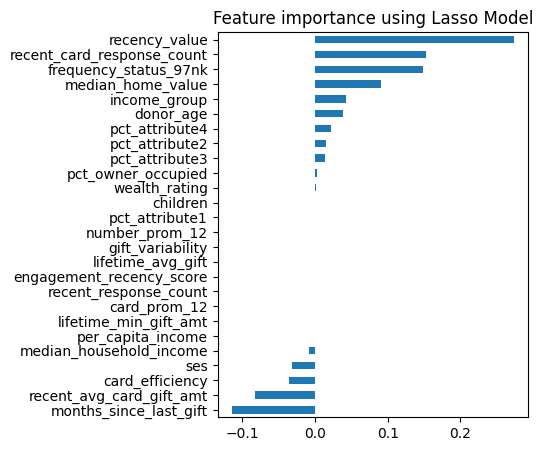

card_prom_12                 -0.000000
children                     -0.000000
donor_age                     0.039200
frequency_status_97nk         0.148718
income_group                  0.042527
lifetime_min_gift_amt        -0.000000
median_home_value             0.090300
median_household_income      -0.007675
months_since_last_gift       -0.114045
number_prom_12                0.000000
pct_attribute1                0.000000
pct_attribute2                0.014731
pct_attribute3                0.013608
pct_attribute4                0.021530
pct_owner_occupied            0.002858
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.082118
recent_card_response_count    0.152369
recent_response_count         0.000000
ses                          -0.031921
wealth_rating                 0.001818
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.273025
engagement_recency_score      0.000000
card_efficiency          

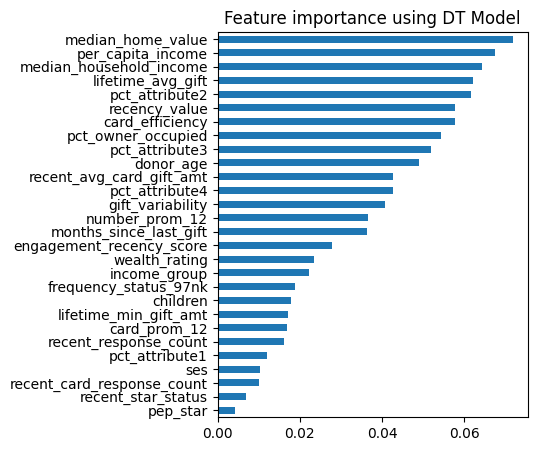

card_prom_12                  0.016831
children                      0.017754
donor_age                     0.048846
frequency_status_97nk         0.018710
income_group                  0.022161
lifetime_min_gift_amt         0.017078
median_home_value             0.071825
median_household_income       0.064336
months_since_last_gift        0.036355
number_prom_12                0.036583
pct_attribute1                0.011986
pct_attribute2                0.061626
pct_attribute3                0.051849
pct_attribute4                0.042526
pct_owner_occupied            0.054227
pep_star                      0.004185
per_capita_income             0.067361
recent_avg_card_gift_amt      0.042639
recent_card_response_count    0.010095
recent_response_count         0.016220
recent_star_status            0.006915
ses                           0.010338
wealth_rating                 0.023433
lifetime_avg_gift             0.062107
gift_variability              0.040789
recency_value            

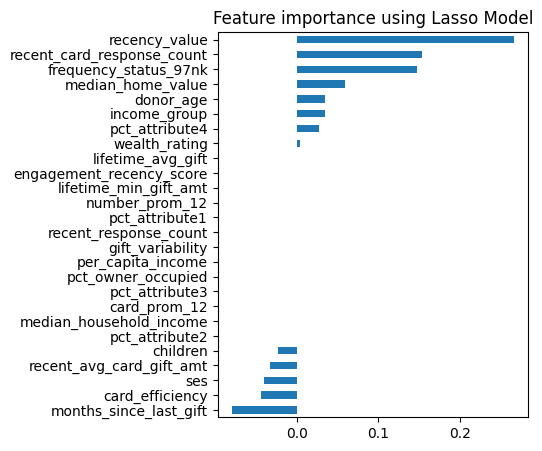

card_prom_12                 -0.000000
children                     -0.022188
donor_age                     0.035058
frequency_status_97nk         0.147847
income_group                  0.034858
lifetime_min_gift_amt        -0.000000
median_home_value             0.059819
median_household_income      -0.000000
months_since_last_gift       -0.079337
number_prom_12                0.000000
pct_attribute1               -0.000000
pct_attribute2                0.000000
pct_attribute3               -0.000000
pct_attribute4                0.027470
pct_owner_occupied           -0.000000
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.033021
recent_card_response_count    0.153032
recent_response_count        -0.000000
ses                          -0.039629
wealth_rating                 0.004228
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.265681
engagement_recency_score      0.000000
card_efficiency          

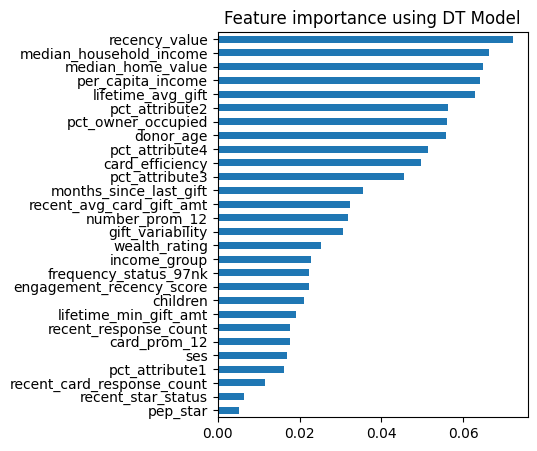

card_prom_12                  0.017608
children                      0.021003
donor_age                     0.055723
frequency_status_97nk         0.022412
income_group                  0.022791
lifetime_min_gift_amt         0.019218
median_home_value             0.064712
median_household_income       0.066387
months_since_last_gift        0.035591
number_prom_12                0.031734
pct_attribute1                0.016302
pct_attribute2                0.056256
pct_attribute3                0.045611
pct_attribute4                0.051351
pct_owner_occupied            0.056114
pep_star                      0.005251
per_capita_income             0.064196
recent_avg_card_gift_amt      0.032353
recent_card_response_count    0.011529
recent_response_count         0.017692
recent_star_status            0.006466
ses                           0.016813
wealth_rating                 0.025280
lifetime_avg_gift             0.062806
gift_variability              0.030618
recency_value            

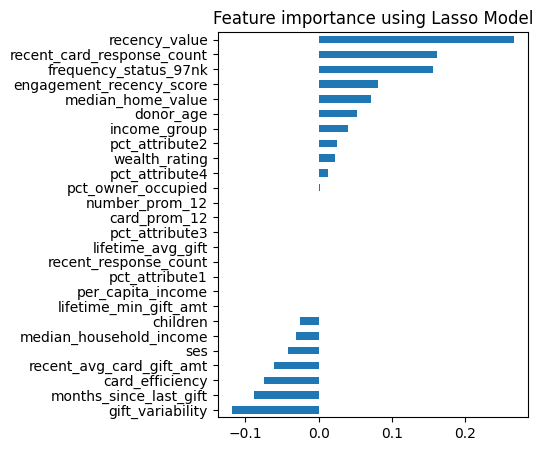

card_prom_12                 -0.000000
children                     -0.024882
donor_age                     0.052749
frequency_status_97nk         0.155285
income_group                  0.040421
lifetime_min_gift_amt        -0.000000
median_home_value             0.070739
median_household_income      -0.030438
months_since_last_gift       -0.087860
number_prom_12                0.000000
pct_attribute1               -0.000000
pct_attribute2                0.025333
pct_attribute3               -0.000000
pct_attribute4                0.013223
pct_owner_occupied            0.001327
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.060519
recent_card_response_count    0.161865
recent_response_count        -0.000000
ses                          -0.042043
wealth_rating                 0.022469
lifetime_avg_gift            -0.000000
gift_variability             -0.118340
recency_value                 0.265851
engagement_recency_score      0.081500
card_efficiency          

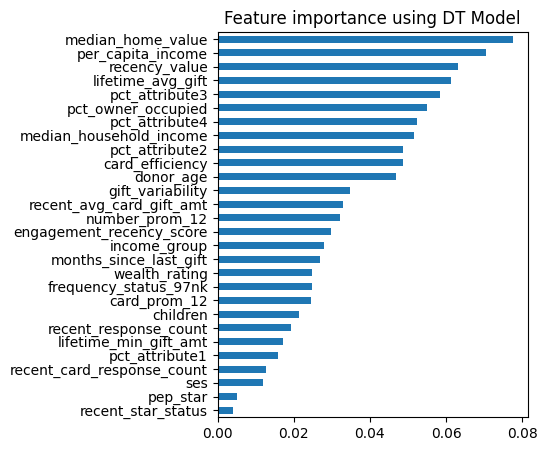

card_prom_12                  0.024431
children                      0.021316
donor_age                     0.046802
frequency_status_97nk         0.024765
income_group                  0.028016
lifetime_min_gift_amt         0.017285
median_home_value             0.077587
median_household_income       0.051654
months_since_last_gift        0.026964
number_prom_12                0.032231
pct_attribute1                0.015929
pct_attribute2                0.048706
pct_attribute3                0.058395
pct_attribute4                0.052332
pct_owner_occupied            0.054983
pep_star                      0.005035
per_capita_income             0.070580
recent_avg_card_gift_amt      0.032905
recent_card_response_count    0.012672
recent_response_count         0.019128
recent_star_status            0.004075
ses                           0.011865
wealth_rating                 0.024776
lifetime_avg_gift             0.061322
gift_variability              0.034662
recency_value            

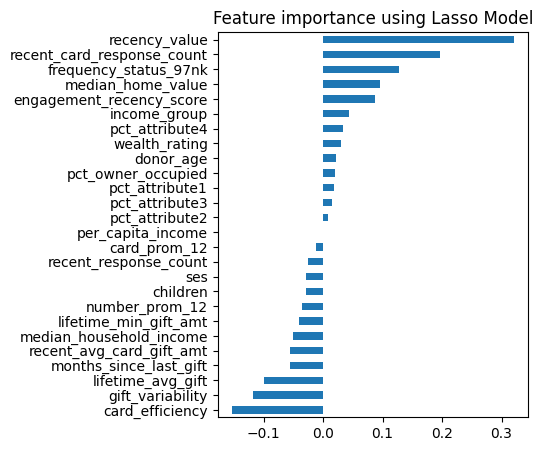

card_prom_12                 -0.012711
children                     -0.028661
donor_age                     0.021725
frequency_status_97nk         0.127876
income_group                  0.043924
lifetime_min_gift_amt        -0.039975
median_home_value             0.096249
median_household_income      -0.050089
months_since_last_gift       -0.055900
number_prom_12               -0.035841
pct_attribute1                0.017975
pct_attribute2                0.008110
pct_attribute3                0.014661
pct_attribute4                0.033444
pct_owner_occupied            0.019989
per_capita_income            -0.000000
recent_avg_card_gift_amt     -0.055821
recent_card_response_count    0.197240
recent_response_count        -0.025643
ses                          -0.028284
wealth_rating                 0.029823
lifetime_avg_gift            -0.100237
gift_variability             -0.118651
recency_value                 0.320301
engagement_recency_score      0.087390
card_efficiency          

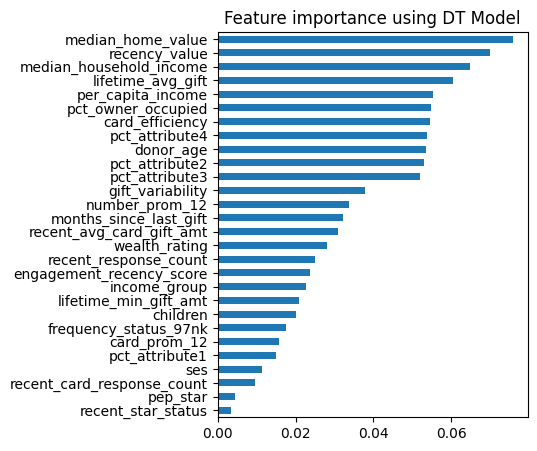

card_prom_12                  0.015616
children                      0.020091
donor_age                     0.053572
frequency_status_97nk         0.017566
income_group                  0.022635
lifetime_min_gift_amt         0.020958
median_home_value             0.075843
median_household_income       0.064794
months_since_last_gift        0.032255
number_prom_12                0.033617
pct_attribute1                0.015008
pct_attribute2                0.052996
pct_attribute3                0.051864
pct_attribute4                0.053693
pct_owner_occupied            0.054871
pep_star                      0.004393
per_capita_income             0.055388
recent_avg_card_gift_amt      0.031011
recent_card_response_count    0.009542
recent_response_count         0.025006
recent_star_status            0.003410
ses                           0.011439
wealth_rating                 0.028130
lifetime_avg_gift             0.060324
gift_variability              0.037888
recency_value            

In [137]:
select_best_features(X, y, LogisticRegression)

##### GradientBoostingClassifier

_________________________________________________________________________________________________

                                     SPLIT 1                                    


------------------ RFE ----------------------
card_prom_12                  False
children                      False
donor_age                     False
frequency_status_97nk          True
income_group                  False
lifetime_min_gift_amt         False
median_home_value              True
median_household_income       False
months_since_last_gift        False
number_prom_12                 True
pct_attribute1                False
pct_attribute2                False
pct_attribute3                False
pct_attribute4                False
pct_owner_occupied            False
pep_star                      False
per_capita_income             False
recent_avg_card_gift_amt      False
recent_card_response_count    False
recent_response_count         False
recent_star_status            False
ses             

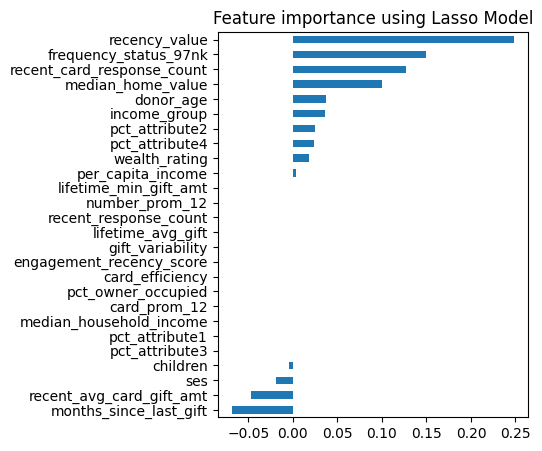

card_prom_12                 -0.000000
children                     -0.004628
donor_age                     0.037515
frequency_status_97nk         0.149208
income_group                  0.036094
lifetime_min_gift_amt        -0.000000
median_home_value             0.099662
median_household_income      -0.000000
months_since_last_gift       -0.068349
number_prom_12                0.000000
pct_attribute1                0.000000
pct_attribute2                0.024785
pct_attribute3               -0.000000
pct_attribute4                0.023612
pct_owner_occupied            0.000000
per_capita_income             0.003518
recent_avg_card_gift_amt     -0.046268
recent_card_response_count    0.127666
recent_response_count         0.000000
ses                          -0.018587
wealth_rating                 0.018584
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.247904
engagement_recency_score      0.000000
card_efficiency          

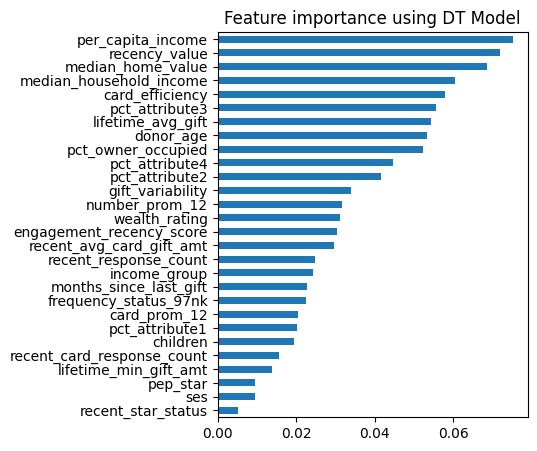

card_prom_12                  0.020473
children                      0.019512
donor_age                     0.053227
frequency_status_97nk         0.022429
income_group                  0.024356
lifetime_min_gift_amt         0.013738
median_home_value             0.068689
median_household_income       0.060382
months_since_last_gift        0.022674
number_prom_12                0.031524
pct_attribute1                0.020199
pct_attribute2                0.041695
pct_attribute3                0.055599
pct_attribute4                0.044627
pct_owner_occupied            0.052268
pep_star                      0.009475
per_capita_income             0.075188
recent_avg_card_gift_amt      0.029522
recent_card_response_count    0.015507
recent_response_count         0.024777
recent_star_status            0.005131
ses                           0.009410
wealth_rating                 0.031075
lifetime_avg_gift             0.054432
gift_variability              0.034021
recency_value            

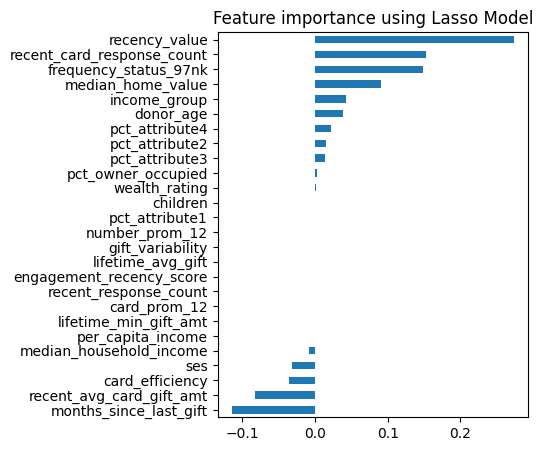

card_prom_12                 -0.000000
children                     -0.000000
donor_age                     0.039200
frequency_status_97nk         0.148718
income_group                  0.042527
lifetime_min_gift_amt        -0.000000
median_home_value             0.090300
median_household_income      -0.007675
months_since_last_gift       -0.114045
number_prom_12                0.000000
pct_attribute1                0.000000
pct_attribute2                0.014731
pct_attribute3                0.013608
pct_attribute4                0.021530
pct_owner_occupied            0.002858
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.082118
recent_card_response_count    0.152369
recent_response_count         0.000000
ses                          -0.031921
wealth_rating                 0.001818
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.273025
engagement_recency_score      0.000000
card_efficiency          

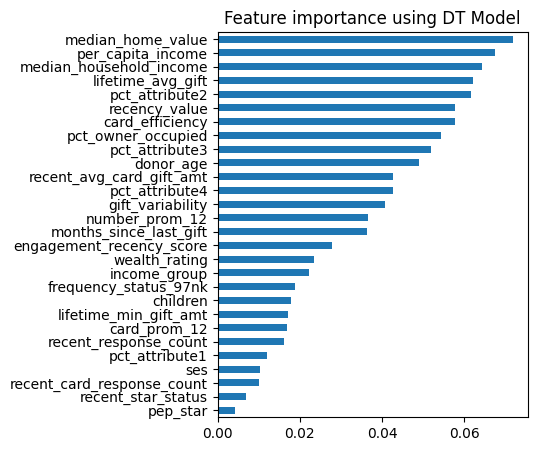

card_prom_12                  0.016831
children                      0.017754
donor_age                     0.048846
frequency_status_97nk         0.018710
income_group                  0.022161
lifetime_min_gift_amt         0.017078
median_home_value             0.071825
median_household_income       0.064336
months_since_last_gift        0.036355
number_prom_12                0.036583
pct_attribute1                0.011986
pct_attribute2                0.061626
pct_attribute3                0.051849
pct_attribute4                0.042526
pct_owner_occupied            0.054227
pep_star                      0.004185
per_capita_income             0.067361
recent_avg_card_gift_amt      0.042639
recent_card_response_count    0.010095
recent_response_count         0.016220
recent_star_status            0.006915
ses                           0.010338
wealth_rating                 0.023433
lifetime_avg_gift             0.062107
gift_variability              0.040789
recency_value            

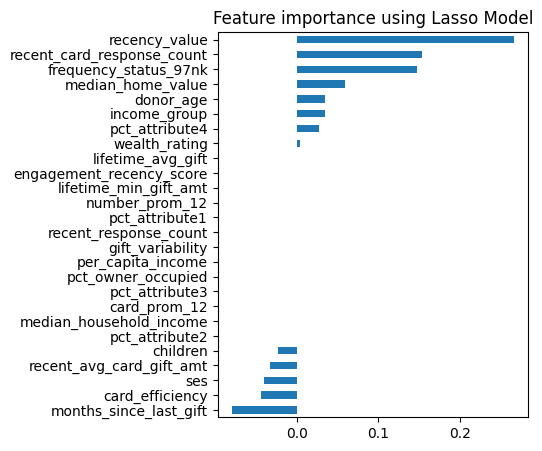

card_prom_12                 -0.000000
children                     -0.022188
donor_age                     0.035058
frequency_status_97nk         0.147847
income_group                  0.034858
lifetime_min_gift_amt        -0.000000
median_home_value             0.059819
median_household_income      -0.000000
months_since_last_gift       -0.079337
number_prom_12                0.000000
pct_attribute1               -0.000000
pct_attribute2                0.000000
pct_attribute3               -0.000000
pct_attribute4                0.027470
pct_owner_occupied           -0.000000
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.033021
recent_card_response_count    0.153032
recent_response_count        -0.000000
ses                          -0.039629
wealth_rating                 0.004228
lifetime_avg_gift            -0.000000
gift_variability             -0.000000
recency_value                 0.265681
engagement_recency_score      0.000000
card_efficiency          

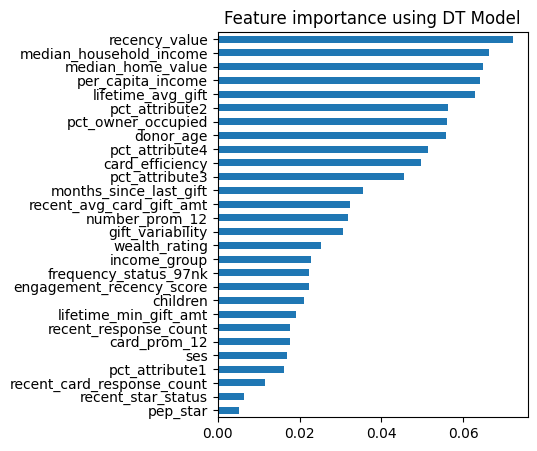

card_prom_12                  0.017608
children                      0.021003
donor_age                     0.055723
frequency_status_97nk         0.022412
income_group                  0.022791
lifetime_min_gift_amt         0.019218
median_home_value             0.064712
median_household_income       0.066387
months_since_last_gift        0.035591
number_prom_12                0.031734
pct_attribute1                0.016302
pct_attribute2                0.056256
pct_attribute3                0.045611
pct_attribute4                0.051351
pct_owner_occupied            0.056114
pep_star                      0.005251
per_capita_income             0.064196
recent_avg_card_gift_amt      0.032353
recent_card_response_count    0.011529
recent_response_count         0.017692
recent_star_status            0.006466
ses                           0.016813
wealth_rating                 0.025280
lifetime_avg_gift             0.062806
gift_variability              0.030618
recency_value            

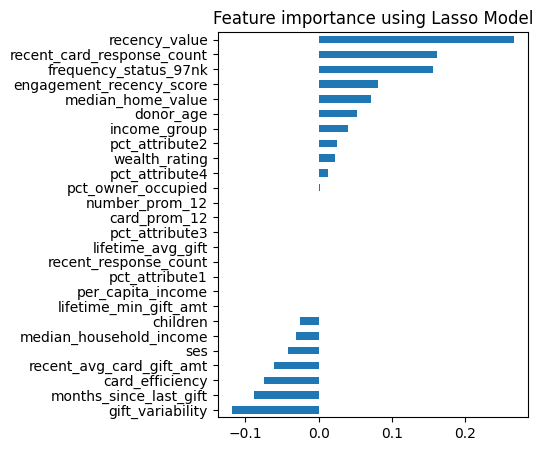

card_prom_12                 -0.000000
children                     -0.024882
donor_age                     0.052749
frequency_status_97nk         0.155285
income_group                  0.040421
lifetime_min_gift_amt        -0.000000
median_home_value             0.070739
median_household_income      -0.030438
months_since_last_gift       -0.087860
number_prom_12                0.000000
pct_attribute1               -0.000000
pct_attribute2                0.025333
pct_attribute3               -0.000000
pct_attribute4                0.013223
pct_owner_occupied            0.001327
per_capita_income             0.000000
recent_avg_card_gift_amt     -0.060519
recent_card_response_count    0.161865
recent_response_count        -0.000000
ses                          -0.042043
wealth_rating                 0.022469
lifetime_avg_gift            -0.000000
gift_variability             -0.118340
recency_value                 0.265851
engagement_recency_score      0.081500
card_efficiency          

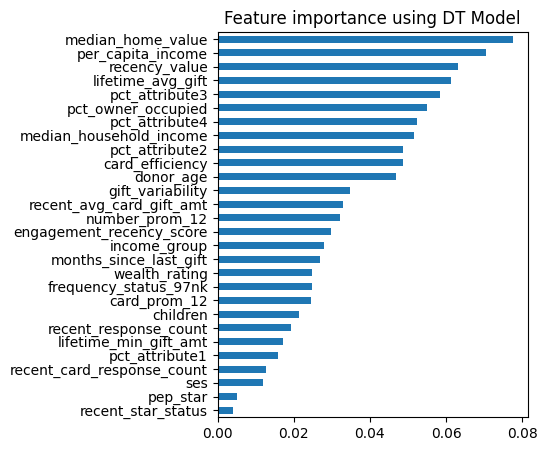

card_prom_12                  0.024431
children                      0.021316
donor_age                     0.046802
frequency_status_97nk         0.024765
income_group                  0.028016
lifetime_min_gift_amt         0.017285
median_home_value             0.077587
median_household_income       0.051654
months_since_last_gift        0.026964
number_prom_12                0.032231
pct_attribute1                0.015929
pct_attribute2                0.048706
pct_attribute3                0.058395
pct_attribute4                0.052332
pct_owner_occupied            0.054983
pep_star                      0.005035
per_capita_income             0.070580
recent_avg_card_gift_amt      0.032905
recent_card_response_count    0.012672
recent_response_count         0.019128
recent_star_status            0.004075
ses                           0.011865
wealth_rating                 0.024776
lifetime_avg_gift             0.061322
gift_variability              0.034662
recency_value            

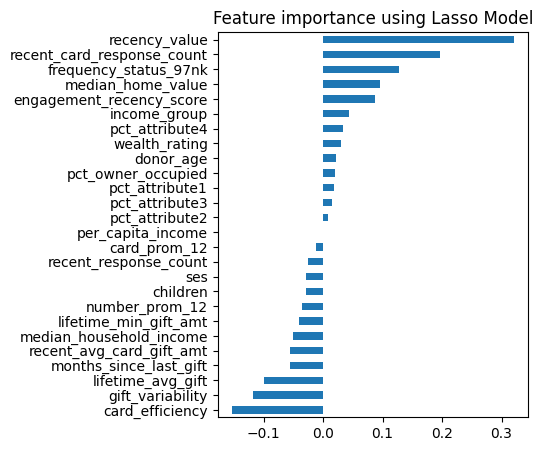

card_prom_12                 -0.012711
children                     -0.028661
donor_age                     0.021725
frequency_status_97nk         0.127876
income_group                  0.043924
lifetime_min_gift_amt        -0.039975
median_home_value             0.096249
median_household_income      -0.050089
months_since_last_gift       -0.055900
number_prom_12               -0.035841
pct_attribute1                0.017975
pct_attribute2                0.008110
pct_attribute3                0.014661
pct_attribute4                0.033444
pct_owner_occupied            0.019989
per_capita_income            -0.000000
recent_avg_card_gift_amt     -0.055821
recent_card_response_count    0.197240
recent_response_count        -0.025643
ses                          -0.028284
wealth_rating                 0.029823
lifetime_avg_gift            -0.100237
gift_variability             -0.118651
recency_value                 0.320301
engagement_recency_score      0.087390
card_efficiency          

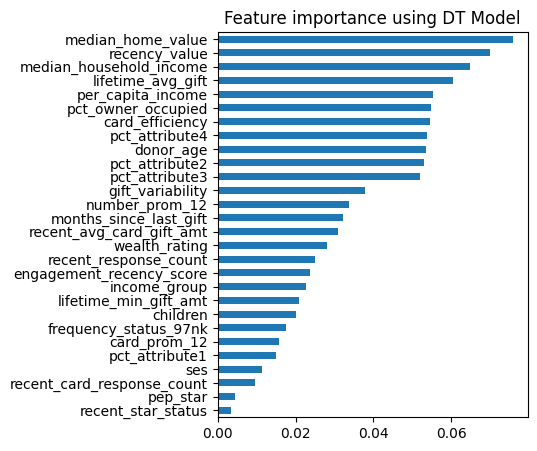

card_prom_12                  0.015616
children                      0.020091
donor_age                     0.053572
frequency_status_97nk         0.017566
income_group                  0.022635
lifetime_min_gift_amt         0.020958
median_home_value             0.075843
median_household_income       0.064794
months_since_last_gift        0.032255
number_prom_12                0.033617
pct_attribute1                0.015008
pct_attribute2                0.052996
pct_attribute3                0.051864
pct_attribute4                0.053693
pct_owner_occupied            0.054871
pep_star                      0.004393
per_capita_income             0.055388
recent_avg_card_gift_amt      0.031011
recent_card_response_count    0.009542
recent_response_count         0.025006
recent_star_status            0.003410
ses                           0.011439
wealth_rating                 0.028130
lifetime_avg_gift             0.060324
gift_variability              0.037888
recency_value            

In [138]:
select_best_features(X, y, GradientBoostingClassifier)

##### Final machine learning estimators decision

| Predictor                  | RFE1  | RFE2  | RFE3  | Final RFE |
| ---                        | ---   | ---   | ---   | ---       |
| donor_gender               | X     | X     | X     | X         |
| home_owner                 | X     | X     | X     | X         |
| urbanicity                 | X     | X     | X     | X         |
| recency_status_96nk        | X     | X     | X     | X         |
| no_response_flag           | X     | X     | X     | X         |
| recent_response_prop       | X     | X     | X     | X         |
| donation_freq              | X     | X     | X     | X         |
| card_preference            | X     | X     | X     | X         |
| response_intensity         | X     | X     | X     | X         |
| recent_avg_gift_amt        | X     | X     | X     | X         |
| recent_card_response_prop  | X     | X     | X     | X         |
| file_card_gift             | X     | X     | X     | X         |
| lifetime_card_prom         | X     | X     | X     | X         |
| lifetime_prom              | X     | X     | X     | X         |
| months_since_last_prom_resp| X     | X     | X     | X         |
| lifetime_gift_amount       | X     | X     | X     | X         |
| lifetime_gift_count        | X     | X     | X     | X         |
| lifetime_max_gift_amt      | X     | X     | X     | X         |
| last_gift_amt              | X     | X     | X     | X         |
| months_since_first_gift    | X     | X     | X     | X         |
| ses                        | 0 YES | 0 YES | 0 YES | No        |
| income_group               | 0 YES | 0 YES | 0 YES | No        |
| wealth_rating              | 0 YES | 0 YES | 0 YES | No        |
| pep_star                   | 0 YES | 0 YES | 0 YES | No        |
| recent_star_status         | 0 YES | 0 YES | 0 YES | No        |
| donor_age                  | 0 YES | 0 YES | 0 YES | No        |
| pct_attribute1             | 0 YES | 0 YES | 0 YES | No        |
| pct_attribute2             | 0 YES | 0 YES | 0 YES | No        |
| pct_attribute3             | 0 YES | 0 YES | 0 YES | No        |
| children                   | 0 YES | 0 YES | 0 YES | No        |
| recent_avg_card_gift_amt   | 0 YES | 0 YES | 0 YES | No        |
| recent_response_count      | 0 YES | 0 YES | 1 YES | 1 Yes     |
| recent_card_response_count | 0 YES | 2 YES | 0 YES | 2 Yes     |
| lifetime_min_gift_amt      | 0 YES | 0 YES | 0 YES | No        |
| card_prom_12               | 0 YES | 0 YES | 0 YES | No        |
| number_prom_12             | 0 YES | 0 YES | 2 YES | 2 Yes     |
| months_since_last_gift     | 0 YES | 1 YES | 0 YES | 1 Yes     |
| pct_attribute4             | 0 YES | 0 YES | 0 YES | No        |
| card_efficiency            | 0 YES | 0 YES | 1 YES | 1 Yes     |
| engagement_recency_score   | 0 YES | 3 YES | 0 YES | 3 Yes     |
| gift_variability           | 0 YES | 4 YES | 0 YES | 4 Yes     |
| pct_owner_occupied         | 0 YES | 0 YES | 0 YES | No        |
| per_capita_income          | 5 YES | 1 YES | 2 YES | 8 Yes     |
| median_household_income    | 5 YES | 0 YES | 0 YES | 5 Yes     |
| frequency_status_97nk      | 0 YES | 5 YES | 4 YES | 9 Yes     |
| lifetime_avg_gift          | 5 YES | 0 YES | 4 YES | 9 Yes     |
| median_home_value          | 5 YES | 3 YES | 5 YES | 13 Yes    |
| recency_value              | 5 YES | 5 YES | 5 YES | 15 Yes    |

### 3.2.3. Feature Selection - Final Conclusion

| Predictor                  | Chi-square | DT    | RFE   | Lasso | Decision |
|----------------------------|------------|-------|-------|-------|----------|
| donor_gender               | 0 YES      | X     | X     | X     | Remove |
| home_owner                 | 2 YES      | X     | X     | X     | Remove |
| urbanicity                 | 3 YES      | X     | X     | X     | Try with and without |
| recency_status_96nk        | 5 YES      | X     | X     | X     | Keep |
| ses                        | 5 YES      | 0 YES | 0 Yes | 5 YES | Keep |
| income_group               | 5 YES      | 5 YES | 0 Yes | 5 YES | Keep |
| wealth_rating              | 3 YES      | 5 YES | 0 Yes | 5 YES | Keep |
| pep_star                   | 5 YES      | 0 YES | 0 Yes | X     | Try with and without |
| recent_star_status         | 5 YES      | 0 YES | 0 Yes | X     | Try with and without |
| no_response_flag           | 0 YES      | X     | X     | X     | Remove |
| recent_response_prop       | X          | X     | X     | X     | Remove based on Variance |
| donation_freq              | X          | X     | X     | X     | Remove based on Variance |
| card_preference            | X          | X     | X     | X     | Remove based on Variance |
| response_intensity         | X          | X     | X     | X     | Remove based on Variance |
| recent_avg_gift_amt        | X          | X     | X     | X     | Remove based on correlation |
| recent_card_response_prop  | X          | X     | X     | X     | Remove based on correlation |
| file_card_gift             | X          | X     | X     | X     | Remove based on correlation |
| lifetime_card_prom         | X          | X     | X     | X     | Remove based on correlation |
| lifetime_prom              | X          | X     | X     | X     | Remove based on correlation |
| months_since_last_prom_resp| X          | X     | X     | X     | Remove based on correlation |
| lifetime_gift_amount       | X          | X     | X     | X     | Remove based on correlation |
| lifetime_gift_count        | X          | X     | X     | X     | Remove based on correlation |
| lifetime_max_gift_amt      | X          | X     | X     | X     | Remove based on correlation |
| last_gift_amt              | X          | X     | X     | X     | Remove based on correlation |
| months_since_first_gift    | X          | X     | X     | X     | Remove based on correlation |
| donor_age                  | X          | 5 YES | 0 Yes | 5 YES | Keep |
| median_home_value          | X          | 5 YES | 13 Yes| 5 YES | Keep |
| median_household_income    | X          | 5 YES | 5 Yes | 3 YES | Keep |
| pct_owner_occupied         | X          | 5 YES | 0 Yes | 3 YES | Try with and without |
| per_capita_income          | X          | 5 YES | 8 Yes | 1 YES | Keep |
| pct_attribute1             | X          | 4 YES | 0 Yes | 2 YES | Try with and without |
| pct_attribute2             | X          | 5 YES | 0 Yes | 4 YES | Keep |
| pct_attribute3             | X          | 5 YES | 0 Yes | 3 YES | Try with and without |
| pct_attribute4             | X          | 5 YES | 0 Yes | 5 YES | Keep |
| children                   | X          | 5 YES | 0 Yes | 4 YES | Keep |
| frequency_status_97nk      | X          | 5 YES | 9 Yes | 5 YES | Keep |
| recent_avg_card_gift_amt   | X          | 5 YES | 0 Yes | 5 YES | Keep |
| recent_response_count      | X          | 4 YES | 1 Yes | 2 YES | Try with and without |
| recent_card_response_count | X          | 3 YES | 2 Yes | 5 YES | Keep |
| lifetime_min_gift_amt      | X          | 4 YES | 0 Yes | 1 YES | Try with and without |
| card_prom_12               | X          | 4 YES | 0 Yes | 1 YES | Try with and without |
| number_prom_12             | X          | 5 YES | 2 Yes | 1 YES | Try with and without |
| months_since_last_gift     | X          | 5 YES | 1 Yes | 5 YES | Keep |
| lifetime_avg_gift          | X          | 5 YES | 9 Yes | 1 YES | Keep |
| gift_variability           | X          | 5 YES | 4 Yes | 2 YES | Keep |
| recency_value              | X          | 5 YES | 15 Yes| 5 YES | Keep |
| engagement_recency_score   | X          | 5 YES | 3 Yes | 2 YES | Keep |
| card_efficiency            | X          | 5 YES | 1 Yes | 3 YES | Keep |

#### Datasets creation for the algorithms

For Machine Learning algorithms, categorical variables must be encoded so they can process the qualitative information present within them. To achieve this, we developed the `encode_data()` function, separating features based on their structural nature (nominal vs. ordinal).

* **Nominal Features (No Inherent Order):** Features such as `urbanicity`, `donor_gender`, `home_owner`, and `recency_status_96nk` do not hold a natural hierarchy. This transforms each category into a separate binary indicator while avoiding multi-collinearity (the dummy variable trap).
* **Ordinal Features (Inherent Order):** Variables that possess a natural hierarchy - such as `wealth_rating`, `ses`, and `income_group` - are kept intact prior to this step, ensuring their explicit structural order and scale are preserved for the optimization of downstream estimators.

To enforce machine learning validation standards and maintain mathematical consistency, our `encode_data` function splits the process safely:

* **During Training (`fit_encoder=True`):** The function applies the dummy transformation on the training fold and memorizes both the final structural layout (`col_blueprint`) and the original feature sequence (`og_order`) into a tracking dictionary.
* **During Validation/Testing (`fit_encoder=False`):** The function uses the recorded training blueprint to align the incoming validation data matrix. This guarantees that missing categories across folds are safely filled with `0.0` and extra unobserved categories are discarded, preventing dimension mismatches.

Finally, the function executes an in-place column reorganization. It maps the newly generated binary dummy streams back into the exact relative positions of their original parent features. This order retention ensures that downstream components, such as feature selectors and estimators, do not receive misaligned arrays, eliminating the risk of zero-prediction collapses.

In [139]:
def encode_data(dataset, encoder=None, fit_encoder=True, return_encoder=False):
  data = dataset.copy()
  og_col_order = data.columns.tolist()
  cat_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()

  if fit_encoder or encoder is None:
    # training phase; If there are no categorical columns, the blueprint is the current mapping itself
    if not cat_cols:
        transformed = data
        encoder = {'col_blueprint': transformed.columns.tolist(), 'og_order': og_col_order}
    else:
        transformed = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)
        # gets the blueprint of the training to force future sets to obey this structure
        encoder = {
            'col_blueprint': transformed.columns.tolist(),
            'og_order': og_col_order}
  else:
    # validation/test phase
    transformed = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)
    # training category does not exist in the test, reconstruct it filled with 0.0
    for col in encoder['col_blueprint']:
        if col not in transformed.columns:
            transformed[col] = 0.0
    # eliminates exclusive test categories that were not found during training
    transformed = transformed[encoder['col_blueprint']]

  ordered_cols = []
  blueprint_set = set(encoder['col_blueprint'] if isinstance(encoder, dict) else encoder)
  # scans the og_col sequence and rebuilds the pipeline at the correct starting position
  for col in (encoder['og_order'] if isinstance(encoder, dict) else og_col_order):
    # If the og_col was numerical or ordinal, it is retained in its original index
    if col in blueprint_set:
        ordered_cols.append(col)
    else:
        # If the og_col was categorical - locates all of its respective dummy branches
        matched_dummies = [c for c in (encoder['col_blueprint'] if isinstance(encoder, dict) else blueprint_set) if c.startswith(f"{col}_")]
        ordered_cols.extend(matched_dummies)
  # Forces the order on the columns
  transformed = transformed[ordered_cols]

  if return_encoder:
    return transformed, encoder
  return transformed

In [140]:
df_target_features = df_target.drop(columns=['target_b'])
df_target_target = df_target['target_b']
df_target, encoder = encode_data(df_target_features, fit_encoder=True, return_encoder=True)
df_target['target_b'] = df_target_target.values

rec_stat = [c for c in df_target.columns if 'recency_status_96nk' in c]
urb = [c for c in df_target.columns if 'urbanicity' in c]


In [141]:
keep = rec_stat + ['target_b',
    'ses',
    'income_group',
    'donor_age',
    'median_home_value',
    'median_household_income',
    'per_capita_income',
    'pct_attribute2',
    'pct_attribute4',
    'children',
    'frequency_status_97nk',
    'recent_avg_card_gift_amt',
    'recent_card_response_count',
    'months_since_last_gift',
    'lifetime_avg_gift',
    'gift_variability',
    'recency_value',
    'engagement_recency_score',
    'card_efficiency']

keep_and_try = keep + urb + [
    'wealth_rating',
    'pep_star',
    'recent_star_status',
    'pct_owner_occupied',
    'pct_attribute1',
    'pct_attribute3',
    'recent_response_count',
    'lifetime_min_gift_amt',
    'card_prom_12',
    'number_prom_12']
keep_data = df_target[keep].copy()
all_data = df_target[keep_and_try].copy()

---
## 3.3. Modeling


The principal objective is to predict whether or not an individual will donate which consists in a classification problem. To assist this issue we structured two principal phases:
* **Parametric model:** first we applied Logistic Regression allows for an easier interpretation of what influences the decision of donating, but it also assumes that the relationship between our variables is linear what is difficult to happen on the type of data that we are evaluating (People's data);
* **Non-Parametric models:** then we progressed towards more complex and flexible algorithms, such as Decision Trees, that are more accurate in understandig more complex and non-linear relationships.

This way we continuosly refine and optimize the model's performance through feature selection and hyperparameter tuning. Each step will be evaluated through F1-Scores and other methods.

### 3.3.1. Model Selection

In [142]:
def select_best_models(data, model):
  # Apply the skf
  skf = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

  # Separate the predictors from the target
  X = data.drop(columns=['target_b'], axis=1)
  Y = data['target_b']

  score_train, score_val = [], []

  for train_index, val_index in skf.split(X, Y):

      # Filters the data for the specified split
      X_train, X_val = X.iloc[train_index], X.iloc[val_index]
      y_train, y_val = Y.iloc[train_index], Y.iloc[val_index]

      # Scales the data
      scaler = MinMaxScaler().fit(X_train)
      X_train = scaler.transform(X_train)
      X_val = scaler.transform(X_val)

      # Trains the model and makes the predictions
      model.fit(X_train, y_train)
      predictions_train = model.predict(X_train)
      predictions_val = model.predict(X_val)

      # Calculate and store de F1-Score
      score_train.append(f1_score(y_train, predictions_train))
      score_val.append(f1_score(y_val, predictions_val))

  avg_train = round(np.mean(score_train), 3)
  avg_val = round(np.mean(score_val), 3)
  std_train = round(np.std(score_train), 2)
  std_val = round(np.std(score_val), 2)

  return avg_train, std_train, avg_val, std_val

**`select_best_models`** - Evaluates any sklearn classifier using Stratified K-Fold cross-validation. Returns mean and standard deviation of F1-score on both train and validation folds. This function is the backbone of all model comparisons in this section.

In [143]:
def show_results(df, data, *args):
  count = 0
  # for each instance of model passed as argument
  for arg in args:
    avg_train, std_train, avg_val, std_val = select_best_models(data, arg)
    # store the results in the right row
    df.iloc[count] = str(avg_train) + '+/-' + str(std_train), str(avg_val) + '+/-' + str(std_val)
    count+=1
  return df

**`show_results`** - Calls `select_best_models` for multiple models and populates a summary dataframe. Used to produce side-by-side train/validation F1 comparisons for all candidate models.

In [201]:
model_DT = tree.DecisionTreeClassifier(max_depth = 3, random_state = 42, class_weight='balanced')
model_NN = MLPClassifier(max_iter = 2000, random_state = 42)
model_LR = LogisticRegression(max_iter=2000, class_weight='balanced', random_state = 42)
model_RF = RandomForestClassifier(random_state=42, class_weight='balanced')
model_GB = GradientBoostingClassifier(n_estimators=100, random_state=42)
model_KNN = KNeighborsClassifier(n_neighbors=5)

Five baseline models are instantiated with default or minimal hyperparameters. `class_weight='balanced'` is applied where supported to account for the 75/25 class imbalance.

In [202]:
df_models = pd.DataFrame(columns = ['Train','Validation'], index = ['DT','NN','LR','RF','GB','KNN'])

In [203]:
show_results(df_models, all_data, model_DT, model_NN,model_LR,model_RF,model_GB, model_KNN)

,Train,Validation
DT,0.404+/-0.01,0.388+/-0.02
NN,0.422+/-0.06,0.181+/-0.04
LR,0.413+/-0.0,0.404+/-0.01
RF,1.0+/-0.0,0.033+/-0.01
GB,0.123+/-0.01,0.054+/-0.01
KNN,0.407+/-0.01,0.196+/-0.01


Baseline models are evaluated on `all_data`. The results table shows train and validation F1 scores for each model, allowing a first comparison before any optimisation.

In [204]:
show_results(df_models, keep_data, model_DT, model_NN,model_LR,model_RF,model_GB,model_KNN)

,Train,Validation
DT,0.404+/-0.01,0.392+/-0.01
NN,0.222+/-0.06,0.118+/-0.03
LR,0.406+/-0.0,0.405+/-0.01
RF,1.0+/-0.0,0.033+/-0.01
GB,0.113+/-0.01,0.052+/-0.01
KNN,0.415+/-0.01,0.194+/-0.02


Baseline models are also evaluated on `keep_data` (reduced feature set). Comparing results with `all_data` informs the final feature set choice.

`all_data` performs better than `keep_data` on the validation folds, so we keep the broader features set for the next stage. The strongest validation results are:
* Logistic regression: F1 score of 0.404
* Neural network: F1 score of 0.181
* Random Forest: F1 score of 0.03
* Decision Tree: F1 score of 0.388

When overfitting is taken into account, the logistic regression remains the most promising model because it combines a strong validation score with a virtually non-existent train-validation gap ($0.413 \pm 0.0$ vs $0.404 \pm 0.01$). However, the neural network still captures valuable non-linear relationships within the broader dataset, despite its current overfitting trends. Additionally, we are still advancing with the Random Forest Classifier even though it shows severe overfitting, because the tested model was evaluated without any type of hyperparameter tuning. So, the evaluated performance was done on a very simple instance of this model and with this we are verifying if with tuning this model can be promising.
The next step is to tune these promising candidates and select the final winner.

In [148]:
def f1_evaluation(Y_test, Y_pred):
  print("F1-Score:", f1_score(Y_test, Y_pred))
  print("\nClassification Summary:\n", classification_report(Y_test, Y_pred))
  cm = confusion_matrix(Y_test, Y_pred)
  ConfusionMatrixDisplay(confusion_matrix=cm).plot()

**`f1_evaluation`** - Prints the F1-score, a full classification report, and a confusion matrix display. Used consistently across all model evaluations to ensure comparability.

In [149]:
def point_plot(train, validation, values_try):
  sns.pointplot(x=values_try, y=train, color = 'teal', label = 'Train')
  sns.pointplot(x=values_try, y=validation, color = 'goldenrod', label = 'Validation')
  plt.legend()

**`point_plot`** - Plots train and validation F1 scores as connected point plots across a range of hyperparameter values. The gap between train and validation curves reveals overfitting.



---



### 3.3.2. Models Optimization

In this section, we are going to tune our models with the objective of selecting the best predictive model to answer our challenge. To do this, we applied RandomizedSearchCV to do hyperparameter tuning and in the end all models are compared through their F1-score.

#### Logistic Regression

In [150]:
def logistic_regr(X_train,X_test,y_train,y_test):
  rs = RobustScaler()
  X_train = rs.fit_transform(X_train)
  X_test = rs.transform(X_test)
  model = LogisticRegression(max_iter=2000, class_weight='balanced')
  model.fit(X_train, y_train)
  display(model)
  Y_pred = model.predict(X_test)
  f1_evaluation(y_test, Y_pred)
  return Y_pred

**`logistic_regr`** - Fits a Logistic Regression model with `RobustScaler` preprocessing on the training data and evaluates it on the test set. `RobustScaler` is preferred here as it is less sensitive to outliers than `MinMaxScaler`.

In [151]:
X = all_data.drop(columns=['target_b'], axis=1)
Y = all_data['target_b']
print(Y.value_counts(normalize=True))

target_b
0    0.75
1    0.25
Name: proportion, dtype: float64


We add stratify=Y to garantee that our original split of 0's and 1's (75/25) is preserved

In [152]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

LogisticRegression(class_weight='balanced', max_iter=2000)

F1-Score: 0.3935483870967742

Classification Summary:
               precision    recall  f1-score   support

           0       0.80      0.60      0.68      2034
           1       0.31      0.54      0.39       678

    accuracy                           0.58      2712
   macro avg       0.55      0.57      0.54      2712
weighted avg       0.67      0.58      0.61      2712



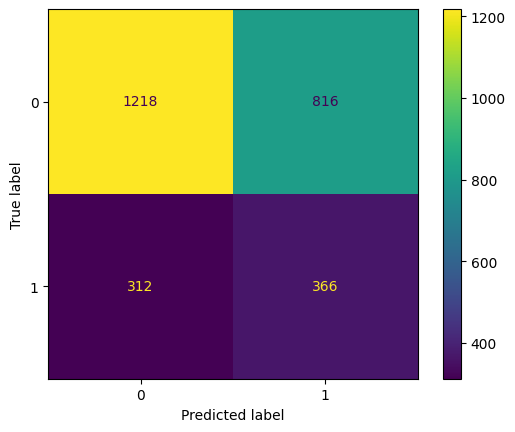

In [153]:
Y_pred = logistic_regr(X_train, X_test, y_train, y_test)

In [154]:
def tune_lr(data, c_values):
  results_train, results_val, names = [], [], []
  models = dict()
  for c in c_values:
    models[f"C_{c}"] = LogisticRegression(
        C=c,
        penalty='l1',
        class_weight='balanced',
        solver='liblinear',
        max_iter=2000,
        random_state=42)

  for name, model in models.items():
    avg_train, std_train, avg_val, std_val = select_best_models(data, model)
    clean_train = round(float(avg_train), 3)
    clean_val = round(float(avg_val), 3)

    results_train.append(clean_train)
    results_val.append(clean_val)
    names.append(name)
    print(f"{name} -> Train F1: {clean_train} | Validation F1: {clean_val}")

  return results_train, results_val, names

**`tune_lr`** — Evaluates Logistic Regression across a range of regularisation values `C` using cross-validation. Lower `C` means stronger regularisation. The point plot reveals the optimal balance between underfitting and overfitting.

In [155]:
tune_lr(all_data, [0.001, 0.01, 0.1, 1, 10, 100])

C_0.001 -> Train F1: 0.0 | Validation F1: 0.0
C_0.01 -> Train F1: 0.409 | Validation F1: 0.409
C_0.1 -> Train F1: 0.408 | Validation F1: 0.406
C_1 -> Train F1: 0.412 | Validation F1: 0.406
C_10 -> Train F1: 0.412 | Validation F1: 0.404
C_100 -> Train F1: 0.412 | Validation F1: 0.404


([0.0, 0.409, 0.408, 0.412, 0.412, 0.412],
 [0.0, 0.409, 0.406, 0.406, 0.404, 0.404],
 ['C_0.001', 'C_0.01', 'C_0.1', 'C_1', 'C_10', 'C_100'])

The best Logistic Regression model is instantiated with the optimal hyperparameters found. `C=0.01` applies strong regularisation, reducing the risk of overfitting on the training set.

In [156]:
best_lr_model = LogisticRegression(
    C=0.01,
    penalty='l2',
    class_weight='balanced',
    solver='liblinear',
    max_iter=2000,
    random_state=42)

#### Neural Networks

In [157]:
def get_models_nn(data, values):
    models = dict()
    results_train, results_val, names = [],[],[]

    for value in values:
        models[str(value)] = MLPClassifier(hidden_layer_sizes = value, max_iter=150, random_state = 42)

    for name, model in models.items():
        avg_train, std_train, avg_val, std_val = select_best_models(data, model)
        results_train.append(avg_train)
        results_val.append(avg_val)
        names.append(name)

    return results_train, results_val, names

**`get_models_nn`** - Tests different MLP hidden layer architectures using cross-validation. `max_iter=150` with `early_stopping` balances convergence speed and training time. The point plot identifies the most promising architecture before the hyperparameter search.

The neural network was ultimately trained with a maximum of 150 iterations. Although a higher limit of 2000 iterations was initially tested, the training process required more than two hours to complete while not producing any improvements in performance. Furthermore, the resulting F1-score remained below than the one of the best performing models. Given the substantial increase in computational cost and the limited performance gains, the model was trained with 150 iterations for the remainder of the analysis, providing a more efficient balance between execution time and predictive performance.

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptro

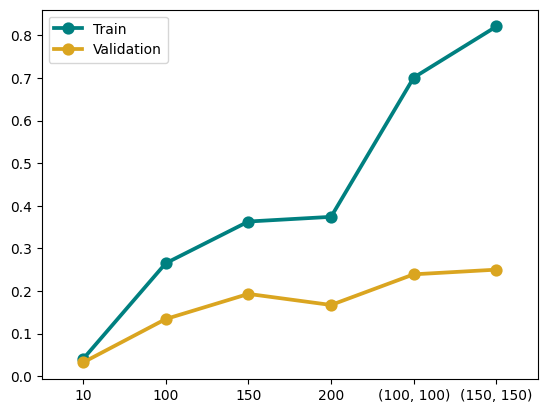

In [160]:
values_try = [(10),(100),(150),(200),(100,100),(150,150)]
results_train, results_val, names = get_models_nn(all_data, values_try)
point_plot(results_train, results_val, names)

Neural Networks have two key decisions that significantly affect performance:
- architecture (how many layers and neurons)
- learning parameters (how fast and how the model updates its weights)
Since there is no way to know the best combination in advance, we search for it automatically.

To do this safely, we use a Pipeline that bundles the scaler and the model together - this guarantees the scaler only learns from training data and never sees the validation fold. We then use RandomizedSearchCV to test 20 random combinations from our defined search space, scoring each one on F1. Instead of standard cross-validation, we use a PredefinedSplit - a fixed train/validation partition - so the same observations are never used for both fitting and evaluating, keeping the search honest.

The best combination of architecture, learning rate, schedule and activation function is printed at the end and used to instantiate the final Neural Network model.

In [ ]:
skf = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
X_data = all_data.drop(columns=['target_b'])
y_data = all_data['target_b']

# extract one stratified fold to use as the fixed validation set
train_idx, val_idx = next(skf.split(X_data, y_data))

# Assign -1 (train) and 0 (validate) to build a leakage-safe split
test_fold = np.full(len(X_data), -1)
test_fold[val_idx] = 0
ps = PredefinedSplit(test_fold)

# pipeline ensures scaler is fitted on train only and never on validation
nn_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('clf', MLPClassifier(max_iter=150, random_state=42))])

param_space_random = {
    'clf__hidden_layer_sizes': [(10), (100), (150), (200), (100, 100), (150, 150)],
    'clf__learning_rate_init': [0.001, 0.01, 0.1],
    'clf__learning_rate': ['constant', 'adaptive'],
    'clf__solver': ['adam'],
    'clf__activation': ['logistic', 'relu']}

random_search = RandomizedSearchCV(
    nn_pipeline,
    param_distributions=param_space_random,
    n_jobs=-1,
    n_iter=20,
    scoring='f1',
    cv=ps,
    random_state=42)

random_search.fit(X_data, y_data)
print('Best params:', random_search.best_params_)
print('Best F1:',     round(random_search.best_score_, 4))

Best params: {'clf__solver': 'adam', 'clf__learning_rate_init': 0.01, 'clf__learning_rate': 'constant', 'clf__hidden_layer_sizes': 150, 'clf__activation': 'relu'}
Best F1: 0.2407


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


In [162]:
best_nn_model = MLPClassifier(
    max_iter=2000,
    random_state=42,
    activation='relu',
    hidden_layer_sizes=(100, 100),
    learning_rate= 'constant',
    learning_rate_init= 0.001,
    solver= 'adam')

avg_train, std_train, avg_val, std_val = select_best_models(all_data, best_nn_model)
print(f"Treino: {avg_train} +/- {std_train}")
print(f"Validação: {avg_val} +/- {std_val}")

Treino: 0.979 +/- 0.01
Validação: 0.285 +/- 0.02


The best Neural Network model is instantiated using the optimal hyperparameters found by `RandomizedSearchCV`. Its cross-validated F1 is computed using `select_best_models` for comparison with other models.

#### Random Forest Classifier

In [163]:
def Random_Forest_Classifier(X_train, Y_train, X_test, Y_test):
    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    param_dist = {'n_estimators': randint(50, 500),'max_depth': randint(1, 20), 'min_samples_split': randint(2,10)}

    rf_model = RandomForestClassifier(random_state=42, class_weight='balanced')
    rs_model = RandomizedSearchCV(
        rf_model,
        param_distributions=param_dist,
        n_iter=25,
        cv=5,
        scoring='f1',
        random_state=42)
    rs_model.fit(X_train_scaled, Y_train)

    print('Best hyperparameters:', rs_model.best_params_)

    Y_pred = rs_model.predict(X_test_scaled)

    print("Precision:", precision_score(Y_test, Y_pred))
    print("Recall:", recall_score(Y_test, Y_pred))
    print("Accuracy:", accuracy_score(Y_test, Y_pred))

    return Y_pred

**`Random_Forest_Classifier`** - Fits a Random Forest with `RandomizedSearchCV` to find the best `n_estimators`, `max_depth`, and `min_samples_split`. `class_weight='balanced'` handles the class imbalance. The search optimises directly for F1.

Best hyperparameters: {'max_depth': 2, 'min_samples_split': 7, 'n_estimators': 439}
Precision: 0.30472636815920395
Recall: 0.48180924287118976
Accuracy: 0.5956243854473943
F1-Score: 0.37333333333333335

Classification Summary:
               precision    recall  f1-score   support

           0       0.79      0.63      0.70      3051
           1       0.30      0.48      0.37      1017

    accuracy                           0.60      4068
   macro avg       0.55      0.56      0.54      4068
weighted avg       0.67      0.60      0.62      4068



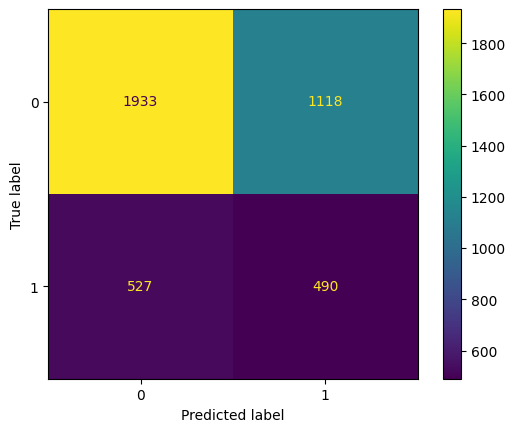

In [164]:
Y_pred = Random_Forest_Classifier(X_train, Y_train, X_test, Y_test)
f1_evaluation(Y_test, Y_pred)

In [165]:
best_rf_model = RandomForestClassifier(
    n_estimators=439,
    max_depth=2,
    class_weight='balanced',
    random_state=42,
    min_samples_split=7)

avg_train, std_train, avg_val, std_val = select_best_models(all_data, best_rf_model)
print(f"Treino: {avg_train} +/- {std_train}")
print(f"Validação: {avg_val} +/- {std_val}")

Treino: 0.406 +/- 0.0
Validação: 0.399 +/- 0.01


The best Random Forest model is instantiated with the optimal hyperparameters. Its cross-validated F1 is computed using `select_best_models`.

#### Decision Tree

For the decision tree we start by finding the max depth so we have a starting point

In [166]:
def Decision_Tree(data, depths):
  results_train, results_val, names = [], [], []
  for depth in depths:
      model = tree.DecisionTreeClassifier(max_depth=depth, class_weight='balanced', random_state=42)
      avg_train, std_train, avg_val, std_val = select_best_models(data, model)
      results_train.append(avg_train)
      results_val.append(avg_val)
      names.append(str(depth))
  return results_train, results_val, names

**`Decision_Tree`** — Iterates over a range of `max_depth` values and evaluates each using `select_best_models`. The point plot is used to identify the depth at which the validation F1 peaks and overfitting begins.

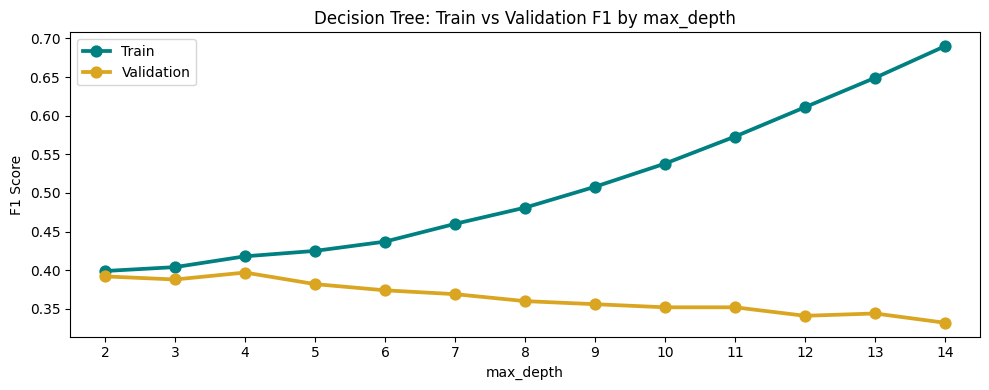

In [167]:
depths_try = list(range(2, 15))
results_train_dt, results_val_dt, names_dt = Decision_Tree(all_data, depths_try)
plt.figure(figsize=(10, 4))
point_plot(results_train_dt, results_val_dt, names_dt)
plt.title('Decision Tree: Train vs Validation F1 by max_depth')
plt.xlabel('max_depth')
plt.ylabel('F1 Score')
plt.tight_layout()
plt.show()

In [168]:
X_dt = all_data.drop(columns=['target_b'])
y_dt = all_data['target_b']

RandomizedSearchCV

In [169]:
param_dist_dt = {
    'max_depth': randint(2, 15),
    'min_samples_split': randint(2, 50),
    'min_samples_leaf': randint(1, 30),
    'criterion': ['gini', 'entropy']
}
dt_base = tree.DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42)
rs_dt = RandomizedSearchCV(
    dt_base,
    param_distributions=param_dist_dt,
    n_iter=30,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1)
rs_dt.fit(X_dt, y_dt)
print('Best hyperparameters (RandomizedSearch):', rs_dt.best_params_)
print('Best CV F1 (validation):', round(rs_dt.best_score_, 4))

Best hyperparameters (RandomizedSearch): {'criterion': 'entropy', 'max_depth': 2, 'min_samples_leaf': 4, 'min_samples_split': 41}
Best CV F1 (validation): 0.4001


`RandomizedSearchCV` is applied to the Decision Tree over a broad space of `max_depth`, `min_samples_split`, `min_samples_leaf`, and `criterion`. The search optimises for F1 using 5-fold CV.

In [170]:
best_dt_model = tree.DecisionTreeClassifier(
  max_depth=2,
  min_samples_split=41,
  min_samples_leaf=4,
  criterion='entropy',
  class_weight='balanced',
  random_state=42)

avg_train, std_train, avg_val, std_val = select_best_models(all_data, best_dt_model)
print(f"Train F1: {avg_train} +/- {std_train}")
print(f"Validation F1: {avg_val} +/- {std_val}")

Train F1: 0.399 +/- 0.02
Validation F1: 0.392 +/- 0.03


The best Decision Tree model is instantiated with the optimal hyperparameters from `RandomizedSearchCV`. Cross-validated F1 is computed using `select_best_models`. The tree is also visualised at `max_depth=3` for interpretability.

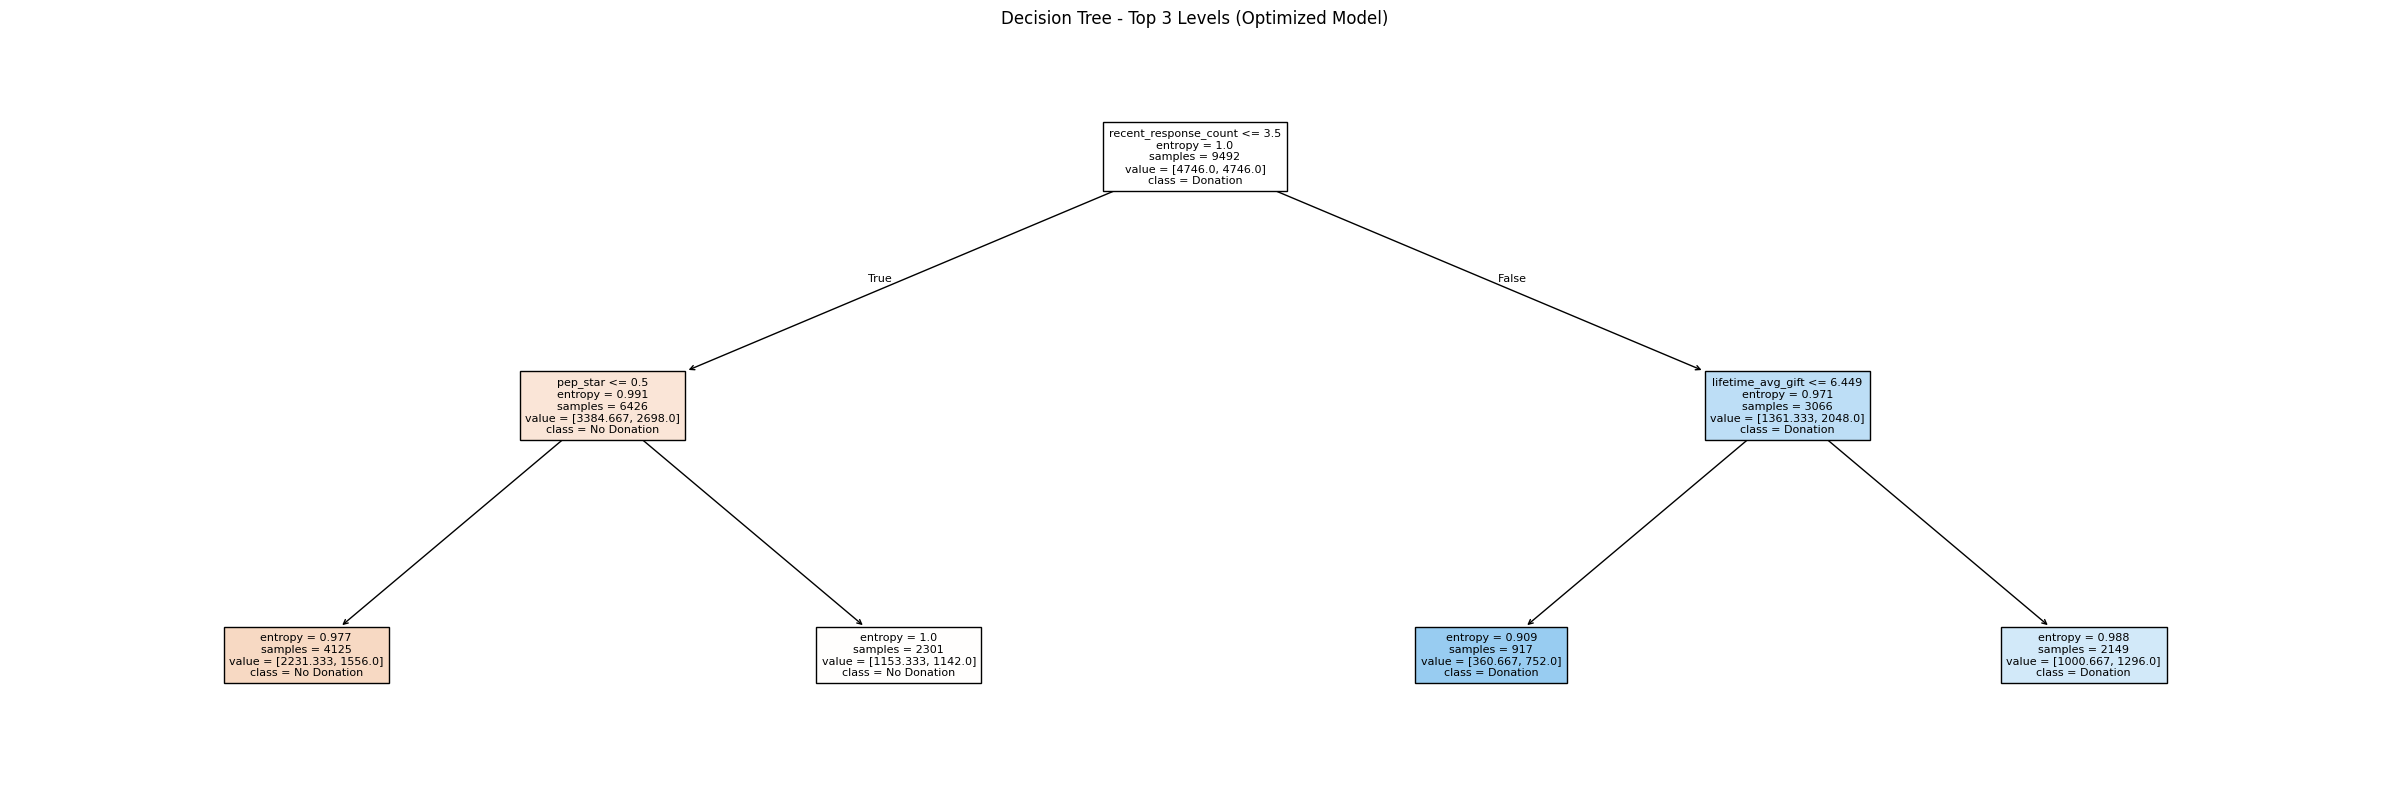

F1-Score: 0.3264957264957265

Classification Summary:
               precision    recall  f1-score   support

           0       0.77      0.69      0.73      3051
           1       0.29      0.38      0.33      1017

    accuracy                           0.61      4068
   macro avg       0.53      0.53      0.53      4068
weighted avg       0.65      0.61      0.63      4068



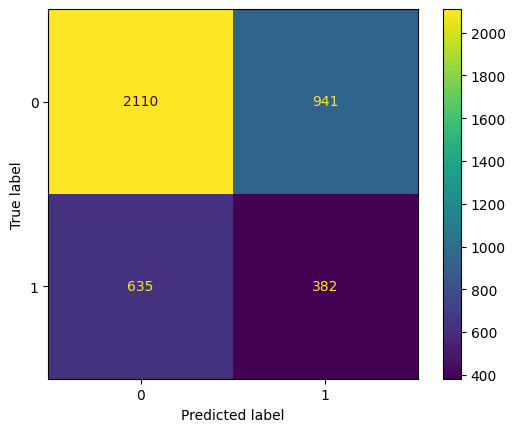

In [171]:
X_train_dt, X_test_dt, Y_train_dt, Y_test_dt = train_test_split(
    X_dt, y_dt, test_size=0.3, random_state=42, stratify=y_dt)

best_dt_model.fit(X_train_dt, Y_train_dt)
plt.figure(figsize=(24, 8))
tree.plot_tree(
  best_dt_model,
  feature_names=X_dt.columns,
  class_names=['No Donation', 'Donation'],
  filled=True,
  max_depth=3,
  fontsize=8)

plt.title('Decision Tree - Top 3 Levels (Optimized Model)')
plt.tight_layout()
plt.show()
Y_pred_dt = best_dt_model.predict(X_test_dt)
f1_evaluation(Y_test_dt, Y_pred_dt)

#### Select the winning model

In [172]:
df_final_models = pd.DataFrame(columns = ['Train','Validation'], index = ['Best LR','Best NN','Best RF', 'Best DT'])
show_results(df_final_models, all_data, best_lr_model, best_nn_model, best_rf_model, best_dt_model)

,Train,Validation
Best LR,0.407+/-0.0,0.405+/-0.01
Best NN,0.979+/-0.01,0.285+/-0.02
Best RF,0.406+/-0.0,0.399+/-0.01
Best DT,0.399+/-0.02,0.392+/-0.03


All four best models are compared side by side using `show_results`. This summary table is the basis for selecting the model to deploy.

In [173]:
X_data = all_data.drop(columns=['target_b'])
y_data = all_data['target_b']

In [174]:
X_data = encode_data(X_data)

`encode_data` is applied to `X_data` to ensure all categorical columns are numerically encoded before fitting models for the ROC comparison.

In [175]:
X_train, X_val, y_train, y_val = train_test_split(X_data, y_data, train_size = 0.8, random_state = 42, stratify = y_data)
scaler = MinMaxScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)

model_lr = best_lr_model.fit(X_train, y_train)
model_nn = best_nn_model.fit(X_train, y_train)
model_rf = best_rf_model.fit(X_train, y_train)
model_dt = best_dt_model.fit(X_train, y_train)

An 80/20 train-validation split is performed with stratification. The scaler is fitted on training data only and applied to both sets. All four best models are then fitted on the same training set to ensure a fair comparison.

In [176]:
prob_modelLR = model_lr.predict_proba(X_val)
prob_modelNN = model_nn.predict_proba(X_val)
prob_modelRF = model_rf.predict_proba(X_val)
prob_modelDT = model_dt.predict_proba(X_val)

In [177]:
fpr_modelLR, tpr_modelLR, thresholds_modelLR = roc_curve(y_true = y_val, y_score = prob_modelLR[:,1])
fpr_modelNN, tpr_modelNN, thresholds_modelNN = roc_curve(y_val, prob_modelNN[:,1])
fpr_modelRF, tpr_modelRF, thresholds_modelRF = roc_curve(y_val, prob_modelRF[:,1])
fpr_modelDT, tpr_modelDT, thresholds_modelDT = roc_curve(y_val, prob_modelDT[:,1])

print(fpr_modelLR, tpr_modelLR, thresholds_modelLR)
print(fpr_modelNN, tpr_modelNN, thresholds_modelNN)
print(fpr_modelRF, tpr_modelRF, thresholds_modelRF )
print(fpr_modelDT, tpr_modelDT, thresholds_modelDT)

[0.00000000e+00 0.00000000e+00 4.91642085e-04 ... 9.95575221e-01
 9.95575221e-01 1.00000000e+00] [0.         0.00147493 0.00147493 ... 0.99852507 1.         1.        ] [       inf 0.70879913 0.70746935 ... 0.33516822 0.3338323  0.30814812]
[0.00000000e+00 0.00000000e+00 9.83284169e-04 ... 9.97050147e-01
 9.97050147e-01 1.00000000e+00] [0.         0.00147493 0.00147493 ... 0.99852507 1.         1.        ] [           inf 1.00000000e+00 1.00000000e+00 ... 1.54448637e-29
 5.27501331e-30 7.92629007e-50]
[0.00000000e+00 0.00000000e+00 4.91642085e-04 4.91642085e-04
 5.40806293e-03 5.40806293e-03 5.89970501e-03 5.89970501e-03
 6.39134710e-03 6.39134710e-03 6.88298918e-03 6.88298918e-03
 8.35791544e-03 8.35791544e-03 8.84955752e-03 8.84955752e-03
 1.08161259e-02 1.08161259e-02 1.13077679e-02 1.13077679e-02
 1.32743363e-02 1.32743363e-02 1.47492625e-02 1.47492625e-02
 1.57325467e-02 1.57325467e-02 1.67158309e-02 1.67158309e-02
 1.72074730e-02 1.72074730e-02 1.86823992e-02 1.86823992e-02
 1.91

In [178]:
roc_auc_modelLR = roc_auc_score(y_val, prob_modelLR[:, 1])
roc_auc_modelNN = roc_auc_score(y_val, prob_modelNN[:, 1])
roc_auc_modelRF = roc_auc_score(y_val, prob_modelRF[:, 1])
roc_auc_modelDT = roc_auc_score(y_val, prob_modelDT[:, 1])

print(roc_auc_modelLR)
print(roc_auc_modelNN)
print(roc_auc_modelRF)
print(roc_auc_modelDT)

0.5841628887090552
0.5443942650458431
0.576335772690225
0.5505716970788629


AUC scores are computed and all four ROC curves are plotted in a single figure. The closer a curve is to the top-left corner, the better the model is at catching donors with the best trade-off between sensitivity and specificity. The dashed line is a random classifier - anything above it means the model is actually learning something.
This said, the best model is **logistic regression**

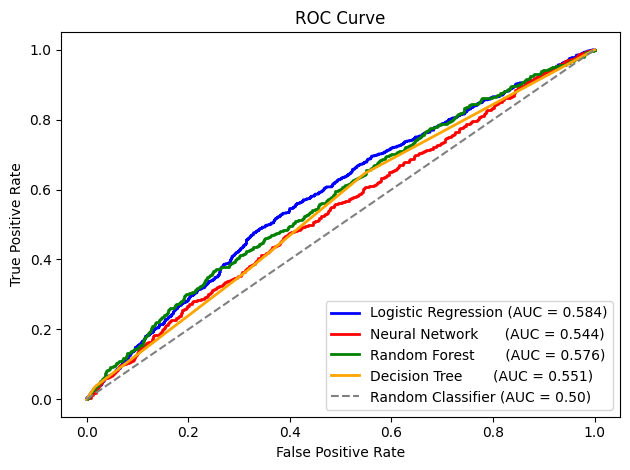

In [179]:
plt.plot(fpr_modelLR, tpr_modelLR, color='blue',   lw=2, label=f'Logistic Regression (AUC = {roc_auc_modelLR:.3f})')
plt.plot(fpr_modelNN, tpr_modelNN, color='red',    lw=2, label=f'Neural Network      (AUC = {roc_auc_modelNN:.3f})')
plt.plot(fpr_modelRF, tpr_modelRF, color='green',  lw=2, label=f'Random Forest       (AUC = {roc_auc_modelRF:.3f})')
plt.plot(fpr_modelDT, tpr_modelDT, color='orange', lw=2, label=f'Decision Tree       (AUC = {roc_auc_modelDT:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Here we calculate the best threshold for the Logistic Regression

Best Threshold=0.466767, F-Score=0.412


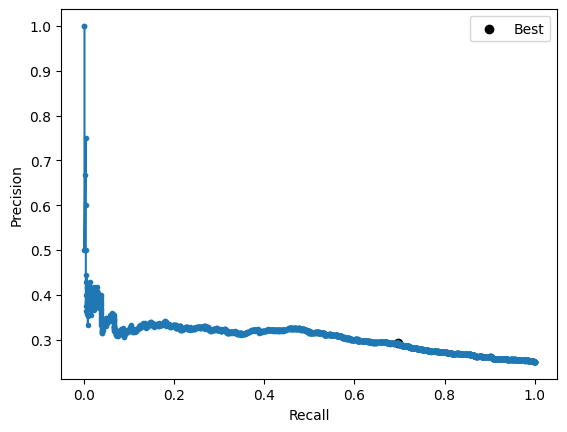

In [180]:
model_lr = best_lr_model.fit(X_train, y_train)
prob_modelLR = model_lr.predict_proba(X_val)
precision, recall, thresholds = precision_recall_curve(y_val, prob_modelLR[:, 1])
# compute F1 score and avoid division by zero
fscore = np.where((precision + recall) > 0, (2 * precision * recall) / (precision + recall), 0)
# locate the index of the largest f score
ix = np.argmax(fscore)
best_threshold = thresholds[ix]
print('Best Threshold=%f, F-Score=%.3f' % (best_threshold, fscore[ix]))
plt.plot(recall, precision, marker='.')
plt.scatter(recall[ix], precision[ix], marker='o', color='black', label='Best')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()

The threshold that maximises the F1 score on the validation set is selected as `best_threshold`.


--- Default threshold (0.5) ---
F1-Score: 0.3987441130298273

Classification Summary:
               precision    recall  f1-score   support

           0       0.80      0.58      0.67      2034
           1       0.31      0.56      0.40       678

    accuracy                           0.58      2712
   macro avg       0.55      0.57      0.54      2712
weighted avg       0.68      0.58      0.60      2712


--- Optimal threshold (0.467) ---
F1-Score: 0.41168774531181856

Classification Summary:
               precision    recall  f1-score   support

           0       0.81      0.44      0.57      2034
           1       0.29      0.70      0.41       678

    accuracy                           0.50      2712
   macro avg       0.55      0.57      0.49      2712
weighted avg       0.68      0.50      0.53      2712



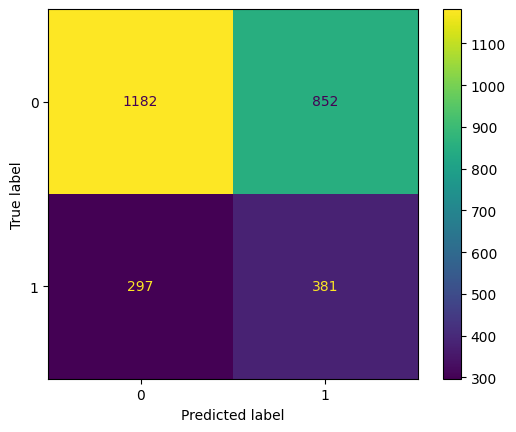

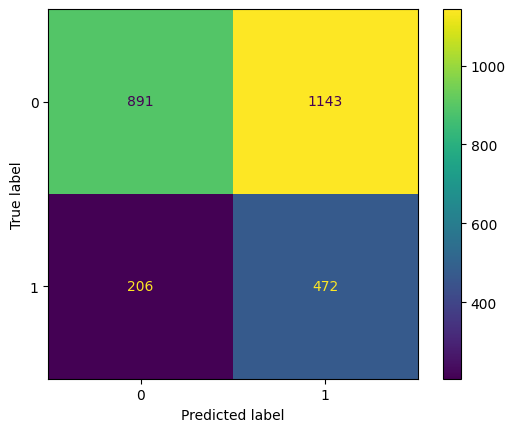

In [181]:
Y_pred_default  = (prob_modelLR[:, 1] >= 0.5).astype(int)
Y_pred_tuned    = (prob_modelLR[:, 1] >= best_threshold).astype(int)
print("\n--- Default threshold (0.5) ---")
f1_evaluation(y_val, Y_pred_default)
print(f"\n--- Optimal threshold ({best_threshold:.3f}) ---")
f1_evaluation(y_val, Y_pred_tuned)

The default threshold (0.5) is compared against the optimised threshold. The improvement in F1 confirms that threshold tuning is beneficial for this imbalanced dataset.

---
# 4. Deployment

## 4.1. Import and transform test data


In [182]:
train = all_data.copy()
X_train = train.drop(columns=['target_b'], axis=1)
y_train = train['target_b']

The full `all_data` dataset is used as the final training set — no train/test split is needed here since the model is no longer being evaluated but deployed. `X_train` contains all features and `y_train` all labels.

In [183]:
df_test = pd.read_csv(path+'test.csv')
df_test.columns = df_test.columns.str.lower()
df_test.head()

,control_number,card_prom_12,children,donor_age,donor_gender,file_card_gift,frequency_status_97nk,home_owner,income_group,last_gift_amt,...,recent_avg_card_gift_amt,recent_avg_gift_amt,recent_card_response_count,recent_card_response_prop,recent_response_count,recent_response_prop,recent_star_status,ses,urbanicity,wealth_rating
0,122653,5.0,0.0,72.0,M,1.0,1.0,H,4.0,25.0,...,0.0,25.00,0.0,0.789208,1.0,0.071,0.0,2,T,NaN
1,184239,5.0,3.0,73.0,U,20.0,4.0,U,NaN,6.0,...,4.5,4.63,6.0,0.545000,8.0,0.421,1.0,2,C,1.0
2,5172,6.0,2.0,36.0,M,11.0,NaN,H,4.0,10.0,...,17.0,16.00,1.0,0.125000,2.0,0.111,1.0,3,R,1.0
3,135377,6.0,3.0,NaN,F,2.0,4.0,U,2.0,10.0,...,7.5,8.25,2.0,0.400000,4.0,0.364,0.0,1,U,NaN
4,62119,6.0,0.0,83.0,F,9.0,2.0,U,2.0,20.0,...,20.0,20.00,1.0,0.125000,2.0,NaN,1.0,2,T,5.0


## 4.2. Pre Processing Test data

In [184]:
def re_pre_processing(df: pd.DataFrame) -> pd.DataFrame:
  df_copy = df.copy()
  df_copy.columns = df_copy.columns.str.lower()
  if "control_number" in df_copy.columns:
    df_copy.set_index("control_number", inplace=True)
  # months_since_last_prom_resp
  df_copy.loc[df_copy['months_since_last_prom_resp'] < 0, 'months_since_last_prom_resp'] = np.nan
  df_copy['no_response_flag'] = df_copy['months_since_last_prom_resp'].isna().astype(int)
  max_months = df_copy['months_since_last_prom_resp'].max()
  df_copy['months_since_last_prom_resp'] = df_copy['months_since_last_prom_resp'].fillna(max_months)
  df_copy['months_since_last_prom_resp'] = df_copy['months_since_last_prom_resp'].round(0).astype(int)
  # recent_response_count, recent_card_response_count
  # rrecent_reponse_prop, recent_card_response_prop
  recent_count = ['recent_response_count','recent_card_response_count']
  recent_prop = ['recent_response_prop','recent_card_response_prop']
  recent_all = recent_count+recent_prop
  for col in recent_all:
      df_copy.loc[df_copy[col] < 0, col] = np.nan
  df_copy.loc[df_copy['no_response_flag'] == 1, recent_all] = 0
  med_actives = df_copy.loc[df_copy['no_response_flag'] == 0, recent_all].median()
  df_copy[recent_all] = df_copy[recent_all].fillna(med_actives)
  df_copy['recent_response_count'] = np.where(df_copy['recent_response_count'] < df_copy['recent_card_response_count'],
                                            df_copy['recent_card_response_count'],
                                            df_copy['recent_response_count'])
  df_copy[recent_prop] = df_copy[recent_prop].clip(0, 1)
  df_copy[recent_count] = df_copy[recent_count].round(0).astype(int)
  # lifetime_prom
  df_copy.loc[df_copy['lifetime_prom'] < 0, 'lifetime_prom'] = np.nan
  df_copy['lifetime_prom'] = df_copy['lifetime_prom'].fillna(df_copy['lifetime_prom'].median())
  df_copy['lifetime_prom'] = df_copy['lifetime_prom'].abs().round(0).astype(int)
  # lifetime_card_prom
  df_copy.loc[df_copy['lifetime_card_prom'] < 0, 'lifetime_card_prom'] = np.nan
  card_ratio = (df_copy['lifetime_card_prom'] / df_copy.loc[df_copy['lifetime_prom'] >0 ,'lifetime_prom']).mean()
  df_copy['lifetime_card_prom'] = df_copy['lifetime_card_prom'].fillna(df_copy['lifetime_prom'] * card_ratio)
  df_copy['lifetime_card_prom'] = np.where(df_copy['lifetime_card_prom'] > df_copy['lifetime_prom'], df_copy['lifetime_prom'], df_copy['lifetime_card_prom'])
  df_copy['lifetime_card_prom'] = df_copy['lifetime_card_prom'].abs().round(0).astype(int)
  # number_prom_12, card_prom_12
  cols = ['number_prom_12', 'card_prom_12']
  df_copy[cols] = df_copy[cols].mask(df_copy[cols] < 0)
  df_copy['number_prom_12'] = df_copy['number_prom_12'].fillna(df_copy['card_prom_12']).fillna(0)
  df_copy.loc[df_copy['number_prom_12']<df_copy['card_prom_12'], 'card_prom_12']= df_copy.loc[df_copy['number_prom_12']<df_copy['card_prom_12'], 'number_prom_12']
  df_copy['card_prom_12'] = df_copy['card_prom_12'].fillna(0)
  df_copy[cols] = df_copy[cols].abs().round().astype(int)
  df_copy['number_prom_12'] = np.where(df_copy['number_prom_12'] > 50, 50, df_copy['number_prom_12'])
  df_copy['card_prom_12'] = np.where(df_copy['card_prom_12'] > 15, 15, df_copy['card_prom_12'])
  # donor_gender
  df_copy['donor_gender'] = df_copy['donor_gender'].fillna('U')
  # children
  df_copy.loc[df_copy['children'] < 0, 'children'] = np.nan
  df_copy['children'] = df_copy['children'].fillna(df_copy['children'].median())
  df_copy['children'] = df_copy['children'].round(0).astype(int)
  # home_owner
  df_copy['home_owner'] = df_copy['home_owner'].fillna('U')
  # pct_owner_occupied
  df_copy.loc[df_copy['pct_owner_occupied'] > 100, 'pct_owner_occupied'] = np.nan
  df_copy['pct_owner_occupied'] = df_copy['pct_owner_occupied'].fillna(df_copy['pct_owner_occupied'].median())
  df_copy['pct_owner_occupied'] = df_copy['pct_owner_occupied'].round(2)
  # pct_attribute 1, 2, 3 and 4
  pct_cols = ['pct_attribute1', 'pct_attribute2', 'pct_attribute3', 'pct_attribute4']
  for col in pct_cols:
    df_copy.loc[df_copy[col] < 0, col] = np.nan
    df_copy[col] = df_copy[col].fillna(df_copy[col].median())
  df_copy[pct_cols] = df_copy[pct_cols].round(2)
  # urbanicity
  df_copy['urbanicity'] = df_copy['urbanicity'].astype(str).str.strip()
  df_copy['urbanicity'] = df_copy['urbanicity'].replace(['?','nan'], np.nan)
  df_copy['urbanicity'] = df_copy['urbanicity'].fillna(df_copy['urbanicity'].mode()[0])
  # ses
  df_copy['ses'] = df_copy['ses'].astype(str).str.strip().replace('?', np.nan)
  df_copy['ses'] = pd.to_numeric(df_copy['ses'], errors='coerce')
  df_copy['ses'] = df_copy['ses'].fillna(df_copy.groupby('urbanicity')['ses'].transform(lambda x: x.mode()[0] if not x.mode().empty else np.nan))
  df_copy['ses'] = df_copy['ses'].astype(int)
  # per_capita_income
  df_copy.loc[df_copy['per_capita_income'] < 0, 'per_capita_income'] = np.nan
  df_copy['per_capita_income'] = df_copy['per_capita_income'].fillna(df_copy['per_capita_income'].median())
  df_copy['per_capita_income'] = df_copy['per_capita_income'].round(0).astype(int)
  df_copy['per_capita_income'] = np.where(df_copy['per_capita_income'] > 100000, 100000, df_copy['per_capita_income'])
  # income_group
  df_copy.loc[(df_copy['income_group'] <= 0) | (df_copy['income_group'] > 7), 'income_group'] = np.nan
  df_copy['income_group'] = df_copy['income_group'].fillna(df_copy.groupby('urbanicity')['income_group'].transform(lambda x: x.mode()[0]))
  df_copy['income_group'] = df_copy['income_group'].astype(int)
  # median_home_value
  df_copy.loc[df_copy['median_home_value'] < 0, 'median_home_value'] = np.nan
  df_copy['median_home_value'] = df_copy['median_home_value'].fillna(df_copy.groupby('urbanicity')['median_home_value'].transform('median'))
  df_copy['median_home_value'] = df_copy['median_home_value'].round(0).astype(int)
  # media_household_income
  df_copy.loc[df_copy['median_household_income'] < 0, 'median_household_income'] = np.nan
  df_copy['median_household_income'] = df_copy['median_household_income'].fillna(df_copy.groupby('ses')['median_household_income'].transform('median'))
  df_copy['median_household_income'] = df_copy['median_household_income'].round(0).astype(int)
  mask = df_copy['median_household_income'].quantile(0.99)
  df_copy['median_household_income'] = np.where(df_copy['median_household_income'] > mask, mask, df_copy['median_household_income'])
  # wealth Rating
  df_copy.loc[(df_copy['wealth_rating']<0) | (df_copy['wealth_rating']>9), 'wealth_rating'] = np.nan
  subset = ['wealth_rating','median_household_income', 'per_capita_income', 'median_home_value']
  df_wealth = df_copy[subset]
  imputer = KNNImputer(n_neighbors=3)
  df_imputed = pd.DataFrame(imputer.fit_transform(df_wealth), columns=subset, index=df_copy.index)
  df_copy['wealth_rating'] = df_imputed['wealth_rating'].round().clip(0,9).astype('Int64')
  # donor_age
  df_copy.loc[(df_copy['donor_age'] < 18) | (df_copy['donor_age'] >100) , 'donor_age'] = np.nan
  df_copy['donor_age'] = df_copy['donor_age'].fillna(df_copy['donor_age'].median())
  df_copy['donor_age'] = df_copy['donor_age'].round(0).astype(int)
  # lifetime_gift_count and lifetime_gift_amount
  cols = ['lifetime_gift_count','lifetime_gift_amount']
  df_copy[cols] = df_copy[cols].mask(df_copy[cols] < 0)
  df_copy.loc[(df_copy['lifetime_gift_amount'] > 0) & (df_copy['lifetime_gift_count'].isnull()), 'lifetime_gift_count'] = 1
  df_copy['lifetime_gift_amount'] = (df_copy.groupby('lifetime_gift_count')['lifetime_gift_amount'].transform(lambda x: x.fillna(x.median())))
  df_copy['lifetime_gift_amount'].fillna(0, inplace=True)
  df_copy['lifetime_gift_count'].fillna(0,inplace=True)
  df_copy.loc[df_copy['lifetime_gift_count']>70,'lifetime_gift_count'] = 70
  df_copy.loc[df_copy['lifetime_gift_amount']>1250,'lifetime_gift_amount'] = 1250
  # lifetime_min_gift_amt, lifetime_max_gift_amt, recent_avg_git_amt and last_gift_amt
  cols = ['lifetime_min_gift_amt','lifetime_max_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']
  df_copy[cols] = df_copy[cols].mask(df_copy[cols]<0)
  df_copy.loc[df_copy['lifetime_gift_count'] == 0, cols] = 0
  df_copy.loc[df_copy['lifetime_gift_count'] == 1, cols] = df_copy.loc[df_copy['lifetime_gift_count'] == 1, 'lifetime_gift_amount']
  median_value = df_copy.loc[df_copy['lifetime_gift_count'] > 0, cols].median()
  df_copy[cols] = df_copy[cols].fillna(median_value)
  maximum_vals = df_copy[['lifetime_min_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']].max(axis=1)
  df_copy['lifetime_max_gift_amt'] = np.maximum(df_copy['lifetime_max_gift_amt'], maximum_vals)
  minimum_vals = df_copy[['lifetime_max_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']].min(axis=1)
  df_copy['lifetime_min_gift_amt'] = np.minimum(df_copy['lifetime_min_gift_amt'], minimum_vals)
  df_copy[cols] = df_copy[cols].clip(upper=300)
  # recent_avg_card_gift_amt
  print(df_copy['recent_avg_card_gift_amt'].isnull().sum())
  df_copy.loc[df_copy['recent_avg_card_gift_amt'] < 0, 'recent_avg_card_gift_amt'] = np.nan
  mask = (df_copy['recent_avg_gift_amt'].notna() & df_copy['recent_avg_gift_amt']>0)
  ratio_card = (df_copy.loc[mask, 'recent_avg_card_gift_amt'] / df_copy.loc[mask,'recent_avg_gift_amt']).mean()
  df_copy['recent_avg_card_gift_amt'] = df_copy['recent_avg_card_gift_amt'].fillna(df_copy['recent_avg_gift_amt'] * ratio_card)
  df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'recent_avg_card_gift_amt'] = 0
  print(df_copy['recent_avg_card_gift_amt'].isnull().sum())
  df_copy['recent_avg_card_gift_amt'] = df_copy['recent_avg_card_gift_amt'].clip(upper=90)
  # file_card_gift
  print(df_copy['file_card_gift'].isnull().sum())
  df_copy.loc[df_copy['file_card_gift'] < 0, 'file_card_gift'] = np.nan
  mask = (df_copy['lifetime_gift_amount'].notna() & df_copy['lifetime_gift_amount']>0)
  ratio_amt = (df_copy.loc[mask,'file_card_gift'] / df_copy.loc[mask,'lifetime_gift_amount']).mean()
  df_copy['file_card_gift'] = df_copy['file_card_gift'].fillna(df_copy['lifetime_gift_amount'] * ratio_amt)
  df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'file_card_gift'] = 0
  print(df_copy['file_card_gift'].isnull().sum())
  df_copy['file_card_gift'] = df_copy['file_card_gift'].clip(upper=30)
  # recency_status_96nk
  df_copy['recency_status_96nk'] = df_copy['recency_status_96nk'].fillna(df_copy['recency_status_96nk'].mode()[0])
  # frequency_status_97nk
  df_copy.loc[df_copy['frequency_status_97nk']<0, 'frequency_status_97nk'] = np.nan
  df_copy['frequency_status_97nk'] = df_copy.groupby(df_copy['recency_status_96nk'])['frequency_status_97nk'].transform(lambda x: x.fillna(x.mode()[0]))
  df_copy['frequency_status_97nk'] = df_copy['frequency_status_97nk'].abs().round().astype(int)
  # months_since_first_gift & months_since_last_gift
  cols = ['months_since_first_gift', 'months_since_last_gift']
  df_copy.loc[df_copy['months_since_first_gift']<0, 'months_since_first_gift' ] = np.nan
  df_copy.loc[df_copy['months_since_last_gift']<0, 'months_since_last_gift' ] = np.nan
  group_modes = df_copy.groupby('recency_status_96nk')['months_since_first_gift'].transform(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
  fill_values = np.maximum(group_modes, df_copy['months_since_last_gift'].fillna(0))
  df_copy['months_since_first_gift'] = df_copy['months_since_first_gift'].fillna(fill_values)
  mask = df_copy["months_since_first_gift"] < df_copy["months_since_last_gift"]
  df_copy.loc[mask, 'months_since_first_gift'] = df_copy.loc[mask, 'months_since_last_gift']
  df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].fillna(df_copy['months_since_first_gift'])
  df_copy['months_since_first_gift'] = df_copy['months_since_first_gift'].abs().round().astype(int)
  df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].abs().round().astype(int)
  for col in cols:
    upper_limits_col = df_copy.groupby('recency_status_96nk')[col].transform(lambda x: x.quantile(0.99))
    df_copy[col] = np.where(df_copy[col] > upper_limits_col, upper_limits_col, df_copy[col])
  max_first = df_copy.groupby('recency_status_96nk')['months_since_first_gift'].transform('max')
  max_last = df_copy.groupby('recency_status_96nk')['months_since_last_gift'].transform('max')
  df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'months_since_first_gift'] = max_first[df_copy['lifetime_gift_count'] == 0]
  df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'months_since_last_gift'] = max_last[df_copy['lifetime_gift_count'] == 0]
  upper_limit = df_copy['months_since_last_gift'].quantile(0.99)
  df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].clip(upper=upper_limit)
  # pep_star and recent_star_status
  df_copy.loc[~df_copy['pep_star'].isin([0,1]), 'pep_star'] = np.nan
  df_copy.loc[df_copy['recent_star_status'] < 0, 'recent_star_status'] = np.nan
  df_copy.loc[df_copy['recent_star_status'] > 1, 'recent_star_status'] = 1
  mask = (df_copy['recent_star_status']==1) | (df_copy['recency_status_96nk']=='S')
  df_copy.loc[mask, 'pep_star'] = df_copy.loc[mask, 'pep_star'].fillna(1)
  df_copy['recent_star_status'].fillna(0, inplace=True)
  df_copy['pep_star'].fillna(0,inplace = True)
  # lifetime_avg_gift
  df_copy['lifetime_avg_gift'] = np.where(df_copy['lifetime_gift_count'] > 0, df_copy['lifetime_gift_amount']/df_copy['lifetime_gift_count'],0)
  # gift_variability
  df_copy['gift_variability'] = df_copy['lifetime_max_gift_amt'] - df_copy['lifetime_min_gift_amt']
  # donation_freq
  df_copy['donation_freq'] = np.where(df_copy['months_since_first_gift'] > 0, df_copy['lifetime_gift_count']/(df_copy['months_since_first_gift']),0)
  # recency_value
  df_copy['recency_value'] = df_copy['lifetime_gift_amount'] / (1 + df_copy['months_since_last_gift'])
  # rngagement_recency_score
  df_copy['engagement_recency_score'] = 100/ (1+df_copy['months_since_last_prom_resp'])
  # response_intensity
  df_copy['response_intensity'] = (df_copy['recent_response_count'].astype(float))/(1+df_copy['lifetime_prom'].astype(float))
  # card_efficiency
  df_copy['card_efficiency'] = (df_copy['recent_card_response_count']+1)*100/ (2+df_copy['lifetime_card_prom'])
  # card_preference
  df_copy['card_preference'] = ((df_copy['recent_card_response_count']+1) / (2+df_copy['recent_response_count']))

  print(df_copy.info())
  print(df_copy.describe())
  print(df_copy.isnull().sum())
  return df_copy

In [185]:
df_test_clean = re_pre_processing(df_test)
df_test_clean.head()

/tmp/ipykernel_2808/749850775.py:108: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy['lifetime_gift_amount'].fillna(0, inplace=True)
/tmp/ipykernel_2808/749850775.py:109: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tru

134
0
115
0
<class 'pandas.core.frame.DataFrame'>
Index: 5812 entries, 122653 to 65406
Data columns (total 48 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   card_prom_12                 5812 non-null   int64  
 1   children                     5812 non-null   int64  
 2   donor_age                    5812 non-null   int64  
 3   donor_gender                 5812 non-null   object 
 4   file_card_gift               5812 non-null   float64
 5   frequency_status_97nk        5812 non-null   int64  
 6   home_owner                   5812 non-null   object 
 7   income_group                 5812 non-null   int64  
 8   last_gift_amt                5812 non-null   float64
 9   lifetime_card_prom           5812 non-null   int64  
 10  lifetime_gift_amount         5812 non-null   float64
 11  lifetime_gift_count          5812 non-null   float64
 12  lifetime_max_gift_amt        5812 non-null   float64
 13  lifet

,card_prom_12,children,donor_age,donor_gender,file_card_gift,frequency_status_97nk,home_owner,income_group,last_gift_amt,lifetime_card_prom,...,wealth_rating,no_response_flag,lifetime_avg_gift,gift_variability,donation_freq,recency_value,engagement_recency_score,response_intensity,card_efficiency,card_preference
control_number,,,,,,,,,,,,,,,,,,,,,
122653,5,0,72,M,1.0,1,H,4,25.0,13,...,4,0,12.333333,20.000000,0.060000,1.947368,5.263158,0.029412,6.666667,0.333333
184239,5,3,73,U,20.0,4,U,2,6.0,32,...,1,0,4.344828,4.000000,0.226562,5.727273,4.545455,0.112676,20.588235,0.700000
5172,6,2,36,M,11.0,2,H,4,10.0,44,...,1,0,10.611111,12.000000,0.138462,31.833333,5.882353,0.020000,4.347826,0.500000
135377,6,3,60,F,2.0,4,U,2,10.0,9,...,3,1,8.250000,62.833657,0.173913,1.941176,2.857143,0.000000,9.090909,0.500000
62119,6,0,83,F,9.0,2,U,2,20.0,31,...,5,0,9.000000,17.000000,0.118110,7.941176,5.882353,0.027027,6.060606,0.500000


In [186]:
train, encoder = encode_data(X_train, fit_encoder=True, return_encoder=True)
test = encode_data(df_test_clean, encoder=encoder, fit_encoder=False)
train = train.loc[:, ~train.columns.duplicated()]
test = test.loc[:, ~test.columns.duplicated()]
test = test.reindex(columns=train.columns, fill_value=0.0)

scaler = MinMaxScaler().fit(train)
train = pd.DataFrame(scaler.transform(train), columns = train.columns, index = train.index)
test = pd.DataFrame(scaler.transform(test), columns = test.columns, index = test.index)

The encoder fitted on training data is reused to transform the test set. The test columns are reindexed to match the training columns exactly. The same scaler is applied. No new fitting is performed on test data.

In [187]:
model_lr_final = best_lr_model.fit(train, y_train)
predict_proba_test = model_lr_final.predict_proba(test)
print("Probability shape:", predict_proba_test.shape)
print("Sample probabilities (first 10):", predict_proba_test[:10, 1])

Probability shape: (5812, 2)
Sample probabilities (first 10): [0.45919957 0.62025384 0.51295691 0.54969566 0.53987265 0.56490038
 0.58985782 0.38333432 0.54844612 0.44373708]


The final Logistic Regression model is fitted on the full training set and used to predict donation probabilities for the test set.

In [188]:
final_pred = []
for value in predict_proba_test[:,1]:
    if (value>=best_threshold):
        final_pred.append(1)
    else:
        final_pred.append(0)

final_pred

[0,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 0,


The optimal threshold found during training is applied to the test probabilities. Donors with a predicted probability above the threshold are classified as likely donors (1).

Save predictions


In [189]:
answer = pd.DataFrame({'CONTROL_NUMBER': df_test_clean.index, 'TARGET_B': final_pred})
answer.to_csv(path + '2 Prediction.csv', index=False)
print(f"Predictions saved to {path}")

Predictions saved to /content/drive/MyDrive/Projeto DSML/


The final predictions are saved to a CSV file in the required submission format: `CONTROL_NUMBER` and `TARGET_B`. This file is submitted to Kaggle.

---
# 5. Open-Ended Section

## Correctness of implementation and difficulty of tasks

Although the implemented pipeline achieved competitive F1-scores and performed within the expected range, several additional approaches could be explored to further improve performance.

- **Class imbalance handling**: The dataset presents a substantial imbalance between donors and non-donors. While stratified sampling and appropriate evaluation metrics were used, more advanced resampling techniques could be investigated like bootstraping that could potentially improve the model's ability to identify a donation. So, after this section we tried implementing the bootstraping on our best model.

- **Cluster based modeling**: An additional improvement would be to leverage the customer segments identified through clustering  for the project handout. Rather than using cluster solely as a descriptive insight, separating and using a predictive model trained for each cluster specifically could allow the algorithm to capture segment-specific donation patterns. This approach may improve predictive performance if donor behavior differs substantially across groups. This is not necessarly our case since our scores weren't very high.

- **Feature engineering:** Since the predictive model uses all features and some of them are classified "Try with and Without", this specific features could see a merge or engineering between them to try and improve their effectiveness int he prediction.

- **Neural Network:** The neural network was ultimately trained with a maximum of 150 iterations. Although a higher limit of 2000 iterations was initially tested, the training process required more than two hours to complete while not producing any improvements in performance. Furthermore, the resulting F1-score remained below that of the best  performing models. Given the substantial increase in computational cost and the limited performance gains, the model was trained with 150 iterations for the remainder of the analysis, providing a more efficient balance between execution time and predictive performance.

- **Outliers Handling:** The treatment of outliers may have influenced the performance of the predictive models. In this project, outlier detection and removal were performed after imputing missing values to ensure that all observations could be evaluated consistently. However, applying outlier treatment before imputation could potentially yield in different results, as extreme values may affect the estimation of replacement values used during the imputation process. Future work could compare both approaches to assess their impact on model performance and determine the most appropriate preprocessing sequence.

## Bootstraping attempt


In here we are comparing the results of our best model if a bootstraping resampling technique was applied to our all_data dataset in hopes of correcting the class imbalance. Our goal is to test if this would improve our f1-score without altering the main pipeline.

`lr_bootstrap` - Splits the training fold into two separate groups, all the 0s (majority) and all the 1s (minority) and takes the minority group (1s) and resamples it with replacement. This means it randomly picks rows from the 1s repeatedly, allowing the same donor to be picked more than once, until it has the same number of rows as the 0s. Then, joins the original 0s together with the oversampled 1s into one balanced training set and trains the model on that set.

In [190]:
from sklearn.utils import resample
def lr_bootstrap(data, lr_model, n_splits=5, random_state=42):
  skf = StratifiedKFold(n_splits=n_splits, random_state=random_state, shuffle=True)
  X = data.drop(columns=['target_b'], errors='ignore')
  Y = data['target_b']

  score_train, score_val = [], []

  for train_index, val_index in skf.split(X, Y):
    X_train, X_val = X.iloc[train_index], X.iloc[val_index]
    y_train, y_val = Y.iloc[train_index], Y.iloc[val_index]

    X_majority = X_train[y_train == 0]
    y_majority = y_train[y_train == 0]
    X_minority = X_train[y_train == 1]
    y_minority = y_train[y_train == 1]

    X_min_up, y_min_up = resample(X_minority, y_minority, replace=True, n_samples=len(X_majority), random_state=random_state)

    X_train_bal = pd.concat([X_majority, X_min_up]).reset_index(drop=True)
    y_train_bal = pd.concat([y_majority, y_min_up]).reset_index(drop=True)

    scaler = MinMaxScaler().fit(X_train_bal)
    X_train_bal = scaler.transform(X_train_bal)
    X_val_sc    = scaler.transform(X_val)

    lr_model.fit(X_train_bal, y_train_bal)
    predictions_train = lr_model.predict(X_train_bal)
    predictions_val   = lr_model.predict(X_val_sc)

    score_train.append(f1_score(y_train_bal, predictions_train))
    score_val.append(f1_score(y_val, predictions_val))

  avg_train = round(np.mean(score_train), 3)
  avg_val   = round(np.mean(score_val),   3)
  std_train = round(np.std(score_train),  2)
  std_val   = round(np.std(score_val),    2)

  return avg_train, std_train, avg_val, std_val


tr_orig, std_tr_orig, val_orig, std_val_orig = select_best_models(all_data, best_lr_model)
tr_boot, std_tr_boot, val_boot, std_val_boot = lr_bootstrap(all_data, best_lr_model)
rows = [{
  'Model': 'Best Logistic Regression',
  'Val F1 (Original)':   f"{val_orig}  ±{std_val_orig}",
  'Val F1 (Bootstrap)':  f"{val_boot}  ±{std_val_boot}",
  'Train F1 (Original)':  f"{tr_orig}  ±{std_tr_orig}",
  'Train F1 (Bootstrap)': f"{tr_boot}  ±{std_tr_boot}"}]

df_lr_bootstrap = pd.DataFrame(rows).set_index('Model')
print("\n── Bootstrap vs Original CV – Logistic Regression F1 Comparison ──")
display(df_lr_bootstrap)


── Bootstrap vs Original CV – Logistic Regression F1 Comparison ──


,Val F1 (Original),Val F1 (Bootstrap),Train F1 (Original),Train F1 (Bootstrap)
Model,,,,
Best Logistic Regression,0.405 ±0.01,0.403 ±0.01,0.407 ±0.0,0.574 ±0.0


From the obtained results we can see that with bootstraping the Logistic Regression model has a better F1-score on the training set in comparison with the original whilst on the validation set the F1-score is lower, suggesting that the overfitting increased.

## Feature Importance Analysis

To understand what is driving our model's decisions, we can look directly at the Logistic Regression coefficients. Since all features were normalized using MinMaxScaler, we can compare these weights to see both the strength and direction of each variable's impact.

To achieve this:
- `Preparation of the data:` we separate the features from the target and scale them to get reliable coefficients

- `Extraction of the weights:` we train the best Logistic Regression model on the full dataset and map the resulting weights to their respective column names

- `Isolation of the extremes:` we find the top 15 positive contributors (features that push the model to predict a donation) and the top 15 negative contributors to create an horizontal bar chart
  - **Light Blue bars (Positive coefficients):** the higher the coefficient the higher the feature pushes towards donating

  - **Grey bars (Negative coefficients):** the lower the coefficient the lower the feature strongly pushes towards not donating

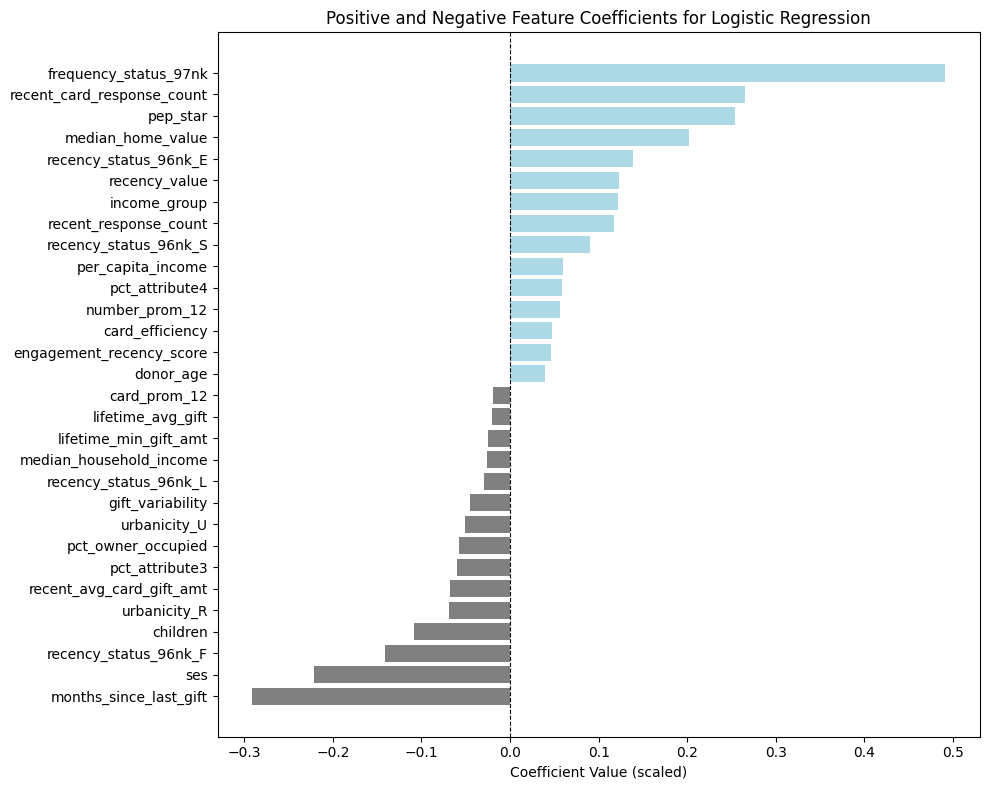


Top 10 features towards donating (+):
frequency_status_97nk         0.491308
recent_card_response_count    0.264995
pep_star                      0.253677
median_home_value             0.202256
recency_status_96nk_E         0.138965
recency_value                 0.123042
income_group                  0.121462
recent_response_count         0.117145
recency_status_96nk_S         0.090222
per_capita_income             0.059736
dtype: float64

Top 10 features towards not donating (-):
months_since_last_gift     -0.290830
ses                        -0.220960
recency_status_96nk_F      -0.141156
children                   -0.107998
urbanicity_R               -0.068551
recent_avg_card_gift_amt   -0.067651
pct_attribute3             -0.060049
pct_owner_occupied         -0.057972
urbanicity_U               -0.050830
gift_variability           -0.045354
dtype: float64


In [191]:
X_features = all_data.drop(columns=['target_b'])
y_features = all_data['target_b']
scaler = MinMaxScaler().fit(X_features)
X_features_scaled   = scaler.transform(X_features)

best_lr_model.fit(X_features_scaled, y_features)
coef = pd.Series(best_lr_model.coef_[0], index=X_features.columns)

top_best = coef.nlargest(15)
top_worst = coef.nsmallest(15)
top_features = pd.concat([top_best, top_worst]).sort_values()

plt.figure(figsize=(10, 8))
colors = ['lightblue' if v > 0 else 'grey' for v in top_features.values]
plt.barh(top_features.index, top_features.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Positive and Negative Feature Coefficients for Logistic Regression')
plt.xlabel('Coefficient Value (scaled)')
plt.tight_layout()
plt.show()

print("\nTop 10 features towards donating (+):")
print(coef.nlargest(10))
print("\nTop 10 features towards not donating (-):")
print(coef.nsmallest(10))

By evaluating the results we can conclude that:

`What increases the prediction of donations(+):`

- Features like frequency_status_97nk ($0.491$) and recent_card_response_count ($0.265$) are the strongest positive drivers. This confirms that a donor's ongoing momentum and response history are the best predictors of future donations

- Higher median_home_value ($0.202$), income_group ($0.121$), and per_capita_income ($0.059$) naturally push the probability up, showing that economic indicators play a significant secondary role

- Our engineered feature recency_value ($0.123$) successfully captured a positive signal, outperforming several raw baseline variables

`What drives the prediction of donations down (-):`

- The strongest negative predictor is months_since_last_gift ($-0.291$). The longer a donor remains inactive, they are less likely to respond to new outreach which points directly toward donor's churn

- Features like children ($-0.107$) act as negative weights, suggesting that specific household constraints might limit available income for donations

- Being in rural or urban environments (urbanicity_R: $-0.068$, urbanicity_U: $-0.050$) slightly lowers donation probability compared to other areas which indicates the model identified a geographic preference

- Our engineered feature gift_variability ($-0.045$) appears as a negative contributor suggesting that high volatility in past gift amounts relates with a lower likelihood of converting in this campaign. This meaning that the model tends to favor donors with stable and consistent donation habits over erratic ones

## Incorrect Prediction Analysis

No model is perfect, so understanding where and why our Logistic Regression makes mistakes is just as important as looking at its overall score. Here we break down our validation results into the four quadrants of the Confusion Matrix: True Positives (TP), True Negatives (TN), False Positives (FP), and False Negatives (FN), for futher analysis

To achieve this:

- `Preparation of the data:` we separate the features from the target, apply train_test_split and scale the data to extract the model's predictions along with the probabilities (proba)

- `Segment the errors:` we isolate both types of errors - False Positives (Type I Error) that represent individuals that the model targeted as potential donors, but who ended up not donating; False Negatives (Type II Error) that represent individuals that the model skipped, but who actually could donate

- `Profile the groups:` We build a comparison table showing the average values of some of our top predictive features across the different error groups to understand the mistakes

- `Create visualizations:` We plot two side-by-side histograms to show the distribution of the predicted probabilities. Which allows us to see if the model's mistakes were "close calls" or complete failures

True Positives :   381
True Negatives :  1182
False Positives:   852
False Negatives:   297

Mean feature values by error type


,False Positives (mean),False Negatives (mean),True Positives (mean),True Negatives (mean)
frequency_status_97nk,2.71,1.34,2.83,1.34
recent_card_response_count,2.64,0.97,2.65,0.92
pep_star,0.85,0.22,0.87,0.22
months_since_last_gift,17.77,20.05,17.10,20.26
ses,1.71,1.92,1.72,1.96
recency_value,8.73,4.73,9.63,4.34
gift_variability,12.93,12.09,11.16,11.08


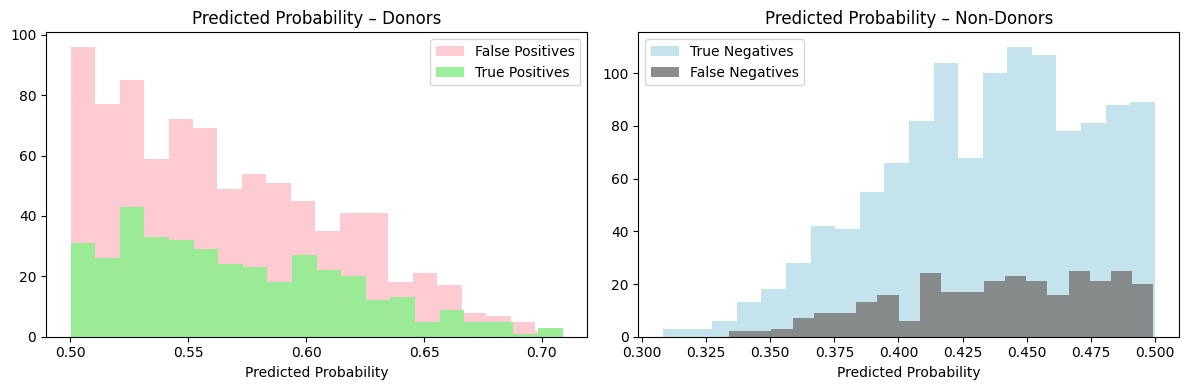

In [197]:
from sklearn.inspection import permutation_importance
X = all_data.drop(columns=['target_b'])
y = all_data['target_b']
X_train, X_val, y_train, y_val= train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = MinMaxScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

best_lr_model.fit(X_train_scaled, y_train)
y_pred = best_lr_model.predict(X_val_scaled)
y_proba = best_lr_model.predict_proba(X_val_scaled)[:, 1]

# creates a validation df with the values for incorrect prediction analysis
val_df = X_val.copy().reset_index(drop=True)
val_df['true'] = y_val.values
val_df['predicted'] = y_pred
val_df['proba'] = y_proba

FP = val_df[(val_df['true'] == 0) & (val_df['predicted'] == 1)] # identified as donor and it wasn't
FN = val_df[(val_df['true'] == 1) & (val_df['predicted'] == 0)] # identified as not donor and it was
TP = val_df[(val_df['true'] == 1) & (val_df['predicted'] == 1)] # identified as donor and it is
TN = val_df[(val_df['true'] == 0) & (val_df['predicted'] == 0)] # indentified as not donor and it wasn't
print(f"True Positives : {len(TP):>5}")
print(f"True Negatives : {len(TN):>5}")
print(f"False Positives: {len(FP):>5}")
print(f"False Negatives: {len(FN):>5}")

# compare important features
compare_cols = ['frequency_status_97nk','recent_card_response_count',
                'pep_star','months_since_last_gift','ses','recency_value','gift_variability']
compare_cols = [c for c in compare_cols if c in val_df.columns]

comparison = pd.DataFrame({
  'False Positives (mean)': FP[compare_cols].mean(),
  'False Negatives (mean)': FN[compare_cols].mean(),
  'True Positives (mean)': TP[compare_cols].mean(),
  'True Negatives (mean)': TN[compare_cols].mean()})
print("\nMean feature values by error type")
display(comparison.round(2))

fig,axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(FP['proba'], bins=20, color='lightpink', label='False Positives', alpha=0.7)
axes[0].hist(TP['proba'], bins=20, color='lightgreen', label='True Positives', alpha=0.9)
axes[0].set_title('Predicted Probability – Donors')
axes[0].set_xlabel('Predicted Probability')
axes[0].legend()

axes[1].hist(TN['proba'], bins=20, color='lightblue', label='True Negatives', alpha=0.7)
axes[1].hist(FN['proba'], bins=20, color='grey', label='False Negatives', alpha=0.9)
axes[1].set_title('Predicted Probability – Non-Donors')
axes[1].set_xlabel('Predicted Probability')
axes[1].legend()
plt.tight_layout()
plt.show()

`Confusion Matrix Results`

| Outcome | Count | Meaning |
|---|---|---|
| True Positives (TP) | 381 | Correctly identified donors |
| True Negatives (TN) | 1,182 | Correctly identified non-donors |
| False Positives (FP) | 852 | Contacted unnecessarily - predicted donor, was not |
| False Negatives (FN) | 297 | Missed donors - predicted non-donor, actually donated |

The model struggles most with **False Positives**, flagging 852 non-donors as likely donors. While costly in terms of outreach resources, this is a somewhat expected consequence of using `class_weight='balanced'` combined with threshold tuning aimed at maximising the F1-score. This pushed the model to be more aggressive in predicting a positive class. In this context, **False Negatives are more damaging** so this trade-off is justifiable



`What Separates Correct from Incorrect Predictions?`

The feature comparison table reveals clear patterns in where the model succeeds and where it fails

**False Positives vs True Negatives - why did the model wrongly flag non-donors?**

False Positives look almost identical to True Positives across the most discriminative features: `frequency_status_97nk` (2.71 vs 2.83), `recent_card_response_count` (2.64 vs 2.65), and `pep_star` (0.85 vs 0.87). These non-donors were engaged with promotions and had strong historical activity, they simply did not donate in this campaign. The model made a reasonable bet based on the available signals, since these are the hardest cases to separate

**False Negatives vs True Positives - why did the model miss real donors?**

False Negatives are very different from True Positives. They show much lower `frequency_status_97nk` (1.34 vs 2.83), lower `recent_card_response_count` (0.97 vs 2.65), and substantially lower `pep_star` (0.22 vs 0.87). Their `recency_value` is also notably weaker (4.73 vs 9.63). These are donors who donated despite showing low engagement signals, their donation was not predicted by their behavioural profile. This suggests a segment of **low-engagement but loyal donors** that the model systematically underestimates, and that current features do not capture well.

`Probability Distributions`

The histograms confirm the difficulty of this classification problem.

On the **left plot (Donors)**, both False Positives and True Positives are concentrated in the same narrow probability band between 0.50 and 0.70, with near-identical distributions. The model assigns similar confidence to both groups, meaning it cannot reliably distinguish a true donor from an engaged non-donor at the decision boundary.

On the **right plot (Non-Donors)**, False Negatives are clustered at the lower end of the probability scale (0.30–0.45), well below the decision threshold. The model is certain about these donors, it is actively confident they will not donate, which explains why threshold tuning alone cannot recover them. These missed donors require either richer features or a segment-specific model to be captured effectively.

## Interactive Prediction

To bridge the gap between machine learning development and operational marketing execution, we built an interactive and user-friendly interface. It provides graphical sliders where users can instantly simulate specific demographic and behavioral donor profiles to see whether the campaign should actively target them or not

To achieve this:

* `Widget Construction:` We define a set of interactive sliders, one per feature, each configured with the correct data type, minimum and maximum values, and step size reflecting the real range of that variable. This ensures that any input a user provides is always a valid and realistic donor profile

* `Input Mapping:` When the Predict button is clicked, the function reads the current value of every slider and places it into the correct column of a single-row dataframe. All remaining features that are not exposed in the interface are filled with 0, preserving the exact column structure that the model was trained on

* `Live Scaling:` The input row is scaled on the fly using a MinMaxScaler fitted on the full historical dataset (`all_data`). This step is important because without it, the raw slider values would be on completely different numerical scales than what the model learned from, producing unreliable predictions

* `Prediction and Decision:` The scaled input is passed to the best Logistic Regression model, which returns a probability of donation between 0 and 1. That probability is then compared against `best_threshold` and the interface immediately displays whether the donor should be contacted or not

In [ ]:
from IPython.display import display, clear_output
import ipywidgets as widgets

style = {"description_width": "220px"}
layout = widgets.Layout(width="420px")
# create the sliders to recieve the input
slider_age = widgets.IntSlider(min=18, max=100, description="Donor Age", style=style, layout=layout)
slider_ses = widgets.IntSlider(min=1, max=4, description="SES", style=style, layout=layout)
slider_children = widgets.IntSlider(min=0, max=6, description="Children", style=style, layout=layout)
slider_months_lg = widgets.IntSlider(min=0, max=120, description="Months Since Last Gift", style=style, layout=layout)
slider_median_home_value = widgets.IntSlider(min=0, max=6000, description="Median Home Value", style=style, layout=layout)
slider_card_resp_count = widgets.IntSlider(min=0, max=9, description="Recent Card Response Count", style=style, layout=layout)
slider_gift_var = widgets.FloatSlider(min=0, max=300, step=0.5, description="Gift Variability ($)", style=style, layout=layout)
slider_rec_val = widgets.FloatSlider(min=0, max=100, step=0.1, description="Recency Value", style=style, layout=layout)
slider_freq_stat = widgets.IntSlider(min=0, max=5, description="Frequency Status 97NK", style=style, layout=layout)
slider_rec_stat = widgets.IntSlider(min=0, max=1, description="Recency Status 96NK_F", style=style, layout=layout)
slider_pep_star = widgets.IntSlider(min=0, max=1, description="Pep Star", style=style, layout=layout)

button = widgets.Button(description="Predict", button_style="success", layout=widgets.Layout(width="150px"),)
results = widgets.Output()
col_features = all_data.drop(columns=["target_b"]).columns.tolist()

def predict(input):
  with results:
    clear_output()
    new_input = {coluna: [0] for coluna in col_features}
    new_input['donor_age'] = [slider_age.value]
    new_input['ses'] = [slider_ses.value]
    new_input['children'] = [slider_children.value]
    new_input['months_since_last_gift'] = [slider_months_lg.value]
    new_input['median_home_value'] = [slider_median_home_value.value]
    new_input['recent_card_response_count'] = [slider_card_resp_count.value]
    new_input['gift_variability'] = [slider_gift_var.value]
    new_input['recency_value'] = [slider_rec_val.value]
    new_input['frequency_status_97nk'] = [slider_freq_stat.value]
    new_input['pep_star'] = [slider_pep_star.value]
    new_input['recency_status_96nk_F'] = [slider_rec_stat.value]

    input_table = pd.DataFrame(new_input)[col_features]
    features = all_data.drop(columns=["target_b"])
    scaled = MinMaxScaler().fit(features)
    input_table_scaled = scaled.transform(input_table)

    # calculate the prob of donating
    prob = best_lr_model.predict_proba(input_table_scaled)[0, 1]

    # prob >= threshold is a Donor
    if prob >= best_threshold:
        pred = 1
    else:
        pred = 0

    print(f" Predicted Probability of Donating: {prob:.1%}")
    print(f" Decision Threshold applied: {best_threshold:.3f}")
    if pred == 1:
        print(" Prediction: DONOR - Contact this person")
    else:
        print(" Prediction: NON-DONOR - Do not contact")

button.on_click(predict)
print(" Interactive Donor Prediction Tool ")
display(slider_age, slider_ses, slider_children, slider_months_lg, slider_median_home_value,
        slider_card_resp_count, slider_gift_var, slider_rec_val, slider_freq_stat, slider_rec_stat, slider_pep_star, button,results)

## Conclusion and discussion of results



In this project we developed a data-driven predictive pipeline for the Civic Support Alliance (CSA), addressing the core challenge of identifying which individuals in the donor database are most likely to donate if contacted.

The data preparation phase required careful handling of missing values, invalid entries, and distributional anomalies across all variables. Eight engineered features were derived to enrich the available behavioural signals, capturing dimensions such as donation recency, gift variability, response intensity, and channel preference. These features complemented the original dataset and strengthened the predictive pipeline.

On the supervised learning side, four classification algorithms were evaluated under a Stratified 5-Fold Cross-Validation framework using binary F1-score as the primary metric, reflecting the class imbalance present in the data. Following hyperparameter optimisation via RandomizedSearchCV and threshold tuning via precision-recall analysis, Logistic Regression emerged as the best performing model, achieving a validation F1-score of 0.406 and the highest AUC-ROC among all evaluated models. The confusion matrix from the final model revealed that the biggest challenge lay in False Positives, with 852 non-donors incorrectly flagged, a trade-off accepted given that missing a real donor carries a higher operational cost than an unnecessary contact. The final model was successfully deployed on the unseen test set and submitted to the Kaggle competition.

The open-ended section explored three directions beyond the core pipeline. A bootstrapping resampling approach was applied to the best Logistic Regression model to address class imbalance. While it improved the F1-score in training, it led to a lower value in the validation score, indicating increased overfitting and suggesting that oversampling with replacement does not generalise well in this context. A feature importance analysis through logistic regression coefficients revealed that behavioural engagement features, particularly frequency_status_97nk and months_since_last_gift, are the dominant drivers of the model's decisions, with economic indicators playing a secondary supporting role. Finally, an incorrect prediction analysis profiled the model's errors and identified a segment of low-engagement but loyal donors whose donation behaviour is not captured by the current feature set, pointing to a clear direction for future modelling improvements. Also, an interactive widget was built, allowing end-users to simulate donor profiles through sliders and receive an instant contact recommendation based on the trained model and optimised threshold.

Looking ahead, cluster-based modelling tailored to donor segments, more thorough neural network exploration with greater computational resources, and revisiting the ordering of outlier treatment relative to imputation. All of them represent promising refinements worth investigating in future iterations.